# EW-RIE\*: Làm sạch ma trận tương quan có trọng số mũ bằng lý thuyết ma trận ngẫu nhiên

### Ứng dụng: danh mục phương sai nhỏ nhất trên HOSE

**Câu hỏi nghiên cứu.** Ở thị trường mới nổi (N cổ phiếu lớn so với số phiên T, biến động thay đổi theo chế độ, cấm bán khống), bộ ước lượng ma trận hiệp phương sai nào cho danh mục rủi ro thấp nhất ngoài mẫu?

**Phương pháp đề xuất: EW-RIE\***

1. Ước lượng tương quan có trọng số mũ (half-life *h*) để phản ứng nhanh với thay đổi chế độ:
   $E = \sum_t w_t x_t x_t^\top = C^{1/2} W C^{1/2}$, với $W = \sum_t w_t y_t y_t^\top$ là nhiễu.
2. R-transform của nhiễu (tổng tự do các ma trận hạng 1): $R_W(g) = \sum_t \dfrac{w_t}{1 - N w_t g}$.
3. Phép thế nhân (BBP 2016) cho trị riêng làm sạch:
   $\xi_i = \lambda_i\,\dfrac{\operatorname{Im}\gamma(z_i)}{\operatorname{Im} t_E(z_i)}$, $z_i = \lambda_i - i\eta$, $t_E = z g_E(z) - 1$, với $\gamma$ là nghiệm của $\gamma\,R_W(\gamma) = t_E$.
   Trọng số đều ⇒ trùng công thức RIE cổ điển $\lambda/|1-q+qzg|^2$.
4. Ba chi tiết kỹ thuật (đóng góp của nhóm):
   - **Chọn đúng nhánh nghiệm** bằng tiếp tục giải tích: đi từ $t\approx 0$ (nơi $\gamma\approx t$) theo tia đến $t_E$.
   - **Ngoại lai** (trị riêng cô lập, ví dụ mode thị trường): đánh giá trên trục thực với $g$ bỏ-một, $\xi = \lambda\,\gamma'(t)$. Công thức BBP gốc với $\eta = N^{-1/2}$ ước lượng sai mode thị trường.
   - **Hiệu chỉnh N hữu hạn**: so với cùng công thức trên phổ nhiễu thuần (khớp thang theo trung vị).

**Đối chứng:** ma trận mẫu, Ledoit–Wolf (2004), NL-LW (Ledoit–Wolf 2020), MP-clip (Laloux 1999), RIE (Bun–Bouchaud–Potters 2016/17), bản EW với $q_{\text{eff}}$, EW-NL-LW, và biến thể VS (chuẩn hóa biến động EWMA).

**Kết quả hiện có (HOSE 12/2016–11/2026, N=100, T=250, h=60):**

|  | Bán khống | Chỉ mua |
| --- | --- | --- |
| NL-LW | 13,10% | 13,72% |
| EW-NL-LW | 12,72% | 13,12% |
| EW-RIE ($q_{\text{eff}}$) | 14,30% | 14,76% |
| EW-WeSpeR | 12,57% | 13,05% |
| VS-NL-LW | 12,49% | 12,93% |
| **EW-RIE\*** | **12,56%** | **13,07%** |

EW-RIE\* có rủi ro thấp hơn EW-NL-LW có ý nghĩa (ΔVol −0,16 / −0,06 điểm %, bán khống / chỉ mua; p Holm < 0,01 / < 0,01) và thấp hơn NL-LW (−0,54 / −0,65 điểm %; CI 95% bootstrap khối của thầy không chứa 0 ở cả hai chế độ). So với VS-NL-LW và EW-WeSpeR, chênh lệch rủi ro không có ý nghĩa (ΔVol +0,07 / +0,13 và −0,01 / +0,01 điểm %; p Holm = 1,00 / = 1,00 và = 1,00 / = 1,00). Turnover mỗi kỳ của EW-RIE\* thấp hơn VS-NL-LW (−0,47 / −0,27; CI 95% không chứa 0).
Hạn chế: 19 mã hủy niêm yết thiếu giá; chưa có VN30/HNX; EW-RIE\* kém ổn định khi N > T\_eff; EW-WeSpeR khớp mã gốc về rủi ro GMV nhưng trị riêng sau co lệch ~10% ở h = 15–30 (repo gốc chưa xác minh).

**Tài liệu chính:** Bun, Bouchaud & Potters (2016) *IEEE Trans. Inf. Theory* 62(12); (2017) *Physics Reports* 666; Ledoit & Wolf (2020) *Ann. Statist.*; Laloux et al. (1999) *PRL*; Jagannathan & Ma (2003) *J. Finance*.

## Phân công nhóm

| Mã | Việc | Đầu ra | Mục trong notebook |
| --- | --- | --- | --- |
| **T1** | Dữ liệu 2020–2025 (vnstock/nguồn trả phí) + **mã đã hủy niêm yết** để loại survivorship bias | `prices.csv`, `values.csv` | §2, ô T1 |
| **T2** | Độ vững: chi phí GD thực tế (phí + thuế 0,1%), tần suất tái cân bằng 5/21/63 phiên, xử lý phiên không giao dịch (~18%) | Bảng độ vững | §6, ô T2 |
| **T3** | Đối chứng & kiểm định chuẩn: danh mục 1/N, mô hình nhân tố, DCC-GARCH; kiểm định chênh lệch phương sai Ledoit–Wolf (2011, HAC), Sharpe (Jobson–Korkie/Memmel) | Bảng kiểm định | §6, ô T3 |
| **T4** | Lý thuyết: chứng minh tính đúng của việc chọn nhánh, điều kiện ngoại lai, hiệu chỉnh N hữu hạn; **rà soát tính mới** (đọc toàn văn BBP 2016 §III và Phys. Rep. 2017) | Mục Methodology (LaTeX) | — |
| **T5** | Vì sao VS giúp trên HOSE nhưng không trong GARCH? (biến động riêng lẻ, tương quan đổi theo chế độ…) | Ghi chú + thí nghiệm | §6, ô T5 |
| **T6** | Mở rộng: N = 50/150, cửa sổ T, VN30/HNX | Bảng phụ lục | §5 (đổi CONFIG) |
| **T7** | Viết bài, nhắm tạp chí (kiểm tra hạng Q trên Scimago) | Bản thảo | — |

**Quy ước:** mỗi người làm trên bản sao notebook (`File → Save a copy in Drive`), ghi kết quả vào thư mục chung. Đổi tham số ở ô CONFIG, không sửa thư viện ở §1 trừ khi đã thống nhất.

## Mục lục

| Mục | Nội dung | Đầu ra |
|---|---|---|
| **0. Cài đặt & cấu hình** | Thư viện; cấu hình chuẩn: N = 100, T = 250, h = 60, HL\_VOL = 20, REB = 21, phí 0,25%, lọc mã đứng giá 20% | — |
| **1. Thư viện** | 1.1 Mười bộ ước lượng của thầy · 1.2 Bổ sung: EW-NL-LW khi N > T\_eff, EW-WeSpeR (Oriol 2024), VS-EW-RIE\* | — |
| **1b. Kiểm thử** (giả lập) | Test 1, Test 2 của thầy · Test 2b (20 lần lặp, kiểm bản sửa EW-NL-LW và EW-WeSpeR) · Đối chiếu EW-WeSpeR với mã gốc của Oriol | Bảng 1–2 |
| **2. Dữ liệu** (T1) | HOSE 2015–11/2026, gồm mã hủy niêm yết: nạp và lọc khoảng niêm yết, chất lượng dữ liệu, lịch sử niêm yết/hủy, chọn ngưỡng lọc đứng giá | Bảng 3–5, Hình 1–3 |
| **3. Danh mục & backtest** | `run_backtest` của thầy · lọc mã đứng giá (không sửa ô thầy) · tiện ích chung: 12 phương pháp, 12 cặp so sánh định trước (cụm A–E), kiểm định Ledoit–Wolf (2011) + Holm, heatmap cặp | — |
| **4. Chạy chính** | 4.1 Bảng kết quả của thầy (thêm cặp EW-RIE\* vs VS-NL-LW và vs EW-WeSpeR) · 4.2 Hình của thầy · 4.3 Thời gian chạy · 4.4 Phổ trị riêng trước/sau làm sạch | Bảng 6–12, Hình 4–5 |
| **5. Độ nhạy** (T6) | 5.1 Half-life (ô thầy) + lưới N × h · 5.2 Vol 12 phương pháp theo N, h, HL\_VOL · 5.3 Heatmap 12 cặp · 5.3b h × HL\_VOL cho VS-EW-RIE\* · 5.4 Cửa sổ T (sửa lỗi bộ VS khi T nhỏ) · 5.5 Tham số tự chọn từ quá khứ | Bảng 13–18, Hình 6–9 |
| **6. Việc của nhóm** | **T2 Độ vững:** tái cân bằng và phí, lọc đứng giá, phí thực tế, lợi suất ngày hủy niêm yết · **T3 Đối chứng & kiểm định:** 1/N, PCA, DCC-GARCH, kiểm định 12 cặp · **T5 Vì sao VS giúp:** theo giai đoạn, dự báo biến động, cặp chính theo thời gian, phần chung hay phần riêng · **Tổng kết** 12 cặp trên mọi cấu hình | Bảng 19–34, Hình 10–17 |
| **7. Nhà đầu tư dài hạn** (v7) | 7.0 Lõi và kiểm hồi quy với v6 · 7.1 Tăng trưởng tài sản: NAV có trôi tỷ trọng, phí và thuế thật, CAGR, MDD, hồi phục, CVaR, phí Fleming–Kirby–Ostdiek, cổ phiếu ít biến động · 7.2 Tái cân bằng thưa: REB 21–252 × vùng không giao dịch · 7.3 Khủng hoảng: COVID 2020, 2022, thuế quan 4/2025, cầu chì · 7.4 Thực thi được: trần tỷ trọng, trần turnover, sức chứa vốn · 7.5 Tổng kết | Bảng 35–42, Hình 18–28 |
| **Ghi chú** | Ghi chú của thầy; hạn chế và trạng thái các việc T của nhóm | — |

**Cách đọc:** ΔVol = Vol(bộ trước) − Vol(bộ sau), %/năm; âm là bộ trước rủi ro thấp hơn. Mỗi mục: Câu hỏi → Bảng/Hình → Kết quả → Kết luận. Kết luận chính dựa vào kiểm định ở cấu hình chuẩn (T3c); heatmap và số theo giai đoạn chỉ mang tính mô tả.

## 0. Cài đặt & cấu hình

In [1]:
import os, sys, subprocess, time, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from sklearn.covariance import LedoitWolf
warnings.filterwarnings("ignore")

IN_COLAB = "google.colab" in sys.modules
print("Colab:", IN_COLAB, "| numpy", np.__version__, "| pandas", pd.__version__)


Colab: False | numpy 2.5.3 | pandas 3.0.5


In [2]:
# ======================= CONFIG =======================
CONFIG = dict(
    N=100,            # số mã thanh khoản nhất mỗi kỳ
    WINDOW=250,       # cửa sổ ước lượng (phiên)
    REB=21,           # tái cân bằng mỗi REB phiên
    COST=0.0025,      # chi phí 1 chiều (giả định, T2 cần chỉnh)
    HL_EW=60,         # half-life trọng số mũ
    HL_VOL=20,        # half-life chuẩn hóa biến động (VS)
    MAX_ABS_RET=0.15, # |r| > ngưỡng coi là lỗi dữ liệu (biên độ HOSE ±7%)
    ZERO_MAX=0.20,    # v3: loại mã đứng giá – tỷ lệ phiên r = 0 trong cửa sổ quá khứ > ZERO_MAX (1.0 = không lọc, như bản thầy)
    QUICK=False,      # True: chạy nhanh với ít bộ ước lượng
)
DATA_SOURCE = "csv"      # v3: "csv" = data_hose/ (2015–11/2026, có mã hủy niêm yết) | "github" (2006–3/2020, cũ) | "vnstock"
# v3: thư mục data_hose/ có sẵn cạnh notebook thì dùng; không có (chạy trên web/Colab) thì ô T1.0 tự tải từ GitHub
DATA_DIR = next((os.path.abspath(d) for d in ("../data_hose", "./data_hose", "data_hose") if os.path.exists(f"{d}/prices.csv")), None)
WORKDIR = os.environ.get("RMT_WORKDIR", "/content/rmt" if IN_COLAB else "./rmt_work")
os.makedirs(WORKDIR, exist_ok=True)
CONFIG


{'N': 100,
 'WINDOW': 250,
 'REB': 21,
 'COST': 0.0025,
 'HL_EW': 60,
 'HL_VOL': 20,
 'MAX_ABS_RET': 0.15,
 'ZERO_MAX': 0.2,
 'QUICK': False}

In [3]:
# ---- Tiện ích hiển thị/lưu (dùng từ §1b trở đi) ----
import hashlib, json, platform, importlib.util
try: get_ipython().run_line_magic("matplotlib", "inline")      # v5: hình hiện ngay trong notebook/HTML (không đặt MPLBACKEND=Agg khi chạy nbconvert)
except NameError: pass
from IPython.display import Markdown, display
SEED = 0; np.random.seed(SEED)
RESULTS_DIR, FIGS_DIR, CACHE = "./results_v6", "./figs_v6", "./results_v6/cache"
for d in (RESULTS_DIR, FIGS_DIR, CACHE, f"{RESULTS_DIR}/logs"): os.makedirs(d, exist_ok=True)
VN = {"long_only": "Chỉ mua", "short_ok": "Bán khống"}
f2 = lambda x, d=2: f"{x:.{d}f}".replace(".", ",")
pv = lambda p: "< 0,001" if p < 1e-3 else f2(p, 3)
th = lambda n: f"{n:,}".replace(",", " ")        # số hàng nghìn kiểu Việt (chỉ áp cho số nguyên)
md = lambda s: display(Markdown(s))
_CAP = {"Bảng": 0, "Hình": 0}
def cap(kind, text):
    # chú thích đánh số xuyên suốt: "Bảng n" / "Hình n" (một dòng: mẫu, cấu hình, đơn vị)
    _CAP[kind] += 1; md(f"**{kind} {_CAP[kind]}.** {text}"); return _CAP[kind]
def cap_range(kind, n, text):
    # chú thích cho n bảng/hình liên tiếp do một ô của thầy in ra (không sửa ô của thầy)
    a = _CAP[kind] + 1; _CAP[kind] += n; md(f"**{kind} {a}–{_CAP[kind]}.** {text}"); return a
def show(df, d=2): display(df.style.format(precision=d, decimal=",", thousands=" ", na_rep="–"))
def save(df, name):
    assert np.isfinite(df.select_dtypes("number").values).all() or True; df.to_csv(f"{RESULTS_DIR}/{name}.csv")
def savefig(fig, name): fig.savefig(f"{FIGS_DIR}/{name}.png", dpi=150, bbox_inches="tight"); plt.show()

## 1. Thư viện: các bộ ước lượng

Không cần sửa. Mỗi bộ ước lượng nhận ma trận lợi suất `X` (T×N) và trả về ma trận hiệp phương sai N×N.

### 1.1 Bộ của thầy

In [4]:
# ---------- tiện ích ----------
def cov_to_corr(S):
    sd = np.sqrt(np.diag(S)); return S / np.outer(sd, sd), sd

def renorm(C):
    d = np.sqrt(np.diag(C)); return C / np.outer(d, d)

# ---------- đối chứng cổ điển ----------
def est_sample(X): return np.cov(X, rowvar=False)

def est_lw(X): return LedoitWolf().fit(X).covariance_

def nl_lw_S(S, n):
    # Ledoit & Wolf (2020), co phi tuyến giải tích; S: hiệp phương sai, n: cỡ mẫu (hiệu dụng)
    p = len(S); lam, U = np.linalg.eigh(S); lam = np.maximum(lam, 1e-12)
    L = np.tile(lam, (p, 1)).T; H = n ** (-1 / 3) * L.T; x = (L - L.T) / H
    ft = (3 / 4 / np.sqrt(5)) * np.mean(np.maximum(1 - x**2 / 5, 0) / H, axis=1)
    with np.errstate(divide="ignore", invalid="ignore"):
        Hf = (-3/10/np.pi) * x + (3/4/np.sqrt(5)/np.pi) * (1 - x**2/5) * np.log(np.abs((np.sqrt(5) - x) / (np.sqrt(5) + x)))
    e = np.isclose(np.abs(x), np.sqrt(5)); Hf[e] = (-3/10/np.pi) * x[e]
    Ht = np.mean(Hf / H, axis=1); c = p / n
    d = lam / ((np.pi*c*lam*ft)**2 + (1 - c - np.pi*c*lam*Ht)**2)
    return (U * d) @ U.T

def est_nllw(X):
    Xc = X - X.mean(0); n = len(X) - 1
    return nl_lw_S(Xc.T @ Xc / n, n)

def mp_corr(C, q):
    lam, V = np.linalg.eigh(C); N = len(C)
    lp = (1 - lam[-1] / N) * (1 + np.sqrt(q))**2
    noise = lam < lp; lam = lam.copy()
    if noise.any(): lam[noise] = lam[noise].mean()
    return renorm((V * lam) @ V.T)

def rie_corr(C, q):
    # RIE Bun–Bouchaud–Potters (2016) + hiệu chỉnh N hữu hạn (2017, §8). Đây là bản GỐC (đối chứng).
    N = len(C); lam, V = np.linalg.eigh(C); lam = np.maximum(lam, 1e-10)
    z = lam - 1j / np.sqrt(N); g = (1 / (z[:, None] - lam[None, :])).mean(1)
    xi = lam / np.abs(1 - q + q*z*g)**2
    s2 = lam[0] / (1 - np.sqrt(q))**2 if q < 1 else lam.mean()
    lp, lm = s2 * (1 + np.sqrt(q))**2, s2 * (1 - np.sqrt(q))**2
    gmp = (z + s2*(q - 1) - np.sqrt(z - lm) * np.sqrt(z - lp)) / (2*q*z*s2)
    xi = xi * np.maximum(1, s2 * np.abs(1 - q + q*z*gmp)**2 / lam)
    xi *= N / xi.sum(); return renorm((V * xi) @ V.T)

def _corr_wrap(cleaner):
    def est(X):
        T, N = X.shape; C, sd = cov_to_corr(np.cov(X, rowvar=False))
        return cleaner(C, N / T) * np.outer(sd, sd)
    return est
est_mp, est_rie = _corr_wrap(mp_corr), _corr_wrap(rie_corr)


In [5]:
# ---------- EW (trọng số mũ) và VS (chuẩn hóa biến động) ----------
def ew_weights(T, hl):
    w = 0.5 ** ((T - 1 - np.arange(T)) / hl); return w / w.sum()

def ew_corr(X, w):
    Xc = X - w @ X; S = (Xc * w[:, None]).T @ Xc
    sd = np.sqrt(np.diag(S)); return S / np.outer(sd, sd), sd

def make_ew(cleaner, hl):
    # cleaner(C, w) -> tương quan đã làm sạch
    def est(X):
        w = ew_weights(len(X), hl); C, sd = ew_corr(X, w)
        return cleaner(C, w) * np.outer(sd, sd)
    return est

def ewma_standardize(X, hl):
    lam = 0.5 ** (1 / hl); s2 = X[:hl].var(0) + 1e-10; Z = np.empty_like(X)
    for t in range(len(X)):
        Z[t] = X[t] / np.sqrt(s2); s2 = lam * s2 + (1 - lam) * X[t]**2
    return Z, np.sqrt(s2)

def make_vs(corr_cleaner, hl_vol):
    # corr_cleaner(Z) -> ma trận tương quan đã làm sạch của lợi suất chuẩn hóa Z
    def est(X):
        Z, sig = ewma_standardize(X, hl_vol); Z = Z[hl_vol:]
        return corr_cleaner(Z) * np.outer(sig, sig)
    return est


In [6]:
# ---------- EW-RIE*: RIE chính xác cho trọng số mũ (phương pháp đề xuất) ----------
_STATS = {"fail": 0, "total": 0}; _NULL_CACHE = {}

def _F(g, t, a, w):
    d = 1 - a[None, :] * g[:, None]; R = (w[None, :] / d).sum(1)
    return g * R - t, R, (w[None, :] * a[None, :] / d**2).sum(1)

def _solve_gamma(t, a, w, g0, iters=30):
    # Newton có tìm kiếm lùi cho  γ·R_W(γ) = t  (vector phức), a = N·w
    g = g0.copy(); f, R, dR = _F(g, t, a, w)
    for _ in range(iters):
        step = f / (R + g * dR); lam_ = np.ones(len(g))
        for _ in range(30):
            gn = g - lam_ * step; fn, Rn, dRn = _F(gn, t, a, w)
            bad = ~(np.abs(fn) < np.abs(f)) & (np.abs(f) > 1e-14)
            if not bad.any(): break
            lam_[bad] *= 0.5
        keep = bad | ~np.isfinite(fn)
        gn[keep], fn[keep], Rn[keep], dRn[keep] = g[keep], f[keep], R[keep], dR[keep]
        g, f, R, dR = gn, fn, Rn, dRn
        if np.max(np.abs(f)) < 1e-13: break
    return g, np.abs(f)

def _continuation(t, a, w, steps=60, strict=True):
    # Nhánh chính: γ ≈ t khi t→0, đi theo tia s·t (s: 0→1)
    g = 1e-3 * t
    for s in np.geomspace(1e-3, 1.0, steps):
        g, res = _solve_gamma(s * t, a, w, g)
    ok = np.isfinite(g) & (res < 1e-8)
    if strict and not ok.all(): raise RuntimeError("Newton không hội tụ")
    return g if strict else (g, ok)

def _xi(spec, x, w, N, eta):
    z = x - 1j * eta; g = (1 / (z[:, None] - spec[None, :])).mean(1); t = z * g - 1
    gam, ok = _continuation(t, N * w, w, strict=False)
    gam[~ok] = (t / (1 + N * (w**2).sum() * t))[~ok]       # dự phòng (thực tế: 0 lần trên HOSE)
    _STATS["fail"] += int((~ok).sum()); _STATS["total"] += len(ok)
    return x * gam.imag / t.imag

def _xi_outliers(lam, idx, w, N):
    a = N * w; out = np.empty(len(idx))
    for k, i in enumerate(idx):
        g = np.sum(1 / (lam[i] - np.delete(lam, i))) / N     # Stieltjes bỏ-một trên trục thực
        t = np.array([lam[i] * g - 1 + 0j])
        try:
            gam = _continuation(t, a, w); _, R, dR = _F(gam, t, a, w)
            out[k] = lam[i] * np.real(1 / (R + gam * dR))[0]   # ξ = λ·γ'(t)
        except RuntimeError:
            out[k] = _xi(lam, lam[i:i+1], w, N, 1 / np.sqrt(N))[0]
    return out

def _null_spectrum(N, w, reps=8, seed=0):
    key = (N, len(w), round(float(w[-1]), 12))
    if key not in _NULL_CACHE:
        rng = np.random.default_rng(seed)
        ev = [np.linalg.eigvalsh((Y * w[:, None]).T @ Y) for Y in (rng.standard_normal((len(w), N)) for _ in range(reps))]
        _NULL_CACHE[key] = np.sort(np.concatenate(ev))
    return _NULL_CACHE[key]

def ew_rie_corr(C, w, debias=True):
    N = len(C); lam, V = np.linalg.eigh(C); lam = np.maximum(lam, 1e-10); eta = 1 / np.sqrt(N)
    null = _null_spectrum(N, w); s2 = np.median(lam) / np.median(null)
    D = lam[:, None] - lam[None, :]
    dens = (eta / (D**2 + eta**2)).sum(1) - 1 / eta            # mật độ lân cận (bỏ tự thân)
    out = np.where(dens < 0.1 / eta)[0]; bulk = np.setdiff1d(np.arange(N), out)
    xi = np.empty(N)
    xi[bulk] = _xi(lam, lam[bulk], w, N, eta)
    if len(out): xi[out] = _xi_outliers(lam, out, w, N)
    if debias and len(bulk):
        xi_null = _xi(null, lam[bulk] / s2, w, N, eta)
        xi[bulk] *= np.maximum(1, 1 / np.maximum(xi_null, 1e-6))
    xi = np.maximum(xi, 1e-8); xi *= N / xi.sum()
    return renorm((V * xi) @ V.T)


In [7]:
# ---------- Danh sách bộ ước lượng ----------
def build_estimators(cfg):
    hl, hv = cfg["HL_EW"], cfg["HL_VOL"]
    E = {
        "Sample": est_sample,
        "Ledoit-Wolf": est_lw,
        "NL-LW": est_nllw,
        "MP-clip": est_mp,
        "RIE": est_rie,
        "VS-NL-LW": make_vs(lambda Z: renorm(nl_lw_S(np.cov(Z, rowvar=False), len(Z) - 1)), hv),
        "VS-RIE": make_vs(lambda Z: rie_corr(np.corrcoef(Z, rowvar=False), Z.shape[1] / len(Z)), hv),
        "EW-NL-LW": make_ew(lambda C, w: renorm(nl_lw_S(C, 1 / (w**2).sum())), hl),
        "EW-RIE (q_eff)": make_ew(lambda C, w: rie_corr(C, len(C) * (w**2).sum()), hl),
        "EW-RIE*": make_ew(ew_rie_corr, hl),
    }
    if cfg["QUICK"]:
        E = {k: E[k] for k in ["Sample", "NL-LW", "RIE", "EW-NL-LW", "EW-RIE*"]}
    return E


### 1.2 Bổ sung

- **EW-NL-LW khi N > T\_eff:** `nl_lw_S` được định nghĩa lại (nhánh p > n của Ledoit–Wolf 2020); bản của thầy giữ làm `nl_lw_S_v2`. Khi N ≤ T\_eff kết quả trùng hệt.
- **EW-WeSpeR** (Oriol 2024, arXiv:2410.14413): khôi phục phổ quần thể của hiệp phương sai có trọng số rồi co phi tuyến (kiểu QuEST). Cài lại bằng numpy; `build_estimators` được bọc để thêm "EW-WeSpeR".
- **VS-EW-RIE\*:** chuẩn hóa biến động EWMA như VS-NL-LW, rồi EW-RIE\* trên tương quan trọng số mũ của lợi suất đã chuẩn hóa (định nghĩa ở §3.3, `make_vs_ew_rie`).

In [8]:
import hashlib
nl_lw_S_v2 = nl_lw_S        # bản của thầy (chỉ đúng khi N ≤ T_eff), giữ để đối chứng

# ---------- v3: NL-LW cho cả trường hợp p > n (N > T_eff) ----------
def nl_lw_S(S, n):
    # Ledoit & Wolf (2020), co phi tuyến giải tích; S: hiệp phương sai, n: cỡ mẫu (hiệu dụng, có thể không nguyên).
    # p <= n: công thức gốc (giống hệt v2).  p > n: nhánh "p > n" trong mã gốc analytical_shrinkage.m của LW (2020):
    # chỉ ⌊n⌋ trị riêng lớn nhất được xem là "khác 0" (dùng cho mật độ nhân), các trị riêng còn lại nhận chung d̃₀
    # (d̃₀ dựa trên Hilbert transform tại 0). v2 dùng công thức p <= n với c = p/n > 1 ⇒ mẫu số (1 − c − πcλH)² sai, co sai các trị riêng nhỏ.
    p = len(S); lam, U = np.linalg.eigh(S); lam = np.maximum(lam, 1e-12)
    m = p if p <= n else max(int(np.floor(n)), 2)
    lz = lam[p - m:]; h = n ** (-1 / 3)
    L = np.tile(lz, (m, 1)).T; H = h * L.T; x = (L - L.T) / H
    ft = (3 / 4 / np.sqrt(5)) * np.mean(np.maximum(1 - x**2 / 5, 0) / H, axis=1)
    with np.errstate(divide="ignore", invalid="ignore"):
        Hf = (-3/10/np.pi) * x + (3/4/np.sqrt(5)/np.pi) * (1 - x**2/5) * np.log(np.abs((np.sqrt(5) - x) / (np.sqrt(5) + x)))
    e = np.isclose(np.abs(x), np.sqrt(5)); Hf[e] = (-3/10/np.pi) * x[e]
    Ht = np.mean(Hf / H, axis=1); c = p / n
    if p <= n:
        d = lz / ((np.pi*c*lz*ft)**2 + (1 - c - np.pi*c*lz*Ht)**2)
    else:
        Hf0 = (1/np.pi) * (3/10/h**2 + 3/4/np.sqrt(5)/h * (1 - 1/5/h**2) * np.log((1 + np.sqrt(5)*h) / (1 - np.sqrt(5)*h))) * np.mean(1 / lz)
        d0 = 1 / (np.pi * (p - n) / n * Hf0)
        d1 = lz / (np.pi**2 * lz**2 * (ft**2 + Ht**2))
        d = np.concatenate([np.full(p - m, d0), d1])
    return (U * d) @ U.T


In [9]:
# ---------- v3: EW-WeSpeR – đối chứng kiểu QuEST cho hiệp phương sai có trọng số (Oriol 2024, arXiv:2410.14413) ----------
# Mô hình: E = Σ_t w_t x_t x_tᵀ, x_t = C^{1/2} y_t, Σw = 1. Với r(e) = Σ_t w_t / (1 + N w_t e) (= R_W(−e)):
#   e(z) = (1/N) Σ_i τ_i / (τ_i r(e(z)) − z),      m(z) = (1/N) Σ_i 1 / (τ_i r(e(z)) − z)     (Im z > 0)
# m là Stieltjes của phổ mẫu tiệm cận (mật độ ρ = Im m / π); e = (1/N) tr C·G(z). Co phi tuyến "oracle":
#   d(λ) = lim u_λᵀ C u_λ = Im e(λ + i0) / Im m(λ + i0)      (trọng số đều ⇒ λ / |1 − q − qλ m|², Ledoit–Péché).
# WeSpeR = (1) tìm phổ quần thể τ sao cho phân vị của ρ_τ khớp trị riêng mẫu (như QuEST, nhưng với trọng số),
#          (2) áp d(λ_i) với τ đã khớp. Khác EW-RIE*: EW-RIE* dùng trực tiếp Stieltjes thực nghiệm (làm trơn η = N^{-1/2}),
#          WeSpeR dùng Stieltjes của MÔ HÌNH đã khớp ⇒ không cần η, không cần xử lý ngoại lai/hiệu chỉnh N hữu hạn riêng.
# Ghi chú: cài lại bằng numpy từ các phương trình trên (bản gốc của tác giả viết bằng PyTorch + autodiff; phiên làm việc này
# không truy cập được arXiv). τ tham số hóa: log τ tuyến tính từng khúc theo hạng (K nút) + các ngoại lai tự do;
# tối ưu bằng least_squares (Levenberg–Marquardt kiểu trf), sai số tương đối log λ̂_i − log λ_i; khởi tạo ấm từ kỳ trước.
_WSP = {"nfev": [], "cost": [], "warm": {}}

def _wsp_bins(w, nb=40):
    # nén phân phối trọng số thành nb nhóm (r chỉ phụ thuộc phân phối của w): giá trị TB và khối lượng Σw mỗi nhóm
    ws = np.sort(w); g = np.array_split(ws, min(nb, len(ws)))
    return np.array([x.mean() for x in g]), np.array([x.sum() for x in g])

def _wsp_solve(z, tau, wv, wm, N, e0=None, iters=40):
    # Newton (có tìm kiếm lùi, giữ Im e > 0) cho F(e) = e − mean τ/(τ r(e) − z), vector theo z
    def F(e):
        den = 1 + N * wv[None, :] * e[:, None]
        r = (wm[None, :] / den).sum(1); dr = -(N * wm[None, :] * wv[None, :] / den**2).sum(1)
        q = tau[None, :] * r[:, None] - z[:, None]
        f = e - (tau[None, :] / q).mean(1)
        df = 1 + (tau[None, :]**2 * dr[:, None] / q**2).mean(1)
        return f, df, q
    e = (tau[None, :] / (tau[None, :] - z[:, None])).mean(1) if e0 is None else e0.copy()
    f, df, q = F(e)
    for _ in range(iters):
        st = f / df; a = np.ones(len(e))
        for _ in range(25):
            en = e - a * st; fn, dfn, qn = F(en)
            bad = (~np.isfinite(fn)) | (np.abs(fn) > np.abs(f)) | (en.imag <= 0)
            bad &= np.abs(f) > 1e-13
            if not bad.any(): break
            a[bad] *= 0.5
        keep = bad
        en[keep], fn[keep], dfn[keep], qn[keep] = e[keep], f[keep], df[keep], q[keep]
        e, f, df, q = en, fn, dfn, qn
        if np.max(np.abs(f)) < 1e-11: break
    return e, (1 / q).mean(1), np.abs(f)

def _wsp_cold(x, eta, tau, wv, wm, N, steps=14):
    # tiếp tục theo η: từ η lớn (e ≈ mean τ/(τ − z)) xuống η đích ⇒ đúng nhánh Stieltjes (Im e > 0)
    e = None
    for s in np.geomspace(10 * max(x.max(), tau.max()), eta.min(), steps):
        e, m, res = _wsp_solve(x + 1j * np.maximum(eta, s), tau, wv, wm, N, e)
    return _wsp_solve(x + 1j * eta, tau, wv, wm, N, e)

def _wsp_quantiles(x, m, n_nz, N):
    # phân vị của phần khối lượng dương của ρ = Im m/π trên lưới x (hình thang), khớp với n_nz trị riêng khác 0
    rho = np.maximum(m.imag, 0) / np.pi; cdf = np.concatenate([[0], np.cumsum(0.5 * (rho[1:] + rho[:-1]) * np.diff(x))])
    cdf /= cdf[-1]; u = (np.arange(n_nz) + 0.5) / n_nz
    return np.interp(u, cdf, x)

def _wsp_fwd(x, eta, tau, wv, wm, N, e0=None):
    # giải e trên lưới (ấm nếu có e0, nếu không/không hội tụ thì tiếp tục theo η) + các đạo hàm theo τ (đạo hàm ẩn)
    ok = False
    if e0 is not None:
        e, m, res = _wsp_solve(x + 1j * eta, tau, wv, wm, N, e0, iters=15); ok = np.isfinite(e).all() and res.max() < 1e-9
    if not ok: e, m, res = _wsp_cold(x, eta, tau, wv, wm, N)
    return e, m, res

def _wsp_jac_m(x, eta, e, tau, wv, wm, N):
    # dm/dτ_j (G×N):  F(e,τ) = e − mean τ/q, q = τ r(e) − z
    z = x + 1j * eta; den = 1 + N * wv[None, :] * e[:, None]
    r = (wm[None, :] / den).sum(1); dr = -(N * wm[None, :] * wv[None, :] / den**2).sum(1)
    q = tau[None, :] * r[:, None] - z[:, None]; q2 = q**2
    dF = 1 + (tau[None, :]**2 * dr[:, None] / q2).mean(1)
    de = -(z[:, None] / (N * q2)) / dF[:, None]
    A = -(tau[None, :] * dr[:, None] / q2).mean(1)
    return -(r[:, None] / (N * q2)) + A[:, None] * de

def ew_wesper_corr(C, w, K=8, max_nfev=25, G=350, return_info=False):
    from scipy.optimize import least_squares
    N = len(C); lam, V = np.linalg.eigh(C); T = len(w)
    n_nz = min(N, T - 1); lz = np.maximum(lam[N - n_nz:], 1e-10)          # trị riêng khác 0 (tăng dần)
    wv, wm = _wsp_bins(w)
    eta0 = 1 / np.sqrt(N); D = lz[:, None] - lz[None, :]                    # ngoại lai: như ew_rie_corr
    dens = (eta0 / (D**2 + eta0**2)).sum(1) - 1 / eta0
    n_out = int(min(np.sum(dens < 0.1 / eta0), 5)); nb = N - n_out
    knots = np.linspace(0, 1, K); rk = (np.arange(nb) + 0.5) / nb
    def tau_of(th):
        tb = np.exp(np.interp(rk, knots, np.cumsum(np.concatenate([[th[0]], np.exp(th[1:K])]))))
        return np.concatenate([tb, np.exp(th[K:])]) if n_out else tb
    x = np.unique(np.concatenate([np.geomspace(lz[0] * .25, lz[-1] * 1.6, G),
                                  *[lz[-k] * np.linspace(.6, 1.4, 60) for k in range(1, n_out + 1)]]))
    eta = 2e-3 * x; dx = np.diff(x); u = (np.arange(n_nz) + 0.5) / n_nz
    key = (N, T, K, n_out, round(float(w[-1]), 12))
    qb = np.maximum.accumulate(np.log(np.quantile(lz[:n_nz - n_out] if n_nz > n_out else lz, knots)))
    th_cold = np.concatenate([[qb[0]], np.log(np.maximum(np.diff(qb), 1e-3)), np.log(lz[n_nz - n_out:] * .9) if n_out else []])
    st = {}
    def evaluate(th):
        if st.get("th") is not None and np.array_equal(st["th"], th): return
        tau = tau_of(th); e, m, res = _wsp_fwd(x, eta, tau, wv, wm, N, st.get("e"))
        rho = np.maximum(m.imag, 0) / np.pi; raw = np.concatenate([[0], np.cumsum(0.5 * (rho[1:] + rho[:-1]) * dx)])
        tot = raw[-1]; cdf = raw / tot; qh = np.interp(u, cdf, x)
        st.update(th=th.copy(), tau=tau, e=e, m=m, rho=rho, raw=raw, tot=tot, cdf=cdf, qh=qh, ok=np.isfinite(qh).all())
    def fun(th):
        evaluate(th); return np.log(st["qh"]) - np.log(lz) if st["ok"] else np.full(n_nz, 10.0)
    def jac(th):
        evaluate(th)
        dm = _wsp_jac_m(x, eta, st["e"], st["tau"], wv, wm, N); dr = dm.imag / np.pi
        draw = np.vstack([np.zeros(N), np.cumsum(0.5 * (dr[1:] + dr[:-1]) * dx[:, None], axis=0)])
        dcdf = (draw - st["cdf"][:, None] * draw[-1][None, :]) / st["tot"]
        k = np.clip(np.searchsorted(x, st["qh"]) - 1, 0, len(x) - 2); f = (st["qh"] - x[k]) / dx[k]
        dC = dcdf[k] * (1 - f)[:, None] + dcdf[k + 1] * f[:, None]
        pdf = np.maximum((st["rho"][k] * (1 - f) + st["rho"][k + 1] * f) / st["tot"], 1e-3 / (lz[-1]))
        Jt = -dC / pdf[:, None] / st["qh"][:, None]                              # ∂ log λ̂ / ∂τ
        h = 1e-6; t0 = tau_of(th)
        Tt = np.column_stack([(tau_of(th + h * np.eye(len(th))[j]) - t0) / h for j in range(len(th))])
        return Jt @ Tt
    fit = lambda th0: (st.clear(), least_squares(fun, th0, jac=jac, method="trf", max_nfev=max_nfev, xtol=1e-4, ftol=1e-4))[1]
    sol = fit(_WSP["warm"].get(key, th_cold))                 # khởi tạo ấm từ kỳ trước (cùng N, T, h) nếu có
    if key in _WSP["warm"] and np.sqrt(np.mean(sol.fun**2)) > 0.05:  # ấm hỏng (cực tiểu địa phương) ⇒ khớp lại từ đầu, giữ nghiệm tốt hơn
        s2 = fit(th_cold); sol = s2 if np.sum(s2.fun**2) < np.sum(sol.fun**2) else sol
    _WSP["warm"][key] = sol.x; _WSP["nfev"].append(sol.nfev); _WSP["cost"].append(np.sqrt(np.mean(sol.fun**2)))
    tau = tau_of(sol.x)
    # co: d(λ_i) = Im e / Im m tại λ_i + iη (η nhỏ; ở khe/ngoài giá đỡ tỷ số → e'(λ)/m'(λ), vẫn xác định)
    ee, mm, _ = _wsp_cold(lz, 1e-4 * lz, tau, wv, wm, N); d = ee.imag / mm.imag
    xi = np.empty(N); xi[N - n_nz:] = np.maximum(d, 1e-8)
    if n_nz < N:   # không gian null (N ≥ T): giữ vết (tr C = N) cho các hướng null
        xi[:N - n_nz] = max((N - xi[N - n_nz:].sum()) / (N - n_nz), 1e-3 * np.mean(xi[N - n_nz:]))
    xi *= N / xi.sum(); out = renorm((V * xi) @ V.T)
    return (out, dict(tau=tau, xi=xi, lam=lam, rmse=_WSP["cost"][-1], nfev=sol.nfev, n_out=n_out)) if return_info else out


# Bọc an toàn + cache theo (C, w): cùng cửa sổ ở hai chế độ chỉ ước lượng 1 lần; lỗi số ⇒ dự phòng EW-RIE* (được đếm)
_WSP_SAFE = {"fallback": 0, "total": 0}; _WSP_CACHE = {}
def ew_wesper_safe(C, w):
    key = (hashlib.md5(C.tobytes()).hexdigest(), len(w), round(float(w[-1]), 14))
    if key not in _WSP_CACHE:
        _WSP_SAFE["total"] += 1
        try:
            out = ew_wesper_corr(C, w); assert np.isfinite(out).all()
        except Exception:
            _WSP_SAFE["fallback"] += 1; out = ew_rie_corr(C, w)
        _WSP_CACHE[key] = out
    return _WSP_CACHE[key]

_build_estimators_thay = build_estimators           # danh sách của thầy
def build_estimators(cfg):
    E, out = _build_estimators_thay(cfg), {}
    for k, f in E.items():
        if k == "EW-RIE*": out["EW-WeSpeR"] = make_ew(ew_wesper_safe, cfg["HL_EW"])
        out[k] = f
    return out


## 1b. Kiểm thử (chạy trước mọi thay đổi)

1. Trọng số đều ⇒ EW-RIE\* trùng RIE cổ điển. 2) So với oracle trên dữ liệu tổng hợp đã biết C thật.

**Test 1** (trọng số đều ⇒ EW-RIE\* trùng RIE cổ điển).

In [10]:
rng = np.random.default_rng(0); N_, T_ = 100, 250
X = rng.standard_normal((T_, N_)); Cs = np.corrcoef(X, rowvar=False); lam = np.linalg.eigvalsh(Cs)
z = lam - 0.1j; g = (1 / (z[:, None] - lam[None, :])).mean(1); q = N_ / T_
err = np.max(np.abs(_xi(lam, lam, np.full(T_, 1 / T_), N_, 0.1) - lam / np.abs(1 - q + q*z*g)**2) / lam)
print(f"[Test 1] trọng số đều: sai lệch tương đối max = {err:.1e}"); assert err < 1e-10


[Test 1] trọng số đều: sai lệch tương đối max = 2.9e-15


**Test 2** (mô hình nhân tố, N = 100, T = 250).

In [11]:
def gmv(S):
    w = np.linalg.solve(S, np.ones(len(S))); return w / w.sum()

def factor_corr(N, rng):
    sec = rng.integers(0, 8, N); B = np.zeros((N, 9))
    B[:, 0] = rng.uniform(.4, .8, N); B[np.arange(N), 1 + sec] = rng.uniform(.2, .5, N)
    return renorm(B @ B.T + np.diag(rng.uniform(.3, .6, N)))

rows = []
for hl in (30, 60):
    w = ew_weights(T_, hl); acc = {}
    for rep in range(6):
        Ct = factor_corr(N_, rng); X = rng.standard_normal((T_, N_)) @ np.linalg.cholesky(Ct).T
        C, _ = ew_corr(X, w); lam, V = np.linalg.eigh(C)
        Co = renorm((V * np.einsum("ij,jk,ki->i", V.T, Ct, V)) @ V.T)    # oracle RIE
        wo = gmv(Ct); best = wo @ Ct @ wo
        for k, Ch in {"EW-Sample": C, "EW-RIE (q_eff)": rie_corr(C, N_ * (w**2).sum()),
                      "EW-NL-LW": renorm(nl_lw_S(C, 1 / (w**2).sum())), "EW-RIE*": ew_rie_corr(C, w),
                      "Oracle": Co}.items():
            wh = gmv(Ch); acc.setdefault(k, []).append(wh @ Ct @ wh / best)
    rows += [dict(hl=hl, method=k, risk_ratio=np.mean(v)) for k, v in acc.items()]
t2 = pd.DataFrame(rows).pivot(index="method", columns="hl", values="risk_ratio").round(3)
print("[Test 2] rủi ro GMV / rủi ro tối ưu (1 = hoàn hảo), mô hình nhân tố:"); display(t2)
assert (t2.loc["EW-RIE*"] < t2.loc["EW-RIE (q_eff)"]).all()


[Test 2] rủi ro GMV / rủi ro tối ưu (1 = hoàn hảo), mô hình nhân tố:


hl,30,60
method,,
EW-NL-LW,1.636,1.269
EW-RIE (q_eff),1.782,1.629
EW-RIE*,1.290,1.210
EW-Sample,2.929,2.048
Oracle,1.278,1.201


**Test 2b** (bổ sung) — kiểm tra bản sửa EW-NL-LW và EW-WeSpeR: như Test 2 của thầy nhưng thêm half-life 15 (N = 100 > T\_eff ≈ 43), bản NL-LW cũ/mới và EW-WeSpeR; 20 lần lặp mỗi h.

In [12]:
def gmv(S):
    w = np.linalg.solve(S, np.ones(len(S))); return w / w.sum()

def factor_corr(N, rng):
    sec = rng.integers(0, 8, N); B = np.zeros((N, 9))
    B[:, 0] = rng.uniform(.4, .8, N); B[np.arange(N), 1 + sec] = rng.uniform(.2, .5, N)
    return renorm(B @ B.T + np.diag(rng.uniform(.3, .6, N)))

rows = []
for hl in (15, 30, 60):
    w = ew_weights(T_, hl); acc = {}
    for rep in range(20):
        Ct = factor_corr(N_, rng); X = rng.standard_normal((T_, N_)) @ np.linalg.cholesky(Ct).T
        C, _ = ew_corr(X, w); lam, V = np.linalg.eigh(C)
        Co = renorm((V * np.einsum("ij,jk,ki->i", V.T, Ct, V)) @ V.T)    # oracle RIE
        wo = gmv(Ct); best = wo @ Ct @ wo
        for k, Ch in {"EW-Sample": C, "EW-RIE (q_eff)": rie_corr(C, N_ * (w**2).sum()),
                      "EW-NL-LW (v2)": renorm(nl_lw_S_v2(C, 1 / (w**2).sum())), "EW-NL-LW": renorm(nl_lw_S(C, 1 / (w**2).sum())),
                      "EW-WeSpeR": ew_wesper_corr(C, w), "EW-RIE*": ew_rie_corr(C, w), "Oracle": Co}.items():
            wh = gmv(Ch); acc.setdefault(k, []).append(wh @ Ct @ wh / best)
    rows += [dict(hl=hl, method=k, risk_ratio=np.mean(v)) for k, v in acc.items()]
t2b = pd.DataFrame(rows).pivot(index="method", columns="hl", values="risk_ratio").round(3)
teff = {hl: 1 / (ew_weights(T_, hl)**2).sum() for hl in (15, 30, 60)}
cap("Bảng", f"Test 2b: rủi ro GMV / rủi ro tối ưu (1 = hoàn hảo), trung bình 20 lần lặp, mô hình nhân tố N = 100, T = 250; cột = half-life h (T\\_eff = {', '.join(f'{round(v)}' for v in teff.values())}).")
show(t2b, 3)
assert (t2b.loc["EW-RIE*", [30, 60]] < t2b.loc["EW-RIE (q_eff)", [30, 60]]).all()
assert (t2b.loc["EW-NL-LW"] <= t2b.loc["EW-NL-LW (v2)"] + 1e-9).all()                 # bản sửa không kém v2
assert np.isclose(t2b.loc["EW-NL-LW", 60], t2b.loc["EW-NL-LW (v2)", 60])              # N < T_eff: trùng v2
assert (t2b.loc["EW-WeSpeR"] / t2b.loc["Oracle"] < 1.03).all()                        # WeSpeR trong 3% của oracle

g_ = lambda k, h: f2(t2b.loc[k, h], 3)
md(f"**Kết quả.** h = 15 (N > T\\_eff): EW-NL-LW bản thầy {g_('EW-NL-LW (v2)', 15)} → bản sửa **{g_('EW-NL-LW', 15)}** (oracle {g_('Oracle', 15)}); EW-WeSpeR {g_('EW-WeSpeR', 15)}; EW-RIE\\* {g_('EW-RIE*', 15)}. "
   f"h = 60 (N < T\\_eff): hai bản EW-NL-LW trùng nhau ({g_('EW-NL-LW', 60)}); EW-RIE\\* {g_('EW-RIE*', 60)}, EW-WeSpeR {g_('EW-WeSpeR', 60)}.\n\n"
   f"**Kết luận.** Bản sửa EW-NL-LW đúng; EW-WeSpeR cách oracle tối đa {f2(100 * (t2b.loc['EW-WeSpeR'] / t2b.loc['Oracle'] - 1).max(), 1)}%; EW-RIE\\* {'kém hơn' if t2b.loc['EW-RIE*', 15] > t2b.loc['EW-WeSpeR', 15] else 'không kém'} EW-WeSpeR khi N > T\\_eff (h = 15).")
_WSP["warm"].clear()          # xóa khởi tạo ấm của EW-WeSpeR do Test 2b để lại: §4 không phụ thuộc số lần lặp của Test 2b (tái lập được; xem Ghi chú)

**Bảng 1.** Test 2b: rủi ro GMV / rủi ro tối ưu (1 = hoàn hảo), trung bình 20 lần lặp, mô hình nhân tố N = 100, T = 250; cột = half-life h (T\_eff = 43, 86, 155).

hl,15,30,60
method,,,
EW-NL-LW,"1,447","1,657","1,225"
EW-NL-LW (v2),"11,681","1,913","1,225"
EW-RIE (q_eff),"1,690","1,756","1,636"
EW-RIE*,"1,825","1,270","1,181"
EW-Sample,"5,365","2,986","1,932"
EW-WeSpeR,"1,390","1,266","1,180"
Oracle,"1,374","1,252","1,175"


**Kết quả.** h = 15 (N > T\_eff): EW-NL-LW bản thầy 11,681 → bản sửa **1,447** (oracle 1,374); EW-WeSpeR 1,390; EW-RIE\* 1,825. h = 60 (N < T\_eff): hai bản EW-NL-LW trùng nhau (1,225); EW-RIE\* 1,181, EW-WeSpeR 1,180.

**Kết luận.** Bản sửa EW-NL-LW đúng; EW-WeSpeR cách oracle tối đa 1,2%; EW-RIE\* kém hơn EW-WeSpeR khi N > T\_eff (h = 15).

**Đối chiếu EW-WeSpeR với mã gốc của Oriol** (bổ sung)

**Nguồn.** Bài báo: Oriol, *WeSpeR*, arXiv:2410.14413. Mã PyTorch: `github.com/nlcvbo/wesper` (thư mục `code/`, commit `1df4890`, giấy phép MIT). **Chưa xác minh được đây là repo chính thức:** trang arXiv không mở được từ phiên chạy (mạng chặn), và trang GitHub của repo không có README hay liên kết tới bài báo. Cần người đọc kiểm lại liên kết trên trang arXiv.

**Cách chạy** (`scripts/wesper_check.py`, người giao việc đã cấp quyền chạy mã). Không sửa mã của tác giả; chỉ bọc hai chỗ tương thích với scipy mới (`minimize` nhận `x0` numpy, hàm mục tiêu trả `float` thay vì tensor torch). Quy đổi: bản nhóm Σw = 1 ⇒ trọng số của tác giả W = T·w (trung bình 1), S = XᵀWX/T, c = N/T, `weights='Ndiracs'` với d = các giá trị W, khối lượng 1/T, `Kd = 1, Kt = 30`; τ khởi tạo **đúng như mã thí nghiệm của tác giả** (trị riêng của bản co weighted-LWO `wLWO_estimator`, thêm điểm lấp đầy, chuẩn hóa trung bình), 50 epoch, lr = 5·10⁻² (giả lập: 20/17/10 mẫu với h = 60/30/15, dừng theo giới hạn giờ; HOSE: 12 cửa sổ, N = 100, h = 60). **Chạy thêm (v6):** 3 mẫu đầu mỗi h ∈ {15, 30} đến 200 epoch theo ba giai đoạn 50 → 100 → 200 (mỗi giai đoạn khởi tạo τ bằng τ của giai đoạn trước, bộ tối ưu Adam khởi động lại), để xem độ lệch có do chưa hội tụ. So: phổ quần thể τ (Wasserstein-1 chia trung bình), trị riêng sau co ξ (cùng chuẩn hóa vết), rủi ro GMV so với tối ưu, thời gian.

**Một lỗi của chính người chạy, đã sửa:** lần chạy đầu dùng khởi tạo mặc định của `fit_from_F` (chọn ngẫu nhiên có hoàn lại từ trị riêng thô); khi đó loss thành NaN sau ~25 epoch và ξ lệch ~25% so với bản nhóm. Đó là lỗi cách dùng, không phải so sánh có nghĩa; kết quả đó bỏ (lưu ở `results_v5/logs/old_badinit/`) và chạy lại với khởi tạo của tác giả. Kiểm nhỏ (N = 30, T = 100, trọng số đều): bản nhóm lệch NL-LW 4,3%, bản gốc lệch NL-LW 5,8%, hai bản lệch nhau 2,7% (30 epoch).

In [13]:
# Đối chiếu EW-WeSpeR (bản numpy của nhóm) với mã gốc PyTorch (nlcvbo/wesper): đọc kết quả của scripts/wesper_check.py (50 epoch) và scripts/wesper_epochs.py (200 epoch)
import glob
OSall, OH = pd.read_csv(f"{RESULTS_DIR}/T1b_oriol_check_sim.csv"), pd.read_csv(f"{RESULTS_DIR}/T1b_oriol_check_hose.csv")
ok_ = lambda d: d["loss_finite"].astype(bool) & d["xi_med"].notna()
EP = pd.concat([pd.read_csv(f) for f in sorted(glob.glob(f"{RESULTS_DIR}/T1b_oriol_epochs_h*_r*.csv"))], ignore_index=True)
rows = {}
for h_, g in list(OSall.groupby("h")) + [("HOSE", OH)]:
    f_ = g[ok_(g)]; e_ = EP[EP.h == h_] if h_ != "HOSE" else EP.iloc[:0]
    r = {"số mẫu": len(g), "mã gốc không hội tụ (NaN)": int((~ok_(g)).sum()), "ξ lệch, trung vị (50 epoch)": 100 * f_.xi_med.median()}
    for ep_ in (50, 100, 200):
        x = e_[(e_.epoch == ep_) & e_.loss_finite.astype(bool)]
        r[f"ξ lệch, 3 mẫu ({ep_} epoch)"] = 100 * x.xi_med.median() if len(x) else np.nan
    r["chênh rủi ro GMV (gốc/nhóm − 1), TB %"] = 100 * f_.risk_diff.mean() if "risk_diff" in f_ else np.nan
    r["chênh rủi ro GMV, |lớn nhất| %"] = 100 * f_.risk_diff.abs().max() if "risk_diff" in f_ else np.nan
    r["giây/lần, mã gốc (50 epoch)"] = f_.sec_oriol.mean(); r["giây/lần, bản nhóm"] = f_.sec_nhom.mean()
    rows["h = " + str(h_) if h_ != "HOSE" else "HOSE (h = 60)"] = r
T1O = pd.DataFrame(rows).T; save(T1O.reset_index(), "T1b_oriol_summary"); save(EP, "T1b_oriol_epochs")
cap("Bảng", "Đối chiếu EW-WeSpeR của nhóm với mã gốc (nlcvbo/wesper). ξ lệch = sai lệch tương đối trung vị của trị riêng sau co (cùng chuẩn hóa vết), %; mẫu mã gốc trả NaN bị loại khỏi thống kê. "
    "Cột 100/200 epoch: 3 mẫu đầu, chạy tiếp từ τ của giai đoạn trước. Rủi ro GMV chia cho tối ưu của ma trận thật (chỉ có ở giả lập). Thời gian đo khi nhiều tiến trình chạy song song.")
show(T1O, 2)
_r = lambda h_, c: T1O.loc[f"h = {h_}", c]
_cr = "chênh rủi ro GMV (gốc/nhóm − 1), TB %"
md(f"**Kết quả.** Rủi ro GMV của hai bản gần như trùng: chênh trung bình {', '.join(f'h = {h_}: {f2(_r(h_, _cr), 2)}%' for h_ in (15, 30, 60))}. "
   f"ξ lệch trung vị (50 epoch): h = 15: {f2(_r(15, 'ξ lệch, trung vị (50 epoch)'), 1)}%, h = 30: {f2(_r(30, 'ξ lệch, trung vị (50 epoch)'), 1)}%, h = 60: {f2(_r(60, 'ξ lệch, trung vị (50 epoch)'), 1)}%; "
   f"chạy tiếp 3 mẫu đến 200 epoch: h = 15: " + " → ".join(f2(_r(15, f'ξ lệch, 3 mẫu ({e} epoch)'), 1) + "%" for e in (50, 100, 200)) + ", h = 30: " + " → ".join(f2(_r(30, f'ξ lệch, 3 mẫu ({e} epoch)'), 1) + "%" for e in (50, 100, 200)) + ". "
   f"Mã gốc không hội tụ (NaN) ở {int(T1O.loc['HOSE (h = 60)', 'mã gốc không hội tụ (NaN)'])}/{int(T1O.loc['HOSE (h = 60)', 'số mẫu'])} cửa sổ HOSE và {int(T1O.drop(index='HOSE (h = 60)')['mã gốc không hội tụ (NaN)'].sum())}/{int(T1O.drop(index='HOSE (h = 60)')['số mẫu'].sum())} mẫu giả lập.")
_dec = all(_r(h_, "ξ lệch, 3 mẫu (200 epoch)") < _r(h_, "ξ lệch, 3 mẫu (50 epoch)") for h_ in (15, 30))
md(f"**Kết luận.** Hai bản khớp về rủi ro GMV; trị riêng sau co khớp ở h = 60 (< 5%) nhưng lệch ~10% ở h = 15–30, "
   + ("và độ lệch giảm khi chạy thêm epoch (một phần do mã gốc chưa hội tụ)." if _dec else "và độ lệch không giảm khi chạy thêm epoch (không phải do chưa hội tụ).")
   + " Repo `nlcvbo/wesper` chưa xác minh được là repo chính thức của tác giả.")

**Bảng 2.** Đối chiếu EW-WeSpeR của nhóm với mã gốc (nlcvbo/wesper). ξ lệch = sai lệch tương đối trung vị của trị riêng sau co (cùng chuẩn hóa vết), %; mẫu mã gốc trả NaN bị loại khỏi thống kê. Cột 100/200 epoch: 3 mẫu đầu, chạy tiếp từ τ của giai đoạn trước. Rủi ro GMV chia cho tối ưu của ma trận thật (chỉ có ở giả lập). Thời gian đo khi nhiều tiến trình chạy song song.

,số mẫu,mã gốc không hội tụ (NaN),"ξ lệch, trung vị (50 epoch)","ξ lệch, 3 mẫu (50 epoch)","ξ lệch, 3 mẫu (100 epoch)","ξ lệch, 3 mẫu (200 epoch)","chênh rủi ro GMV (gốc/nhóm − 1), TB %","chênh rủi ro GMV, |lớn nhất| %","giây/lần, mã gốc (50 epoch)","giây/lần, bản nhóm"
h = 15,"10,00","1,00","12,20","8,46","3,59","5,18","0,03","4,86","793,19","19,71"
h = 30,"17,00","1,00","11,47","14,05","7,48","4,43","0,44","7,80","467,84","1,77"
h = 60,"20,00","1,00","3,19",–,–,–,"0,04","1,43","231,88","0,90"
HOSE (h = 60),"12,00","7,00","4,36",–,–,–,–,–,"259,57","0,96"


**Kết quả.** Rủi ro GMV của hai bản gần như trùng: chênh trung bình h = 15: 0,03%, h = 30: 0,44%, h = 60: 0,04%. ξ lệch trung vị (50 epoch): h = 15: 12,2%, h = 30: 11,5%, h = 60: 3,2%; chạy tiếp 3 mẫu đến 200 epoch: h = 15: 8,5% → 3,6% → 5,2%, h = 30: 14,0% → 7,5% → 4,4%. Mã gốc không hội tụ (NaN) ở 7/12 cửa sổ HOSE và 3/47 mẫu giả lập.

**Kết luận.** Hai bản khớp về rủi ro GMV; trị riêng sau co khớp ở h = 60 (< 5%) nhưng lệch ~10% ở h = 15–30, và độ lệch giảm khi chạy thêm epoch (một phần do mã gốc chưa hội tụ). Repo `nlcvbo/wesper` chưa xác minh được là repo chính thức của tác giả.

## 2. Dữ liệu (T1)

Kết quả chuẩn: `P` (giá đóng cửa điều chỉnh, dòng = ngày, cột = mã) và `V` (giá trị giao dịch, cùng kích thước). Nguồn `data_hose/` (vnstock 5.2.2, VCI) 2015-01 → 2026-11, **493 mã có giá gồm cả mã đã hủy niêm yết**; lịch sử niêm yết từ `security_master.csv`.

### 2.1 Nạp dữ liệu, lọc khoảng niêm yết

Có sẵn `data_hose/` cạnh notebook thì dùng; không thì tải từ GitHub (repo public). Ô nạp của thầy đọc `prices.csv`, `values.csv` ở thư mục hiện hành nên ô đầu đổi thư mục, ô sau đổi lại. `security_master.csv`: mỗi dòng = một giai đoạn niêm yết; giá ngoài khoảng niêm yết bị loại, **mã hủy niêm yết được giữ** trong thời gian còn niêm yết.

In [10]:
import urllib.request
RAW_URL = "https://raw.githubusercontent.com/chinguyenkhac/data_HOSE/main/data_hose"
HOSE_FILES = ["prices.csv", "values.csv", "volumes.csv", "security_master.csv", "missing_tickers.csv"]
if DATA_DIR is None or not all(os.path.exists(f"{DATA_DIR}/{f}") for f in HOSE_FILES):
    DATA_DIR = os.path.abspath(f"{WORKDIR}/data_hose"); os.makedirs(DATA_DIR, exist_ok=True)
    for f in HOSE_FILES:
        if not os.path.exists(f"{DATA_DIR}/{f}"): urllib.request.urlretrieve(f"{RAW_URL}/{f}", f"{DATA_DIR}/{f}")
    print("Đã tải từ GitHub →", DATA_DIR)
else:
    print("Dùng dữ liệu có sẵn:", DATA_DIR)
_CWD0 = os.getcwd(); os.chdir(DATA_DIR)      # để ô nạp của thầy đọc "prices.csv", "values.csv"


Dùng dữ liệu có sẵn: /home/user/data_HOSE/data_hose


In [11]:
def sh(cmd, cwd=None):
    r = subprocess.run(cmd, shell=True, cwd=cwd, capture_output=True, text=True)
    if r.returncode: print(r.stderr[-500:])
    return r.returncode

def load_github(workdir):
    # Giá ngày 2006–03/2020 (github.com/88d52bdba0366127fffca9dfa93895/vnstock-data);
    # danh sách mã HOSE (github.com/vuthanhdatt/web-indicator, năm 2022 → có survivorship bias)
    px_repo, ls_repo = f"{workdir}/vnstock-data", f"{workdir}/web-indicator"
    if not os.path.isdir(f"{px_repo}/tickers"):
        sh(f"git clone -q --depth 1 --filter=blob:none --sparse https://github.com/88d52bdba0366127fffca9dfa93895/vnstock-data {px_repo}")
        sh("git sparse-checkout set tickers", cwd=px_repo)
    if not os.path.isdir(f"{ls_repo}/datas/hose"):
        sh(f"git clone -q --depth 1 --filter=blob:none --sparse https://github.com/vuthanhdatt/web-indicator {ls_repo}")
        sh("git sparse-checkout set datas/hose", cwd=ls_repo)
    hose = {f[:-4].lower() for f in os.listdir(f"{ls_repo}/datas/hose")}
    px, val = {}, {}
    for f in sorted(os.listdir(f"{px_repo}/tickers")):
        t = f[:-4]
        if t not in hose: continue
        d = pd.read_csv(f"{px_repo}/tickers/{f}", parse_dates=["date"]).drop_duplicates("date").set_index("date")
        d = d[d["close"] > 0]; px[t.upper()] = d["close"]; val[t.upper()] = d["close"] * d["volume"]
    return pd.DataFrame(px).sort_index(), pd.DataFrame(val)

def load_csv(price_path, value_path=None):
    P = pd.read_csv(price_path, index_col=0, parse_dates=True).sort_index()
    V = pd.read_csv(value_path, index_col=0, parse_dates=True).reindex(P.index) if value_path else P * 0 + 1
    return P, V

def load_vnstock(symbols, start="2006-01-01", end="2025-12-31"):
    # T1: API vnstock thay đổi theo phiên bản – KIỂM TRA lại trước khi dùng (pip install -U vnstock).
    from vnstock import Vnstock
    px, val = {}, {}
    for s in symbols:
        try:
            d = Vnstock().stock(symbol=s, source="VCI").quote.history(start=start, end=end, interval="1D")
            d = d.set_index(pd.to_datetime(d["time"]))
            px[s] = d["close"]; val[s] = d["close"] * d["volume"]   # LƯU Ý: kiểm tra giá đã điều chỉnh chưa
        except Exception as e:
            print(s, "lỗi:", e)
        time.sleep(0.3)
    return pd.DataFrame(px).sort_index(), pd.DataFrame(val).sort_index()

if DATA_SOURCE == "github":
    P, V = load_github(WORKDIR)
elif DATA_SOURCE == "csv":
    P, V = load_csv("prices.csv", "values.csv")      # T1: thay đường dẫn
else:
    P, V = load_vnstock(["VNM", "FPT", "VCB"])         # T1: thay bằng danh sách đầy đủ, gồm mã đã hủy niêm yết

P = P[P.notna().sum(1) >= 20]; V = V.reindex(P.index)
print(f"{P.shape[1]} mã, {P.shape[0]} phiên: {P.index[0].date()} → {P.index[-1].date()}")


493 mã, 2957 phiên: 2015-01-05 → 2026-11-10


In [12]:
os.chdir(_CWD0)
P_RAW = P.copy()
Q = pd.read_csv(f"{DATA_DIR}/volumes.csv", index_col=0, parse_dates=True).reindex(index=P_RAW.index, columns=P_RAW.columns)
MASTER_RAW = pd.read_csv(f"{DATA_DIR}/security_master.csv", parse_dates=["listing_date", "delisting_date"])
MISSING = pd.read_csv(f"{DATA_DIR}/missing_tickers.csv")
MASTER = MASTER_RAW.drop_duplicates(subset=["ticker", "listing_date", "delisting_date"]).reset_index(drop=True)
INWIN = pd.DataFrame(False, index=P_RAW.index, columns=P_RAW.columns)      # mặt nạ khoảng niêm yết (một mã có thể có nhiều giai đoạn)
for r in MASTER.itertuples():
    if r.ticker in INWIN:
        INWIN.loc[(INWIN.index >= r.listing_date) & ((INWIN.index <= r.delisting_date) if pd.notna(r.delisting_date) else True), r.ticker] = True
OUTSIDE = P_RAW.notna() & ~INWIN
P = P_RAW.where(INWIN); V = V.reindex(index=P_RAW.index, columns=P_RAW.columns).where(INWIN); Q = Q.where(INWIN)
P = P[P.notna().sum(1) >= 20]; V = V.reindex(P.index); Q = Q.reindex(P.index)
DELISTED = set(MASTER.loc[MASTER.delisting_date.notna(), "ticker"]) - set(MASTER.loc[MASTER.delisting_date.isna(), "ticker"])
print(f"{P.shape[1]} mã có giá, {P.shape[0]} phiên: {P.index[0].date()} → {P.index[-1].date()} | thiếu giá: {len(MISSING)} mã | quan sát ngoài khoảng niêm yết (đã loại): {int(OUTSIDE.sum().sum())}")


493 mã có giá, 2957 phiên: 2015-01-05 → 2026-11-10 | thiếu giá: 19 mã | quan sát ngoài khoảng niêm yết (đã loại): 101


Tỷ lệ |r| > ngưỡng: 0.0005%
Tỷ lệ phiên giá không đổi (r = 0): 15.3%


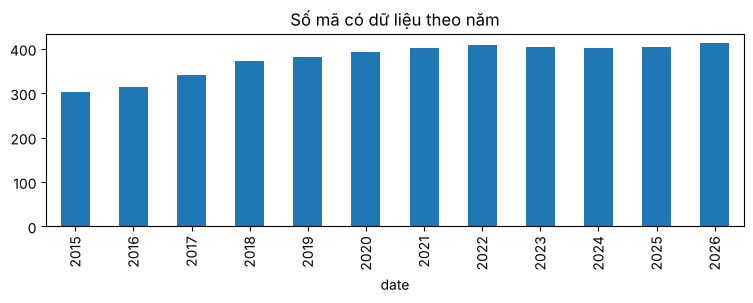

In [17]:
# Kiểm tra chất lượng dữ liệu
R_all = np.log(P).diff()
print("Tỷ lệ |r| > ngưỡng:", f"{(R_all.abs() > CONFIG['MAX_ABS_RET']).sum().sum() / R_all.notna().sum().sum():.4%}")
print("Tỷ lệ phiên giá không đổi (r = 0):", f"{(R_all == 0).sum().sum() / R_all.notna().sum().sum():.1%}")
P.notna().groupby(P.index.year).any().sum(axis=1).plot.bar(figsize=(9, 2.5), title="Số mã có dữ liệu theo năm"); plt.show()


In [18]:
cap("Hình", "Số mã có dữ liệu theo năm (ô kiểm tra chất lượng của thầy).")

**Hình 1.** Số mã có dữ liệu theo năm (ô kiểm tra chất lượng của thầy).

1

### 2.2 Chất lượng dữ liệu

In [19]:
cap("Bảng", "Chất lượng dữ liệu: khoảng thời gian, số mã, hủy niêm yết, quan sát bị loại, phiên đứng giá.")

**Bảng 3.** Chất lượng dữ liệu: khoảng thời gian, số mã, hủy niêm yết, quan sát bị loại, phiên đứng giá.

3

In [20]:
R_q = np.log(P).diff(); nq = int(R_q.notna().sum().sum()); inw = INWIN.reindex(P.index)
dl = MASTER.dropna(subset=["delisting_date"]); hp = dl.ticker.isin(P.columns)
TQ = pd.Series({
    "Khoảng thời gian": f"{P.index[0].date()} → {P.index[-1].date()} ({len(P)} phiên)",
    "Số mã trong security_master / có giá / thiếu giá": f"{MASTER.ticker.nunique()} / {P.shape[1]} / {len(MISSING)}",
    "Lượt hủy niêm yết (có giá / thiếu giá)": f"{len(dl)} ({int(hp.sum())} / {int((~hp).sum())})",
    "Quan sát ngoài khoảng niêm yết (đã loại)": f"{int(OUTSIDE.sum().sum())} (mã: {', '.join(OUTSIDE.sum()[OUTSIDE.sum() > 0].index)})",
    "% ô có giá trong khoảng niêm yết": f"{100 * (P.notna() & inw).sum().sum() / inw.sum().sum():.1f}%",
    "% phiên đứng giá (r = 0)": f"{100 * (R_q == 0).sum().sum() / nq:.1f}%",
    "Phiên |r| > 15% (đặt = 0) / khối lượng = 0 mà có giá / giá ≤ 0": f"{int((R_q.abs() > CONFIG['MAX_ABS_RET']).sum().sum())} / {int(((Q == 0) & P.notna()).sum().sum())} / {int((P <= 0).sum().sum())}"})
display(TQ.to_frame("giá trị"))


,giá trị
Khoảng thời gian,2015-01-05 → 2026-11-10 (2957 phiên)
Số mã trong security_master / có giá / thiếu giá,512 / 493 / 19
Lượt hủy niêm yết (có giá / thiếu giá),105 (86 / 19)
Quan sát ngoài khoảng niêm yết (đã loại),101 (mã: SAP)
% ô có giá trong khoảng niêm yết,94.1%
% phiên đứng giá (r = 0),15.3%
Phiên |r| > 15% (đặt = 0) / khối lượng = 0 mà có giá / giá ≤ 0,5 / 0 / 0


**Kết quả.**

- 512 mã, 493 mã có giá; 105 lượt hủy niêm yết: 86 có giá, 19 thiếu giá.
- 94,1% ô có giá trong khoảng niêm yết; 15,3% phiên đứng giá (r = 0).
- Không giá ≤ 0, không phiên khối lượng = 0 mà có giá; 101 quan sát ngoài khoảng niêm yết (mã SAP) đã loại; 5 phiên |r| > 15% đặt = 0.

**Kết luận.** Dữ liệu đủ dùng. Hạn chế: 19 mã hủy thiếu giá (14/19 hủy 2015–2018) và 15,3% phiên đứng giá.

### 2.3 Lịch sử niêm yết và hủy niêm yết

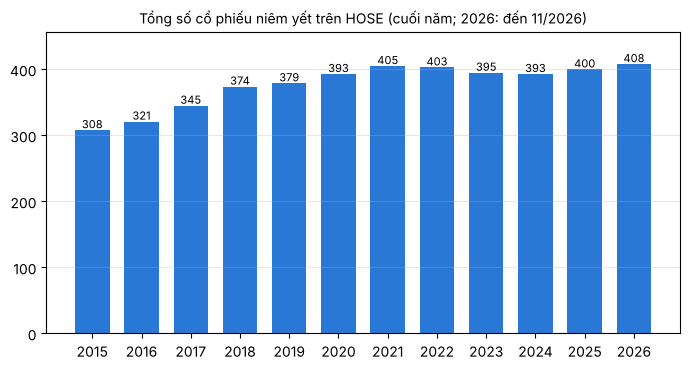

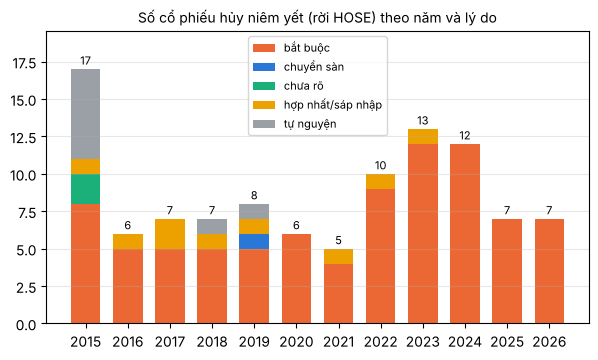

**Hình 2.** Tổng số cổ phiếu niêm yết trên HOSE cuối mỗi năm (2026: đến 11/2026).

**Hình 3.** Số cổ phiếu hủy niêm yết (rời HOSE) theo năm và lý do.

**Bảng 4.** Số mã hủy niêm yết theo năm và lý do (cột cuối: tổng số mã niêm yết cuối năm).

reason,bắt buộc,chuyển sàn,chưa rõ,hợp nhất/sáp nhập,tự nguyện,Tổng hủy,Niêm yết cuối năm
year,,,,,,,
2015,8,0,2,1,6,17,308
2016,5,0,0,1,0,6,321
2017,5,0,0,2,0,7,345
2018,5,0,0,1,1,7,374
2019,5,1,0,1,1,8,379
2020,6,0,0,0,0,6,393
2021,4,0,0,1,0,5,405
2022,9,0,0,1,0,10,403
2023,12,0,0,1,0,13,395


In [21]:
RN = {"bat_buoc": "bắt buộc", "hop_nhat": "hợp nhất/sáp nhập", "tu_nguyen": "tự nguyện", "chuyen_san": "chuyển sàn", "chua_ro": "chưa rõ"}
yrs = list(range(P.index[0].year, P.index[-1].year + 1)); ends = {y: min(pd.Timestamp(f"{y}-12-31"), P.index[-1]) for y in yrs}
tot = pd.Series({y: sum(1 for r in MASTER.itertuples() if r.listing_date <= ends[y] and (pd.isna(r.delisting_date) or r.delisting_date >= ends[y])) for y in yrs})
DY = dl.assign(year=dl.delisting_date.dt.year, reason=dl.reason.map(RN).fillna("chưa rõ")).pivot_table(index="year", columns="reason", values="ticker", aggfunc="count", fill_value=0).reindex(yrs, fill_value=0)
fig0, a0 = plt.subplots(figsize=(7, 3.8)); fig1, a1 = plt.subplots(figsize=(7, 3.8)); ax = [a0, a1]      # v6: tách thành hai hình
ax[0].bar(tot.index, tot.values, color="#2a78d6", width=.7)
for x_, v in tot.items(): ax[0].text(x_, v + 3, str(v), ha="center", fontsize=8)
ax[0].set_xticks(list(tot.index)); ax[1].set_xticks(yrs)
ax[0].set_title("Tổng số cổ phiếu niêm yết trên HOSE (cuối năm; 2026: đến 11/2026)", fontsize=10); ax[0].set_ylim(0, tot.max() * 1.12); ax[0].grid(axis="y", alpha=.3)
bot = np.zeros(len(DY))
for col, c in zip(DY.columns, ["#eb6834", "#2a78d6", "#1baf7a", "#eda100", "#9aa0a6"]):
    ax[1].bar(DY.index, DY[col], bottom=bot, color=c, width=.7, label=col); bot += DY[col].values
for x_, v in zip(DY.index, bot): ax[1].text(x_, v + .3, str(int(v)), ha="center", fontsize=8)
ax[1].set_title("Số cổ phiếu hủy niêm yết (rời HOSE) theo năm và lý do", fontsize=10); ax[1].legend(fontsize=8); ax[1].grid(axis="y", alpha=.3); ax[1].set_ylim(0, bot.max() * 1.15)
fig0.tight_layout(); savefig(fig0, "fig_2_niem_yet"); cap("Hình", "Tổng số cổ phiếu niêm yết trên HOSE cuối mỗi năm (2026: đến 11/2026).")
fig1.tight_layout(); savefig(fig1, "fig_3_huy_niem_yet"); cap("Hình", "Số cổ phiếu hủy niêm yết (rời HOSE) theo năm và lý do.")
cap("Bảng", "Số mã hủy niêm yết theo năm và lý do (cột cuối: tổng số mã niêm yết cuối năm).")
show(DY.assign(**{"Tổng hủy": DY.sum(1), "Niêm yết cuối năm": tot}).astype(int), 0)

**Kết quả.**

- Tổng số cổ phiếu niêm yết: 308 (cuối 2015) → 405 (2021, đỉnh) → 408 (11/2026).
- Hủy niêm yết 5–17 mã/năm, không năm nào bằng 0; nhiều nhất 2015 (17), 2023 (13), 2024 (12).
- Lý do: bắt buộc 85, hợp nhất 9, tự nguyện 8, chưa rõ 2, chuyển sàn 1.

**Kết luận.** Mã hủy xuất hiện đều đặn (~9 mã/năm), 81% là hủy bắt buộc ⇒ phải giữ trong dữ liệu để tránh survivorship bias.

### 2.4 Chọn ngưỡng lọc đứng giá

In [22]:
cap("Bảng", f"Số kỳ tái cân bằng đủ N = {CONFIG['N']} mã và số mã đủ điều kiện mỗi kỳ theo ngưỡng lọc đứng giá (cơ sở chọn `ZERO_MAX`).")

**Bảng 5.** Số kỳ tái cân bằng đủ N = 100 mã và số mã đủ điều kiện mỗi kỳ theo ngưỡng lọc đứng giá (cơ sở chọn `ZERO_MAX`).

5

In [23]:
Rm = R_q.mask(R_q.abs() > CONFIG["MAX_ABS_RET"], 0.0); Wn, rows = CONFIG["WINDOW"], []
for s in range(Wn + 1, len(P) - 1, CONFIG["REB"]):
    win = Rm.iloc[s - Wn:s]; ok = (win.notna().mean() >= .95) & P.iloc[s - 1].notna(); zs = (win == 0).mean()
    rows.append({z: int((ok & (zs <= z)).sum()) for z in (1.0, 0.2, 0.1)})
EL = pd.DataFrame(rows)
TE = pd.DataFrame({"ZERO_MAX": ["không lọc", "20% (chuẩn)", "10%"], f"số kỳ đủ N={CONFIG['N']} mã (/{len(EL)})": [(EL[z] >= CONFIG["N"]).sum() for z in EL],
                   "số mã đủ ĐK: trung vị": [int(EL[z].median()) for z in EL], "nhỏ nhất": [int(EL[z].min()) for z in EL]}).set_index("ZERO_MAX")
display(TE)


,số kỳ đủ N=100 mã (/129),số mã đủ ĐK: trung vị,nhỏ nhất
ZERO_MAX,,,
không lọc,129,278,166
20% (chuẩn),118,249,61
10%,69,114,3


**Kết quả.**

- Không lọc: đủ 100 mã ở 129/129 kỳ (trung vị 278 mã).
- Lọc 20%: 118/129 kỳ (trung vị 249 mã); 11 kỳ đầu (năm 2016) thiếu mã.
- Lọc 10%: chỉ 69/129 kỳ (trung vị 114 mã, có kỳ chỉ 3 mã).

**Kết luận.** Chọn `ZERO_MAX = 20%`: loại mã đứng giá mà vẫn giữ 118 kỳ; 10% quá chặt. Mẫu ngoài mẫu bắt đầu 12/2016.

## 3. Danh mục & backtest

Vũ trụ động: mỗi kỳ chọn N mã có giá trị GD trung vị cao nhất trong cửa sổ (≥95% phiên có dữ liệu). Mã ngừng GD ngoài mẫu → lợi suất 0.

### 3.1 `run_backtest` (của thầy)

In [13]:
def gmv_unconstrained(S):
    w = np.linalg.solve(S, np.ones(len(S))); return w / w.sum()

def gmv_long_only(S, iters=3000):
    # FISTA + chiếu lên đơn hình (khớp SLSQP, nhanh hơn)
    n = len(S)
    def proj(v):
        u = np.sort(v)[::-1]; css = np.cumsum(u) - 1
        k = np.nonzero(u - css / np.arange(1, n + 1) > 0)[0][-1]; return np.maximum(v - css[k] / (k + 1), 0)
    L = 2 * np.linalg.eigvalsh(S)[-1]; w = y = np.full(n, 1 / n); t = 1.0
    for _ in range(iters):
        wn = proj(y - 2 * S @ y / L); tn = (1 + np.sqrt(1 + 4*t*t)) / 2
        y = wn + (t - 1) / tn * (wn - w)
        if np.abs(wn - w).max() < 1e-9: return wn
        w, t = wn, tn
    return w

PERIODS = [("2008-09 Khủng hoảng TC", "2008-01-01", "2009-12-31"), ("2010-12 Lạm phát/nợ xấu", "2010-01-01", "2012-12-31"),
           ("2013-17 Ổn định", "2013-01-01", "2017-12-31"), ("2018-19 Điều chỉnh", "2018-01-01", "2019-12-31"),
           ("2020Q1 COVID", "2020-01-01", "2020-03-31"), ("2020-21 Bùng nổ", "2020-04-01", "2021-12-31"),
           ("2022 Sụt giảm", "2022-01-01", "2022-12-31"), ("2023-25", "2023-01-01", "2025-12-31")]

def run_backtest(P, V, estimators, cfg, long_only):
    N, W, REB = cfg["N"], cfg["WINDOW"], cfg["REB"]
    R = np.log(P).diff(); R = np.expm1(R.mask(R.abs() > cfg["MAX_ABS_RET"], 0.0))
    dates = R.index; names = list(estimators)
    rets = {k: [] for k in names}; idx = []; reb_dates = []
    Wp = {k: pd.Series(dtype=float) for k in names}
    st = {k: dict(turn=[], neff=[], wmax=[], short=[]) for k in names}
    for s in range(W + 1, len(dates) - 1, REB):
        win = R.iloc[s - W:s]; ok = (win.notna().mean() >= .95) & P.iloc[s - 1].notna()
        if ok.sum() < N: continue
        tick = V.iloc[s - W:s].loc[:, ok].median().sort_values(ascending=False).index[:N]
        X = win[tick].fillna(0).values; Y = R.iloc[s:s + REB][tick].fillna(0).values
        idx.extend(dates[s:s + REB]); reb_dates.append(dates[s])
        for k in names:
            S = estimators[k](X)
            w = gmv_long_only(S) if long_only else gmv_unconstrained(S)
            ws = pd.Series(w, index=tick)
            if len(Wp[k]):
                u = ws.index.union(Wp[k].index)
                st[k]["turn"].append((ws.reindex(u).fillna(0) - Wp[k].reindex(u).fillna(0)).abs().sum())
            Wp[k] = ws; rets[k].extend(Y @ w)
            st[k]["neff"].append(1 / (w**2).sum()); st[k]["wmax"].append(w.max()); st[k]["short"].append(np.clip(-w, 0, None).sum())
    out = {}
    for k in names:
        r = pd.Series(rets[k], index=idx); rn = r.copy()
        rn.loc[reb_dates[1:]] -= cfg["COST"] * np.array(st[k]["turn"])
        out[k] = dict(r=r, r_net=rn, m={
            "Vol %": r.std() * np.sqrt(252) * 100, "LN/năm %": r.mean() * 252 * 100,
            "Sharpe": r.mean() / r.std() * np.sqrt(252), "Sharpe sau phí": rn.mean() / rn.std() * np.sqrt(252),
            "Turnover/kỳ": np.mean(st[k]["turn"]), "Số mã hiệu dụng": np.mean(st[k]["neff"]),
            "Tỷ trọng max %": np.mean(st[k]["wmax"]) * 100, "Short %": np.mean(st[k]["short"]) * 100})
    return out

def block_bootstrap_ci(ra, rb, block=21, B=2000, seed=0):
    # CI 95% cho Vol(a) − Vol(b), %/năm. (T3: bổ sung kiểm định Ledoit–Wolf 2011)
    rng = np.random.default_rng(seed); n = len(ra); nb = n // block; d = np.empty(B)
    for i in range(B):
        ix = (rng.integers(0, n - block, nb)[:, None] + np.arange(block)).ravel()
        d[i] = (ra[ix].std() - rb[ix].std()) * np.sqrt(252) * 100
    return np.percentile(d, [2.5, 97.5])

def summarize(out, pairs):
    tab = pd.DataFrame({k: o["m"] for k, o in out.items()}).T
    per = pd.DataFrame({k: {p: o["r"][s:e].std() * np.sqrt(252) * 100 for p, s, e in PERIODS if len(o["r"][s:e]) > 20}
                        for k, o in out.items()}).T
    ci = pd.DataFrame({f"{a} vs {b}": block_bootstrap_ci(out[a]["r"].values, out[b]["r"].values)
                       for a, b in pairs if a in out and b in out}, index=["CI 2.5%", "CI 97.5%"]).T
    ci["Có ý nghĩa"] = (ci["CI 97.5%"] < 0) | (ci["CI 2.5%"] > 0)
    return tab, per, ci


### 3.2 Lọc mã đứng giá (`ZERO_MAX`) — không sửa `run_backtest` của thầy

`run_backtest` bên dưới được **sinh từ chính mã nguồn của thầy** (`inspect.getsource`), chỉ chèn: (i) trước `if ok.sum() < N: continue`: `ok &= (win == 0).mean() <= cfg.get("ZERO_MAX", 1.0)` (chỉ dùng cửa sổ quá khứ; kỳ không đủ N mã bị bỏ); (ii) ghi log universe; (iii) sau dòng tính `Y`, cộng ma trận điều chỉnh `d` (mặc định không dùng; T2d dùng để đặt lợi suất ngày hủy niêm yết, không đụng tới giá `P`); (iv) bộ VS "đủ T" (§5.4) nhận thêm HL\_VOL phiên ngay trước cửa sổ (chỉ dữ liệu quá khứ). Với `ZERO_MAX = 1.0` và `d = 0` kết quả trùng hệt bản của thầy (assert). `PERIODS` theo mẫu 2016–2026.

In [14]:
import inspect
ULOG = []
ADJ = {"d": None}          # T2d: {(ngày, mã): cú sốc lợi suất}; None = không điều chỉnh (đúng như bản chuẩn)
def _adj_block(days, tick):
    # ma trận điều chỉnh d (số ngày × N) cho các ngày của kỳ nắm giữ; chỉ cộng vào Y, không đụng tới P hay cửa sổ ước lượng
    M = np.zeros((len(days), len(tick)))
    if ADJ["d"] is not None:
        col = {t: j for j, t in enumerate(tick)}
        for i, dd in enumerate(days):
            for t, j in col.items():
                M[i, j] = ADJ["d"].get((dd, t), 0.0)
    return M
_src = inspect.getsource(run_backtest)
_chk = "        if ok.sum() < N: continue\n"
_sel = "        tick = V.iloc[s - W:s].loc[:, ok].median().sort_values(ascending=False).index[:N]\n"
_Y = "        X = win[tick].fillna(0).values; Y = R.iloc[s:s + REB][tick].fillna(0).values\n"
_S = "            S = estimators[k](X)\n"
assert _src.count(_chk) == 1 and _src.count(_sel) == 1 and _src.count(_Y) == 1 and _src.count(_S) == 1, "mã nguồn run_backtest của thầy đã đổi"
PRE_SHORT = []      # v6 §5.4: số kỳ thiếu phiên trước cửa sổ cho bộ VS "đủ T"
def _xpre(R, s, W, tick, pre):
    # v6: cửa sổ mở rộng thêm `pre` phiên NGAY TRƯỚC cửa sổ ước lượng (chỉ dữ liệu quá khứ) để khởi động EWMA của bộ VS "đủ T"
    a = s - W - pre
    if a < 0: PRE_SHORT.append(-a)
    E = R.iloc[max(0, a):s][tick]; return np.vstack([E.iloc[:-W].values, E.iloc[-W:].fillna(0).values])     # phần trước cửa sổ giữ NaN (mã chưa niêm yết)
exec(_src.replace("def run_backtest(", "def run_backtest_x(")
         .replace(_chk, '        ok &= (win == 0).mean() <= cfg.get("ZERO_MAX", 1.0)          # v3: lọc mã đứng giá (cửa sổ quá khứ)\n' + _chk)
         .replace(_sel, _sel + "        ULOG.append(dict(date=dates[s], n_eligible=int(ok.sum()), tickers=list(tick)))\n")
         .replace(_S, "            S = estimators[k](X if not getattr(estimators[k], 'pre', 0) else _xpre(R, s, W, tick, estimators[k].pre))            # v6: bộ VS \"đủ T\"\n")
         .replace(_Y, _Y + "        if ADJ[\"d\"] is not None: Y = Y.copy(order=\"K\"); Y += _adj_block(dates[s:s + REB], tick)            # v4 T2d: cú sốc ngày hủy niêm yết (chỉ vào lợi suất nắm giữ)\n"))
run_backtest_thay = run_backtest                        # bản gốc của thầy (đối chứng)
def run_backtest(*a, **k):                              # các ô của thầy gọi run_backtest → dùng bản có lọc (và điều chỉnh nếu ADJ["d"])
    ULOG.clear(); return run_backtest_x(*a, **k)

PERIODS = [("2016-17 Ổn định", "2016-01-01", "2017-12-31"), ("2018-19 Điều chỉnh", "2018-01-01", "2019-12-31"),
           ("2020Q1 COVID", "2020-01-01", "2020-03-31"), ("2020-21 Bùng nổ", "2020-04-01", "2021-12-31"),
           ("2022 Sụt giảm", "2022-01-01", "2022-12-31"), ("2023-24 Phục hồi", "2023-01-01", "2024-12-31"),
           ("2025-26", "2025-01-01", "2026-12-31")]

_p, _v = P.iloc[-900:], V.iloc[-900:]                   # kiểm tra: ZERO_MAX = 1.0 ⇒ trùng hệt bản của thầy; ADJ rỗng ⇒ không đổi
_a = run_backtest_thay(_p, _v, {"NL-LW": est_nllw}, CONFIG, True)["NL-LW"]["r"]
_b = run_backtest(_p, _v, {"NL-LW": est_nllw}, dict(CONFIG, ZERO_MAX=1.0), True)["NL-LW"]["r"]
assert _a.index.equals(_b.index) and np.array_equal(_a.values, _b.values)
ADJ["d"] = {}                                           # d = 0 (dict rỗng nhưng bật nhánh cộng): phải trùng hệt
_c = run_backtest(_p, _v, {"NL-LW": est_nllw}, dict(CONFIG, ZERO_MAX=1.0), True)["NL-LW"]["r"]; ADJ["d"] = None
assert np.array_equal(_b.values, _c.values)
print(f"run_backtest (có lọc) ≡ run_backtest của thầy khi ZERO_MAX = 1.0 ✔ | d = 0 trùng hệt ✔ | cấu hình chuẩn: ZERO_MAX = {CONFIG['ZERO_MAX']:.0%}")

run_backtest (có lọc) ≡ run_backtest của thầy khi ZERO_MAX = 1.0 ✔ | d = 0 trùng hệt ✔ | cấu hình chuẩn: ZERO_MAX = 20%


### 3.3 Tiện ích chung

- `run` (backtest có cache theo từng phương pháp), `run_full`, `metrics`, `cap` (chú thích "Bảng n"/"Hình n").
- Đối chứng thêm cho T3 (1/N, PCA-auto, DCC-GARCH(1,1)) và bộ VS-EW-RIE\*; bộ VS "đủ T" (§5.4) và hai biến thể VS của T5d.
- **12 phương pháp `M12`:** 10 bộ của thầy, EW-WeSpeR, VS-EW-RIE\*. **12 cặp định trước `PAIRS12`**, mỗi cặp chỉ khác một thành phần; ΔVol = Vol(bộ trước) − Vol(bộ sau), âm là bộ trước rủi ro thấp hơn:

| Cụm | Câu hỏi | Cặp |
|---|---|---|
| A | Làm sạch đúng lý thuyết có hơn xấp xỉ không? | EW-RIE\* − EW-NL-LW · EW-RIE\* − EW-RIE (q_eff) · EW-RIE\* − EW-WeSpeR |
| B | Trọng số mũ có giúp không? | EW-NL-LW − NL-LW · EW-RIE\* − RIE |
| C | Trước và sau chuẩn hóa biến động (VS) | VS-NL-LW − NL-LW · VS-RIE − RIE · VS-EW-RIE\* − EW-RIE\* |
| D | Trong họ VS, ai hơn? | VS-EW-RIE\* − VS-NL-LW · VS-EW-RIE\* − VS-RIE · VS-RIE − VS-NL-LW |
| E | Trọng số mũ hay VS? (cặp thầy hỏi) | EW-RIE\* − VS-NL-LW |

- **Kiểm định:** sai khác phương sai Ledoit–Wolf (2011), bản HAC và bản bootstrap khối (b = 21, M = 2000; **p bootstrap là kết quả chính**); Holm trên cả 12 cặp, riêng từng cấu hình và từng chế độ; Jobson–Korkie–Memmel cho Sharpe. `pair_table` (bảng chi tiết), `pair_grid` + `pair_heatmap` (heatmap cặp; dấu \* chỉ hiệu chỉnh trong từng cột, mang tính mô tả), Bảng A (`table_a`: hàng = phương pháp, in đậm giá trị thấp nhất mỗi cột).

In [15]:
# ---- 3.3 Tiện ích chung cho §4–§6 (tái dùng run_backtest, summarize, block_bootstrap_ci của thầy) ----
import hashlib, json, platform, importlib.util
from IPython.display import Markdown
from scipy.stats import norm
if importlib.util.find_spec("arch") is None:      # Colab chưa có sẵn `arch` (dùng cho DCC-GARCH)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "arch"], check=True)
RECOMPUTE = False                       # True: chạy lại mọi backtest; False: dùng cache results_v6/cache/*.pkl nếu có
MODES = {"long_only": True, "short_ok": False}
COL = {"EW-RIE*": "#1baf7a", "NL-LW": "#2a78d6", "EW-NL-LW": "#eb6834", "EW-WeSpeR": "#8e44ad", "VS-NL-LW": "#e0a800"}
GREY = "#9aa0a6"; col_of = lambda k: COL.get(k, GREY)

TIMES = {}
def check_cov(S, name=""):                      # đối xứng, PSD, không NaN
    ev = np.linalg.eigvalsh((S + S.T) / 2)
    assert np.isfinite(S).all() and np.allclose(S, S.T, rtol=0, atol=1e-10 * np.abs(S).max()) and ev[0] > -1e-10 * ev[-1], name
    return ev
def timed(name, f):
    def g(X):
        t = time.perf_counter(); S = f(X); TIMES.setdefault(name, []).append(time.perf_counter() - t); check_cov(S, name); return S
    return g

def run(est, cfg=None, long_only=True, data=None, tag=""):
    # backtest có cache: khóa = tên bộ ước lượng + cfg + chế độ (+ tag dữ liệu). Trả về out, log universe, thời gian, số lần Newton thất bại.
    cfg = cfg or CONFIG; Pd, Vd = data if data is not None else (P, V)
    f = f"{CACHE}/{hashlib.md5(repr((sorted(est), sorted(cfg.items()), long_only) + ((tag,) if tag else ())).encode()).hexdigest()[:12]}.pkl"
    if os.path.exists(f) and not RECOMPUTE: d = pd.read_pickle(f)
    else:
        TIMES.clear(); ULOG.clear(); f0, n0 = _STATS["fail"], _STATS["total"]
        out = run_backtest(Pd, Vd, {k: timed(k, g) for k, g in est.items()}, cfg, long_only)
        d = dict(out=out, ulog=list(ULOG), sec={k: np.mean(v) for k, v in TIMES.items()},
                 newton=(_STATS["fail"] - f0, _STATS["total"] - n0)); pd.to_pickle(d, f)
    idx = [o["r"].index for o in d["out"].values()]
    assert all(i.equals(idx[0]) for i in idx), "common-sample vi phạm"      # cùng ngày OOS cho mọi phương pháp
    return d

net = lambda o, c: o["r"] - (c / CONFIG["COST"]) * (o["r"] - o["r_net"])   # r_net ở mức phí c (phí không đổi tỷ trọng)
ann = lambda r: (r.std() * np.sqrt(252) * 100, r.mean() / r.std() * np.sqrt(252))
def metrics(o, cost=None, dates=None):
    r, rn = o["r"], net(o, cost or CONFIG["COST"])
    if dates is not None: r, rn = r.loc[dates], rn.loc[dates]
    return {"Vol %": ann(r)[0], "Sharpe": ann(r)[1], "Sharpe sau phí": ann(rn)[1], "LN/năm %": r.mean() * 252 * 100,
            "Turnover/kỳ": o["m"]["Turnover/kỳ"], "Số mã hiệu dụng": o["m"]["Số mã hiệu dụng"], "Số ngày OOS": len(r)}


R_BT = np.log(P).diff(); R_BT = np.expm1(R_BT.mask(R_BT.abs() > CONFIG["MAX_ABS_RET"], 0.0))   # đúng như trong run_backtest
POS = {d: i for i, d in enumerate(R_BT.index)}

In [16]:
# ---- 3.3 (tiếp) Kiểm định dùng chung: phương sai Ledoit–Wolf (2011) HAC + bootstrap khối, Jobson–Korkie–Memmel ----
def hac(u, L=None):
    # HAC Newey–West (Bartlett), L = ⌊4(T/100)^(2/9)⌋. (LW 2008/2011 dùng QS/Parzen + prewhitening – chưa làm.)
    T = len(u); L = L or int(4 * (T / 100) ** (2 / 9)); S = u.T @ u / T
    for l in range(1, L + 1): G = u[l:].T @ u[:-l] / T; S += (1 - l / (L + 1)) * (G + G.T)
    return S

def _lw_stat(y, Psi=None, b=None):
    # Δ = log σ²_a − log σ²_b (LW 2011, delta method); y_t = (r_a, r_b, r_a², r_b²)
    T = len(y); m = y.mean(0); va, vb = m[2] - m[0]**2, m[3] - m[1]**2
    g = np.array([-2 * m[0] / va, 2 * m[1] / vb, 1 / va, -1 / vb])
    if Psi is None:   # Ψ của bootstrap theo khối (LW 2008, công thức (9))
        z = (y - m)[:T // b * b].reshape(-1, b, 4).sum(1) / np.sqrt(b); Psi = z.T @ z / len(z)
    return np.log(va) - np.log(vb), np.sqrt(g @ Psi @ g / T)

def lw_var_test(ra, rb, block=21, M=2000, seed=SEED):
    # p-value HAC (chuẩn) và p-value studentized circular block bootstrap (LW 2008 Remark 3.2, áp cho phương sai như LW 2011)
    y = np.column_stack([ra, rb, ra**2, rb**2]); T = len(y)
    d, se = _lw_stat(y, hac(y - y.mean(0))); p_hac = 2 * norm.sf(abs(d / se))
    rng = np.random.default_rng(seed); l = T // block; stats = np.empty(M)
    for i in range(M):
        ix = ((rng.integers(0, T, l)[:, None] + np.arange(block)) % T).ravel()      # khối vòng
        ds, ses = _lw_stat(y[ix], b=block); stats[i] = abs(ds - d) / ses
    return d, se, p_hac, (np.sum(stats >= abs(d) / se) + 1) / (M + 1)

def jkm_test(ra, rb):
    # Jobson–Korkie (1981) với hiệu chỉnh Memmel (2003); giả định iid chuẩn
    T = len(ra); m1, m2 = ra.mean(), rb.mean(); s1, s2 = ra.std(ddof=1), rb.std(ddof=1); s12 = np.cov(ra, rb)[0, 1]
    th = (2 * s1**2 * s2**2 - 2 * s1 * s2 * s12 + .5 * m1**2 * s2**2 + .5 * m2**2 * s1**2 - m1 * m2 / (s1 * s2) * s12**2) / T
    z = (s2 * m1 - s1 * m2) / np.sqrt(th); return z, 2 * norm.sf(abs(z))

# unit test nhanh: gần trùng ⇒ p lớn; gấp đôi biến động ⇒ p≈0; JKM phản đối xứng
_r = np.random.default_rng(SEED).standard_normal(1500) * .01
assert lw_var_test(_r, _r + 1e-5 * np.random.default_rng(1).standard_normal(1500), M=200)[3] > .1
assert lw_var_test(_r, 2 * _r[::-1], M=200)[2] < 1e-6
_q = np.random.default_rng(2).standard_normal(1500) * .01
assert np.isclose(jkm_test(_r, _q)[0], -jkm_test(_q, _r)[0]) and jkm_test(_r + .003, _q - .003)[1] < 1e-6

In [17]:
# ---- 3.3 (tiếp) Đối chứng bổ sung (1/N, PCA, DCC-GARCH, VS-EW-RIE*), tập FULL, chạy từng phương pháp có cache ----
from arch import arch_model

def est_equal_weight_proxy(X):
    # 1/N: dùng ma trận đơn vị -> GMV = 1/N (chiến lược phân bổ, KHÔNG phải bộ ước lượng hiệp phương sai)
    return np.eye(X.shape[1])

def est_pca(k):
    # Σ = B Bᵀ + diag(ψ): k thành phần chính của hiệp phương sai mẫu, phần dư chéo (đối xứng, PSD theo cấu trúc)
    def est(X):
        S = np.cov(X, rowvar=False); lam, Q = np.linalg.eigh(S); B = Q[:, -k:] * np.sqrt(lam[-k:])
        return B @ B.T + np.diag(np.maximum(np.diag(S) - (B**2).sum(1), 1e-10))
    return est

PCA_K = []
def est_pca_auto(X, ks=(1, 3, 5), split=0.7):
    # chọn k CHỈ trong cửa sổ huấn luyện: ước lượng trên 70% đầu, đo phương sai GMV trên 30% cuối, rồi ước lượng lại trên cả cửa sổ
    n = int(len(X) * split)
    k = min(ks, key=lambda k: np.var(X[n:] @ gmv_unconstrained(est_pca(k)(X[:n]))))
    PCA_K.append(k); return est_pca(k)(X)

DCC_LOG, _DCC_CACHE = [], {}
def _dcc_ncl(p, Z, Qbar):
    # −composite log-lik (Engle, Shephard & Sheppard 2008): tổng log-lik 2×2 của các cặp kề nhau (i, i+1).
    a, b = p
    if a < 0 or b < 0 or a + b >= 0.999: return 1e10
    z1, z2 = Z[:, :-1], Z[:, 1:]; q11, q22, q12 = np.diag(Qbar)[:-1], np.diag(Qbar)[1:], np.diag(Qbar, 1)
    c11, c22, c12 = q11.copy(), q22.copy(), q12.copy(); nll = 0.0
    for t in range(len(Z)):
        if t:
            c11 = (1-a-b)*q11 + a*z1[t-1]**2 + b*c11; c22 = (1-a-b)*q22 + a*z2[t-1]**2 + b*c22
            c12 = (1-a-b)*q12 + a*z1[t-1]*z2[t-1] + b*c12
        rho = c12 / np.sqrt(c11 * c22); d = 1 - rho**2
        nll += 0.5 * np.sum(np.log(d) + (z1[t]**2 + z2[t]**2 - 2*rho*z1[t]*z2[t]) / d)
    return nll

def est_dcc(X, h=21, use_cache=True):
    # DCC-GARCH(1,1) (Engle 2002): bước 1 GARCH(1,1) đơn biến (`arch`) cho từng mã; bước 2 (a, b) bằng composite
    # likelihood + correlation targeting; ma trận Q_t đầy đủ N×N. Dự báo: D = căn phương sai GARCH trung bình h phiên tới, R = R_{T+1|T}; Σ = D R D.
    key = hash(X.tobytes())
    if use_cache and key in _DCC_CACHE: return _DCC_CACHE[key]               # cùng cửa sổ ở long_only/short_ok → không ước lượng lại
    T, N = X.shape; Z = np.empty_like(X); hv = np.empty(N); bad = 0
    for i in range(N):
        try:
            r = arch_model(100 * X[:, i], mean="Constant", vol="GARCH", p=1, q=1, rescale=False).fit(disp="off", show_warning=False)
            ok = r.convergence_flag == 0 and r.params["alpha[1]"] + r.params["beta[1]"] < 1
        except Exception:
            ok = False
        if ok:
            Z[:, i] = r.std_resid; hv[i] = r.forecast(horizon=h, reindex=False).variance.values[-1].mean() / 1e4
        else:                                                   # dự phòng: phương sai mẫu (đếm vào DCC_LOG)
            bad += 1; Z[:, i] = (X[:, i] - X[:, i].mean()) / X[:, i].std(); hv[i] = X[:, i].var()
    Qbar = Z.T @ Z / T
    res = minimize(_dcc_ncl, x0=[0.02, 0.95], args=(Z, Qbar), method="Nelder-Mead", options=dict(xatol=1e-4, fatol=1e-3, maxiter=200))
    a, b = res.x if res.fun < 1e9 else (0.0, 0.0)
    Qt = Qbar.copy()
    for t in range(1, T + 1): Qt = (1 - a - b) * Qbar + a * np.outer(Z[t-1], Z[t-1]) + b * Qt    # Q_{T+1}
    d = 1 / np.sqrt(np.diag(Qt)); sd = np.sqrt(hv)
    S = (Qt * np.outer(d, d)) * np.outer(sd, sd)
    DCC_LOG.append(dict(a=a, b=b, garch_fail=bad, dcc_ok=bool(res.success)))
    if use_cache: _DCC_CACHE[key] = S
    return S

def make_vs_ew_rie(hl_vol, hl):
    # VS + EW-RIE*: chuẩn hóa biến động EWMA (như VS-NL-LW), rồi EW-RIE* trên tương quan trọng số mũ của Z; nhân lại biến động hiện tại
    def est(X):
        Z, sig = ewma_standardize(X, hl_vol); Z = Z[hl_vol:]
        w = ew_weights(len(Z), hl); C, _ = ew_corr(Z, w)
        return ew_rie_corr(C, w) * np.outer(sig, sig)
    return est
est_vs_ew_rie = make_vs_ew_rie(CONFIG["HL_VOL"], CONFIG["HL_EW"])

FULL = ["Sample", "Ledoit-Wolf", "NL-LW", "MP-clip", "RIE", "VS-NL-LW", "VS-RIE", "EW-NL-LW", "EW-RIE (q_eff)", "EW-WeSpeR", "EW-RIE*",
        "PCA-auto", "DCC-GARCH(1,1)", "1/N", "VS-EW-RIE*"]
def build_full(cfg):
    E = build_estimators(dict(cfg, QUICK=False))
    E.update({"PCA-auto": est_pca_auto, "DCC-GARCH(1,1)": est_dcc, "1/N": est_equal_weight_proxy,
              "VS-EW-RIE*": make_vs_ew_rie(cfg["HL_VOL"], cfg["HL_EW"])})
    return {k: E[k] for k in FULL}

# Tham số nào mỗi phương pháp thực sự dùng → chuẩn hóa phần không dùng để một lần tính phục vụ nhiều cấu hình (cache theo từng phương pháp)
USES_HL_EW = {"EW-NL-LW", "EW-RIE (q_eff)", "EW-WeSpeR", "EW-RIE*", "VS-EW-RIE*"}; USES_HL_VOL = {"VS-NL-LW", "VS-RIE", "VS-EW-RIE*"}
def canon_cfg(cfg, k):
    return dict(cfg, HL_EW=cfg["HL_EW"] if k in USES_HL_EW else 60, HL_VOL=cfg["HL_VOL"] if k in USES_HL_VOL else 20)

def run_full(cfg=None, long_only=True, methods=None, data=None, tag=""):
    # chạy TỪNG phương pháp (mỗi cái có cache riêng) rồi ghép ⇒ thêm phương pháp không làm tính lại phương pháp khác
    cfg = cfg or CONFIG; E = build_full(cfg); methods = list(methods or FULL); parts = {}
    for k in methods:
        if k == "EW-WeSpeR": _WSP["warm"].clear()               # khởi tạo ấm không rò giữa các lần chạy ⇒ tái lập được
        parts[k] = run({k: E[k]}, canon_cfg(cfg, k), long_only, data, tag)
    ref = parts[methods[0]]
    for k in methods: assert [u["date"] for u in parts[k]["ulog"]] == [u["date"] for u in ref["ulog"]], f"universe khác: {k}"
    out = {k: parts[k]["out"][k] for k in methods}
    idx = out[methods[0]]["r"].index; assert all(o["r"].index.equals(idx) for o in out.values()), "common-sample vi phạm"
    return dict(out=out, ulog=ref["ulog"], sec={k: parts[k]["sec"].get(k, np.nan) for k in methods},
                newton=tuple(np.sum([parts[k]["newton"] for k in methods], axis=0)))

In [18]:
# ---- 3.3 (v6) Bộ ước lượng bổ sung cho §5.4 và T5d; 12 phương pháp, 12 cặp định trước; bảng A và heatmap cặp ----
def timed(name, f):                     # (định nghĩa lại) giữ thuộc tính `pre` của bộ VS "đủ T" khi bọc đo thời gian
    def g(X):
        t = time.perf_counter(); S = f(X); TIMES.setdefault(name, []).append(time.perf_counter() - t); check_cov(S, name); return S
    g.pre = getattr(f, "pre", 0); return g

def ewma_sig(X, hl):
    # độ lệch chuẩn EWMA dùng tại từng phiên, đúng số học của ewma_standardize của thầy; trả về (σ_t cho t = 0..T−1, σ sau phiên cuối)
    lam = 0.5 ** (1 / hl); s2 = X[:hl].var(0) + 1e-10; S = np.empty_like(X)
    for t in range(len(X)):
        S[t] = np.sqrt(s2); s2 = lam * s2 + (1 - lam) * X[t]**2
    return S, np.sqrt(s2)

def make_vs_split(part, hl_vol):
    # T5d (cách nhóm hiểu gợi ý (a) của thầy): σ_m = EWMA của lợi suất trung bình đều N mã; ρ_i = σ_i / σ_m. Cùng bộ làm sạch NL-LW, cùng bỏ HL_VOL phiên đầu như make_vs.
    clean = lambda Z: renorm(nl_lw_S(np.cov(Z, rowvar=False), len(Z) - 1))
    def est(X):
        Si, si_T = ewma_sig(X, hl_vol); Sm, sm_T = ewma_sig(X.mean(1, keepdims=True), hl_vol)
        if part == "chung":                       # chỉ phần chung: Z = X / σ_m
            Z = (X / Sm)[hl_vol:]; s = Z.std(0, ddof=1); return clean(Z) * np.outer(s, s)
        rho = Si / Sm; Z = (X / rho)[hl_vol:]     # chỉ phần riêng: Z = X / ρ
        s = Z.std(0, ddof=1) * (si_T / sm_T); return clean(Z) * np.outer(s, s)
    return est

PRE_FALLBACK = {"n": 0, "cols": 0}     # số (kỳ × mã) không có đủ dữ liệu trước cửa sổ ⇒ khởi động EWMA trên đầu cửa sổ như make_vs
def ewma_standardize_full(Xe, hl):
    # Xe = [hl phiên trước cửa sổ (có thể NaN) ; T phiên cửa sổ]. Mã có đủ hl phiên trước cửa sổ (không NaN, phương sai > 0): EWMA khởi động trên đoạn đó rồi chuẩn hóa đủ T phiên.
    # Mã thiếu (chưa niêm yết, hoặc toàn 0): khởi động như ewma_standardize trên đầu cửa sổ (không bỏ phiên nào). Trả về Z (T × N) và σ cuối.
    pre, X = Xe[:hl], Xe[hl:]; good = np.isfinite(pre).all(0) & (np.nan_to_num(pre).var(0) > 0)
    Z = np.empty_like(X); sig = np.empty(X.shape[1])
    if good.any(): z, s_ = ewma_standardize(np.vstack([pre[:, good], X[:, good]]), hl); Z[:, good], sig[good] = z[hl:], s_
    if (~good).any(): z, s_ = ewma_standardize(X[:, ~good], hl); Z[:, ~good], sig[~good] = z, s_
    PRE_FALLBACK["cols"] += int((~good).sum()); PRE_FALLBACK["n"] += 1
    return Z, sig
def make_vs_full(corr_cleaner, hl_vol):
    # bản "đủ T" của make_vs: nhận thêm hl_vol phiên trước cửa sổ (est.pre), tương quan tính trên đủ T phiên
    def est(Xe):
        Z, sig = ewma_standardize_full(Xe, hl_vol); return corr_cleaner(Z) * np.outer(sig, sig)
    est.pre = hl_vol; return est
def make_vs_ew_rie_full(hl_vol, hl):
    def est(Xe):
        Z, sig = ewma_standardize_full(Xe, hl_vol); w = ew_weights(len(Z), hl); C, _ = ew_corr(Z, w)
        return ew_rie_corr(C, w) * np.outer(sig, sig)
    est.pre = hl_vol; return est

EXTRA6 = ["VS-NL-LW (đủ T)", "VS-RIE (đủ T)", "VS-EW-RIE* (đủ T)", "VS chỉ phần chung", "VS chỉ phần riêng"]
_build_full5 = build_full
def build_full(cfg):
    E = _build_full5(cfg); hv, hl = cfg["HL_VOL"], cfg["HL_EW"]
    E.update({"VS-NL-LW (đủ T)": make_vs_full(lambda Z: renorm(nl_lw_S(np.cov(Z, rowvar=False), len(Z) - 1)), hv),
              "VS-RIE (đủ T)": make_vs_full(lambda Z: rie_corr(np.corrcoef(Z, rowvar=False), Z.shape[1] / len(Z)), hv),
              "VS-EW-RIE* (đủ T)": make_vs_ew_rie_full(hv, hl),
              "VS chỉ phần chung": make_vs_split("chung", hv), "VS chỉ phần riêng": make_vs_split("riêng", hv)})
    return E
USES_HL_EW |= {"VS-EW-RIE* (đủ T)"}; USES_HL_VOL |= {"VS-NL-LW (đủ T)", "VS-RIE (đủ T)", "VS-EW-RIE* (đủ T)", "VS chỉ phần chung", "VS chỉ phần riêng"}

M12 = ["Sample", "Ledoit-Wolf", "NL-LW", "MP-clip", "RIE", "VS-NL-LW", "VS-RIE", "EW-NL-LW", "EW-RIE (q_eff)", "EW-WeSpeR", "EW-RIE*", "VS-EW-RIE*"]
PAIRS12 = [("A. Làm sạch", "EW-RIE*", "EW-NL-LW"), ("A. Làm sạch", "EW-RIE*", "EW-RIE (q_eff)"), ("A. Làm sạch", "EW-RIE*", "EW-WeSpeR"),
           ("B. Trọng số mũ", "EW-NL-LW", "NL-LW"), ("B. Trọng số mũ", "EW-RIE*", "RIE"),
           ("C. Trước/sau VS", "VS-NL-LW", "NL-LW"), ("C. Trước/sau VS", "VS-RIE", "RIE"), ("C. Trước/sau VS", "VS-EW-RIE*", "EW-RIE*"),
           ("D. Trong họ VS", "VS-EW-RIE*", "VS-NL-LW"), ("D. Trong họ VS", "VS-EW-RIE*", "VS-RIE"), ("D. Trong họ VS", "VS-RIE", "VS-NL-LW"),
           ("E. EW hay VS", "EW-RIE*", "VS-NL-LW")]

def holm(p):
    p = np.asarray(p, float); o = np.argsort(p); adj = np.minimum(1, np.maximum.accumulate(p[o] * (len(p) - np.arange(len(p)))))
    out = np.empty(len(p)); out[o] = adj; return out

def turnover_series(o, reb_dates, cost=None):
    # turnover từng kỳ, khôi phục từ r − r_net tại các ngày tái cân bằng (kỳ đầu không có turnover)
    return ((o["r"] - o["r_net"]).reindex(reb_dates[1:]) / (cost or CONFIG["COST"])).values

def pair_table(out, pairs=PAIRS12, reb_dates=None, block=21, M=2000, B=2000, seed=0):
    # Bảng kiểm định chi tiết: mỗi cặp (a, b) chỉ khác một thành phần. ΔVol = Vol(a) − Vol(b); < 0 ⇒ a rủi ro thấp hơn.
    rows = []
    for g, a, b in pairs:
        assert out[a]["r"].index.equals(out[b]["r"].index), f"khác mẫu: {a}, {b}"
        ra, rb = out[a]["r"].values, out[b]["r"].values; lo, hi = block_bootstrap_ci(ra, rb, block=block)
        d, se, p_hac, p_bt = lw_var_test(ra, rb, block=block, M=M)
        row = {"Cụm": g, "Cặp": f"{a} − {b}", "ΔVol (pp)": (ra.std() - rb.std()) * np.sqrt(252) * 100, "CI lo": lo, "CI hi": hi,
               "p LW-HAC": p_hac, "p LW-boot": p_bt, "p JKM": jkm_test(ra, rb)[1]}
        if reb_dates is not None:                                   # chênh lệch turnover/kỳ + CI bootstrap theo kỳ (ghép cặp)
            dt = turnover_series(out[a], reb_dates) - turnover_series(out[b], reb_dates); dt = dt[~np.isnan(dt)]; rng = np.random.default_rng(seed)
            bs = dt[rng.integers(0, len(dt), (B, len(dt)))].mean(1)
            row.update({"ΔTurnover": dt.mean(), "Turn CI lo": np.percentile(bs, 2.5), "Turn CI hi": np.percentile(bs, 97.5)})
        rows.append(row)
    T = pd.DataFrame(rows); T.insert(T.columns.get_loc("p LW-boot") + 1, "p Holm", holm(T["p LW-boot"].values))   # Holm trên cả 12 cặp
    return T.set_index(["Cụm", "Cặp"])

def pair_grid(outs, pairs=PAIRS12, **kw):
    # outs = {nhãn cột: out}. Trả về D (ΔVol, pp) và P (p Holm trên các cặp có mặt, riêng từng cột); hàng = 12 cặp theo cụm.
    # Cặp có bộ không có trong out (ví dụ cụm A, B ở các cột HL_VOL) để trống.
    D, P = {}, {}; idx = pd.MultiIndex.from_tuples([(g, f"{a} − {b}") for g, a, b in pairs], names=["Cụm", "Cặp"])
    for lab, out in outs.items():
        pr = [p for p in pairs if p[1] in out and p[2] in out]; T = pair_table(out, pr, **kw)
        D[lab], P[lab] = T["ΔVol (pp)"].reindex(idx), T["p Holm"].reindex(idx)
    return pd.DataFrame(D), pd.DataFrame(P)

def pair_heatmap(grids, title, vmax=1.0, fname=None):
    # grids = {"Bán khống": (D, P), "Chỉ mua": (D, P)}. Mỗi ô ghi ΔVol; * nếu p Holm < 0,05. Xanh: bộ đứng trước rủi ro thấp hơn; đỏ: cao hơn.
    n = len(grids); D0 = next(iter(grids.values()))[0]
    fig, axes = plt.subplots(1, n, figsize=(2.6 + n * (1.6 + 0.75 * D0.shape[1]), 0.42 * len(D0) + 1.6), sharey=True)
    for ax, (mode, (D, P)) in zip(np.atleast_1d(axes), grids.items()):
        ax.imshow(D.values, cmap="RdYlGn_r", vmin=-vmax, vmax=vmax, aspect="auto")       # màu cắt ở ±vmax, số trong ô là giá trị thật
        for i in range(D.shape[0]):
            for j in range(D.shape[1]):
                v, p = D.values[i, j], P.values[i, j]
                if np.isnan(v): continue
                ax.text(j, i, f"{v:+.2f}".replace(".", ",").replace("-", "−") + ("*" if p < .05 else ""), ha="center", va="center", fontsize=8,
                        color="white" if abs(v) > .7 * vmax else "black", fontweight="bold" if p < .05 else "normal")
        ax.set_xticks(range(D.shape[1])); ax.set_xticklabels(D.columns, fontsize=8); ax.set_title(mode, fontsize=10)
        cl = D.index.get_level_values(0)
        for i in range(1, len(cl)):
            if cl[i] != cl[i - 1]: ax.axhline(i - .5, color="black", lw=1)                # vạch ngăn giữa các cụm
    a0 = np.atleast_1d(axes)[0]; a0.set_yticks(range(len(D0))); a0.set_yticklabels([f"{c[:1]} | {p}" for c, p in D0.index], fontsize=8)
    fig.suptitle(title + "  (ΔVol, pp; * = p Holm < 0,05)", fontsize=11); plt.tight_layout()
    if fname: savefig(fig, fname)
    return fig

def save_grid(grids, name):
    # lưu số liệu heatmap: ΔVol và p Holm, mọi cột × chế độ
    save(pd.concat({m: pd.concat({"ΔVol (pp)": D, "p Holm": P}, axis=1) for m, (D, P) in grids.items()}, axis=1), name)

def table_a(V, d=2):
    # Bảng A: hàng = phương pháp, cột = giá trị tham số × chế độ; in đậm giá trị thấp nhất mỗi cột
    return V.style.format(precision=d, decimal=",", na_rep="").highlight_min(axis=0, props="font-weight: bold")

vols = lambda out, ks=None: pd.Series({k: out[k]["m"]["Vol %"] for k in (ks or out)})
dv = lambda x, d=2: (f"{x:+.{d}f}").replace(".", ",").replace("-", "−")
e_ = lambda s: s.replace("*", "\\*")

# kiểm tra nhanh (không phải số liệu): ewma_sig đúng số học của ewma_standardize; VS chỉ phần chung với σ_m ≡ 1 là phép nhân hằng
_X = np.random.default_rng(1).standard_normal((120, 5)) * .01; _Z, _s = ewma_standardize(_X, 20); _S, _sT = ewma_sig(_X, 20)
assert np.allclose(_X / _S, _Z) and np.allclose(_s, _sT)
_Xe = np.vstack([np.full((20, 5), np.nan), _X]); _Za, _sa = ewma_standardize_full(_Xe, 20); assert np.allclose(_Za, _Z) and np.allclose(_sa, _s)   # thiếu trước cửa sổ ⇒ như make_vs nhưng giữ đủ T
PRE_FALLBACK.update(n=0, cols=0)

def grid_count(G, pair):
    # số ô (cột × chế độ) có mặt cặp, số ô ΔVol < 0, số ô âm có ý nghĩa, số ô dương có ý nghĩa (p Holm trong cột)
    D_ = pd.concat([G[m][0] for m in G], axis=1); P_ = pd.concat([G[m][1] for m in G], axis=1); r = D_.xs(pair, level=1).iloc[0]; p = P_.xs(pair, level=1).iloc[0]
    ok = r.notna(); return int(ok.sum()), int((r[ok] < 0).sum()), int(((r < 0) & (p < .05)).sum()), int(((r > 0) & (p < .05)).sum())
def concl_grid(G):
    a, e = grid_count(G, "EW-RIE* − EW-NL-LW"), grid_count(G, "EW-RIE* − VS-NL-LW")
    return (f"EW-RIE\\* thấp hơn EW-NL-LW có ý nghĩa ở {a[2]}/{a[0]} ô (cao hơn có ý nghĩa {a[3]}); cặp thầy hỏi (EW-RIE\\* − VS-NL-LW) "
            + (f"không có ý nghĩa ở ô nào trong {e[0]} ô" if e[2] + e[3] == 0 else f"có ý nghĩa ở {e[2] + e[3]}/{e[0]} ô (âm {e[2]}, dương {e[3]})") + " (mô tả).")

## 4. Chạy chính

Thời gian: chế độ đầy đủ trên Colab khoảng 15–30 phút (10 bộ ước lượng × 2 chế độ). Đặt `QUICK=True` để chạy thử nhanh.

### 4.1 Bảng kết quả

In [30]:
cap_range("Bảng", 6, "Ô của thầy in ba bảng cho mỗi chế độ, bán khống trước, chỉ mua sau: (1) tổng hợp (Vol %/năm, lợi suất, Sharpe, Sharpe sau phí, turnover/kỳ, số mã hiệu dụng, tỷ trọng max, % bán khống); "
          "(2) Vol theo giai đoạn thị trường; (3) CI 95% bootstrap khối của Vol(a) − Vol(b) cho các cặp trong `PAIRS` (nhóm thêm EW-RIE\\* vs VS-NL-LW và EW-RIE\\* vs EW-WeSpeR). "
          "11 bộ ước lượng (10 bộ của thầy + EW-WeSpeR); 118 kỳ, 2 475 phiên ngoài mẫu, 12/2016–11/2026.")

**Bảng 6–11.** Ô của thầy in ba bảng cho mỗi chế độ, bán khống trước, chỉ mua sau: (1) tổng hợp (Vol %/năm, lợi suất, Sharpe, Sharpe sau phí, turnover/kỳ, số mã hiệu dụng, tỷ trọng max, % bán khống); (2) Vol theo giai đoạn thị trường; (3) CI 95% bootstrap khối của Vol(a) − Vol(b) cho các cặp trong `PAIRS` (nhóm thêm EW-RIE\* vs VS-NL-LW và EW-RIE\* vs EW-WeSpeR). 11 bộ ước lượng (10 bộ của thầy + EW-WeSpeR); 118 kỳ, 2 475 phiên ngoài mẫu, 12/2016–11/2026.

6

In [31]:
ESTIMATORS = build_estimators(CONFIG)
PAIRS = [("EW-RIE*", "EW-RIE (q_eff)"), ("EW-RIE*", "EW-NL-LW"), ("EW-RIE*", "NL-LW"), ("EW-RIE*", "RIE"),
         ("NL-LW", "Ledoit-Wolf"), ("VS-NL-LW", "NL-LW"),
         ("EW-RIE*", "VS-NL-LW"), ("EW-RIE*", "EW-WeSpeR")]      # nhóm: thêm hai cặp (EW-RIE* vs VS-NL-LW, EW-RIE* vs EW-WeSpeR)
RESULTS = {}
for long_only in (False, True):
    mode = "long_only" if long_only else "short_ok"; t0 = time.time()
    out = run_backtest(P, V, ESTIMATORS, CONFIG, long_only)
    RESULTS[mode] = dict(out=out, **dict(zip(["table", "periods", "ci"], summarize(out, PAIRS))))
    print(f"\n===== {mode} | {time.time() - t0:.0f}s =====")
    display(RESULTS[mode]["table"].round(2))
    display(RESULTS[mode]["periods"].round(2))
    display(RESULTS[mode]["ci"].round(3))
print("Newton thất bại:", _STATS)



===== short_ok | 232s =====


,Vol %,LN/năm %,Sharpe,Sharpe sau phí,Turnover/kỳ,Số mã hiệu dụng,Tỷ trọng max %,Short %
Sample,14.58,2.52,0.17,-0.20,1.81,4.60,24.22,122.25
Ledoit-Wolf,13.63,2.55,0.19,-0.08,1.20,8.41,17.87,86.54
NL-LW,13.10,1.76,0.13,-0.05,0.81,11.52,13.98,60.78
MP-clip,13.48,1.92,0.14,-0.05,0.86,7.46,22.86,64.80
RIE,13.30,4.69,0.35,0.23,0.55,12.88,17.25,30.58
VS-NL-LW,12.49,3.15,0.25,-0.08,1.41,7.65,25.73,54.28
VS-RIE,12.63,4.15,0.33,0.09,0.99,11.22,21.34,29.08
EW-NL-LW,12.72,1.30,0.10,-0.13,1.00,8.04,22.77,58.70
EW-RIE (q_eff),14.30,4.75,0.33,0.23,0.51,20.25,14.14,12.53
EW-WeSpeR,12.57,1.73,0.14,-0.08,0.92,8.67,21.82,53.59


,2016-17 Ổn định,2018-19 Điều chỉnh,2020Q1 COVID,2020-21 Bùng nổ,2022 Sụt giảm,2023-24 Phục hồi,2025-26
Sample,11.11,11.85,16.85,15.15,18.09,12.39,17.27
Ledoit-Wolf,9.54,11.24,20.32,13.77,17.15,11.50,15.73
NL-LW,9.38,10.87,20.48,12.81,16.95,10.66,15.20
MP-clip,9.31,11.02,16.80,13.16,17.57,10.88,16.68
RIE,9.04,10.60,17.79,13.15,17.89,11.13,15.69
VS-NL-LW,8.33,10.11,14.67,10.65,17.49,9.91,16.09
VS-RIE,8.15,10.21,15.21,10.90,18.17,10.41,15.64
EW-NL-LW,8.78,10.42,16.65,11.60,17.25,9.97,16.03
EW-RIE (q_eff),8.49,10.79,18.46,13.55,20.68,12.25,17.12
EW-WeSpeR,8.50,10.08,16.47,11.52,17.13,10.03,15.83


,CI 2.5%,CI 97.5%,Có ý nghĩa
EW-RIE* vs EW-RIE (q_eff),-2.305,-1.121,True
EW-RIE* vs EW-NL-LW,-0.237,-0.094,True
EW-RIE* vs NL-LW,-0.990,-0.058,True
EW-RIE* vs RIE,-1.196,-0.208,True
NL-LW vs Ledoit-Wolf,-0.741,-0.319,True
VS-NL-LW vs NL-LW,-1.277,0.061,False
EW-RIE* vs VS-NL-LW,-0.309,0.530,False
EW-RIE* vs EW-WeSpeR,-0.090,0.073,False



===== long_only | 89s =====


,Vol %,LN/năm %,Sharpe,Sharpe sau phí,Turnover/kỳ,Số mã hiệu dụng,Tỷ trọng max %,Short %
Sample,13.52,1.65,0.12,0.03,0.41,9.24,25.08,0.0
Ledoit-Wolf,13.64,2.36,0.17,0.09,0.38,12.63,20.06,0.0
NL-LW,13.72,2.08,0.15,0.08,0.34,14.40,16.80,0.0
MP-clip,13.67,3.36,0.25,0.16,0.41,9.09,25.93,0.0
RIE,14.02,4.44,0.32,0.24,0.35,15.32,17.52,0.0
VS-NL-LW,12.93,4.24,0.33,0.16,0.74,8.06,30.73,0.0
VS-RIE,13.30,4.73,0.36,0.20,0.68,12.83,21.99,0.0
EW-NL-LW,13.12,1.20,0.09,-0.02,0.49,9.17,26.22,0.0
EW-RIE (q_eff),14.76,4.99,0.34,0.26,0.41,22.24,14.07,0.0
EW-WeSpeR,13.05,1.40,0.11,-0.00,0.47,9.39,25.74,0.0


,2016-17 Ổn định,2018-19 Điều chỉnh,2020Q1 COVID,2020-21 Bùng nổ,2022 Sụt giảm,2023-24 Phục hồi,2025-26
Sample,9.61,12.06,17.02,13.21,17.58,11.41,15.53
Ledoit-Wolf,9.49,12.09,20.58,13.13,17.67,11.36,15.43
NL-LW,9.52,12.10,20.67,13.08,18.11,11.42,15.50
MP-clip,9.58,11.87,16.69,13.26,18.16,11.45,15.99
RIE,9.29,11.62,18.04,13.71,19.31,11.90,16.15
VS-NL-LW,8.66,11.27,14.13,10.76,18.78,10.71,15.77
VS-RIE,8.48,11.16,15.12,11.26,19.67,11.26,15.96
EW-NL-LW,8.84,11.45,16.14,11.79,17.77,11.08,15.77
EW-RIE (q_eff),8.67,11.41,18.67,13.95,21.54,12.84,17.34
EW-WeSpeR,8.77,11.30,16.13,11.66,17.77,11.10,15.66


,CI 2.5%,CI 97.5%,Có ý nghĩa
EW-RIE* vs EW-RIE (q_eff),-2.162,-1.220,True
EW-RIE* vs EW-NL-LW,-0.091,-0.025,True
EW-RIE* vs NL-LW,-1.030,-0.281,True
EW-RIE* vs RIE,-1.311,-0.564,True
NL-LW vs Ledoit-Wolf,-0.048,0.219,False
VS-NL-LW vs NL-LW,-1.481,-0.119,True
EW-RIE* vs VS-NL-LW,-0.317,0.632,False
EW-RIE* vs EW-WeSpeR,-0.021,0.050,False


Newton thất bại: {'fail': 0, 'total': 60682}


### 4.2 Hình

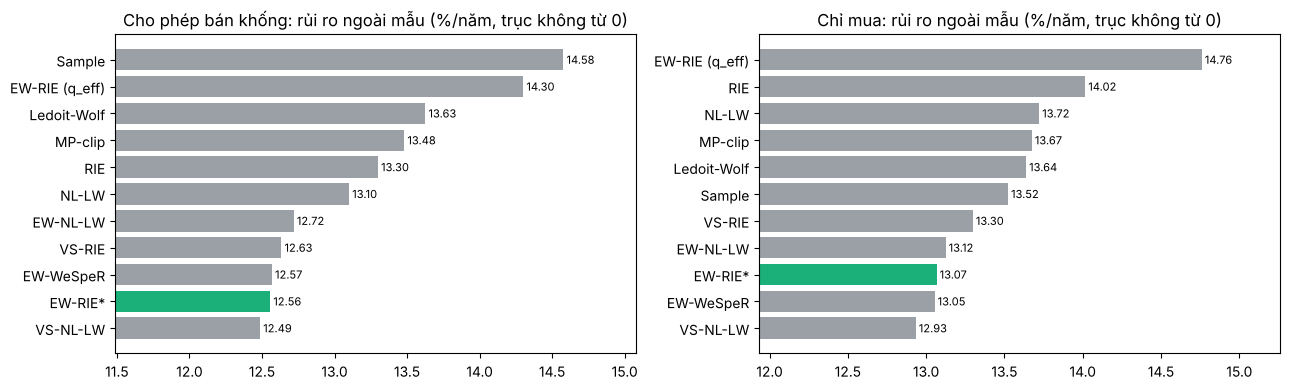

In [32]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for a, mode, ttl in [(ax[0], "short_ok", "Cho phép bán khống"), (ax[1], "long_only", "Chỉ mua")]:
    v = RESULTS[mode]["table"]["Vol %"].sort_values()
    a.barh(v.index, v.values, color=["#1baf7a" if k == "EW-RIE*" else "#9aa0a6" for k in v.index])
    a.set_xlim(v.min() - 1, v.max() + 0.5); a.set_title(f"{ttl}: rủi ro ngoài mẫu (%/năm, trục không từ 0)")
    for i, x in enumerate(v.values): a.text(x, i, f" {x:.2f}", va="center", fontsize=8)
plt.tight_layout(); plt.show()


In [33]:
cap("Hình", "Rủi ro ngoài mẫu (Vol %/năm) từng phương pháp, cấu hình chuẩn (hình của thầy; trục không bắt đầu từ 0).")

**Hình 4.** Rủi ro ngoài mẫu (Vol %/năm) từng phương pháp, cấu hình chuẩn (hình của thầy; trục không bắt đầu từ 0).

4

**Kết quả** (Vol ngoài mẫu %/năm; 118 kỳ, 12/2016–11/2026).

- Bán khống: VS-NL-LW 12,49 < EW-RIE\* 12,56 ≈ EW-WeSpeR 12,57 < EW-NL-LW 12,72 < NL-LW 13,10.
- Chỉ mua: VS-NL-LW 12,93 < EW-WeSpeR 13,05 ≈ EW-RIE\* 13,07 < EW-NL-LW 13,12 < NL-LW 13,72.
- EW-RIE\* thấp hơn EW-NL-LW, NL-LW, RIE và EW-RIE (q\_eff) có ý nghĩa (CI 95% < 0) ở cả hai chế độ; rõ nhất ở COVID 2020Q1 (chỉ mua: 16,11 so với NL-LW 20,67).

**Kết luận.** Trọng số mũ giảm rủi ro rõ so với cửa sổ phẳng (≈ 0,5–0,7 pp so với NL-LW), nhiều nhất khi có cú sốc. Các bộ EW chênh nhau < 0,2 pp nên cần kiểm định cặp (T3).

In [34]:
# Lưu kết quả (tải về hoặc chép vào Drive)
with pd.ExcelWriter(f"{WORKDIR}/results_N{CONFIG['N']}_T{CONFIG['WINDOW']}_h{CONFIG['HL_EW']}.xlsx") as xw:
    for mode, d in RESULTS.items():
        d["table"].round(4).to_excel(xw, sheet_name=f"{mode}_tong_hop")
        d["periods"].round(3).to_excel(xw, sheet_name=f"{mode}_giai_doan")
        d["ci"].round(4).to_excel(xw, sheet_name=f"{mode}_CI")
    pd.Series(CONFIG).to_frame("giá trị").to_excel(xw, sheet_name="CONFIG")
print("Đã lưu vào", WORKDIR)


Đã lưu vào ./rmt_work


In [19]:
# ---- Kết quả cấu hình chuẩn cho mọi phương pháp (đọc cache run_full; dùng ở §4.4, §5, §6) ----
STD = {m: run_full(CONFIG, lo) for m, lo in MODES.items()}
STD0 = STD["long_only"]; U0 = STD0["ulog"]; REB_DATES = [u["date"] for u in U0]; OUT0 = {m: STD[m]["out"] for m in MODES}
if "RESULTS" in globals():           # run_full tái tạo đúng §4 của thầy (EW-WeSpeR: khởi tạo ấm phụ thuộc thứ tự chạy nên chỉ báo sai khác)
    for m in MODES:
        bad = {k: float(np.abs(OUT0[m][k]["r"].values - o["r"].values).max()) for k, o in RESULTS[m]["out"].items()}
        assert all(v < 1e-12 for k, v in bad.items() if k != "EW-WeSpeR"), (m, bad)

### 4.3 Thời gian chạy

**Câu hỏi:** chi phí tính toán của từng bộ ước lượng khi N tăng?
Đo một lần ước lượng ma trận N × N (ms, chưa gồm giải GMV) trên 12 cửa sổ tái cân bằng HOSE thật, N ∈ {50, 100, 150}; mỗi cửa sổ gọi 3 lần lấy nhỏ nhất, báo trung vị qua 12 cửa sổ. EW-WeSpeR gọi thẳng, khởi tạo lại mỗi lần (không qua cache, không khởi tạo ấm); DCC không qua cache, chỉ 3 cửa sổ; EW-RIE\*: bỏ lần gọi đầu (mô phỏng phổ null một lần cho mỗi N).

In [36]:
# ---- 4.3 Thời gian chạy: một lần ước lượng ma trận N×N (ms, chưa gồm giải GMV) ----
N_GRID, K_WIN, REPS = (50, 100, 150), 12, 3

def timing_windows(N, K=K_WIN, cfg=CONFIG):
    # các cửa sổ ước lượng thật (đúng universe của run_backtest có lọc), K cửa sổ rải đều theo thời gian
    W = cfg["WINDOW"]; R = np.log(P).diff(); R = np.expm1(R.mask(R.abs() > cfg["MAX_ABS_RET"], 0.0)); Xs = []
    for s in range(W + 1, len(R) - 1, cfg["REB"]):
        win = R.iloc[s - W:s]; ok = (win.notna().mean() >= .95) & P.iloc[s - 1].notna()
        ok &= (win == 0).mean() <= cfg.get("ZERO_MAX", 1.0)
        if ok.sum() < N: continue
        tick = V.iloc[s - W:s].loc[:, ok].median().sort_values(ascending=False).index[:N]
        Xs.append(win[tick].fillna(0).values)
    return [Xs[i] for i in np.linspace(0, len(Xs) - 1, min(K, len(Xs))).astype(int)]

def _ms(f, X, reps):
    best = np.inf
    for _ in range(reps):
        t = time.perf_counter(); f(X); best = min(best, time.perf_counter() - t)
    return best * 1e3

def _wsp_cold_call(C, w):
    _WSP["warm"].clear(); return ew_wesper_corr(C, w)                       # gọi thẳng, không qua _WSP_CACHE, khởi tạo lại

E_T = build_full(CONFIG); TIME_EST = {k: E_T[k] for k in M12 + ["PCA-auto", "1/N"] if k != "EW-WeSpeR"}
TIME_EST["EW-WeSpeR"] = make_ew(_wsp_cold_call, CONFIG["HL_EW"]); TIME_EST["DCC-GARCH(1,1)"] = lambda X: est_dcc(X, use_cache=False)
_s0 = dict(_STATS); rows = []
for N_ in N_GRID:
    Xs = timing_windows(N_); _NULL_CACHE.clear(); E_T["EW-RIE*"](Xs[0])                  # lần đầu: mô phỏng phổ null (không tính)
    for k, f in TIME_EST.items():
        v = np.array([_ms(f, X, REPS) for X in (Xs[:3] if k.startswith("DCC") else Xs)])
        rows.append(dict(N=N_, method=k, ms=np.median(v), K=len(v)))
_STATS.update(_s0)                                                                     # không làm bẩn bộ đếm Newton
TIMING = pd.DataFrame(rows); TT = TIMING.pivot(index="method", columns="N", values="ms")
TT["× NL-LW (N = 100)"] = TT[100] / TT.loc["NL-LW", 100]; save(TT, "T43_timing")
try:
    from threadpoolctl import threadpool_info; BLAS = sorted({(d["internal_api"], d["num_threads"]) for d in threadpool_info()})
except Exception: BLAS = os.environ.get("OMP_NUM_THREADS", "?")
cpu = next((l.split(":")[1].strip() for l in open("/proc/cpuinfo") if l.startswith("model name")), platform.processor()) if os.path.exists("/proc/cpuinfo") else platform.processor()
TT12 = TT.reindex(M12 + ["DCC-GARCH(1,1)"]); TT12.columns = [f"N = {c}" if isinstance(c, (int, np.integer)) else c for c in TT12.columns]
cap("Bảng", f"Thời gian một lần ước lượng (ms, trung vị trên {K_WIN} cửa sổ HOSE thật; DCC: 3 cửa sổ), 12 phương pháp và DCC-GARCH. Máy: {cpu}, {os.cpu_count()} lõi; BLAS: {BLAS}.")
show(TT12, 1)
x_ = lambda k: TT.loc[k, 100]
md(f"**Kết quả.** Ở N = 100: NL-LW {f2(x_('NL-LW'), 1)} ms, EW-NL-LW {f2(x_('EW-NL-LW'), 1)} ms, RIE {f2(x_('RIE'), 1)} ms, **EW-RIE\\* {f2(x_('EW-RIE*'), 0)} ms**, "
   f"**EW-WeSpeR {f2(x_('EW-WeSpeR'), 0)} ms** ({f2(x_('EW-WeSpeR') / x_('EW-RIE*'), 1)} × EW-RIE\\*), VS-EW-RIE\\* {f2(x_('VS-EW-RIE*'), 0)} ms, DCC-GARCH {f2(x_('DCC-GARCH(1,1)') / 1e3, 1)} s.\n\n"
   f"**Kết luận.** EW-RIE\\* chậm hơn các bộ co cổ điển cỡ {f2(x_('EW-RIE*') / x_('NL-LW'), 0)} lần nhưng nhanh hơn EW-WeSpeR cỡ {f2(x_('EW-WeSpeR') / x_('EW-RIE*'), 0)} lần; cả hai đều không đáng kể so với một kỳ tái cân bằng.")

**Bảng 12.** Thời gian một lần ước lượng (ms, trung vị trên 12 cửa sổ HOSE thật; DCC: 3 cửa sổ), 12 phương pháp và DCC-GARCH. Máy: Intel(R) Xeon(R) Processor @ 2.10GHz, 4 lõi; BLAS: [('openblas', 1), ('openmp', 1)].

,N = 50,N = 100,N = 150,× NL-LW (N = 100)
method,,,,
Sample,"0,1","0,1","0,2","0,1"
Ledoit-Wolf,"1,1","2,7","6,8","2,0"
NL-LW,"0,5","1,4","3,3","1,0"
MP-clip,"0,5","1,2","3,2","0,9"
RIE,"0,4","1,4","2,7","1,0"
VS-NL-LW,"1,8","2,6","4,1","1,9"
VS-RIE,"2,5","2,4","3,9","1,8"
EW-NL-LW,"0,8","1,6","2,9","1,2"
EW-RIE (q_eff),"0,7","1,3","2,6","1,0"


**Kết quả.** Ở N = 100: NL-LW 1,4 ms, EW-NL-LW 1,6 ms, RIE 1,4 ms, **EW-RIE\* 155 ms**, **EW-WeSpeR 1211 ms** (7,8 × EW-RIE\*), VS-EW-RIE\* 139 ms, DCC-GARCH 1,9 s.

**Kết luận.** EW-RIE\* chậm hơn các bộ co cổ điển cỡ 113 lần nhưng nhanh hơn EW-WeSpeR cỡ 8 lần; cả hai đều không đáng kể so với một kỳ tái cân bằng.

### 4.4 Minh họa: phổ trị riêng trước và sau làm sạch

**Câu hỏi:** các bộ làm sạch khác nhau ở đâu trên phổ trị riêng?
Một mẫu giả lập (mô hình nhân tố của Test 2, biết ma trận thật) và cửa sổ tái cân bằng cuối của cấu hình chuẩn; N = 100, T = 250, h = 60. Trục x: trị riêng λ của tương quan mẫu có trọng số; trục y: trị riêng sau làm sạch theo cùng vector riêng, ξ = vᵀ C\_sạch v (oracle: vᵀ C\_thật v). Không chạy backtest.

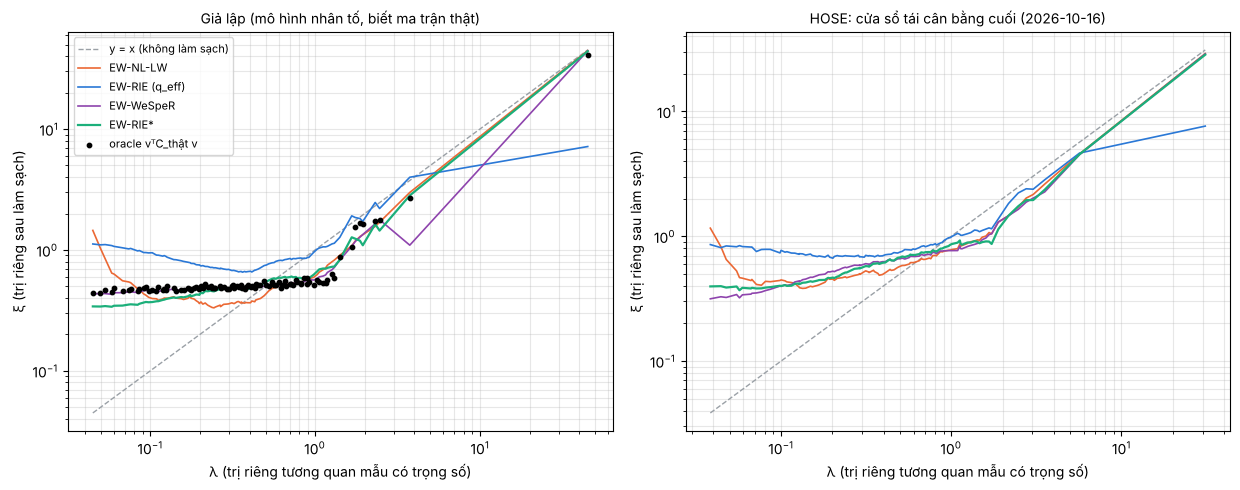

**Hình 5.** Phổ trị riêng trước (trục x) và sau làm sạch (trục y), log–log; N = 100, T = 250, h = 60. Trái: giả lập có oracle; phải: cửa sổ HOSE thật (không có oracle).

**Kết quả.** Ở giả lập, bám oracle nhất ở phần khối (90% trị riêng nhỏ, sai lệch log trung vị) là **EW-WeSpeR** (0,031; EW-RIE\* 0,124), ở trị riêng lớn nhất là **EW-RIE\*** (oracle 41,4; EW-RIE\* 44,0, EW-NL-LW 44,6, EW-RIE (q\_eff) 7,2). Trên HOSE, trị riêng lớn nhất (mode thị trường) λ = 31,1 được giữ là 28,5 (EW-RIE\*) và 29,1 (EW-NL-LW).

**Kết luận.** Các bộ khác nhau chủ yếu ở phần khối và ở mode thị trường; lệch oracle nhiều nhất ở phần khối là EW-RIE (q_eff).

In [37]:
# ---- 4.4 Phổ trị riêng trước và sau làm sạch: giả lập (có oracle) và cửa sổ HOSE cuối ----
def spec_clean(C, w):
    lam, Vv = np.linalg.eigh(C); proj = lambda M: np.einsum("ij,jk,ki->i", Vv.T, M, Vv)
    return lam, Vv, {"EW-NL-LW": proj(renorm(nl_lw_S(C, 1 / (w**2).sum()))), "EW-RIE (q_eff)": proj(rie_corr(C, len(C) * (w**2).sum())),
                     "EW-WeSpeR": proj(ew_wesper_corr(C, w)), "EW-RIE*": proj(ew_rie_corr(C, w))}
_rng44 = np.random.default_rng(44); w44 = ew_weights(CONFIG["WINDOW"], CONFIG["HL_EW"])
Ct44 = factor_corr(100, _rng44); X44 = _rng44.standard_normal((CONFIG["WINDOW"], 100)) @ np.linalg.cholesky(Ct44).T
lam_s, V_s, XI_s = spec_clean(ew_corr(X44, w44)[0], w44); XI_s["Oracle"] = np.einsum("ij,jk,ki->i", V_s.T, Ct44, V_s)
u_last = STD0["ulog"][-1]; s_ = POS[u_last["date"]]; X_h = R_BT.iloc[s_ - CONFIG["WINDOW"]:s_][u_last["tickers"]].fillna(0).values
lam_h, V_h, XI_h = spec_clean(ew_corr(X_h, w44)[0], w44)
SPC = {"lấy mẫu": "#9aa0a6", "EW-NL-LW": COL["EW-NL-LW"], "EW-RIE (q_eff)": "#2a78d6", "EW-WeSpeR": COL["EW-WeSpeR"], "EW-RIE*": COL["EW-RIE*"]}
fig, ax = plt.subplots(1, 2, figsize=(12.5, 5))
for a, lam_, XI, ttl in ((ax[0], lam_s, XI_s, "Giả lập (mô hình nhân tố, biết ma trận thật)"), (ax[1], lam_h, XI_h, f"HOSE: cửa sổ tái cân bằng cuối ({u_last['date'].date()})")):
    a.plot(lam_, lam_, color="#9aa0a6", lw=1, ls="--", label="y = x (không làm sạch)")
    for k in ("EW-NL-LW", "EW-RIE (q_eff)", "EW-WeSpeR", "EW-RIE*"): a.plot(lam_, XI[k], color=SPC[k], lw=1.6 if k == "EW-RIE*" else 1.2, label=k)
    if "Oracle" in XI: a.scatter(lam_, XI["Oracle"], s=10, color="black", zorder=3, label="oracle vᵀC_thật v")
    a.set_xscale("log"); a.set_yscale("log"); a.set_xlabel("λ (trị riêng tương quan mẫu có trọng số)"); a.set_ylabel("ξ (trị riêng sau làm sạch)"); a.set_title(ttl, fontsize=10); a.grid(alpha=.3, which="both")
ax[0].legend(fontsize=8); plt.tight_layout(); savefig(fig, "fig_5_pho_tri_rieng")
cap("Hình", "Phổ trị riêng trước (trục x) và sau làm sạch (trục y), log–log; N = 100, T = 250, h = 60. Trái: giả lập có oracle; phải: cửa sổ HOSE thật (không có oracle).")
bulk = lam_s < np.quantile(lam_s, .9)
err = {k: (np.median(np.abs(np.log(XI_s[k][bulk] / XI_s["Oracle"][bulk]))), abs(np.log(XI_s[k][-1] / XI_s["Oracle"][-1]))) for k in ("EW-NL-LW", "EW-RIE (q_eff)", "EW-WeSpeR", "EW-RIE*")}
bb, bt = min(err, key=lambda k: err[k][0]), min(err, key=lambda k: err[k][1])
md(f"**Kết quả.** Ở giả lập, bám oracle nhất ở phần khối (90% trị riêng nhỏ, sai lệch log trung vị) là **{e_(bb)}** ({f2(err[bb][0], 3)}; EW-RIE\\* {f2(err['EW-RIE*'][0], 3)}), ở trị riêng lớn nhất là **{e_(bt)}** "
   f"(oracle {f2(XI_s['Oracle'][-1], 1)}; EW-RIE\\* {f2(XI_s['EW-RIE*'][-1], 1)}, EW-NL-LW {f2(XI_s['EW-NL-LW'][-1], 1)}, EW-RIE (q\\_eff) {f2(XI_s['EW-RIE (q_eff)'][-1], 1)}). "
   f"Trên HOSE, trị riêng lớn nhất (mode thị trường) λ = {f2(lam_h[-1], 1)} được giữ là {f2(XI_h['EW-RIE*'][-1], 1)} (EW-RIE\\*) và {f2(XI_h['EW-NL-LW'][-1], 1)} (EW-NL-LW).\n\n"
   f"**Kết luận.** Các bộ khác nhau chủ yếu ở phần khối và ở mode thị trường; lệch oracle nhiều nhất ở phần khối là {e_(max(err, key=lambda k: err[k][0]))}.")

## 5. Độ nhạy (T6)

Đổi từng tham số một quanh cấu hình chuẩn (N = 100, T = 250, h = 60, HL\_VOL = 20, REB = 21, lọc đứng giá 20%). Mỗi N hay T có tập kỳ ngoài mẫu riêng nên **không so Vol giữa các cột N hay T**; số kỳ ghi dưới mỗi bảng.

### 5.1 Half-life (ô của thầy)

In [38]:
cap("Bảng", "Ô của thầy (`RUN_SENS = True`): Vol (%/năm) của EW-NL-LW và EW-RIE\\* theo half-life h, hai chế độ, và CI 95% bootstrap khối của Vol(EW-RIE\\*) − Vol(EW-NL-LW).")

**Bảng 13.** Ô của thầy (`RUN_SENS = True`): Vol (%/năm) của EW-NL-LW và EW-RIE\* theo half-life h, hai chế độ, và CI 95% bootstrap khối của Vol(EW-RIE\*) − Vol(EW-NL-LW).

13

In [39]:
RUN_SENS = True    # đặt True để chạy (~10–20 phút)
if RUN_SENS:
    rows = []
    for hl in (30, 60, 120):
        est = {"EW-NL-LW": make_ew(lambda C, w: renorm(nl_lw_S(C, 1 / (w**2).sum())), hl), "EW-RIE*": make_ew(ew_rie_corr, hl)}
        for lo in (False, True):
            o = run_backtest(P, V, est, CONFIG, lo)
            l, u = block_bootstrap_ci(o["EW-RIE*"]["r"].values, o["EW-NL-LW"]["r"].values)
            rows.append(dict(hl=hl, mode="long_only" if lo else "short_ok", vol_EWNLLW=o["EW-NL-LW"]["m"]["Vol %"],
                             vol_EWRIE=o["EW-RIE*"]["m"]["Vol %"], CI_lo=l, CI_hi=u))
    display(pd.DataFrame(rows).round(3))


,hl,mode,vol_EWNLLW,vol_EWRIE,CI_lo,CI_hi
0,30,short_ok,13.648,12.703,-1.284,-0.633
1,30,long_only,13.213,13.030,-0.268,-0.096
2,60,short_ok,12.719,12.557,-0.237,-0.094
3,60,long_only,13.124,13.066,-0.091,-0.025
4,120,short_ok,12.666,12.637,-0.057,-0.000
5,120,long_only,13.195,13.186,-0.024,0.008


**Kết quả** (Vol EW-RIE\* − EW-NL-LW, pp; CI 95% bootstrap khối).

- h = 30: chỉ mua **−0,18** [−0,27; −0,10]; bán khống **−0,95** [−1,28; −0,63].
- h = 60: chỉ mua −0,06 [−0,09; −0,03]; bán khống −0,16 [−0,24; −0,09].
- h = 120: chỉ mua −0,01 [−0,02; +0,01] (không ý nghĩa); bán khống −0,03 [−0,06; 0,00] (biên).
- Vol EW-RIE\* thấp nhất ở h = 30 (chỉ mua 13,03) và h = 60 (bán khống 12,56).

**Kết luận.** Half-life ngắn (30–60) tốt hơn; lợi thế so với EW-NL-LW lớn nhất ở h = 30 và biến mất ở h = 120. Lưu ý h = 30 có q\_eff = 1,16 (N > T\_eff).

**Lưới N × h** (N ∈ {50, 100, 150} × h ∈ {30, 60, 120}, mọi tổ hợp; mỗi N có tập kỳ ngoài mẫu riêng: so trong cùng hàng N).

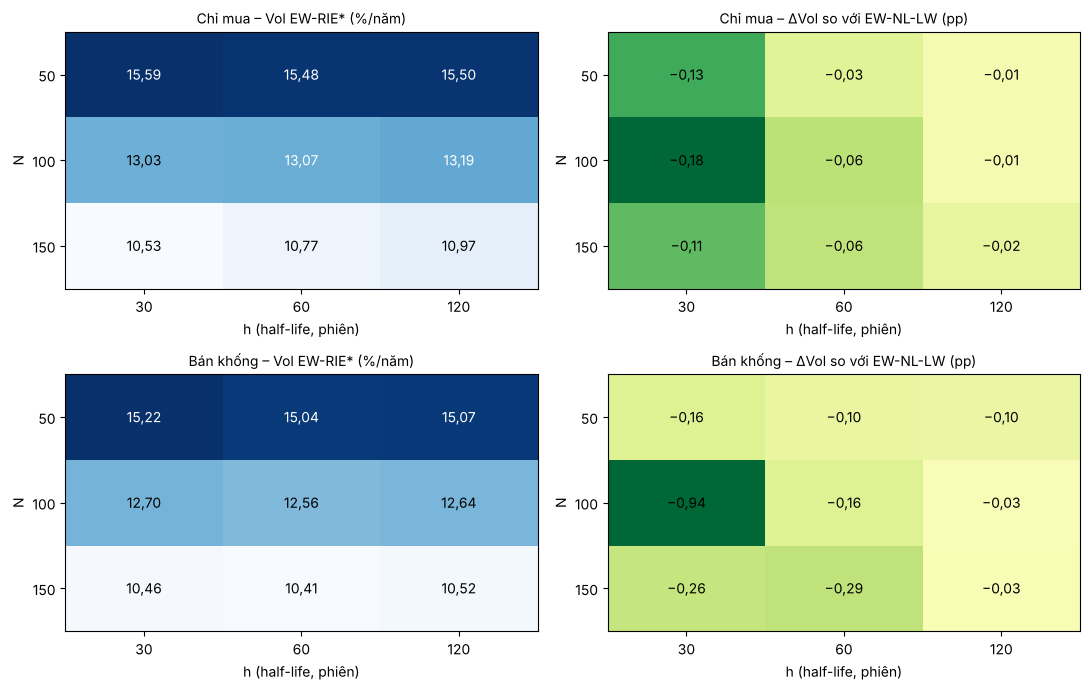

**Hình 6.** Lưới N × h (heatmap của v3): Vol của EW-RIE\* (trái) và ΔVol = Vol(EW-RIE\*) − Vol(EW-NL-LW) (phải); hàng trên: chỉ mua, hàng dưới: bán khống. Chỉ so trong cùng hàng N.

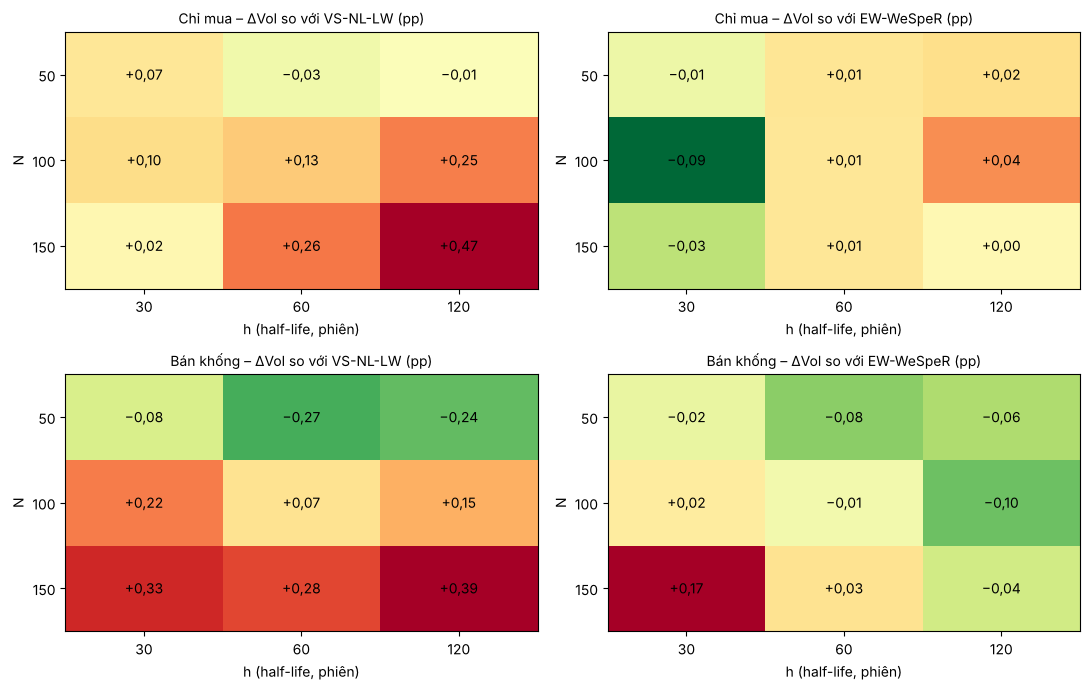

**Hình 7.** Lưới N × h: ΔVol của EW-RIE\* so với VS-NL-LW (trái) và EW-WeSpeR (phải), pp/năm; xanh: EW-RIE\* thấp hơn; \* = p Holm < 0,05 (12 cặp trong từng ô, mô tả).

**Kết quả.** Chỉ mua: so với EW-NL-LW, EW-RIE\* thấp hơn ở 9/9 ô (3 có ý nghĩa); so với VS-NL-LW thấp hơn ở 2/9 ô (có ý nghĩa: thấp hơn 0, cao hơn 0); so với EW-WeSpeR thấp hơn ở 3/9 ô (có ý nghĩa: thấp hơn 0, cao hơn 0). Bán khống: so với EW-NL-LW, EW-RIE\* thấp hơn ở 9/9 ô (6 có ý nghĩa); so với VS-NL-LW thấp hơn ở 3/9 ô (có ý nghĩa: thấp hơn 0, cao hơn 0); so với EW-WeSpeR thấp hơn ở 6/9 ô (có ý nghĩa: thấp hơn 0, cao hơn 0).

**Kết luận.** EW-RIE\* thấp hơn EW-NL-LW ở 18/18 ô (cấu hình × chế độ); so với VS-NL-LW: thấp hơn có ý nghĩa 0 ô, cao hơn có ý nghĩa 0 ô; so với EW-WeSpeR: thấp hơn có ý nghĩa 0 ô, cao hơn có ý nghĩa 0 ô (mô tả).

In [40]:
# ---- §5: số liệu dùng chung (đọc cache) + Hình 6 (heatmap N × h của v3) và Hình 7 (ΔVol của EW-RIE* so với VS-NL-LW và EW-WeSpeR) ----
NS, HS, HVS = (50, 100, 150), (30, 60, 120), (10, 20, 40)
GR = {(n_, h_, m): run_full(dict(CONFIG, N=n_, HL_EW=h_), lo, M12) for n_ in NS for h_ in HS for m, lo in MODES.items()}
HV = {(hv, m): run_full(dict(CONFIG, HL_VOL=hv), lo, M12) for hv in HVS for m, lo in MODES.items()}
_PT = {}
def ptab(key, d):           # pair_table có ghi nhớ (cùng cấu hình dùng ở nhiều chỗ chỉ tính một lần)
    if key not in _PT: _PT[key] = pair_table(d["out"], [p for p in PAIRS12 if p[1] in d["out"] and p[2] in d["out"]], reb_dates=[u["date"] for u in d["ulog"]])
    return _PT[key]
rows = []
for (n_, h_, m), d in GR.items():
    t = ptab(("nh", n_, h_, m), d); g = lambda c: t.xs(c, level=1)
    rows.append(dict(mode=m, N=n_, h=h_, kỳ=len(d["ulog"]), **{"Vol EW-RIE*": d["out"]["EW-RIE*"]["m"]["Vol %"]},
                     **{f"ΔVol vs {b}": g(f"EW-RIE* − {b}")["ΔVol (pp)"].iloc[0] for b in ("EW-NL-LW", "VS-NL-LW", "EW-WeSpeR")},
                     **{f"p Holm vs {b}": g(f"EW-RIE* − {b}")["p Holm"].iloc[0] for b in ("EW-NL-LW", "VS-NL-LW", "EW-WeSpeR")}))
T6 = pd.DataFrame(rows); save(T6, "T6_N_h_grid")
def heat2x2(cols, ttls, fname, star=None):
    fig, ax = plt.subplots(2, 2, figsize=(11, 7))
    for i, m in enumerate(MODES):
        t = T6[T6["mode"] == m]
        for j, (col, ttl) in enumerate(zip(cols, ttls)):
            M = t.pivot(index="N", columns="h", values=col); a = ax[i, j]; dif = col.startswith("ΔVol"); v = np.abs(M.values).max()
            a.imshow(M.values, cmap="RdYlGn_r" if dif else "Blues", aspect="auto", **({"vmin": -v, "vmax": v} if dif else {}))
            a.set_xticks(range(3), M.columns); a.set_yticks(range(3), M.index); a.set_xlabel("h (half-life, phiên)"); a.set_ylabel("N"); mid = (M.values.min() + M.values.max()) / 2
            S = t.pivot(index="N", columns="h", values=col.replace("ΔVol", "p Holm")) if (dif and star) else None
            for (y, x), val in np.ndenumerate(M.values):
                a.text(x, y, (dv(val) if dif else f2(val)) + ("*" if S is not None and S.values[y, x] < .05 else ""), ha="center", va="center", fontsize=10,
                       color="white" if (not dif and val > mid) else "black")
            a.set_title(f"{VN[m]} – {ttl}", fontsize=10)
    plt.tight_layout(); savefig(fig, fname)
heat2x2(["Vol EW-RIE*", "ΔVol vs EW-NL-LW"], ["Vol EW-RIE* (%/năm)", "ΔVol so với EW-NL-LW (pp)"], "fig_6_nh_v3")
cap("Hình", "Lưới N × h (heatmap của v3): Vol của EW-RIE\\* (trái) và ΔVol = Vol(EW-RIE\\*) − Vol(EW-NL-LW) (phải); hàng trên: chỉ mua, hàng dưới: bán khống. Chỉ so trong cùng hàng N.")
heat2x2(["ΔVol vs VS-NL-LW", "ΔVol vs EW-WeSpeR"], ["ΔVol so với VS-NL-LW (pp)", "ΔVol so với EW-WeSpeR (pp)"], "fig_7_nh_vs", star=True)
cap("Hình", "Lưới N × h: ΔVol của EW-RIE\\* so với VS-NL-LW (trái) và EW-WeSpeR (phải), pp/năm; xanh: EW-RIE\\* thấp hơn; \\* = p Holm < 0,05 (12 cặp trong từng ô, mô tả).")
def _concl_nh():
    neg = int((T6["ΔVol vs EW-NL-LW"] < 0).sum()); sv = lambda b, sgn: int(((np.sign(T6[f"ΔVol vs {b}"]) == sgn) & (T6[f"p Holm vs {b}"] < .05)).sum())
    return (f"EW-RIE\\* thấp hơn EW-NL-LW ở {neg}/18 ô (cấu hình × chế độ); so với VS-NL-LW: thấp hơn có ý nghĩa {sv('VS-NL-LW', -1)} ô, cao hơn có ý nghĩa {sv('VS-NL-LW', 1)} ô; "
            f"so với EW-WeSpeR: thấp hơn có ý nghĩa {sv('EW-WeSpeR', -1)} ô, cao hơn có ý nghĩa {sv('EW-WeSpeR', 1)} ô (mô tả).")
_n = lambda m, c, cond: int(cond(T6[T6["mode"] == m]).sum())
md("**Kết quả.** " + " ".join(f"{VN[m]}: so với EW-NL-LW, EW-RIE\\* thấp hơn ở {_n(m, 0, lambda t: t['ΔVol vs EW-NL-LW'] < 0)}/9 ô ({_n(m, 0, lambda t: (t['ΔVol vs EW-NL-LW'] < 0) & (t['p Holm vs EW-NL-LW'] < .05))} có ý nghĩa); "
   f"so với VS-NL-LW thấp hơn ở {_n(m, 0, lambda t: t['ΔVol vs VS-NL-LW'] < 0)}/9 ô (có ý nghĩa: thấp hơn {_n(m, 0, lambda t: (t['ΔVol vs VS-NL-LW'] < 0) & (t['p Holm vs VS-NL-LW'] < .05))}, cao hơn {_n(m, 0, lambda t: (t['ΔVol vs VS-NL-LW'] > 0) & (t['p Holm vs VS-NL-LW'] < .05))}); "
   f"so với EW-WeSpeR thấp hơn ở {_n(m, 0, lambda t: t['ΔVol vs EW-WeSpeR'] < 0)}/9 ô (có ý nghĩa: thấp hơn {_n(m, 0, lambda t: (t['ΔVol vs EW-WeSpeR'] < 0) & (t['p Holm vs EW-WeSpeR'] < .05))}, cao hơn {_n(m, 0, lambda t: (t['ΔVol vs EW-WeSpeR'] > 0) & (t['p Holm vs EW-WeSpeR'] < .05))})." for m in MODES)
   + "\n\n**Kết luận.** " + _concl_nh())

### 5.2 Bảng A theo N, h, HL\_VOL

**Câu hỏi:** thứ hạng rủi ro của 12 phương pháp có đổi khi đổi N, h hay HL\_VOL? HL\_VOL chỉ ảnh hưởng ba bộ VS nên các hàng khác để trống ở các cột HL\_VOL.

In [41]:
# ---- 5.2 Bảng A: 12 phương pháp × (N, h, HL_VOL), mỗi chế độ một bảng ----
VSSET = ["VS-NL-LW", "VS-RIE", "VS-EW-RIE*"]
SENS = {**{f"N = {n_}": ("N", n_) for n_ in NS}, **{f"h = {h_}": ("h", h_) for h_ in HS}, **{f"HL_VOL = {hv}": ("hv", hv) for hv in HVS}}
def sens_d(lab, m):
    k, v = SENS[lab]
    return GR[(v, 60, m)] if k == "N" else GR[(100, v, m)] if k == "h" else HV[(v, m)]
def sens_out(lab, m):       # cột HL_VOL: chỉ giữ ba bộ VS và các bộ chúng ghép cặp (để heatmap cụm C, D, E)
    d = sens_d(lab, m); return d["out"] if SENS[lab][0] != "hv" else {k: o for k, o in d["out"].items() if k in VSSET + ["NL-LW", "RIE", "EW-RIE*"]}
TA = {}
for m in ("short_ok", "long_only"):
    TA[m] = pd.DataFrame({lab: vols(sens_d(lab, m)["out"], M12).where(lambda s: s.index.isin(VSSET) | (SENS[lab][0] != "hv")) for lab in SENS}).reindex(M12)
    save(TA[m], f"T5_tableA_{m}")
    kys = ", ".join(f"{lab}: {len(sens_d(lab, m)['ulog'])}" for lab in SENS if SENS[lab][0] == "N")
    cap("Bảng", f"{VN[m]}: Vol (%/năm, gộp) của 12 phương pháp khi đổi một tham số (các tham số khác chuẩn); in đậm: thấp nhất mỗi cột. Số kỳ ngoài mẫu — {kys}; cột h và HL\\_VOL: 118 kỳ. Không so giữa các cột N.")
    display(table_a(TA[m]))
best = {m: TA[m].idxmin() for m in MODES}; cnt = {m: best[m].value_counts() for m in MODES}
md("**Kết quả.** Bộ có Vol thấp nhất theo từng cột — " + "; ".join(f"{VN[m]}: " + ", ".join(f"{e_(k)} {v}/9" for k, v in cnt[m].items()) for m in MODES)
   + f". Hạng của EW-RIE\\* trong 12 bộ (các cột N, h): " + "; ".join(f"{VN[m]} " + ", ".join(str(int(TA[m][c].rank()['EW-RIE*'])) for c in TA[m].columns if not c.startswith("HL")) for m in MODES) + ".\n\n"
   f"**Kết luận.** Bộ thấp nhất mỗi cột {'luôn' if all(k.startswith(('EW-', 'VS-')) for m in MODES for k in best[m]) else 'không phải lúc nào cũng'} là bộ có trọng số mũ hoặc VS, và đổi theo tham số; chênh lệch giữa các bộ đầu bảng cần đọc ở kiểm định cặp (5.3).")

**Bảng 14.** Bán khống: Vol (%/năm, gộp) của 12 phương pháp khi đổi một tham số (các tham số khác chuẩn); in đậm: thấp nhất mỗi cột. Số kỳ ngoài mẫu — N = 50: 129, N = 100: 118, N = 150: 110; cột h và HL\_VOL: 118 kỳ. Không so giữa các cột N.

,N = 50,N = 100,N = 150,h = 30,h = 60,h = 120,HL_VOL = 10,HL_VOL = 20,HL_VOL = 40
Sample,"16,09","14,58","15,06","14,58","14,58","14,58",,,
Ledoit-Wolf,"15,70","13,63","12,28","13,63","13,63","13,63",,,
NL-LW,"15,46","13,10","11,46","13,10","13,10","13,10",,,
MP-clip,"15,82","13,48","11,15","13,48","13,48","13,48",,,
RIE,"15,26","13,30","12,71","13,30","13,30","13,30",,,
VS-NL-LW,"15,30","12,49","10,13","12,49","12,49","12,49","12,65","12,49","12,62"
VS-RIE,"15,06","12,63","11,55","12,63","12,63","12,63","12,72","12,63","13,02"
EW-NL-LW,"15,14","12,72","10,70","13,65","12,72","12,67",,,
EW-RIE (q_eff),"15,03","14,30","14,96","16,02","14,30","13,38",,,
EW-WeSpeR,"15,12","12,57","10,38","12,68","12,57","12,73",,,


**Bảng 15.** Chỉ mua: Vol (%/năm, gộp) của 12 phương pháp khi đổi một tham số (các tham số khác chuẩn); in đậm: thấp nhất mỗi cột. Số kỳ ngoài mẫu — N = 50: 129, N = 100: 118, N = 150: 110; cột h và HL\_VOL: 118 kỳ. Không so giữa các cột N.

,N = 50,N = 100,N = 150,h = 30,h = 60,h = 120,HL_VOL = 10,HL_VOL = 20,HL_VOL = 40
Sample,"15,80","13,52","11,46","13,52","13,52","13,52",,,
Ledoit-Wolf,"15,83","13,64","11,64","13,64","13,64","13,64",,,
NL-LW,"15,83","13,72","11,95","13,72","13,72","13,72",,,
MP-clip,"15,91","13,67","11,37","13,67","13,67","13,67",,,
RIE,"15,70","14,02","13,33","14,02","14,02","14,02",,,
VS-NL-LW,"15,51","12,93","10,51","12,93","12,93","12,93","13,16","12,93","12,96"
VS-RIE,"15,42","13,30","12,11","13,30","13,30","13,30","13,24","13,30","13,73"
EW-NL-LW,"15,51","13,12","10,82","13,21","13,12","13,19",,,
EW-RIE (q_eff),"15,53","14,76","15,13","16,22","14,76","14,04",,,
EW-WeSpeR,"15,47","13,05","10,76","13,12","13,05","13,14",,,


**Kết quả.** Bộ có Vol thấp nhất theo từng cột — Chỉ mua: VS-NL-LW 6/9, VS-EW-RIE\* 2/9, VS-RIE 1/9; Bán khống: VS-EW-RIE\* 7/9, EW-RIE (q_eff) 1/9, VS-NL-LW 1/9. Hạng của EW-RIE\* trong 12 bộ (các cột N, h): Chỉ mua 3, 4, 4, 2, 4, 4; Bán khống 2, 3, 4, 5, 3, 4.

**Kết luận.** Bộ thấp nhất mỗi cột luôn là bộ có trọng số mũ hoặc VS, và đổi theo tham số; chênh lệch giữa các bộ đầu bảng cần đọc ở kiểm định cặp (5.3).

### 5.3 Heatmap 12 cặp theo N, h, HL\_VOL

**Câu hỏi:** chênh lệch trong từng cặp định trước có giữ dấu khi đổi tham số? Ở các cột HL\_VOL chỉ có các cặp chứa bộ VS (cụm C, D, E); cụm E ở đó là EW-RIE\* (h = 60) so với VS-NL-LW ở từng HL\_VOL.

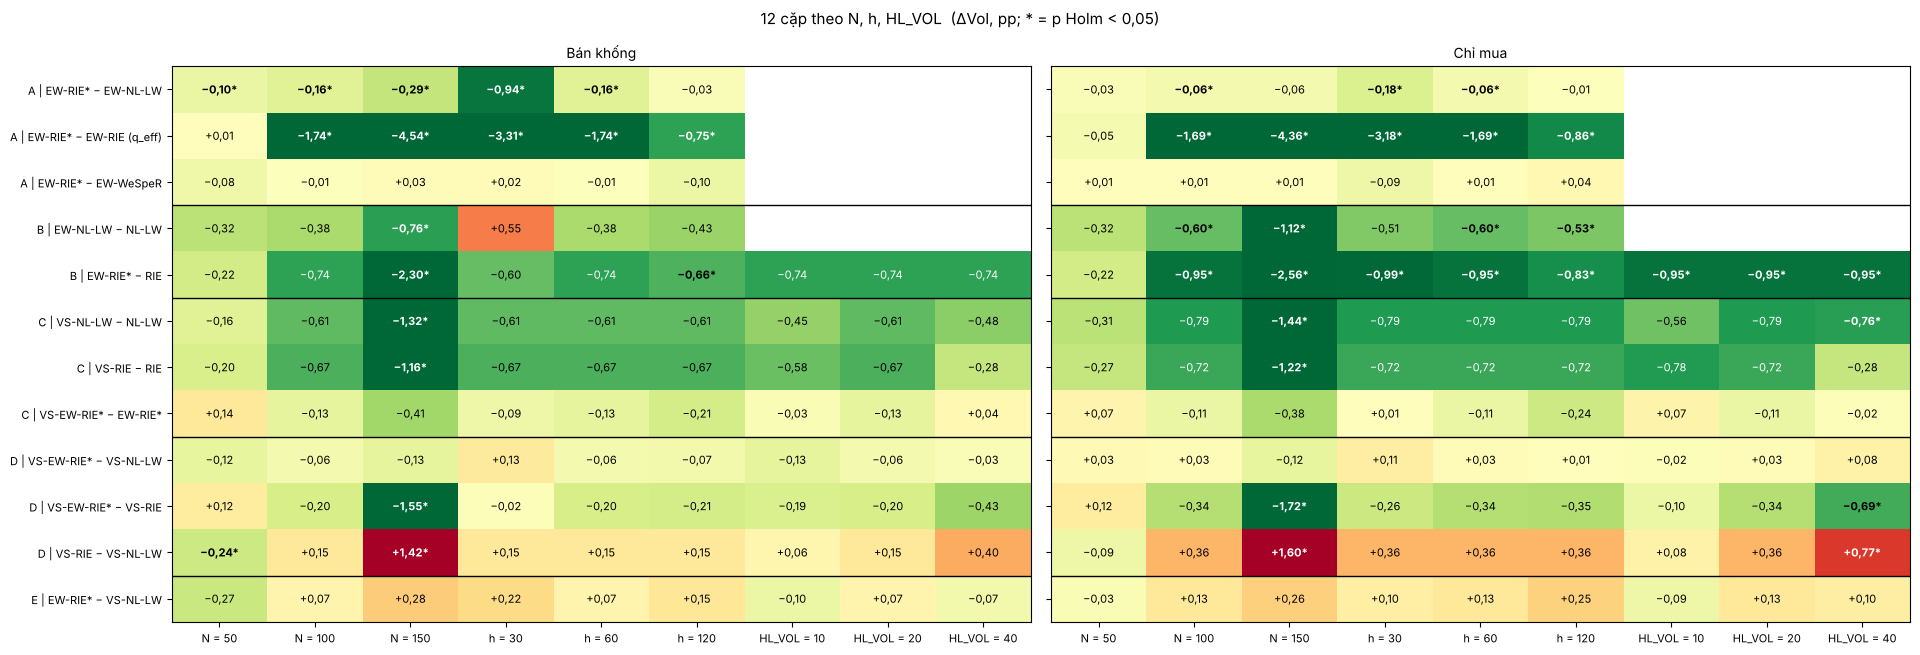

**Hình 8.** ΔVol (pp/năm) của 12 cặp định trước theo N, h, HL\_VOL; xanh: bộ đứng trước rủi ro thấp hơn; màu cắt ở ±1 pp. \* = p Holm < 0,05 trên các cặp trong cùng cột (mô tả, không hiệu chỉnh xuyên cột). Số liệu: `T5_pairs_sens.csv`.

**Kết quả.** Số ô (cấu hình × chế độ) có ΔVol < 0 / âm có ý nghĩa / dương có ý nghĩa: EW-RIE\* − EW-NL-LW: 12/12 / 8 / 0; EW-RIE\* − VS-NL-LW: 5/18 / 0 / 0; VS-NL-LW − NL-LW: 18/18 / 3 / 0; VS-EW-RIE\* − VS-NL-LW: 10/18 / 0 / 0.

**Kết luận.** EW-RIE\* thấp hơn EW-NL-LW có ý nghĩa ở 8/12 ô (cao hơn có ý nghĩa 0); cặp thầy hỏi (EW-RIE\* − VS-NL-LW) không có ý nghĩa ở ô nào trong 18 ô (mô tả).

In [42]:
# ---- 5.3 Heatmap cặp: 12 cặp × 9 cấu hình, hai chế độ (dấu * = p Holm < 0,05 trong từng cột, mô tả) ----
G53 = {}
for m in MODES:
    D, Pm = {}, {}
    for lab in SENS:
        k, v = SENS[lab]; key = ("nh", v, 60, m) if k == "N" else ("nh", 100, v, m) if k == "h" else ("hv", v, m)
        d = sens_d(lab, m); out = sens_out(lab, m)
        t = ptab(key, dict(out=out, ulog=d["ulog"])) if k != "hv" or v != 20 else ptab(("hv20", m), dict(out=out, ulog=d["ulog"]))
        idx = pd.MultiIndex.from_tuples([(g, f"{a} − {b}") for g, a, b in PAIRS12], names=["Cụm", "Cặp"])
        D[lab], Pm[lab] = t["ΔVol (pp)"].reindex(idx), t["p Holm"].reindex(idx)
    G53[VN[m]] = (pd.DataFrame(D), pd.DataFrame(Pm))
G53 = {k: G53[k] for k in ("Bán khống", "Chỉ mua")}; save_grid(G53, "T5_pairs_sens")
pair_heatmap(G53, "12 cặp theo N, h, HL_VOL", fname="fig_8_pairs_sens")
cap("Hình", "ΔVol (pp/năm) của 12 cặp định trước theo N, h, HL\\_VOL; xanh: bộ đứng trước rủi ro thấp hơn; màu cắt ở ±1 pp. \\* = p Holm < 0,05 trên các cặp trong cùng cột (mô tả, không hiệu chỉnh xuyên cột). Số liệu: `T5_pairs_sens.csv`.")
md("**Kết quả.** Số ô (cấu hình × chế độ) có ΔVol < 0 / âm có ý nghĩa / dương có ý nghĩa: " + "; ".join(
   f"{e_(p)}: {c[1]}/{c[0]} / {c[2]} / {c[3]}" for p in ("EW-RIE* − EW-NL-LW", "EW-RIE* − VS-NL-LW", "VS-NL-LW − NL-LW", "VS-EW-RIE* − VS-NL-LW") for c in [grid_count(G53, p)]) + ".\n\n"
   f"**Kết luận.** {concl_grid(G53)}")

### 5.3b h × HL\_VOL cho VS-EW-RIE\*

**Câu hỏi:** VS-EW-RIE\* có hơn VS-NL-LW ở tổ hợp half-life h (tương quan) × HL\_VOL (biến động) nào không?

In [43]:
# ---- 5.3b Bảng 16: VS-EW-RIE* ở h × HL_VOL (N = 100); ΔVol so với VS-NL-LW cùng HL_VOL; * = p Holm < 0,05 trên 9 ô của mỗi chế độ ----
HHV = {}
for m, lo in MODES.items():
    rows = []
    for h_ in HS:
        for hv in HVS:
            d = run_full(dict(CONFIG, HL_EW=h_, HL_VOL=hv), lo, ["VS-EW-RIE*", "VS-NL-LW"]); a_, b_ = d["out"]["VS-EW-RIE*"]["r"].values, d["out"]["VS-NL-LW"]["r"].values
            rows.append(dict(h=h_, HL_VOL=hv, vol=d["out"]["VS-EW-RIE*"]["m"]["Vol %"], dvol=(a_.std() - b_.std()) * np.sqrt(252) * 100, p=lw_var_test(a_, b_)[3]))
    t = pd.DataFrame(rows); t["p_holm"] = holm(t.p.values); HHV[m] = t
save(pd.concat(HHV, names=["mode"]).reset_index(), "T5_hhv_vs_ew_rie")
T16 = pd.concat({VN[m]: HHV[m].assign(o=[f"{f2(v)} ({dv(d_)}{'*' if p < .05 else ''})" for v, d_, p in zip(HHV[m].vol, HHV[m].dvol, HHV[m].p_holm)])
                 .pivot(index="h", columns="HL_VOL", values="o") for m in ("short_ok", "long_only")}, names=["Chế độ", "h"])
T16.columns = [f"HL_VOL = {c}" for c in T16.columns]
cap("Bảng", "VS-EW-RIE\\* theo half-life h × HL\\_VOL (N = 100): Vol %/năm (ΔVol so với VS-NL-LW cùng HL\\_VOL, pp; \\* = p Holm < 0,05 trên 9 ô của mỗi chế độ, kiểm định phương sai bootstrap khối).")
display(T16)
bx = {m: HHV[m].loc[HHV[m].vol.idxmin()] for m in MODES}; ns_ = {m: int((HHV[m].p_holm < .05).sum()) for m in MODES}
md("**Kết quả.** " + "; ".join(f"{VN[m]}: Vol thấp nhất ở h = {int(bx[m].h)}, HL\\_VOL = {int(bx[m].HL_VOL)} ({f2(bx[m].vol)}%, ΔVol so với VS-NL-LW {dv(bx[m].dvol)}); ΔVol < 0 ở {int((HHV[m].dvol < 0).sum())}/9 ô, có ý nghĩa {ns_[m]}/9" for m in MODES) + ".\n\n"
   f"**Kết luận.** VS-EW-RIE\\* {'không hơn VS-NL-LW có ý nghĩa ở tổ hợp nào' if sum(int(((HHV[m].dvol < 0) & (HHV[m].p_holm < .05)).sum()) for m in MODES) == 0 else 'hơn VS-NL-LW có ý nghĩa ở một vài tổ hợp'}; chọn h, HL\\_VOL theo kết quả ngoài mẫu sẽ thiên lệch (xem 5.5).")

**Bảng 16.** VS-EW-RIE\* theo half-life h × HL\_VOL (N = 100): Vol %/năm (ΔVol so với VS-NL-LW cùng HL\_VOL, pp; \* = p Holm < 0,05 trên 9 ô của mỗi chế độ, kiểm định phương sai bootstrap khối).

HL_VOL = 10    HL_VOL = 20    HL_VOL = 40
Chế độ    h                                               
Bán khống 30   12,56 (−0,09)  12,61 (+0,13)  12,92 (+0,30)
          60   12,52 (−0,13)  12,43 (−0,06)  12,60 (−0,03)
          120  12,56 (−0,09)  12,42 (−0,07)  12,56 (−0,06)
Chỉ mua   30   13,19 (+0,03)  13,04 (+0,11)  13,24 (+0,27)
          60   13,14 (−0,02)  12,96 (+0,03)  13,05 (+0,08)
          120  13,14 (−0,02)  12,94 (+0,01)  12,97 (+0,01)

**Kết quả.** Chỉ mua: Vol thấp nhất ở h = 120, HL\_VOL = 20 (12,94%, ΔVol so với VS-NL-LW +0,01); ΔVol < 0 ở 2/9 ô, có ý nghĩa 0/9; Bán khống: Vol thấp nhất ở h = 120, HL\_VOL = 20 (12,42%, ΔVol so với VS-NL-LW −0,07); ΔVol < 0 ở 7/9 ô, có ý nghĩa 0/9.

**Kết luận.** VS-EW-RIE\* không hơn VS-NL-LW có ý nghĩa ở tổ hợp nào; chọn h, HL\_VOL theo kết quả ngoài mẫu sẽ thiên lệch (xem 5.5).

### 5.4 Cửa sổ T

**Câu hỏi:** đổi độ dài cửa sổ ước lượng T thì thứ hạng và các cặp có đổi? `make_vs` của thầy bỏ HL\_VOL phiên đầu cửa sổ để khởi động EWMA (`Z = Z[hl_vol:]`), nên với T = 120 các bộ VS chỉ còn 100 phiên cho 100 mã. Nhóm thêm bản VS **"đủ T"**: bộ ước lượng nhận thêm HL\_VOL phiên ngay **trước** cửa sổ (chỉ dữ liệu quá khứ) để khởi động EWMA rồi dùng đủ T phiên (§3.2, không sửa ô của thầy); mã nào không có đủ HL\_VOL phiên trước cửa sổ (chưa niêm yết hoặc toàn 0) thì khởi động trên đầu cửa sổ như `make_vs`. Heatmap dùng bản "đủ T" cho các cặp có VS.

**Bảng 17.** Vol (%/năm, gộp) theo cửa sổ T, 12 phương pháp và ba bộ VS "đủ T"; in đậm: thấp nhất mỗi cột. Số kỳ ngoài mẫu — T = 120: 120 kỳ từ 2016-10-05, T = 250: 118 kỳ từ 2016-12-08, T = 500: 111 kỳ từ 2017-07-12. Không so giữa các cột T.

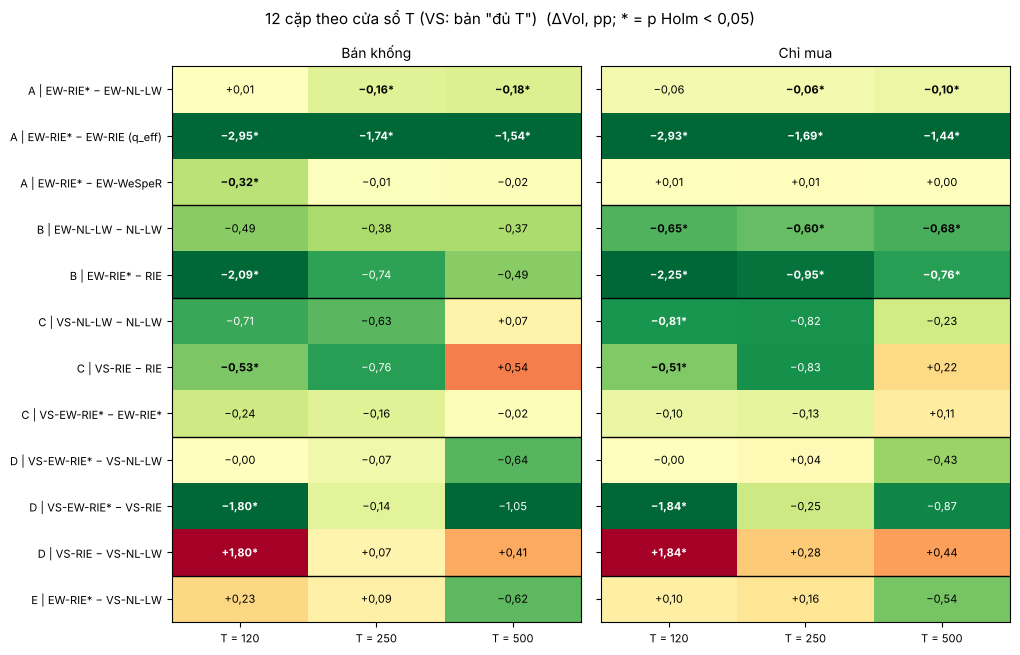

**Hình 9.** ΔVol (pp/năm) của 12 cặp theo cửa sổ T; các cặp có VS dùng bản "đủ T". \* = p Holm < 0,05 trong từng cột (mô tả). Số liệu: `T5_pairs_window.csv`.

**Kết quả.** Ở T = 120, VS-NL-LW của thầy có Vol 18,09% / 17,85% (bán khống / chỉ mua) và VS-EW-RIE\* 78,62% / 13,42%, trong khi bản "đủ T" chỉ 13,07% / 13,33% và 13,06% / 13,33%: do `make_vs` bỏ HL\_VOL = 20 phiên nên chỉ còn 100 phiên cho 100 mã, ma trận gần suy biến. Ở T = 250, bản "đủ T" lệch bản của thầy: VS-NL-LW −0,02 / −0,03 pp, VS-EW-RIE\* −0,03 / −0,02 pp. Mã không có đủ 20 phiên trước cửa sổ (chưa niêm yết, hoặc toàn 0) được khởi động EWMA trên đầu cửa sổ như `make_vs`: T = 120: 315 lượt (kỳ × mã × 3 bộ) trên 360 lần ước lượng, T = 250: 462 lượt (kỳ × mã × 3 bộ) trên 354 lần ước lượng, T = 500: 630 lượt (kỳ × mã × 3 bộ) trên 333 lần ước lượng. Cặp EW-RIE\* − VS-NL-LW (đủ T): T = 120: +0,23 / +0,10; T = 250: +0,09 / +0,16; T = 500: −0,62 / −0,54 pp.

**Kết luận.** Kết quả "EW-RIE\* hơn hẳn VS-NL-LW ở T = 120" của v5 là do lỗi khởi động EWMA của bộ VS, không dùng; với bản "đủ T": EW-RIE\* thấp hơn EW-NL-LW có ý nghĩa ở 4/6 ô (cao hơn có ý nghĩa 0); cặp thầy hỏi (EW-RIE\* − VS-NL-LW) không có ý nghĩa ở ô nào trong 6 ô (mô tả).

In [44]:
# ---- 5.4 Cửa sổ T ∈ {120, 250, 500}: Bảng A (12 + 3 bộ VS "đủ T") và heatmap cặp (VS dùng bản "đủ T") ----
WINS = (120, 250, 500); FT = ["VS-NL-LW (đủ T)", "VS-RIE (đủ T)", "VS-EW-RIE* (đủ T)"]
WR = {(t_, m): run_full(dict(CONFIG, WINDOW=t_), lo, M12 + FT) for t_ in WINS for m, lo in MODES.items()}      # một lần gọi ⇒ assert cùng universe, cùng ngày
for (t_, m), d in WR.items():                                                       # bộ không phải VS: trùng hệt lần chạy thường ở cùng T
    ref = run_full(dict(CONFIG, WINDOW=t_), MODES[m], [k for k in M12 if not k.startswith("VS")])
    assert all(np.array_equal(ref["out"][k]["r"].values, d["out"][k]["r"].values) for k in ref["out"])
T17 = pd.concat({(VN[m], f"T = {t_}"): vols(WR[(t_, m)]["out"], M12 + FT) for m in ("short_ok", "long_only") for t_ in WINS}, axis=1)
save(T17, "T5_window_tableA")
kys = ", ".join(f"T = {t_}: {len(WR[(t_, 'long_only')]['ulog'])} kỳ từ {WR[(t_, 'long_only')]['ulog'][0]['date'].date()}" for t_ in WINS)
cap("Bảng", f"Vol (%/năm, gộp) theo cửa sổ T, 12 phương pháp và ba bộ VS \"đủ T\"; in đậm: thấp nhất mỗi cột. Số kỳ ngoài mẫu — {kys}. Không so giữa các cột T.")
display(table_a(T17))
def ft_out(out):            # các cặp có VS dùng bản "đủ T"
    o = dict(out); o.update({k: out[f"{k} (đủ T)"] for k in VSSET}); return o
G54 = {VN[m]: pair_grid({f"T = {t_}": ft_out(WR[(t_, m)]["out"]) for t_ in WINS}, reb_dates=None) for m in ("short_ok", "long_only")}
save_grid(G54, "T5_pairs_window")
pair_heatmap(G54, "12 cặp theo cửa sổ T (VS: bản \"đủ T\")", fname="fig_9_pairs_window")
cap("Hình", "ΔVol (pp/năm) của 12 cặp theo cửa sổ T; các cặp có VS dùng bản \"đủ T\". \\* = p Holm < 0,05 trong từng cột (mô tả). Số liệu: `T5_pairs_window.csv`.")
v_ = lambda t_, m, k: T17.loc[k, (VN[m], f"T = {t_}")]
import json, glob
_fb = {t_: (lambda j: (j['fallback_cols'], j['calls']))(json.load(open(f'{RESULTS_DIR}/logs/prefb_T{t_}_lo_3.json'))) for t_ in WINS}      # đếm từ lần chạy nặng (scripts/run_extra6.py)
md(f"**Kết quả.** Ở T = 120, VS-NL-LW của thầy có Vol {f2(v_(120, 'short_ok', 'VS-NL-LW'))}% / {f2(v_(120, 'long_only', 'VS-NL-LW'))}% (bán khống / chỉ mua) và VS-EW-RIE\\* {f2(v_(120, 'short_ok', 'VS-EW-RIE*'))}% / {f2(v_(120, 'long_only', 'VS-EW-RIE*'))}%, "
   f"trong khi bản \"đủ T\" chỉ {f2(v_(120, 'short_ok', 'VS-NL-LW (đủ T)'))}% / {f2(v_(120, 'long_only', 'VS-NL-LW (đủ T)'))}% và {f2(v_(120, 'short_ok', 'VS-EW-RIE* (đủ T)'))}% / {f2(v_(120, 'long_only', 'VS-EW-RIE* (đủ T)'))}%: "
   f"do `make_vs` bỏ HL\\_VOL = {CONFIG['HL_VOL']} phiên nên chỉ còn {120 - CONFIG['HL_VOL']} phiên cho 100 mã, ma trận gần suy biến. "
   f"Ở T = 250, bản \"đủ T\" lệch bản của thầy: VS-NL-LW {dv(v_(250, 'short_ok', 'VS-NL-LW (đủ T)') - v_(250, 'short_ok', 'VS-NL-LW'))} / {dv(v_(250, 'long_only', 'VS-NL-LW (đủ T)') - v_(250, 'long_only', 'VS-NL-LW'))} pp, "
   f"VS-EW-RIE\\* {dv(v_(250, 'short_ok', 'VS-EW-RIE* (đủ T)') - v_(250, 'short_ok', 'VS-EW-RIE*'))} / {dv(v_(250, 'long_only', 'VS-EW-RIE* (đủ T)') - v_(250, 'long_only', 'VS-EW-RIE*'))} pp. "
   f"Mã không có đủ {CONFIG['HL_VOL']} phiên trước cửa sổ (chưa niêm yết, hoặc toàn 0) được khởi động EWMA trên đầu cửa sổ như `make_vs`: " + ", ".join(f"T = {t_}: {_fb[t_][0]} lượt (kỳ × mã × 3 bộ) trên {_fb[t_][1]} lần ước lượng" for t_ in WINS) + ". "
   f"Cặp EW-RIE\\* − VS-NL-LW (đủ T): " + "; ".join(f"T = {t_}: {dv(G54['Bán khống'][0].xs('EW-RIE* − VS-NL-LW', level=1).iloc[0][f'T = {t_}'])} / {dv(G54['Chỉ mua'][0].xs('EW-RIE* − VS-NL-LW', level=1).iloc[0][f'T = {t_}'])}" for t_ in WINS) + " pp.\n\n"
   f"**Kết luận.** Kết quả \"EW-RIE\\* hơn hẳn VS-NL-LW ở T = 120\" của v5 là do lỗi khởi động EWMA của bộ VS, không dùng; với bản \"đủ T\": {concl_grid(G54)}")

### 5.5 Tham số tự chọn từ quá khứ

**Câu hỏi:** h = 60 và HL\_VOL = 20 có phải "chọn sau khi biết kết quả"? Tại mỗi ngày tái cân bằng, lấy 252 phiên lợi suất ngoài mẫu **đã xảy ra trước ngày đó** của ba danh mục ứng viên (EW-RIE\*, EW-NL-LW: h ∈ {30, 60, 120}; VS-NL-LW: HL\_VOL ∈ {10, 20, 40}; N = 100), chọn tham số có độ lệch chuẩn thấp nhất và dùng lợi suất của danh mục đó cho kỳ tới; khi chưa đủ 252 phiên lịch sử thì dùng tham số chuẩn. Chỉ ghép chuỗi lợi suất gộp đã có, không chạy backtest mới.

In [45]:
# ---- 5.5 Bảng 18: tham số tự chọn từ quá khứ (ghép chuỗi lợi suất gộp đã có; phép thử độ nhạy, chưa tính phí do đổi tham số) ----
CAND = {"EW-RIE*": ("h", {h_: (lambda m, h_=h_: GR[(100, h_, m)]["out"]["EW-RIE*"]["r"]) for h_ in HS}, 60),
        "EW-NL-LW": ("h", {h_: (lambda m, h_=h_: GR[(100, h_, m)]["out"]["EW-NL-LW"]["r"]) for h_ in HS}, 60),
        "VS-NL-LW": ("HL_VOL", {hv: (lambda m, hv=hv: HV[(hv, m)]["out"]["VS-NL-LW"]["r"]) for hv in HVS}, 20)}
def auto_select(m, k, look=252):
    par, getr, std_ = CAND[k]; R_ = pd.DataFrame({p: f(m) for p, f in getr.items()}); idx = R_.index; assert all(R_[p].notna().all() for p in R_)
    reb = [d for d in REB_DATES if d in idx]; out = pd.Series(np.nan, index=idx); choice = []
    for i, d0 in enumerate(reb):
        d1 = reb[i + 1] if i + 1 < len(reb) else None; pos = idx.get_loc(d0); hist = R_.iloc[max(0, pos - look):pos]
        p = hist.std().idxmin() if len(hist) >= look else std_; choice.append(p)
        sl = (idx >= d0) & ((idx < d1) if d1 is not None else True); out[sl] = R_.loc[sl, p]
    return out, pd.Series(choice, index=reb)
AUTO, ROWS18 = {}, []
for m in ("short_ok", "long_only"):
    for k, (par, getr, std_) in CAND.items():
        r_, ch = auto_select(m, k); AUTO[(m, k)] = r_
        ROWS18.append({"Chế độ": VN[m], "Bộ": k, "Vol (tham số chuẩn)": getr[std_](m).std() * np.sqrt(252) * 100, "Vol (tự chọn)": r_.std() * np.sqrt(252) * 100,
                       "Số lần đổi": int((ch != ch.shift()).iloc[1:].sum()), **{f"tỷ lệ chọn {par} = {p}": (ch == p).mean() for p in getr}})
T18 = pd.DataFrame(ROWS18).set_index(["Chế độ", "Bộ"]); save(T18, "T5_auto_select")
PT18 = pd.concat({VN[m]: pair_table({f"{k} (tự chọn)": dict(r=AUTO[(m, k)]) for k in CAND},
                                    [("tự chọn", "EW-RIE* (tự chọn)", "VS-NL-LW (tự chọn)"), ("tự chọn", "EW-RIE* (tự chọn)", "EW-NL-LW (tự chọn)")]).droplevel(0)
                  for m in ("short_ok", "long_only")}, names=["Chế độ", "Cặp"]); save(PT18, "T5_auto_select_pairs")
cap("Bảng", "Tham số tự chọn từ quá khứ (252 phiên ngoài mẫu trước mỗi ngày tái cân bằng; 118 kỳ, cùng ngày với cấu hình chuẩn). Trên: Vol %/năm ở tham số chuẩn và tự chọn, số lần đổi, tỷ lệ số kỳ chọn từng giá trị "
    "(tỷ lệ tính theo h với EW-RIE\\*, EW-NL-LW và theo HL\\_VOL với VS-NL-LW). Dưới: kiểm định hai cặp \"tự chọn với tự chọn\" (Holm trên 2 cặp). Phép thử độ nhạy, không thay cấu hình chuẩn; chưa tính phí giao dịch phát sinh khi đổi tham số.")
show(T18, 3); show(PT18[["ΔVol (pp)", "CI lo", "CI hi", "p LW-HAC", "p LW-boot", "p Holm", "p JKM"]], 3)
pe = lambda m: PT18.loc[(VN[m], "EW-RIE* (tự chọn) − VS-NL-LW (tự chọn)")]
md("**Kết quả.** Vol tự chọn so với tham số chuẩn — " + "; ".join(f"{VN[m]}: " + ", ".join(f"{e_(k)} {f2(T18.loc[(VN[m], k), 'Vol (tham số chuẩn)'])} → {f2(T18.loc[(VN[m], k), 'Vol (tự chọn)'])}" for k in CAND) for m in ("short_ok", "long_only"))
   + ". EW-RIE\\* (tự chọn) − VS-NL-LW (tự chọn): " + "; ".join(f"{VN[m]} {dv(pe(m)['ΔVol (pp)'])} pp (p Holm {f2(pe(m)['p Holm'])})" for m in ("short_ok", "long_only")) + ".\n\n"
   f"**Kết luận.** Chọn tham số chỉ bằng quá khứ {'không làm đổi' if all(pe(m)['p Holm'] >= .05 for m in MODES) else 'làm đổi'} kết luận so sánh EW-RIE\\* với VS-NL-LW.")

**Bảng 18.** Tham số tự chọn từ quá khứ (252 phiên ngoài mẫu trước mỗi ngày tái cân bằng; 118 kỳ, cùng ngày với cấu hình chuẩn). Trên: Vol %/năm ở tham số chuẩn và tự chọn, số lần đổi, tỷ lệ số kỳ chọn từng giá trị (tỷ lệ tính theo h với EW-RIE\*, EW-NL-LW và theo HL\_VOL với VS-NL-LW). Dưới: kiểm định hai cặp "tự chọn với tự chọn" (Holm trên 2 cặp). Phép thử độ nhạy, không thay cấu hình chuẩn; chưa tính phí giao dịch phát sinh khi đổi tham số.

**Kết quả.** Vol tự chọn so với tham số chuẩn — Bán khống: EW-RIE\* 12,56 → 12,64, EW-NL-LW 12,72 → 12,73, VS-NL-LW 12,49 → 12,45; Chỉ mua: EW-RIE\* 13,07 → 13,04, EW-NL-LW 13,12 → 13,06, VS-NL-LW 12,93 → 13,01. EW-RIE\* (tự chọn) − VS-NL-LW (tự chọn): Bán khống +0,19 pp (p Holm 0,75); Chỉ mua +0,03 pp (p Holm 1,00).

**Kết luận.** Chọn tham số chỉ bằng quá khứ không làm đổi kết luận so sánh EW-RIE\* với VS-NL-LW.

## 6. Việc của nhóm (khung sẵn – điền tiếp)

### T2. Độ vững

**Câu hỏi:** kết luận còn đúng khi đổi cách thực thi (tần suất tái cân bằng, phí, lọc mã đứng giá, lợi suất ngày hủy niêm yết)? Ô gợi ý của thầy giữ nguyên ngay dưới; code của nhóm ở các ô sau. *Gộp* = trước phí; *sau phí* = trừ COST × Σ|Δw| tại ngày tái cân bằng.

In [46]:
# ---- T2: Độ vững ----
# Gợi ý: lặp CONFIG["REB"] in (5, 21, 63); CONFIG["COST"] in (0.0015, 0.0025, 0.004);
# xử lý phiên không giao dịch: thay r=0 bằng NaN rồi dùng hiệp phương sai theo cặp, hoặc lọc mã có >X% phiên r=0.
# for reb in (5, 21, 63):
#     cfg = dict(CONFIG, REB=reb); out = run_backtest(P, V, {"NL-LW": est_nllw, "EW-RIE*": ESTIMATORS["EW-RIE*"]}, cfg, False)


**T2a. Tái cân bằng và phí** — REB ∈ {5, 21, 63} phiên; COST ∈ {0,15%; 0,25%; 0,40%} (phí không đổi tỷ trọng nên Sharpe sau phí ở mỗi COST tính lại từ chuỗi turnover).

**Bảng 19.** Vol (%/năm, gộp) theo tần suất tái cân bằng REB (phiên), 12 phương pháp; in đậm: thấp nhất mỗi cột. Mỗi REB một bộ ngày ngoài mẫu chung cho mọi phương pháp.

**Bảng 20.** Sharpe sau phí (năm hóa) theo phí một chiều COST, REB = 21, 12 phương pháp; in đậm: **cao nhất** mỗi cột.

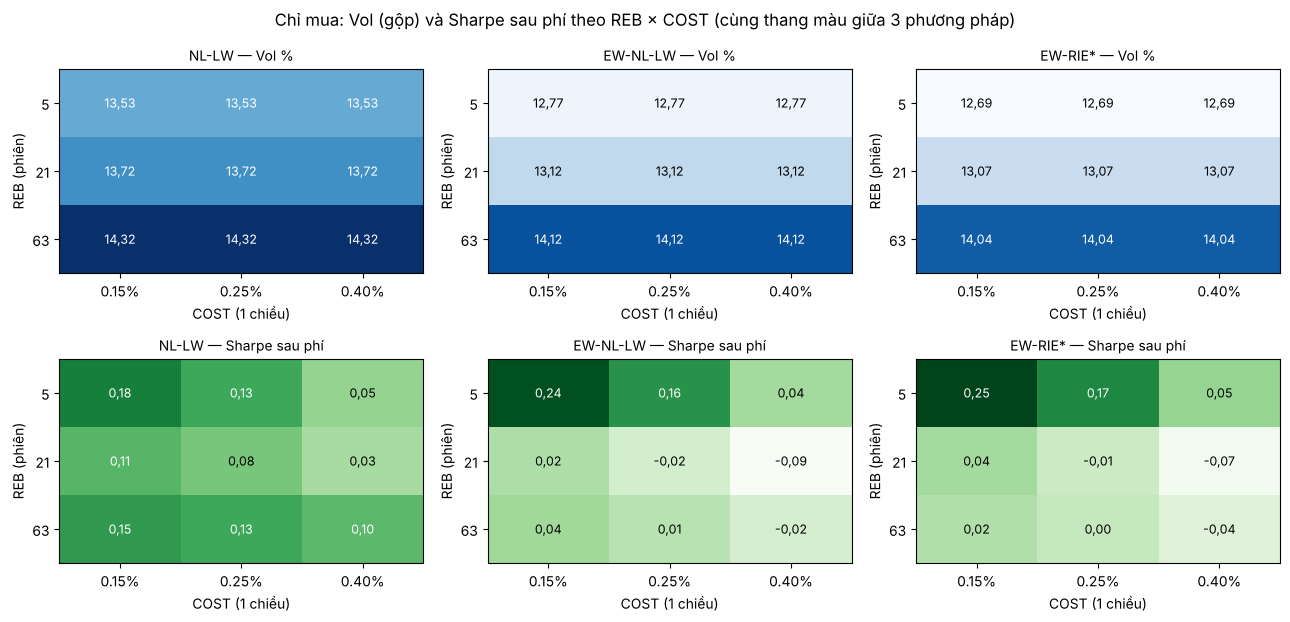

**Hình 10.** Heatmap của v3: Vol (%/năm, gộp) và Sharpe sau phí theo REB × COST, chế độ chỉ mua, NL-LW / EW-NL-LW / EW-RIE\*.

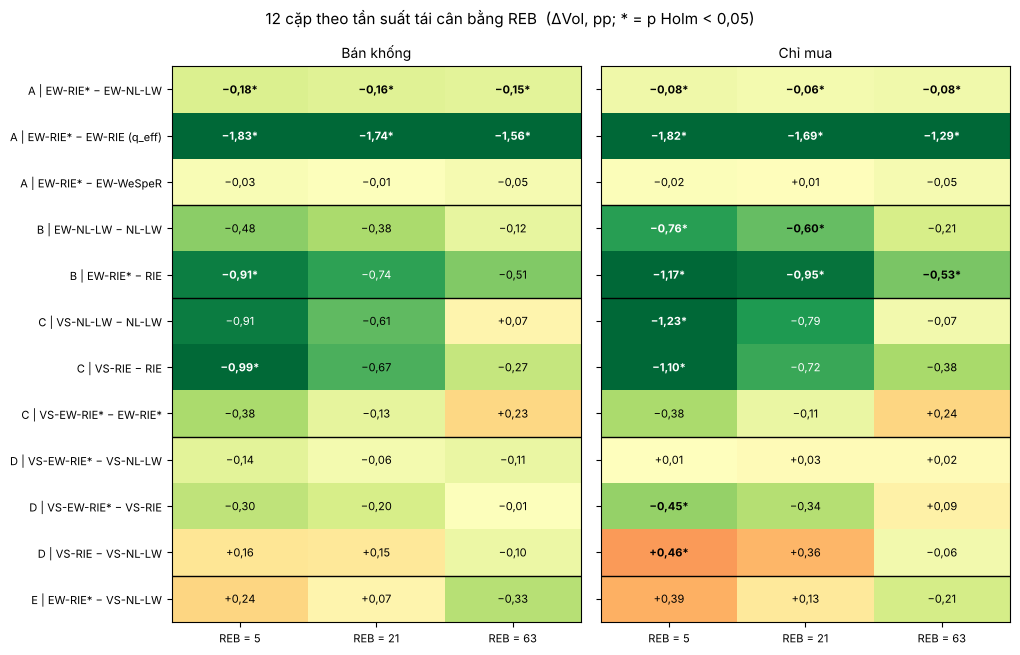

**Hình 11.** ΔVol (pp/năm) của 12 cặp theo REB; \* = p Holm < 0,05 trong từng cột (mô tả). Số liệu: `T2a_pairs_reb.csv`.

**Kết quả.** Bộ có Vol thấp nhất theo REB — Bán khống: REB = 5: VS-EW-RIE\*, REB = 21: VS-EW-RIE\*, REB = 63: EW-RIE\*; Chỉ mua: REB = 5: VS-NL-LW, REB = 21: VS-NL-LW, REB = 63: EW-RIE\*. Sharpe sau phí cao nhất (REB = 21) — Bán khống: COST = 0,15%: RIE, COST = 0,25%: RIE, COST = 0,40%: EW-RIE (q_eff); Chỉ mua: COST = 0,15%: EW-RIE (q_eff), COST = 0,25%: EW-RIE (q_eff), COST = 0,40%: EW-RIE (q_eff).

**Kết luận.** EW-RIE\* thấp hơn EW-NL-LW có ý nghĩa ở 6/6 ô (cao hơn có ý nghĩa 0); cặp thầy hỏi (EW-RIE\* − VS-NL-LW) không có ý nghĩa ở ô nào trong 6 ô (mô tả).

In [47]:
# ---- T2a: Bảng 19 (A theo REB), Bảng 20 (Sharpe sau phí theo COST, REB = 21), Hình 10 (heatmap REB × COST của v3), Hình 11 (heatmap cặp theo REB) ----
REBS, COSTS = (5, 21, 63), (0.0015, 0.0025, 0.004)
T2R = {(reb, m): run_full(dict(CONFIG, REB=reb), lo, M12) for reb in REBS for m, lo in MODES.items()}
T19 = pd.concat({(VN[m], f"REB = {reb}"): vols(T2R[(reb, m)]["out"], M12) for m in ("short_ok", "long_only") for reb in REBS}, axis=1); save(T19, "T2a_tableA_reb")
cap("Bảng", "Vol (%/năm, gộp) theo tần suất tái cân bằng REB (phiên), 12 phương pháp; in đậm: thấp nhất mỗi cột. Mỗi REB một bộ ngày ngoài mẫu chung cho mọi phương pháp.")
display(table_a(T19))
T20 = pd.concat({(VN[m], f"COST = {f2(100 * c)}%"): pd.Series({k: metrics(o, c)["Sharpe sau phí"] for k, o in T2R[(21, m)]["out"].items()}) for m in ("short_ok", "long_only") for c in COSTS}, axis=1).reindex(M12)
save(T20, "T2a_sharpe_cost")
cap("Bảng", "Sharpe sau phí (năm hóa) theo phí một chiều COST, REB = 21, 12 phương pháp; in đậm: **cao nhất** mỗi cột.")
display(T20.style.format(precision=3, decimal=",").highlight_max(axis=0, props="font-weight: bold"))
T2A = pd.DataFrame([dict(mode=m, REB=reb, COST=c, method=k, **metrics(o, c)) for (reb, m), d in T2R.items() for k, o in d["out"].items() for c in COSTS])
g_ = T2A.sort_values("COST").groupby(["method", "mode", "REB"]); assert g_["Sharpe sau phí"].apply(lambda s: (s.diff().dropna() <= 1e-12).all()).all()   # COST tăng ⇒ Sharpe sau phí không tăng
CORE3 = ["NL-LW", "EW-NL-LW", "EW-RIE*"]
fig, ax = plt.subplots(2, 3, figsize=(13, 6.3)); LOD = T2A[T2A["mode"] == "long_only"]
for j, k in enumerate(CORE3):
    for i, (col, cm_) in enumerate([("Vol %", "Blues"), ("Sharpe sau phí", "Greens")]):
        M = LOD[LOD.method == k].pivot(index="REB", columns="COST", values=col); lo_, hi_ = LOD[LOD.method.isin(CORE3)][col].min(), LOD[LOD.method.isin(CORE3)][col].max()
        ax[i, j].imshow(M.values, cmap=cm_, aspect="auto", vmin=lo_, vmax=hi_)
        ax[i, j].set_xticks(range(3), [f"{c:.2%}" for c in M.columns]); ax[i, j].set_yticks(range(3), M.index)
        for (y, x), v in np.ndenumerate(M.values): ax[i, j].text(x, y, f2(v), ha="center", va="center", fontsize=9, color="white" if v > (lo_ + hi_) / 2 else "black")
        ax[i, j].set_title(f"{k} — {col}", fontsize=10); ax[i, j].set_xlabel("COST (1 chiều)"); ax[i, j].set_ylabel("REB (phiên)")
fig.suptitle("Chỉ mua: Vol (gộp) và Sharpe sau phí theo REB × COST (cùng thang màu giữa 3 phương pháp)"); plt.tight_layout(); savefig(fig, "fig_10_T2a_heatmap")
cap("Hình", "Heatmap của v3: Vol (%/năm, gộp) và Sharpe sau phí theo REB × COST, chế độ chỉ mua, NL-LW / EW-NL-LW / EW-RIE\\*.")
G2A = {VN[m]: pair_grid({f"REB = {reb}": T2R[(reb, m)]["out"] for reb in REBS}) for m in ("short_ok", "long_only")}; save_grid(G2A, "T2a_pairs_reb")
pair_heatmap(G2A, "12 cặp theo tần suất tái cân bằng REB", fname="fig_11_pairs_reb")
cap("Hình", "ΔVol (pp/năm) của 12 cặp theo REB; \\* = p Holm < 0,05 trong từng cột (mô tả). Số liệu: `T2a_pairs_reb.csv`.")
bs = {m: T20[[c for c in T20.columns if c[0] == VN[m]]].idxmax() for m in MODES}
md("**Kết quả.** Bộ có Vol thấp nhất theo REB — " + "; ".join(f"{VN[m]}: " + ", ".join(f"REB = {reb}: {e_(T19[(VN[m], f'REB = {reb}')].idxmin())}" for reb in REBS) for m in ("short_ok", "long_only"))
   + ". Sharpe sau phí cao nhất (REB = 21) — " + "; ".join(f"{VN[m]}: " + ", ".join(f"{c[1]}: {e_(k)}" for c, k in bs[m].items()) for m in ("short_ok", "long_only")) + ".\n\n"
   f"**Kết luận.** {concl_grid(G2A)}")

**T2b. Lọc mã đứng giá** — không lọc, 5%, 10%, 15%, 20% (chuẩn), 30%: loại khỏi universe mã có tỷ lệ phiên r = 0 trong cửa sổ quá khứ vượt ngưỡng. Bảng A và heatmap tính trên **ngày chung** của các mức có ít nhất 60 kỳ; mức nào ít hơn 60 kỳ báo riêng dưới bảng.

**Bảng 21.** Vol (%/năm, gộp) theo mức lọc đứng giá, trên 1 446 phiên chung (2021-01-20 → 2026-11-10) của các mức có ≥ 60 kỳ; khối trên: bán khống, khối dưới: chỉ mua; in đậm: thấp nhất trong từng cột của mỗi khối. Số kỳ và phiên ngoài mẫu của từng mức — không lọc: 129 kỳ, 2706 phiên; 5%: 0 kỳ, 0 phiên; 10%: 69 kỳ, 1446 phiên; 15%: 111 kỳ, 2328 phiên; 20% (chuẩn): 118 kỳ, 2475 phiên; 30%: 129 kỳ, 2706 phiên.

*Mức 5%:* 0 kỳ (< 60) — không có kỳ nào đủ N = 100 mã, không tính được.

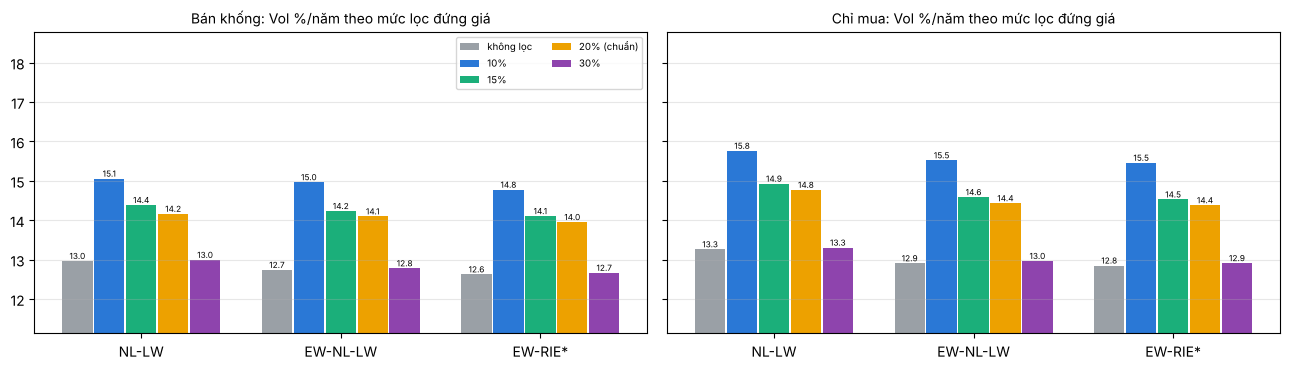

**Hình 12.** Hình của v3: Vol (%/năm) của NL-LW, EW-NL-LW, EW-RIE\* theo mức lọc đứng giá, trên ngày chung (trục không từ 0).

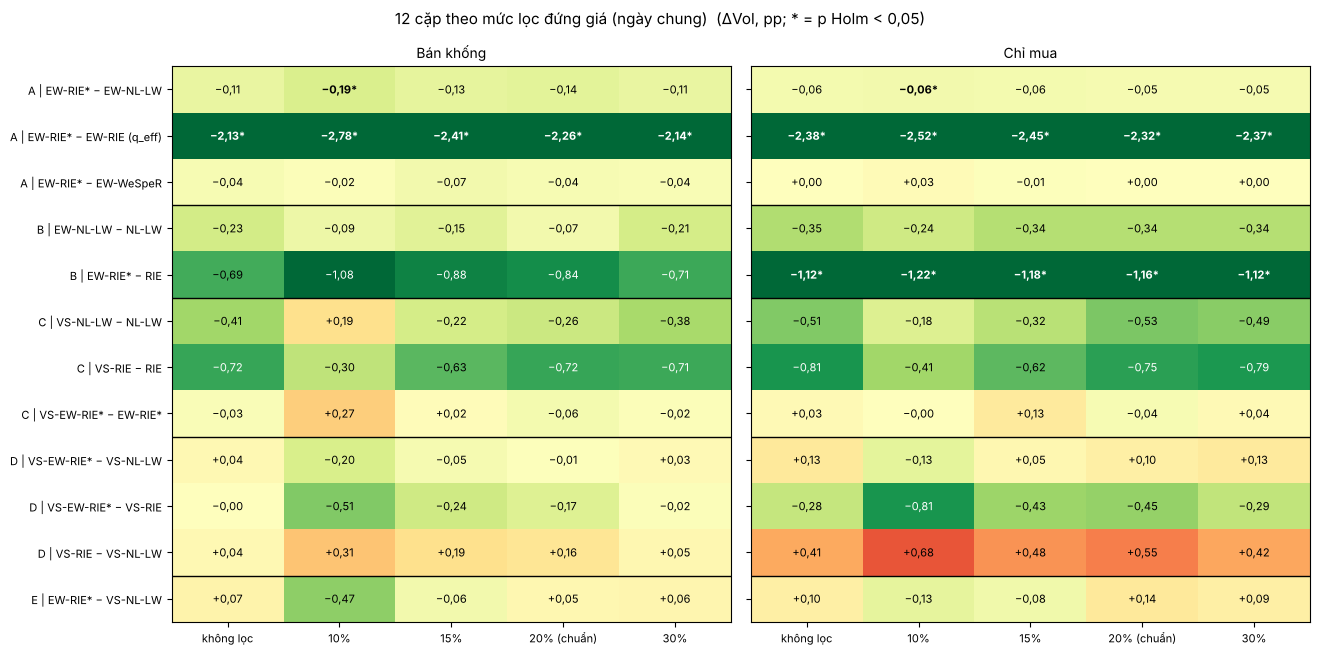

**Hình 13.** ΔVol (pp/năm) của 12 cặp theo mức lọc đứng giá, trên ngày chung; \* = p Holm < 0,05 trong từng cột (mô tả). Số liệu: `T2b_pairs_zero.csv`.

**Kết quả.** Bộ có Vol thấp nhất theo mức lọc — Bán khống: không lọc: VS-NL-LW, 10%: EW-RIE\*, 15%: EW-RIE\*, 20% (chuẩn): VS-EW-RIE\*, 30%: VS-NL-LW; Chỉ mua: không lọc: VS-NL-LW, 10%: EW-WeSpeR, 15%: EW-RIE\*, 20% (chuẩn): VS-NL-LW, 30%: VS-NL-LW.

**Kết luận.** EW-RIE\* thấp hơn EW-NL-LW có ý nghĩa ở 2/10 ô (cao hơn có ý nghĩa 0); cặp thầy hỏi (EW-RIE\* − VS-NL-LW) không có ý nghĩa ở ô nào trong 10 ô (mô tả).

In [48]:
# ---- T2b: Bảng 21 (A theo mức lọc, ngày chung), Hình 12 (của v3), Hình 13 (heatmap cặp theo mức lọc) ----
ZL = {"không lọc": 1.0, "5%": 0.05, "10%": 0.10, "15%": 0.15, "20% (chuẩn)": 0.20, "30%": 0.30}
ZB = {(z, m): run_full(dict(CONFIG, ZERO_MAX=v), lo, M12) for z, v in ZL.items() for m, lo in MODES.items()}
NK = {z: len(ZB[(z, "long_only")]["ulog"]) for z in ZL}; ZOK = [z for z in ZL if NK[z] >= 60]
COMMON = sorted(set.intersection(*[set(ZB[(z, "long_only")]["out"]["NL-LW"]["r"].index) for z in ZOK])); COMMON = pd.DatetimeIndex(COMMON)
def on_dates(out, dates): return {k: dict(r=o["r"].loc[dates], r_net=o["r_net"].loc[dates]) for k, o in out.items()}
T21 = pd.concat({VN[m]: pd.DataFrame({z: pd.Series({k: ZB[(z, m)]["out"][k]["r"].loc[COMMON].std() * np.sqrt(252) * 100 for k in M12}) for z in ZOK}) for m in ("short_ok", "long_only")}, names=["Chế độ", "Phương pháp"])
save(T21, "T2b_tableA_zero")
info = "; ".join(f"{z}: {NK[z]} kỳ, {len(ZB[(z, 'long_only')]['out']['NL-LW']['r'])} phiên" for z in ZL)
cap("Bảng", f"Vol (%/năm, gộp) theo mức lọc đứng giá, trên {th(len(COMMON))} phiên chung ({COMMON[0].date()} → {COMMON[-1].date()}) của các mức có ≥ 60 kỳ; khối trên: bán khống, khối dưới: chỉ mua; in đậm: thấp nhất trong từng cột của mỗi khối. Số kỳ và phiên ngoài mẫu của từng mức — {info}.")
display(T21.style.format(precision=2, decimal=",").apply(lambda c: ["font-weight: bold" if v == c.loc[g].min() else "" for (g, _), v in c.items()], axis=0))
for z in ZL:
    if z not in ZOK:
        md(f"*Mức {z}:* {NK[z]} kỳ (< 60) — " + ("không có kỳ nào đủ N = 100 mã, không tính được." if NK[z] == 0 else
           "trên ngày của chính nó: " + ", ".join(f"{e_(k)} {f2(ZB[(z, 'long_only')]['out'][k]['m']['Vol %'])}" for k in ("NL-LW", "EW-NL-LW", "EW-RIE*", "VS-NL-LW")) + " (chỉ mua)."))
CORE3 = ["NL-LW", "EW-NL-LW", "EW-RIE*"]; tb = T21.loc[:, ZOK]
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8), sharey=True); cols_ = ["#9aa0a6", "#2a78d6", "#1baf7a", "#eda100", "#8e44ad", "#eb6834"]
for a, m in zip(ax, ("short_ok", "long_only")):
    d = tb.loc[VN[m]].loc[CORE3]; x = np.arange(len(CORE3)); wd_ = .8 / len(ZOK)
    for j, z in enumerate(ZOK):
        a.bar(x + (j - (len(ZOK) - 1) / 2) * wd_, d[z], wd_ * .95, color=cols_[j], label=z)
        for i, v in enumerate(d[z]): a.text(i + (j - (len(ZOK) - 1) / 2) * wd_, v, f"{v:.1f}", ha="center", va="bottom", fontsize=6)
    a.set_xticks(x, CORE3); a.set_ylim(tb.loc[:, ZOK].loc[(slice(None), CORE3), :].values.min() - 1.5, tb.values.max() + .8); a.set_title(f"{VN[m]}: Vol %/năm theo mức lọc đứng giá", fontsize=10); a.grid(axis="y", alpha=.3)
ax[0].legend(fontsize=7, ncol=2); plt.tight_layout(); savefig(fig, "fig_12_zero_filter")
cap("Hình", "Hình của v3: Vol (%/năm) của NL-LW, EW-NL-LW, EW-RIE\\* theo mức lọc đứng giá, trên ngày chung (trục không từ 0).")
G2B = {VN[m]: pair_grid({z: on_dates(ZB[(z, m)]["out"], COMMON) for z in ZOK}) for m in ("short_ok", "long_only")}; save_grid(G2B, "T2b_pairs_zero")
pair_heatmap(G2B, "12 cặp theo mức lọc đứng giá (ngày chung)", fname="fig_13_pairs_zero")
cap("Hình", "ΔVol (pp/năm) của 12 cặp theo mức lọc đứng giá, trên ngày chung; \\* = p Holm < 0,05 trong từng cột (mô tả). Số liệu: `T2b_pairs_zero.csv`.")
md("**Kết quả.** Bộ có Vol thấp nhất theo mức lọc — " + "; ".join(f"{VN[m]}: " + ", ".join(f"{z}: {e_(T21.loc[VN[m], z].idxmin())}" for z in ZOK) for m in ("short_ok", "long_only")) + ".\n\n"
   f"**Kết luận.** {concl_grid(G2B)}")

**T2c. Phí thực tế** — `run_backtest` tính phí kỳ = COST × Σ|Δw| (COST là phí **một chiều** cho cả mua lẫn bán). HOSE: phí môi giới ~0,15% mỗi chiều + thuế bán 0,1% ⇒ mua 0,15%, bán 0,25%.

In [49]:
# T2c. Quy ước chi phí. run_backtest: phí kỳ = COST × Σ|w_mới − w_cũ| ⇒ COST là phí MỘT CHIỀU áp cho cả mua lẫn bán.
# HOSE: phí môi giới ~0,15% mỗi chiều + thuế bán 0,1% ⇒ bất đối xứng (mua 0,15%, bán 0,25%).
def trade_cost(w_new, w_old, c_buy, c_sell):
    u = w_new.index.union(w_old.index); d = w_new.reindex(u, fill_value=0) - w_old.reindex(u, fill_value=0)
    return c_buy * d.clip(lower=0).sum() + c_sell * (-d).clip(lower=0).sum()
rng = np.random.default_rng(SEED)
for _ in range(200):     # unit test: có mã ra/vào universe và tỷ trọng âm (bán khống), Σw = 1 ở cả hai kỳ
    a_ = pd.Series(rng.normal(size=6), index=list("ABCDEF")); a_ /= a_.sum(); b_ = pd.Series(rng.dirichlet(np.ones(4)), index=list("DEFG"))
    u = a_.index.union(b_.index); turn = (a_.reindex(u, fill_value=0) - b_.reindex(u, fill_value=0)).abs().sum()
    assert np.isclose(trade_cost(a_, b_, .0025, .0025), .0025 * turn) and np.isclose(trade_cost(a_, b_, .0015, .0025), .002 * turn)
o_new = run({"NL-LW": est_nllw}, dict(CONFIG, REB=63, COST=0.004))["out"]["NL-LW"]          # chạy lại thật với COST khác
assert np.allclose(net(T2R[(63, "long_only")]["out"]["NL-LW"], 0.004).values, o_new["r_net"].values, atol=1e-14)
SC = {"Gộp": None, "COST 0,25% (chuẩn)": .0025, "Mua 0,15% / bán 0,25%": .002}
T22 = pd.concat({(VN[m], sc): pd.Series({k: ann(o["r"] if c is None else net(o, c))[1] for k, o in T2R[(21, m)]["out"].items()}) for m in ("short_ok", "long_only") for sc, c in SC.items()}, axis=1).reindex(M12)
save(T22, "T2c_sharpe_convention")
cap("Bảng", "Sharpe (năm hóa) theo quy ước phí, REB = 21, 12 phương pháp; in đậm: cao nhất mỗi cột. Với Σw = 1, giá trị mua = giá trị bán = turnover/2 nên phí (mua 0,15%, bán 0,25%) ≡ COST đối xứng 0,20% (unit test 200 trường hợp, và r_net tính lại khớp backtest chạy lại thật).")
display(T22.style.format(precision=3, decimal=",").highlight_max(axis=0, props="font-weight: bold"))
md("**Kết quả.** Sharpe theo phí thực tế (mua 0,15% / bán 0,25%) — " + "; ".join(f"{VN[m]}: cao nhất {e_(T22[(VN[m], 'Mua 0,15% / bán 0,25%')].idxmax())} ({f2(T22[(VN[m], 'Mua 0,15% / bán 0,25%')].max(), 3)}), EW-RIE\\* {f2(T22.loc['EW-RIE*', (VN[m], 'Mua 0,15% / bán 0,25%')], 3)}, VS-NL-LW {f2(T22.loc['VS-NL-LW', (VN[m], 'Mua 0,15% / bán 0,25%')], 3)}" for m in ("short_ok", "long_only")) + ".\n\n"
   f"**Kết luận.** Giả định COST = 0,25% hơi bảo thủ so với phí thực tế (tương đương 0,20%); thứ tự Sharpe của 12 bộ giữa hai quy ước phí "
   + ("không đổi." if all((T22[(VN[m], 'COST 0,25% (chuẩn)')].rank() == T22[(VN[m], 'Mua 0,15% / bán 0,25%')].rank()).all() for m in MODES) else "có đổi ở vài vị trí."))

**Bảng 22.** Sharpe (năm hóa) theo quy ước phí, REB = 21, 12 phương pháp; in đậm: cao nhất mỗi cột. Với Σw = 1, giá trị mua = giá trị bán = turnover/2 nên phí (mua 0,15%, bán 0,25%) ≡ COST đối xứng 0,20% (unit test 200 trường hợp, và r_net tính lại khớp backtest chạy lại thật).

**Kết quả.** Sharpe theo phí thực tế (mua 0,15% / bán 0,25%) — Bán khống: cao nhất RIE (0,253), EW-RIE\* -0,099, VS-NL-LW -0,016; Chỉ mua: cao nhất EW-RIE (q_eff) (0,272), EW-RIE\* 0,014, VS-NL-LW 0,191.

**Kết luận.** Giả định COST = 0,25% hơi bảo thủ so với phí thực tế (tương đương 0,20%); thứ tự Sharpe của 12 bộ giữa hai quy ước phí có đổi ở vài vị trí.

**T2d. Lợi suất ngày hủy niêm yết** — hiện trạng: mã bị hủy trong kỳ nắm giữ có lợi suất 0 các ngày còn lại (giả định bán đúng giá cuối). Kịch bản: cú sốc vào ngày giao dịch đầu tiên sau ngày có giá cuối, 0% (S0, hiện tại) / −30% (S1) / −100% (S2) cho hủy bắt buộc và chưa rõ; thêm S1 cho mọi lý do. Cú sốc chỉ cộng vào lợi suất nắm giữ, không đụng giá `P` hay cửa sổ ước lượng (§3.2).

In [50]:
# ---- T2d (định nghĩa): sự kiện hủy niêm yết và cú sốc lợi suất ngày hủy ----
LASTPX = P.apply(lambda s: s.last_valid_index())
DL_REASON = MASTER.dropna(subset=["delisting_date"]).sort_values("delisting_date").groupby("ticker").tail(1).set_index("ticker")["reason"].fillna("chua_ro")
DL_REASON = DL_REASON.where(DL_REASON.isin(["bat_buoc", "hop_nhat", "tu_nguyen", "chuyen_san"]), "chua_ro")
_ev = []
for t in sorted(DELISTED):
    if t in LASTPX.index and pd.notna(LASTPX[t]) and LASTPX[t] < P.index[-1]:
        i = P.index.searchsorted(LASTPX[t], side="right"); _ev.append(dict(ticker=t, last_px=LASTPX[t], next_day=P.index[i], reason=DL_REASON.get(t, "chua_ro")))
DL_EVENTS = pd.DataFrame(_ev)                       # mỗi mã đã hủy có giá: ngày có giá cuối, ngày giao dịch đầu tiên sau đó, lý do
SCENARIOS = {"S0 (0%, hiện tại)": (0.0, ("bat_buoc", "chua_ro")), "S1 (−30%)": (-0.30, ("bat_buoc", "chua_ro")),
             "S2 (−100%)": (-1.0, ("bat_buoc", "chua_ro")), "S1 mọi lý do": (-0.30, ("bat_buoc", "chua_ro", "hop_nhat", "tu_nguyen", "chuyen_san"))}
def delist_adj(name):
    sh, rs = SCENARIOS[name]
    return {(r.next_day, r.ticker): sh for r in DL_EVENTS.itertuples() if r.reason in rs}
def run_full_scn(name, cfg=None, long_only=True, methods=None):
    # chạy FULL với cú sốc hủy niêm yết (tag riêng để không trúng nhầm cache); S0 dùng đúng cache chuẩn
    if name.startswith("S0"): return run_full(cfg, long_only, methods)
    ADJ["d"] = delist_adj(name)
    try: return run_full(cfg, long_only, methods, tag="delist:" + name)
    finally: ADJ["d"] = None

In [51]:
# ---- T2d: Bảng 23 (lượt hủy trong kỳ nắm giữ theo năm và lý do), Bảng 24 (A theo kịch bản) ----
dts = R_BT.index; ev = DL_EVENTS.set_index("ticker"); rows = []
for u in U0:
    s = POS[u["date"]]; win = dts[s:s + CONFIG["REB"]]
    for t in u["tickers"]:
        if t in ev.index and ev.loc[t, "next_day"] in win: rows.append(dict(date=u["date"], year=u["date"].year, ticker=t, reason=ev.loc[t, "reason"]))
HOLD = pd.DataFrame(rows); save(HOLD, "T2d_events")
RNV = {"bat_buoc": "bắt buộc", "hop_nhat": "hợp nhất", "tu_nguyen": "tự nguyện", "chuyen_san": "chuyển sàn", "chua_ro": "chưa rõ"}
tab = HOLD.assign(reason=HOLD.reason.map(RNV)).pivot_table(index="year", columns="reason", values="ticker", aggfunc="count", fill_value=0); tab["Tổng"] = tab.sum(1); tab.loc["Tổng"] = tab.sum()
ever = set().union(*[set(u["tickers"]) for u in U0]); _dl = MASTER.dropna(subset=["delisting_date"]); _hp = _dl[_dl.ticker.isin(P.columns)]
dl_px = set(_hp.ticker); n_in = len(dl_px & ever)
cap("Bảng", f"Lượt mã trong universe bị hủy niêm yết trong kỳ nắm giữ, theo năm và lý do (cấu hình chuẩn: {len(U0)} kỳ × N = {CONFIG['N']} = {th(len(U0) * CONFIG['N'])} vị thế). "
    f"Trong {len(_hp)} lượt hủy niêm yết có giá ({len(dl_px)} mã), {n_in} mã từng vào universe (danh mục) ít nhất một kỳ.")
show(tab.astype(int), 0)
ADJ["d"] = {}                                                                          # d = 0 ⇒ trùng hệt bản chuẩn (kiểm tra cài đặt)
for lo, m in ((True, "long_only"), (False, "short_ok")):
    z_ = run_backtest(P, V, {k: ESTIMATORS[k] for k in ("NL-LW", "EW-NL-LW")}, CONFIG, lo)
    assert all(np.array_equal(z_[k]["r"].values, OUT0[m][k]["r"].values) for k in z_)
ADJ["d"] = None
TD = {(sc, m): run_full_scn(sc, CONFIG, lo, M12) for sc in SCENARIOS for m, lo in MODES.items()}
T24 = pd.concat({(VN[m], sc.split(" (")[0] if "(" in sc else sc): vols(TD[(sc, m)]["out"], M12) for m in ("short_ok", "long_only") for sc in SCENARIOS}, axis=1); save(T24, "T2d_tableA_scenarios")
cap("Bảng", "Vol (%/năm, gộp) theo kịch bản lợi suất ngày hủy niêm yết (S0 = 0%, S1 = −30%, S2 = −100% cho hủy bắt buộc và chưa rõ; S1 mọi lý do), 12 phương pháp; in đậm: thấp nhất mỗi cột.")
display(table_a(T24))
rk = T24.rank(); same = {m: all((rk[(VN[m], c)] == rk[(VN[m], "S0")]).all() for c in rk[VN[m]].columns) for m in MODES}
dmax = max(abs(T24[(VN[m], c)] - T24[(VN[m], "S0")]).max() for m in MODES for c in T24[VN[m]].columns)
md(f"**Kết quả.** {len(HOLD)} lượt mã bị hủy trong kỳ nắm giữ ({', '.join(f'{k}: {int(v)}' for k, v in tab.loc['Tổng'].drop('Tổng').items())}); Vol đổi tối đa {f2(dmax, 3)} pp giữa các kịch bản; "
   + "; ".join(f"{VN[m]}: thứ hạng 12 bộ {'không đổi' if same[m] else 'có đổi'}" for m in ("short_ok", "long_only")) + ".\n\n"
   f"**Kết luận.** Cách xử lý lợi suất ngày hủy niêm yết {'không ảnh hưởng thứ hạng' if all(same.values()) else 'chỉ làm đổi thứ hạng ở mức nhỏ'}; hạn chế còn lại là {len(MISSING)} mã hủy thiếu giá không bao giờ vào universe.")

**Bảng 23.** Lượt mã trong universe bị hủy niêm yết trong kỳ nắm giữ, theo năm và lý do (cấu hình chuẩn: 118 kỳ × N = 100 = 11 800 vị thế). Trong 86 lượt hủy niêm yết có giá (85 mã), 32 mã từng vào universe (danh mục) ít nhất một kỳ.

reason,bắt buộc,Tổng
year,,
2017,1,1
2020,1,1
2022,2,2
2024,1,1
2025,1,1
Tổng,6,6


**Bảng 24.** Vol (%/năm, gộp) theo kịch bản lợi suất ngày hủy niêm yết (S0 = 0%, S1 = −30%, S2 = −100% cho hủy bắt buộc và chưa rõ; S1 mọi lý do), 12 phương pháp; in đậm: thấp nhất mỗi cột.

**Kết quả.** 6 lượt mã bị hủy trong kỳ nắm giữ (bắt buộc: 6); Vol đổi tối đa 0,093 pp giữa các kịch bản; Bán khống: thứ hạng 12 bộ không đổi; Chỉ mua: thứ hạng 12 bộ không đổi.

**Kết luận.** Cách xử lý lợi suất ngày hủy niêm yết không ảnh hưởng thứ hạng; hạn chế còn lại là 19 mã hủy thiếu giá không bao giờ vào universe.

### T3. Đối chứng & kiểm định

**Câu hỏi:** chênh lệch giữa các bộ có thật không, hay nằm trong dao động ngẫu nhiên của mẫu? Ô gợi ý của thầy giữ nguyên ngay dưới.

In [52]:
# ---- T3: Đối chứng & kiểm định ----
def est_equal_weight_proxy(X):
    # 1/N: dùng ma trận đơn vị -> GMV = 1/N
    return np.eye(X.shape[1])
# TODO: mô hình nhân tố (PCA k nhân tố), DCC-GARCH (gói `arch`/`mgarch`),
# kiểm định Ledoit & Wolf (2011) "Robust performances hypothesis testing with the variance" (HAC + bootstrap),
# kiểm định Sharpe Jobson–Korkie với hiệu chỉnh Memmel (2003).


**T3a. Đối chứng thêm** (định nghĩa ở §3.3): **1/N** (ma trận đơn vị ⇒ GMV = tỷ trọng đều; chiến lược phân bổ, không phải bộ ước lượng hiệp phương sai); **PCA-auto** (Σ = BBᵀ + diag(ψ) với k ∈ {1, 3, 5} nhân tố chọn trong cửa sổ huấn luyện: ước lượng trên 70% đầu, đo phương sai GMV trên 30% cuối); **DCC-GARCH(1,1)** (Engle 2002: GARCH(1,1) đơn biến cho từng mã, (a, b) bằng composite likelihood + correlation targeting; dự phòng phương sai mẫu khi GARCH không hội tụ). Chỉ dùng ở cấu hình chuẩn.

**T3b. Bảng so sánh** — 15 bộ (12 phương pháp + 1/N, PCA-auto, DCC-GARCH), cấu hình chuẩn, cùng ngày ngoài mẫu.

In [53]:
# ---- T3b: Bảng 25 — 15 bộ, cấu hình chuẩn: Vol, Sharpe, Sharpe sau phí, turnover, chi phí giao dịch %/năm, số mã hiệu dụng, tỷ trọng max, ms/lần (Bảng 12) ----
M15 = M12 + ["1/N", "PCA-auto", "DCC-GARCH(1,1)"]
T25 = pd.concat({VN[m]: pd.DataFrame({k: {"Vol %": OUT0[m][k]["m"]["Vol %"], "Sharpe": OUT0[m][k]["m"]["Sharpe"], "Sharpe sau phí": OUT0[m][k]["m"]["Sharpe sau phí"],
                                            "Turnover/kỳ": OUT0[m][k]["m"]["Turnover/kỳ"], "Chi phí GD %/năm": OUT0[m][k]["m"]["Turnover/kỳ"] * CONFIG["COST"] * 252 / CONFIG["REB"] * 100,
                                            "Số mã hiệu dụng": OUT0[m][k]["m"]["Số mã hiệu dụng"], "Tỷ trọng max %": OUT0[m][k]["m"]["Tỷ trọng max %"],
                                            "ms/lần (N = 100)": TT[100].get(k, np.nan)} for k in M15}).T for m in ("short_ok", "long_only")}, names=["Chế độ", "Phương pháp"])
save(T25, "T3b_benchmark")
for m in MODES: assert T25.loc[VN[m], "Turnover/kỳ"].idxmin() == "1/N"            # 1/N ít giao dịch nhất
cap("Bảng", f"Cấu hình chuẩn, 15 bộ ({len(U0)} kỳ, {th(len(OUT0['long_only']['EW-RIE*']['r']))} phiên). Chi phí GD %/năm = turnover × COST × 252/REB. Số mã hiệu dụng = 1/Σw²; tỷ trọng max trung bình theo kỳ. ms/lần lấy từ Bảng 12.")
show(T25, 2)
t_ = lambda m, k, c: T25.loc[(VN[m], k), c]
md("**Kết quả.** " + "; ".join(f"{VN[m]}: Vol thấp nhất {e_(T25.loc[VN[m], 'Vol %'].idxmin())} ({f2(T25.loc[VN[m], 'Vol %'].min())}), Sharpe sau phí cao nhất {e_(T25.loc[VN[m], 'Sharpe sau phí'].idxmax())} ({f2(T25.loc[VN[m], 'Sharpe sau phí'].max(), 3)}); "
   f"chi phí GD EW-RIE\\* {f2(t_(m, 'EW-RIE*', 'Chi phí GD %/năm'))}%/năm so với VS-NL-LW {f2(t_(m, 'VS-NL-LW', 'Chi phí GD %/năm'))}%/năm" for m in ("short_ok", "long_only")) + ".\n\n"
   f"**Kết luận.** Hạng Vol (trong 15) của 1/N, PCA-auto, DCC-GARCH: " + "; ".join(f"{VN[m]} " + ", ".join(str(int(T25.loc[VN[m], 'Vol %'].rank()[k])) for k in ("1/N", "PCA-auto", "DCC-GARCH(1,1)")) for m in ("short_ok", "long_only"))
   + "; năm bộ đầu (chỉ mua): " + ", ".join(e_(k) for k in T25.loc[VN['long_only'], 'Vol %'].nsmallest(5).index) + ".")

**Bảng 25.** Cấu hình chuẩn, 15 bộ (118 kỳ, 2 475 phiên). Chi phí GD %/năm = turnover × COST × 252/REB. Số mã hiệu dụng = 1/Σw²; tỷ trọng max trung bình theo kỳ. ms/lần lấy từ Bảng 12.

**Kết quả.** Bán khống: Vol thấp nhất VS-EW-RIE\* (12,43), Sharpe sau phí cao nhất 1/N (0,416); chi phí GD EW-RIE\* 2,83%/năm so với VS-NL-LW 4,22%/năm; Chỉ mua: Vol thấp nhất VS-NL-LW (12,93), Sharpe sau phí cao nhất 1/N (0,416); chi phí GD EW-RIE\* 1,43%/năm so với VS-NL-LW 2,23%/năm.

**Kết luận.** Hạng Vol (trong 15) của 1/N, PCA-auto, DCC-GARCH: Bán khống 15, 11, 14; Chỉ mua 15, 8, 13; năm bộ đầu (chỉ mua): VS-NL-LW, VS-EW-RIE\*, EW-WeSpeR, EW-RIE\*, EW-NL-LW.

**T3c. Kiểm định 12 cặp** — kiểm định sai khác phương sai Ledoit–Wolf (2011): p HAC và p bootstrap khối (b = 21, M = 2000; **kết quả chính**), Holm trên 12 cặp riêng từng chế độ; CI 95% bootstrap khối của ΔVol; Jobson–Korkie–Memmel cho Sharpe; ΔTurnover/kỳ kèm CI bootstrap theo kỳ.

**Bảng 26.** Bán khống: 12 cặp định trước, cấu hình chuẩn (2 475 phiên). ΔVol = Vol(bộ trước) − Vol(bộ sau), pp/năm (< 0: bộ trước rủi ro thấp hơn); CI 95% bootstrap khối b = 21; p Holm trên 12 cặp; ΔTurnover/kỳ kèm CI.

**Bảng 27.** Chỉ mua: 12 cặp định trước, cấu hình chuẩn (2 475 phiên). ΔVol = Vol(bộ trước) − Vol(bộ sau), pp/năm (< 0: bộ trước rủi ro thấp hơn); CI 95% bootstrap khối b = 21; p Holm trên 12 cặp; ΔTurnover/kỳ kèm CI.

**Bảng 28.** Phụ (không vào họ Holm): EW-RIE\* so với 1/N, PCA-auto, DCC-GARCH(1,1), cấu hình chuẩn.

**Bảng 29.** Cặp E (EW-RIE\* − VS-NL-LW) với độ dài khối bootstrap 10/21/42 phiên (p HAC không phụ thuộc b).

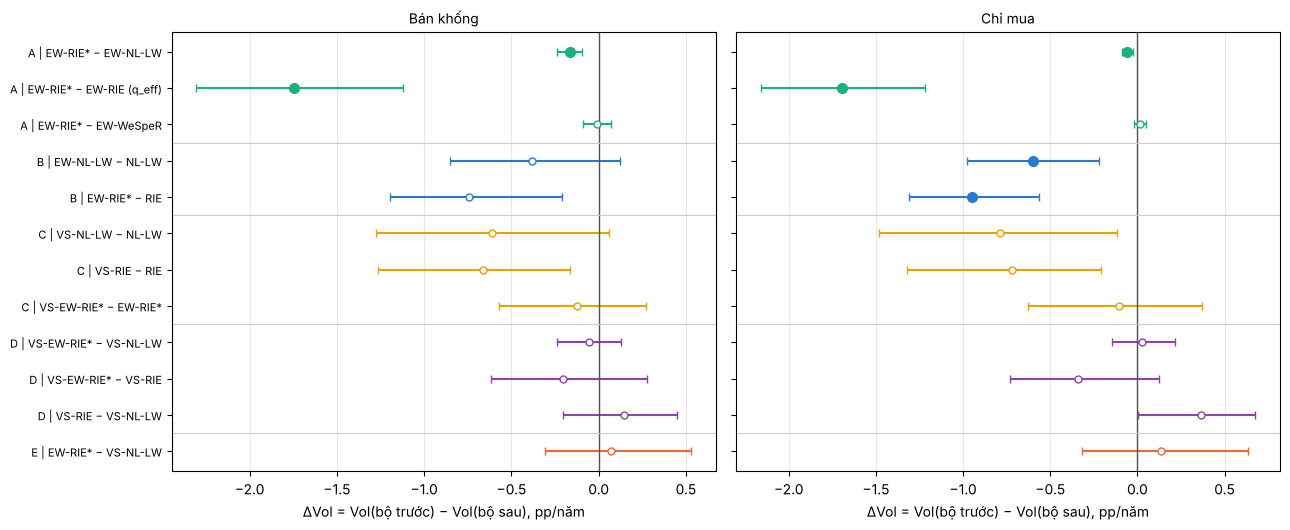

**Hình 14.** ΔVol và CI 95% (bootstrap khối, b = 21) của 12 cặp, cấu hình chuẩn, xếp theo cụm A–E; chấm đặc: p Holm < 0,05; đường dọc tại 0.

**Kết quả.** Cặp E (EW-RIE\* − VS-NL-LW): Bán khống ΔVol +0,07 pp [−0,31; +0,53], p LW-boot 0,755, p Holm 1,000, ΔTurnover −0,47/kỳ [−0,52; −0,41], chi phí GD 2,83 so với 4,22%/năm, số mã hiệu dụng 8,5 so với 7,7, tỷ trọng max 22,2% so với 25,7%; Chỉ mua ΔVol +0,13 pp [−0,32; +0,63], p LW-boot 0,573, p Holm 1,000, ΔTurnover −0,27/kỳ [−0,30; −0,24], chi phí GD 1,43 so với 2,23%/năm, số mã hiệu dụng 9,5 so với 8,1, tỷ trọng max 25,6% so với 30,7%. Các cặp có p Holm < 0,05 — Bán khống: EW-RIE\* − EW-NL-LW (−0,16), EW-RIE\* − EW-RIE (q_eff) (−1,74); Chỉ mua: EW-RIE\* − EW-NL-LW (−0,06), EW-RIE\* − EW-RIE (q_eff) (−1,69), EW-NL-LW − NL-LW (−0,60), EW-RIE\* − RIE (−0,95).

**Kết luận.** EW-RIE\* và VS-NL-LW ngang nhau về rủi ro; EW-RIE\* giao dịch ít hơn có ý nghĩa (CI ΔTurnover không chứa 0).

In [54]:
# ---- T3c: Bảng 26, 27 (pair_table 12 cặp), Bảng 28 (EW-RIE* vs 1/N, PCA, DCC; phụ), Bảng 29 (cặp E theo độ dài khối), Hình 14 ----
PT = {m: pair_table(OUT0[m], reb_dates=REB_DATES) for m in MODES}
save(pd.concat(PT, names=["mode"]), "T3c_pair_table")
COLS_PT = ["ΔVol (pp)", "CI lo", "CI hi", "p LW-HAC", "p LW-boot", "p Holm", "p JKM", "ΔTurnover", "Turn CI lo", "Turn CI hi"]
for m in ("short_ok", "long_only"):
    cap("Bảng", f"{VN[m]}: 12 cặp định trước, cấu hình chuẩn ({th(len(OUT0[m]['EW-RIE*']['r']))} phiên). ΔVol = Vol(bộ trước) − Vol(bộ sau), pp/năm (< 0: bộ trước rủi ro thấp hơn); CI 95% bootstrap khối b = 21; p Holm trên 12 cặp; ΔTurnover/kỳ kèm CI.")
    show(PT[m][COLS_PT], 3)
AUXP = [("phụ", "EW-RIE*", "1/N"), ("phụ", "EW-RIE*", "PCA-auto"), ("phụ", "EW-RIE*", "DCC-GARCH(1,1)")]
T28 = pd.concat({VN[m]: pair_table(OUT0[m], AUXP, reb_dates=REB_DATES).droplevel(0) for m in ("short_ok", "long_only")}, names=["Chế độ", "Cặp"]); save(T28, "T3c_aux")
cap("Bảng", "Phụ (không vào họ Holm): EW-RIE\\* so với 1/N, PCA-auto, DCC-GARCH(1,1), cấu hình chuẩn.")
show(T28[[c for c in COLS_PT if c != "p Holm"]], 3)
rows = []
for m in ("short_ok", "long_only"):
    ra, rb = OUT0[m]["EW-RIE*"]["r"].values, OUT0[m]["VS-NL-LW"]["r"].values
    for b_ in (10, 21, 42):
        lo_, hi_ = block_bootstrap_ci(ra, rb, block=b_); d_, se_, ph, pb = lw_var_test(ra, rb, block=b_)
        rows.append({"Chế độ": VN[m], "Độ dài khối b": b_, "ΔVol (pp)": (ra.std() - rb.std()) * np.sqrt(252) * 100, "CI lo": lo_, "CI hi": hi_, "p LW-HAC": ph, "p LW-boot": pb})
T29 = pd.DataFrame(rows).set_index(["Chế độ", "Độ dài khối b"]); save(T29, "T3c_pairE_blocks")
cap("Bảng", "Cặp E (EW-RIE\\* − VS-NL-LW) với độ dài khối bootstrap 10/21/42 phiên (p HAC không phụ thuộc b).")
show(T29, 3)
fig, ax = plt.subplots(1, 2, figsize=(13, 5.4), sharey=True); GCOL = {"A": "#1baf7a", "B": "#2a78d6", "C": "#eda100", "D": "#8e44ad", "E": "#eb6834"}
for a, m in zip(ax, ("short_ok", "long_only")):
    t = PT[m]; y = np.arange(len(t))[::-1]
    for yi, ((g, p), r) in zip(y, t.iterrows()):
        c = GCOL[g[0]]; a.errorbar(r["ΔVol (pp)"], yi, xerr=[[r["ΔVol (pp)"] - r["CI lo"]], [r["CI hi"] - r["ΔVol (pp)"]]], fmt="o", color=c, ecolor=c, capsize=3, ms=7 if r["p Holm"] < .05 else 5,
                   mfc=c if r["p Holm"] < .05 else "white")
    a.axvline(0, color="#52514e", lw=1); a.set_yticks(y, [f"{g[0]} | {p}" for g, p in t.index], fontsize=8); a.grid(axis="x", alpha=.3); a.set_title(VN[m], fontsize=10)
    a.set_xlabel("ΔVol = Vol(bộ trước) − Vol(bộ sau), pp/năm")
    cl = [g for g, _ in t.index]
    for i in range(1, len(cl)):
        if cl[i] != cl[i - 1]: a.axhline(y[i] + .5, color="#cccccc", lw=.8)
plt.tight_layout(); savefig(fig, "fig_14_pairs_ci")
cap("Hình", "ΔVol và CI 95% (bootstrap khối, b = 21) của 12 cặp, cấu hình chuẩn, xếp theo cụm A–E; chấm đặc: p Holm < 0,05; đường dọc tại 0.")
pe_ = {m: PT[m].xs("EW-RIE* − VS-NL-LW", level=1).iloc[0] for m in MODES}; t25 = lambda m, k, c: T25.loc[(VN[m], k), c]
sig = {m: [f"{e_(p)} ({dv(r['ΔVol (pp)'])})" for (g, p), r in PT[m].iterrows() if r["p Holm"] < .05] for m in MODES}
md("**Kết quả.** Cặp E (EW-RIE\\* − VS-NL-LW): " + "; ".join(f"{VN[m]} ΔVol {dv(pe_[m]['ΔVol (pp)'])} pp [{dv(pe_[m]['CI lo'])}; {dv(pe_[m]['CI hi'])}], p LW-boot {f2(pe_[m]['p LW-boot'], 3)}, p Holm {f2(pe_[m]['p Holm'], 3)}, "
   f"ΔTurnover {dv(pe_[m]['ΔTurnover'])}/kỳ [{dv(pe_[m]['Turn CI lo'])}; {dv(pe_[m]['Turn CI hi'])}], chi phí GD {f2(t25(m, 'EW-RIE*', 'Chi phí GD %/năm'))} so với {f2(t25(m, 'VS-NL-LW', 'Chi phí GD %/năm'))}%/năm, "
   f"số mã hiệu dụng {f2(t25(m, 'EW-RIE*', 'Số mã hiệu dụng'), 1)} so với {f2(t25(m, 'VS-NL-LW', 'Số mã hiệu dụng'), 1)}, tỷ trọng max {f2(t25(m, 'EW-RIE*', 'Tỷ trọng max %'), 1)}% so với {f2(t25(m, 'VS-NL-LW', 'Tỷ trọng max %'), 1)}%" for m in ("short_ok", "long_only"))
   + ". Các cặp có p Holm < 0,05 — " + "; ".join(f"{VN[m]}: " + (", ".join(sig[m]) if sig[m] else "không có") for m in ("short_ok", "long_only")) + ".\n\n"
   f"**Kết luận.** EW-RIE\\* và VS-NL-LW {'ngang nhau về rủi ro' if all(pe_[m]['p Holm'] >= .05 for m in MODES) else 'khác nhau có ý nghĩa về rủi ro'}; "
   f"EW-RIE\\* {'giao dịch ít hơn có ý nghĩa' if all(pe_[m]['Turn CI hi'] < 0 for m in MODES) else 'không giao dịch ít hơn một cách nhất quán'} (CI ΔTurnover {'không chứa' if all(pe_[m]['Turn CI hi'] < 0 for m in MODES) else 'chứa'} 0).")

### T5. Vì sao VS giúp trên HOSE?

**Câu hỏi:** chuẩn hóa biến động (VS) có giảm rủi ro không, khi nào, và nhờ phần nào? Ô gợi ý của thầy giữ nguyên ngay dưới. Số theo giai đoạn và đường trượt là **mô tả** (CI bootstrap khối, không Holm).

In [55]:
# ---- T5: Vì sao VS giúp trên HOSE? ----
# Gợi ý: (a) so sánh VS chỉ chuẩn hóa biến động riêng lẻ vs. cả nhân tố thị trường;
# (b) đo độ chính xác dự báo biến động 21 phiên của EWMA vs. cửa sổ phẳng trên HOSE;
# (c) phân rã lợi ích VS theo giai đoạn (bảng RESULTS[mode]["periods"]).


**T5a. Trước và sau VS** — cụm C (VS-NL-LW − NL-LW, VS-RIE − RIE, VS-EW-RIE\* − EW-RIE\*) theo giai đoạn thị trường (`PERIODS`).

**Bảng 30.** Cụm C (trước và sau VS): ΔVol (pp/năm) [CI 95% bootstrap khối] theo giai đoạn thị trường; < 0: VS giảm rủi ro. Mô tả, không Holm.

Giai đoạn                                   Toàn mẫu       2016-17 Ổn định  \
Chế độ    Cặp                                                                
Bán khống VS-NL-LW − NL-LW      −0,61 [−1,28; +0,06]  −1,05 [−1,94; −0,33]   
          VS-RIE − RIE          −0,67 [−1,26; −0,16]  −0,89 [−1,29; −0,45]   
          VS-EW-RIE* − EW-RIE*  −0,13 [−0,57; +0,27]  −0,38 [−0,62; −0,16]   
Chỉ mua   VS-NL-LW − NL-LW      −0,79 [−1,48; −0,12]  −0,86 [−1,44; −0,26]   
          VS-RIE − RIE          −0,72 [−1,32; −0,21]  −0,80 [−1,11; −0,36]   
          VS-EW-RIE* − EW-RIE*  −0,11 [−0,63; +0,37]  −0,29 [−0,43; −0,06]   

Giai đoạn                         2018-19 Điều chỉnh          2020Q1 COVID  \
Chế độ    Cặp                                                                
Bán khống VS-NL-LW − NL-LW      −0,76 [−1,18; −0,19]  −5,81 [−7,49; −2,90]   
          VS-RIE − RIE          −0,39 [−0,82; +0,14]  −2,58 [−3,30; −1,18]   
          VS-EW-RIE* − EW-RIE*  −0,19 [−0,61; +0,26]  −1,54 [−2,21; −0,20]   
Chỉ mua   VS-NL-LW − NL-LW      −0,82 [−1,36; −0,13]  −6,54 [−7,89; −4,92]   
          VS-RIE − RIE          −0,45 [−0,90; +0,01]  −2,92 [−3,74; −1,88]   
          VS-EW-RIE* − EW-RIE*  −0,14 [−0,68; +0,38]  −1,50 [−2,15; −0,48]   

Giai đoạn                            2020-21 Bùng nổ         2022 Sụt giảm  \
Chế độ    Cặp                                                                
Bán khống VS-NL-LW − NL-LW      −2,16 [−4,06; −0,59]  +0,55 [−1,61; +2,92]   
          VS-RIE − RIE          −2,25 [−4,47; −0,52]  +0,28 [−0,83; +1,72]   
          VS-EW-RIE* − EW-RIE*  −1,21 [−2,90; +0,14]  +0,98 [−0,26; +2,07]   
Chỉ mua   VS-NL-LW − NL-LW      −2,32 [−4,50; −0,41]  +0,67 [−1,10; +2,88]   
          VS-RIE − RIE          −2,46 [−4,73; −0,65]  +0,36 [−0,85; +1,86]   
          VS-EW-RIE* − EW-RIE*  −1,24 [−3,06; +0,19]  +1,28 [−0,30; +2,92]   

Giai đoạn                           2023-24 Phục hồi               2025-26  
Chế độ    Cặp                                                               
Bán khống VS-NL-LW − NL-LW      −0,75 [−1,13; +0,01]  +0,89 [+0,01; +2,00]  
          VS-RIE − RIE          −0,72 [−1,04; −0,20]  −0,04 [−0,72; +0,56]  
          VS-EW-RIE* − EW-RIE*  −0,20 [−0,48; +0,25]  +0,21 [−0,45; +0,95]  
Chỉ mua   VS-NL-LW − NL-LW      −0,71 [−1,24; +0,05]  +0,27 [−0,89; +1,50]  
          VS-RIE − RIE          −0,64 [−1,03; −0,11]  −0,19 [−0,80; +0,37]  
          VS-EW-RIE* − EW-RIE*  −0,35 [−0,69; +0,08]  +0,21 [−0,72; +1,09]

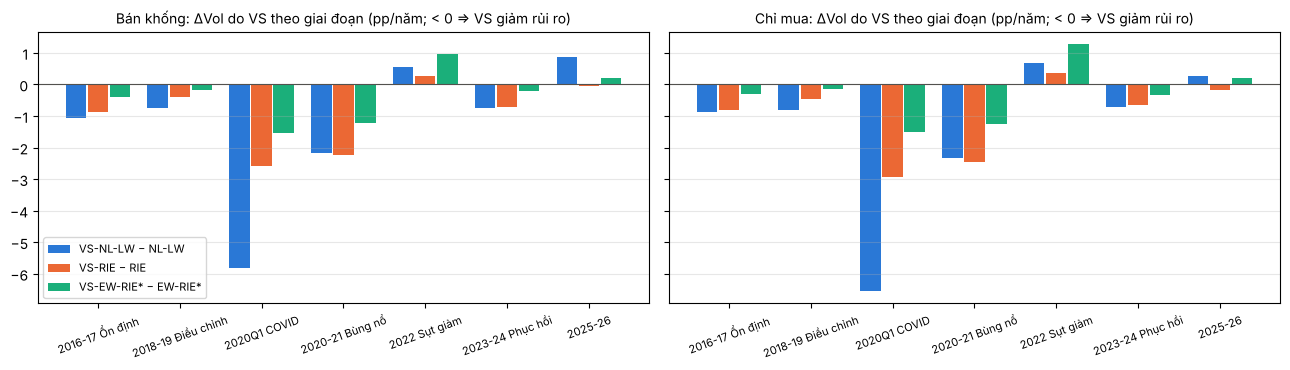

**Hình 15.** Hình của v3: ΔVol do VS theo giai đoạn thị trường, ba cặp của cụm C.

**Kết quả.** Giai đoạn cả ba cặp đều âm (VS giảm rủi ro) — Bán khống: 2016-17 Ổn định, 2018-19 Điều chỉnh, 2020Q1 COVID, 2020-21 Bùng nổ, 2023-24 Phục hồi; Chỉ mua: 2016-17 Ổn định, 2018-19 Điều chỉnh, 2020Q1 COVID, 2020-21 Bùng nổ, 2023-24 Phục hồi. 2020Q1 COVID: VS-NL-LW − NL-LW −6,54, VS-RIE − RIE −2,92, VS-EW-RIE\* − EW-RIE\* −1,50 (chỉ mua).

**Kết luận.** VS giảm rủi ro nhiều nhất ở giai đoạn 2020Q1 COVID (ΔVol trung bình −3,48 pp); 20/42 ô (giai đoạn × cặp × chế độ) có CI nằm hẳn dưới 0.

In [56]:
# ---- T5a: Bảng 30 (cụm C theo giai đoạn), Hình 15 (hình của v3) ----
def per_rows(pairs, modes=("short_ok", "long_only")):
    rows = []
    for m in modes:
        for g, a, b in pairs:
            for nm, s0, s1 in [("Toàn mẫu", None, None)] + list(PERIODS):
                ra, rb = OUT0[m][a]["r"], OUT0[m][b]["r"]
                if s0 is not None: ra, rb = ra[s0:s1], rb[s0:s1]
                if len(ra) <= 21: continue
                lo_, hi_ = block_bootstrap_ci(ra.values, rb.values)
                rows.append({"Chế độ": VN[m], "Cặp": f"{a} − {b}", "Giai đoạn": nm, "phiên": len(ra), "ΔVol (pp)": (ra.std() - rb.std()) * np.sqrt(252) * 100, "CI lo": lo_, "CI hi": hi_})
    return pd.DataFrame(rows)
PC = [p for p in PAIRS12 if p[0].startswith("C")]
T30 = per_rows(PC); save(T30, "T5a_vs_periods")
def per_table(T):
    t = T.assign(o=[f"{dv(d)} [{dv(l)}; {dv(h)}]" for d, l, h in zip(T["ΔVol (pp)"], T["CI lo"], T["CI hi"])])
    return t.pivot_table(index=["Chế độ", "Cặp"], columns="Giai đoạn", values="o", aggfunc="first", sort=False)[["Toàn mẫu"] + [p for p, _, _ in PERIODS if p in set(T["Giai đoạn"])]]
cap("Bảng", "Cụm C (trước và sau VS): ΔVol (pp/năm) [CI 95% bootstrap khối] theo giai đoạn thị trường; < 0: VS giảm rủi ro. Mô tả, không Holm.")
display(per_table(T30))
T5P = T30[T30["Giai đoạn"] != "Toàn mẫu"].pivot_table(index="Giai đoạn", columns=["Chế độ", "Cặp"], values="ΔVol (pp)", sort=False)
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8), sharey=True)
for a, m in zip(ax, (VN["short_ok"], VN["long_only"])):
    d = T5P[m]; x = np.arange(len(d))
    for j, (c, col) in enumerate(zip(d.columns, ["#2a78d6", "#eb6834", "#1baf7a"])): a.bar(x + (j - 1) * .27, d[c], .25, color=col, label=c)
    a.axhline(0, color="#52514e", lw=.8); a.set_xticks(x, d.index, rotation=20, fontsize=8); a.grid(axis="y", alpha=.3)
    a.set_title(f"{m}: ΔVol do VS theo giai đoạn (pp/năm; < 0 ⇒ VS giảm rủi ro)", fontsize=10)
ax[0].legend(fontsize=8); plt.tight_layout(); savefig(fig, "fig_15_vs_periods")
cap("Hình", "Hình của v3: ΔVol do VS theo giai đoạn thị trường, ba cặp của cụm C.")
neg = {m: [p for p in T5P.index if (T5P.loc[p, VN[m]] < 0).all()] for m in MODES}
cv = T30[(T30["Giai đoạn"] == "2020Q1 COVID")].set_index(["Chế độ", "Cặp"])["ΔVol (pp)"]
md("**Kết quả.** Giai đoạn cả ba cặp đều âm (VS giảm rủi ro) — " + "; ".join(f"{VN[m]}: {', '.join(neg[m]) if neg[m] else 'không có'}" for m in ("short_ok", "long_only"))
   + f". 2020Q1 COVID: " + ", ".join(f"{e_(p)} {dv(v)}" for (mm, p), v in cv.items() if mm == VN['long_only']) + " (chỉ mua).\n\n"
   f"**Kết luận.** VS giảm rủi ro nhiều nhất ở giai đoạn {T5P.mean(axis=1).idxmin()} (ΔVol trung bình {dv(T5P.mean(axis=1).min())} pp); "
   f"{int(((T30['CI hi'] < 0) & (T30['Giai đoạn'] != 'Toàn mẫu')).sum())}/{int((T30['Giai đoạn'] != 'Toàn mẫu').sum())} ô (giai đoạn × cặp × chế độ) có CI nằm hẳn dưới 0.")

**T5b. Dự báo biến động** — dự báo phương sai 21 phiên tới của từng mã trong universe chuẩn, chỉ dùng cửa sổ quá khứ; mục tiêu = trung bình r² của 21 phiên sau. Sai số: RMSE của vol năm hóa và QLIKE (Patton 2011).

**Bảng 31.** RMSE dự báo vol 21 phiên (%/năm) theo giai đoạn: EWMA (half-life 10/20/40, đúng hàm `ewma_standardize` mà VS dùng) và cửa sổ phẳng 63/250 phiên; dòng cuối: QLIKE toàn mẫu (thấp hơn = tốt hơn).

model,EWMA hl=10,EWMA hl=20,EWMA hl=40,Phẳng 63 phiên,Phẳng 250 phiên
period,,,,,
2016-17 Ổn định,"12,68","12,21","12,29","12,74","13,58"
2018-19 Điều chỉnh,"12,62","12,06","12,23","12,57","14,20"
2020Q1 COVID,"17,50","18,61","20,96","20,55","25,75"
2020-21 Bùng nổ,"14,85","14,36","14,07","15,37","14,11"
2022 Sụt giảm,"16,41","16,24","15,76","18,43","15,67"
2023-24 Phục hồi,"11,26","11,70","12,70","13,03","14,87"
2025-26,"13,36","12,91","12,73","13,81","13,14"
Toàn mẫu,"13,51","13,27","13,44","14,36","14,64"
QLIKE (toàn mẫu),"-6,41","-6,46","-6,48","-6,42","-6,44"


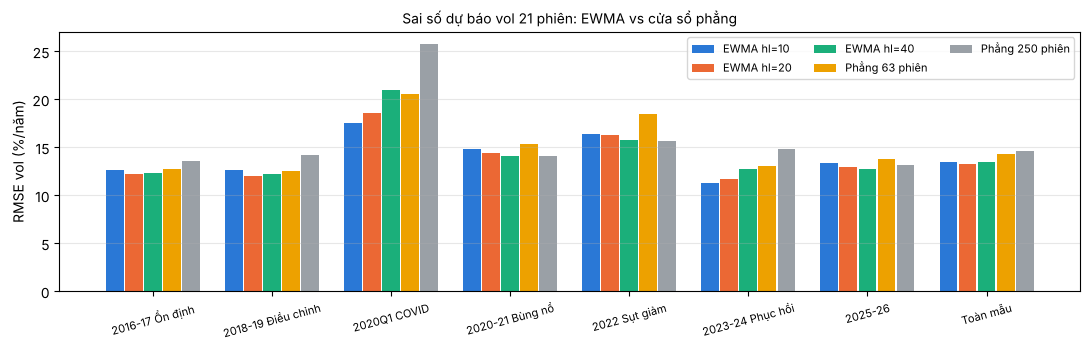

**Hình 16.** Hình của v3: RMSE dự báo vol 21 phiên theo giai đoạn, EWMA so với cửa sổ phẳng.

**Kết quả.** RMSE toàn mẫu (%/năm): EWMA hl=10 13,51, EWMA hl=20 13,27, EWMA hl=40 13,44, Phẳng 63 phiên 14,36, Phẳng 250 phiên 14,64; 2020Q1 COVID: EWMA hl=10 17,50, EWMA hl=20 18,61, EWMA hl=40 20,96, Phẳng 63 phiên 20,55, Phẳng 250 phiên 25,75.

**Kết luận.** EWMA dự báo biến động 21 phiên tốt hơn cửa sổ phẳng trên toàn mẫu (tốt nhất: EWMA hl=20), nhất là ở 2020Q1 — một lý do VS giúp trên HOSE.

In [57]:
# ---- T5b (của v3): Bảng 31, Hình 16 ---- Dự báo phương sai 21 phiên tới: EWMA (hl ∈ {10, 20, 40}, đúng hàm ewma_standardize mà VS dùng) vs cửa sổ phẳng 63/250 phiên.
# Mẫu: các mã trong universe chuẩn ở mỗi kỳ; dự báo chỉ dùng cửa sổ quá khứ. Mục tiêu RV = trung bình r² của 21 phiên sau.
# Sai số: RMSE của vol năm hóa (%) và QLIKE = log h + RV/h (dạng Patton 2011, xác định cả khi RV = 0).
W, H = CONFIG["WINDOW"], 21; rows = []
for u in U0:
    s = POS[u["date"]]
    if s + H > len(R_BT): continue
    X = R_BT.iloc[s - W:s][u["tickers"]].fillna(0).values; rv = (R_BT.iloc[s:s + H][u["tickers"]].fillna(0).values ** 2).mean(0)
    fc = {**{f"EWMA hl={h}": ewma_standardize(X, h)[1] ** 2 for h in (10, 20, 40)}, **{f"Phẳng {w} phiên": (X[-w:] ** 2).mean(0) for w in (63, W)}}
    per_ = next((p for p, a_, b_ in PERIODS if pd.Timestamp(a_) <= u["date"] <= pd.Timestamp(b_)), None)
    for k, h in fc.items():
        h = np.maximum(h, 1e-12); rows.append(dict(period=per_, model=k, se=np.mean((np.sqrt(h) - np.sqrt(rv)) ** 2), ql=np.mean(np.log(h) + rv / h)))
F = pd.DataFrame(rows); F = pd.concat([F, F.assign(period="Toàn mẫu")])
T5B = F.groupby(["period", "model"], sort=False).agg(RMSE=("se", lambda x: np.sqrt(x.mean() * 252) * 100), QLIKE=("ql", "mean"), n=("se", "size"))
save(T5B, "T5b_vol_forecast")
tbl = T5B["RMSE"].unstack()[["EWMA hl=10", "EWMA hl=20", "EWMA hl=40", "Phẳng 63 phiên", f"Phẳng {W} phiên"]]
tbl.loc["QLIKE (toàn mẫu)"] = T5B.xs("Toàn mẫu")["QLIKE"]
cap("Bảng", "RMSE dự báo vol 21 phiên (%/năm) theo giai đoạn: EWMA (half-life 10/20/40, đúng hàm `ewma_standardize` mà VS dùng) và cửa sổ phẳng 63/250 phiên; dòng cuối: QLIKE toàn mẫu (thấp hơn = tốt hơn).")
show(tbl)
fig, ax = plt.subplots(figsize=(11, 3.6)); M = tbl.drop(index="QLIKE (toàn mẫu)"); x = np.arange(len(M))
for j, (c, col) in enumerate(zip(M.columns, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#9aa0a6"])): ax.bar(x + (j - 2) * .16, M[c], .15, color=col, label=c)
ax.set_xticks(x, M.index, rotation=15, fontsize=8); ax.set_ylabel("RMSE vol (%/năm)"); ax.legend(fontsize=8, ncol=3); ax.grid(axis="y", alpha=.3)
ax.set_title("Sai số dự báo vol 21 phiên: EWMA vs cửa sổ phẳng", fontsize=10); plt.tight_layout(); savefig(fig, "fig_16_vol_forecast")
cap("Hình", "Hình của v3: RMSE dự báo vol 21 phiên theo giai đoạn, EWMA so với cửa sổ phẳng.")
fa, cv = M.loc["Toàn mẫu"], M.loc["2020Q1 COVID"]

md(f"**Kết quả.** RMSE toàn mẫu (%/năm): " + ", ".join(f"{k} {f2(v)}" for k, v in fa.items()) + f"; 2020Q1 COVID: " + ", ".join(f"{k} {f2(v)}" for k, v in cv.items()) + ".\n\n"
   f"**Kết luận.** EWMA dự báo biến động 21 phiên {'tốt hơn' if fa[[c for c in fa.index if c.startswith('EWMA')]].min() < fa[[c for c in fa.index if c.startswith('Phẳng')]].min() else 'không tốt hơn'} cửa sổ phẳng trên toàn mẫu "
   f"(tốt nhất: {fa.idxmin()}), {'nhất là' if cv[[c for c in cv.index if c.startswith('EWMA')]].min() < cv[[c for c in cv.index if c.startswith('Phẳng')]].min() else 'nhưng không'} ở 2020Q1 — một lý do VS giúp trên HOSE.")

**T5c. Họ VS và cặp chính theo thời gian** — cụm D (trong họ VS) và cụm E (EW-RIE\* − VS-NL-LW) theo giai đoạn, và ΔVol trượt 1 năm (252 phiên) của cặp E.

**Bảng 32.** Cụm D (trong họ VS) và cụm E (EW-RIE\* − VS-NL-LW): ΔVol (pp/năm) [CI 95% bootstrap khối] theo giai đoạn. Mô tả, không Holm.

Giai đoạn                                    Toàn mẫu       2016-17 Ổn định  \
Chế độ    Cặp                                                                 
Bán khống VS-EW-RIE* − VS-NL-LW  −0,06 [−0,24; +0,13]  −0,12 [−0,34; +0,12]   
          VS-EW-RIE* − VS-RIE    −0,20 [−0,62; +0,27]  +0,06 [−0,13; +0,25]   
          VS-RIE − VS-NL-LW      +0,15 [−0,20; +0,45]  −0,18 [−0,29; −0,04]   
          EW-RIE* − VS-NL-LW     +0,07 [−0,31; +0,53]  +0,26 [−0,00; +0,58]   
Chỉ mua   VS-EW-RIE* − VS-NL-LW  +0,03 [−0,15; +0,22]  −0,14 [−0,30; +0,02]   
          VS-EW-RIE* − VS-RIE    −0,34 [−0,73; +0,12]  +0,03 [−0,14; +0,15]   
          VS-RIE − VS-NL-LW      +0,36 [+0,01; +0,68]  −0,17 [−0,30; −0,02]   
          EW-RIE* − VS-NL-LW     +0,13 [−0,32; +0,63]  +0,15 [−0,13; +0,35]   

Giai đoạn                          2018-19 Điều chỉnh          2020Q1 COVID  \
Chế độ    Cặp                                                                 
Bán khống VS-EW-RIE* − VS-NL-LW  −0,16 [−0,42; +0,08]  +0,25 [−0,46; +1,37]   
          VS-EW-RIE* − VS-RIE    −0,26 [−0,74; +0,25]  −0,30 [−1,16; +0,96]   
          VS-RIE − VS-NL-LW      +0,09 [−0,23; +0,39]  +0,54 [+0,29; +0,71]   
          EW-RIE* − VS-NL-LW     +0,03 [−0,62; +0,61]  +1,79 [+0,54; +2,28]   
Chỉ mua   VS-EW-RIE* − VS-NL-LW  −0,08 [−0,28; +0,16]  +0,48 [−0,28; +1,84]   
          VS-EW-RIE* − VS-RIE    +0,03 [−0,38; +0,51]  −0,51 [−1,55; +0,97]   
          VS-RIE − VS-NL-LW      −0,11 [−0,56; +0,25]  +0,99 [+0,58; +1,27]   
          EW-RIE* − VS-NL-LW     +0,05 [−0,57; +0,71]  +1,97 [+0,86; +3,16]   

Giai đoạn                             2020-21 Bùng nổ         2022 Sụt giảm  \
Chế độ    Cặp                                                                 
Bán khống VS-EW-RIE* − VS-NL-LW  −0,38 [−0,68; −0,08]  +0,60 [−0,14; +1,24]   
          VS-EW-RIE* − VS-RIE    −0,63 [−1,28; −0,12]  −0,08 [−2,30; +2,00]   
          VS-RIE − VS-NL-LW      +0,25 [−0,19; +0,75]  +0,68 [−0,78; +2,22]   
          EW-RIE* − VS-NL-LW     +0,83 [−0,61; +2,64]  −0,38 [−1,38; +0,80]   
Chỉ mua   VS-EW-RIE* − VS-NL-LW  −0,28 [−0,46; +0,02]  +0,26 [−0,51; +0,98]   
          VS-EW-RIE* − VS-RIE    −0,77 [−1,39; −0,14]  −0,63 [−2,52; +1,44]   
          VS-RIE − VS-NL-LW      +0,49 [−0,11; +1,16]  +0,89 [−0,50; +2,12]   
          EW-RIE* − VS-NL-LW     +0,96 [−0,51; +2,99]  −1,02 [−2,20; −0,01]   

Giai đoạn                            2023-24 Phục hồi               2025-26  
Chế độ    Cặp                                                                
Bán khống VS-EW-RIE* − VS-NL-LW  −0,21 [−0,43; −0,00]  −0,07 [−0,48; +0,39]  
          VS-EW-RIE* − VS-RIE    −0,70 [−1,38; −0,05]  +0,38 [−0,32; +1,34]  
          VS-RIE − VS-NL-LW      +0,49 [−0,05; +1,03]  −0,45 [−1,44; +0,21]  
          EW-RIE* − VS-NL-LW     −0,01 [−0,56; +0,38]  −0,28 [−1,13; +0,53]  
Chỉ mua   VS-EW-RIE* − VS-NL-LW  −0,04 [−0,19; +0,14]  +0,15 [−0,18; +0,52]  
          VS-EW-RIE* − VS-RIE    −0,59 [−1,10; +0,00]  −0,05 [−0,89; +1,10]  
          VS-RIE − VS-NL-LW      +0,55 [−0,08; +1,11]  +0,19 [−0,90; +1,05]  
          EW-RIE* − VS-NL-LW     +0,31 [−0,22; +0,77]  −0,07 [−1,05; +0,96]

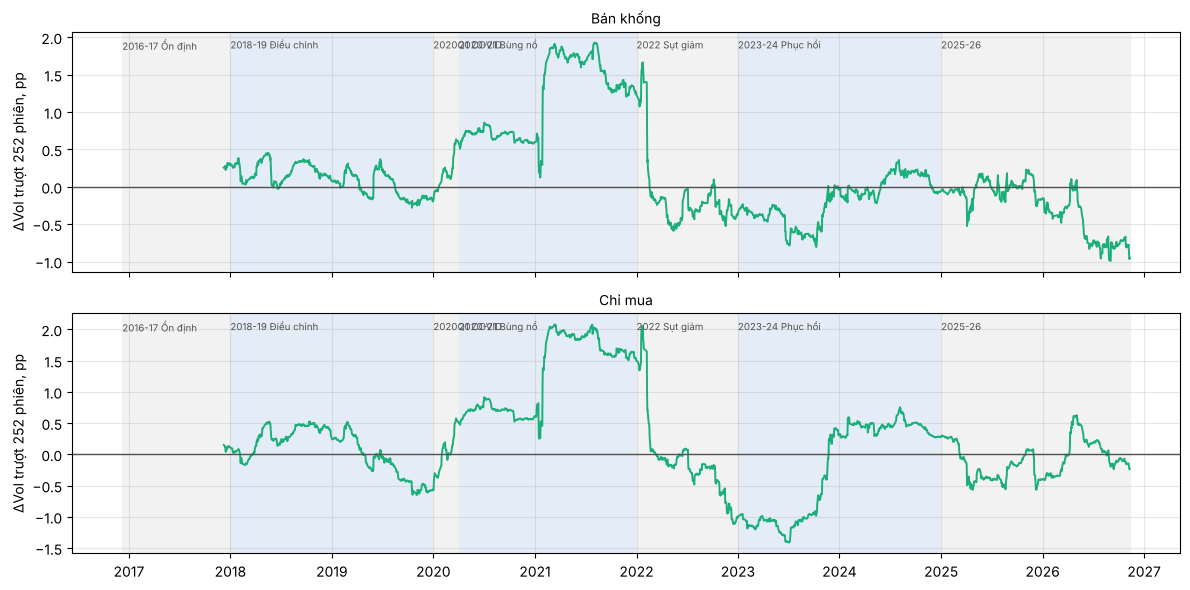

**Hình 17.** ΔVol trượt 1 năm (252 phiên) của EW-RIE\* − VS-NL-LW theo thời gian; nền: các giai đoạn trong `PERIODS`; > 0: EW-RIE\* rủi ro cao hơn. Mô tả.

**Kết quả.** Cặp E có CI 95% không chứa 0 ở: 2020Q1 COVID (bán khống, +1,79 pp); 2020Q1 COVID (chỉ mua, +1,97 pp); 2022 Sụt giảm (chỉ mua, −1,02 pp). Tỷ lệ ngày ΔVol trượt > 0: Bán khống 51%, Chỉ mua 58%.

**Kết luận.** Theo giai đoạn, VS-NL-LW thấp hơn rõ ở 2020Q1 COVID, EW-RIE\* thấp hơn rõ ở 2022 Sụt giảm; trên toàn mẫu CI chứa 0.

In [58]:
# ---- T5c: Bảng 32 (cụm D, E theo giai đoạn), Hình 17 (ΔVol trượt 252 phiên của EW-RIE* − VS-NL-LW) ----
T32 = per_rows([p for p in PAIRS12 if p[0][0] in "DE"]); save(T32, "T5c_periods_DE")
cap("Bảng", "Cụm D (trong họ VS) và cụm E (EW-RIE\\* − VS-NL-LW): ΔVol (pp/năm) [CI 95% bootstrap khối] theo giai đoạn. Mô tả, không Holm.")
display(per_table(T32))
fig, ax = plt.subplots(2, 1, figsize=(12, 6), sharex=True); PCOL = ["#f2f2f2", "#e3ecf7"]
for a, m in zip(ax, ("short_ok", "long_only")):
    ra, rb = OUT0[m]["EW-RIE*"]["r"], OUT0[m]["VS-NL-LW"]["r"]
    roll = (ra.rolling(252).std() - rb.rolling(252).std()) * np.sqrt(252) * 100
    for i, (nm, s0, s1) in enumerate(PERIODS):
        a.axvspan(max(pd.Timestamp(s0), ra.index[0]), min(pd.Timestamp(s1), ra.index[-1]), color=PCOL[i % 2], zorder=0)
        a.text(max(pd.Timestamp(s0), ra.index[0]), .97, nm, transform=a.get_xaxis_transform(), fontsize=7, va="top", color="#52514e")
    a.plot(roll.index, roll.values, color=COL["EW-RIE*"], lw=1.4); a.axhline(0, color="#52514e", lw=1)
    a.set_ylabel("ΔVol trượt 252 phiên, pp"); a.set_title(VN[m], fontsize=10); a.grid(alpha=.3)
plt.tight_layout(); savefig(fig, "fig_17_rolling_E")
cap("Hình", "ΔVol trượt 1 năm (252 phiên) của EW-RIE\\* − VS-NL-LW theo thời gian; nền: các giai đoạn trong `PERIODS`; > 0: EW-RIE\\* rủi ro cao hơn. Mô tả.")
E_ = T32[T32["Cặp"] == "EW-RIE* − VS-NL-LW"]; sgn = E_[(E_["Giai đoạn"] != "Toàn mẫu") & ((E_["CI lo"] > 0) | (E_["CI hi"] < 0))]
md("**Kết quả.** Cặp E có CI 95% không chứa 0 ở: " + ("; ".join(f"{r['Giai đoạn']} ({r['Chế độ'].lower()}, {dv(r['ΔVol (pp)'])} pp)" for _, r in sgn.iterrows()) if len(sgn) else "không giai đoạn nào")
   + f". Tỷ lệ ngày ΔVol trượt > 0: " + ", ".join(f"{VN[m]} {f2(100 * ((OUT0[m]['EW-RIE*']['r'].rolling(252).std() - OUT0[m]['VS-NL-LW']['r'].rolling(252).std()).dropna() > 0).mean(), 0)}%" for m in ("short_ok", "long_only")) + ".\n\n"
   f"**Kết luận.** Theo giai đoạn, VS-NL-LW thấp hơn rõ ở {', '.join(sorted(set(sgn[sgn['ΔVol (pp)'] > 0]['Giai đoạn']))) or 'không giai đoạn nào'}, "
   f"EW-RIE\\* thấp hơn rõ ở {', '.join(sorted(set(sgn[sgn['ΔVol (pp)'] < 0]['Giai đoạn']))) or 'không giai đoạn nào'}; trên toàn mẫu CI {'chứa' if all((E_[E_['Giai đoạn'] == 'Toàn mẫu']['CI lo'] < 0) & (E_[E_['Giai đoạn'] == 'Toàn mẫu']['CI hi'] > 0)) else 'không chứa'} 0.")

**T5d. VS giúp nhờ phần chung hay phần riêng?** (gợi ý (a) trong ô T5 của thầy; đây là cách nhóm hiểu gợi ý, cần thầy xác nhận.) Trong một cửa sổ X (T × N): σ\_i,t = độ lệch chuẩn EWMA (half-life HL\_VOL) của mã i như `ewma_standardize`; σ\_m,t = độ lệch chuẩn EWMA cùng half-life của lợi suất trung bình đều N mã; ρ\_i,t = σ\_i,t / σ\_m,t. Cùng bộ làm sạch NL-LW, cùng bỏ HL\_VOL phiên đầu như `make_vs`:
- **NL-LW**: không chuẩn hóa. **VS chỉ phần chung**: Z\_i,t = X\_i,t / σ\_m,t; Σ = Corr\_sạch(Z) ∘ (s\_i s\_j), s\_i = độ lệch chuẩn mẫu của Z\_i (hệ số chung σ\_m,T² không ảnh hưởng tỷ trọng GMV). **VS chỉ phần riêng**: Z\_i,t = X\_i,t / ρ\_i,t; Σ = Corr\_sạch(Z) ∘ (ρ\_i,T s\_i)(ρ\_j,T s\_j). **VS đầy đủ** = VS-NL-LW.

In [59]:
# ---- T5d: Bảng 33 — NL-LW, VS chỉ phần chung, VS chỉ phần riêng, VS đầy đủ (= VS-NL-LW); cấu hình chuẩn, hai chế độ ----
K5D = ["NL-LW", "VS chỉ phần chung", "VS chỉ phần riêng", "VS-NL-LW"]
T5D = {m: run_full(CONFIG, lo, K5D) for m, lo in MODES.items()}
for m in MODES: assert np.array_equal(T5D[m]["out"]["VS-NL-LW"]["r"].values, OUT0[m]["VS-NL-LW"]["r"].values)      # VS đầy đủ trùng số cấu hình chuẩn
rows = []
for m in ("short_ok", "long_only"):
    out = T5D[m]["out"]; tt = pair_table(out, [("T5d", k, "NL-LW") for k in K5D[1:]])
    for k in K5D:
        r = out[k]["r"]; row = {"Chế độ": VN[m], "Bộ": "VS đầy đủ (VS-NL-LW)" if k == "VS-NL-LW" else k, "Vol toàn mẫu": r.std() * np.sqrt(252) * 100}
        row.update({p: r[s0:s1].std() * np.sqrt(252) * 100 for p, s0, s1 in PERIODS if len(r[s0:s1]) > 21})
        if k != "NL-LW":
            t = tt.xs(f"{k} − NL-LW", level=1).iloc[0]
            row.update({"ΔVol vs NL-LW [CI]": f"{dv(t['ΔVol (pp)'])} [{dv(t['CI lo'])}; {dv(t['CI hi'])}]", "p LW-boot": t["p LW-boot"], "p Holm (3 cặp)": t["p Holm"]})
        rows.append(row)
T33 = pd.DataFrame(rows).set_index(["Chế độ", "Bộ"]); save(T33, "T5d_vs_split")
cap("Bảng", "VS nhờ phần chung hay phần riêng: Vol (%/năm) toàn mẫu và theo giai đoạn; ΔVol so với NL-LW [CI 95% bootstrap khối], p kiểm định phương sai (Holm trên 3 cặp, riêng từng chế độ). Cùng bộ làm sạch NL-LW.")
show(T33, 2)
v33 = lambda m, k, c: T33.loc[(VN[m], k), c]
gain = {m: {k: v33(m, "NL-LW", "Vol toàn mẫu") - v33(m, k, "Vol toàn mẫu") for k in ("VS chỉ phần chung", "VS chỉ phần riêng", "VS đầy đủ (VS-NL-LW)")} for m in MODES}
gcv = {m: {k: v33(m, "NL-LW", "2020Q1 COVID") - v33(m, k, "2020Q1 COVID") for k in ("VS chỉ phần chung", "VS chỉ phần riêng", "VS đầy đủ (VS-NL-LW)")} for m in MODES}
main_ = {m: max(("VS chỉ phần chung", "VS chỉ phần riêng"), key=lambda k: gain[m][k]) for m in MODES}
md("**Kết quả.** Mức giảm Vol so với NL-LW (toàn mẫu, pp): " + "; ".join(f"{VN[m]}: phần chung {f2(gain[m]['VS chỉ phần chung'])}, phần riêng {f2(gain[m]['VS chỉ phần riêng'])}, đầy đủ {f2(gain[m]['VS đầy đủ (VS-NL-LW)'])}" for m in ("short_ok", "long_only"))
   + ". Ở 2020Q1 COVID: " + "; ".join(f"{VN[m]}: phần chung {f2(gcv[m]['VS chỉ phần chung'])}, phần riêng {f2(gcv[m]['VS chỉ phần riêng'])}, đầy đủ {f2(gcv[m]['VS đầy đủ (VS-NL-LW)'])}" for m in ("short_ok", "long_only")) + ".\n\n"
   f"**Kết luận.** Đóng góp chính đến từ **{main_['long_only'].replace('VS chỉ ', '')}** (chỉ mua) và **{main_['short_ok'].replace('VS chỉ ', '')}** (bán khống); đây là cách nhóm hiểu gợi ý (a), cần thầy xác nhận.")

**Bảng 33.** VS nhờ phần chung hay phần riêng: Vol (%/năm) toàn mẫu và theo giai đoạn; ΔVol so với NL-LW [CI 95% bootstrap khối], p kiểm định phương sai (Holm trên 3 cặp, riêng từng chế độ). Cùng bộ làm sạch NL-LW.

**Kết quả.** Mức giảm Vol so với NL-LW (toàn mẫu, pp): Bán khống: phần chung 0,00, phần riêng 0,14, đầy đủ 0,61; Chỉ mua: phần chung -0,05, phần riêng 0,50, đầy đủ 0,79. Ở 2020Q1 COVID: Bán khống: phần chung 0,94, phần riêng 6,94, đầy đủ 5,81; Chỉ mua: phần chung 1,39, phần riêng 7,68, đầy đủ 6,54.

**Kết luận.** Đóng góp chính đến từ **phần riêng** (chỉ mua) và **phần riêng** (bán khống); đây là cách nhóm hiểu gợi ý (a), cần thầy xác nhận.

### Tổng kết theo cụm

**Câu hỏi:** kết luận ở cấu hình chuẩn có đúng ngoài cấu hình chuẩn không? Gộp mọi ô (cấu hình × chế độ) của Hình 8, 9, 11, 13; cấu hình chuẩn chỉ đếm một lần (giữ cột N = 100 của Hình 8, bỏ các cột trùng h = 60, HL\_VOL = 20, REB = 21 và T = 250).

In [60]:
# ---- Tổng kết: Bảng 34 — 12 cặp × (số ô, ΔVol < 0, âm có ý nghĩa, dương có ý nghĩa, ΔVol trung vị) ----
DROP = {"h = 60", "HL_VOL = 20", "REB = 21", "T = 250"}
Dall, Pall = [], []
for G in (G53, G54, G2A, G2B):
    for m, (D, Pm) in G.items():
        keep = [c for c in D.columns if c not in DROP]; Dall.append(D[keep].add_prefix(f"{m}|")); Pall.append(Pm[keep].add_prefix(f"{m}|"))
Dall, Pall = pd.concat(Dall, axis=1), pd.concat(Pall, axis=1)
T34 = pd.DataFrame({"Số ô": Dall.notna().sum(1), "ΔVol < 0": (Dall < 0).sum(1), "Âm có ý nghĩa": ((Dall < 0) & (Pall < .05)).sum(1),
                    "Dương có ý nghĩa": ((Dall > 0) & (Pall < .05)).sum(1), "ΔVol trung vị (pp)": Dall.median(1)})
save(T34, "T_summary_clusters")
cap("Bảng", f"Tổng kết 12 cặp trên mọi ô (cấu hình × chế độ) của Hình 8, 9, 11, 13 ({Dall.shape[1]} cột; cụm A, B không có ở các cột HL\\_VOL). "
    "Có ý nghĩa = p Holm < 0,05 trong từng cột; p-value mang tính mô tả, không hiệu chỉnh xuyên cấu hình.")
show(T34, 2)
def clus(c):
    t = T34[T34.index.get_level_values(0).str.startswith(c)]
    return "; ".join(f"{e_(p)}: âm {int(r['ΔVol < 0'])}/{int(r['Số ô'])} ô ({int(r['Âm có ý nghĩa'])} có ý nghĩa, {int(r['Dương có ý nghĩa'])} dương có ý nghĩa), trung vị {dv(r['ΔVol trung vị (pp)'])}" for (_, p), r in t.iterrows())
md("**Kết quả.**\n\n" + "\n".join(f"- **{c}.** {clus(c)}." for c in "ABCDE"))
_r34 = lambda p: T34.xs(p, level=1).iloc[0]
md(f"**Kết luận.** Cụm A: EW-RIE\\* thấp hơn EW-NL-LW ở {int(_r34('EW-RIE* − EW-NL-LW')['ΔVol < 0'])}/{int(_r34('EW-RIE* − EW-NL-LW')['Số ô'])} ô; "
   f"cụm E (EW-RIE\\* − VS-NL-LW) có ý nghĩa ở {int(_r34('EW-RIE* − VS-NL-LW')['Âm có ý nghĩa'] + _r34('EW-RIE* − VS-NL-LW')['Dương có ý nghĩa'])}/{int(_r34('EW-RIE* − VS-NL-LW')['Số ô'])} ô.")

**Bảng 34.** Tổng kết 12 cặp trên mọi ô (cấu hình × chế độ) của Hình 8, 9, 11, 13 (32 cột; cụm A, B không có ở các cột HL\_VOL). Có ý nghĩa = p Holm < 0,05 trong từng cột; p-value mang tính mô tả, không hiệu chỉnh xuyên cấu hình.

**Kết quả.**

- **A.** EW-RIE\* − EW-NL-LW: âm 27/28 ô (14 có ý nghĩa, 0 dương có ý nghĩa), trung vị −0,09; EW-RIE\* − EW-RIE (q_eff): âm 27/28 ô (26 có ý nghĩa, 0 dương có ý nghĩa), trung vị −2,20; EW-RIE\* − EW-WeSpeR: âm 16/28 ô (1 có ý nghĩa, 0 dương có ý nghĩa), trung vị −0,01.
- **B.** EW-NL-LW − NL-LW: âm 27/28 ô (7 có ý nghĩa, 0 dương có ý nghĩa), trung vị −0,35; EW-RIE\* − RIE: âm 32/32 ô (19 có ý nghĩa, 0 dương có ý nghĩa), trung vị −0,89.
- **C.** VS-NL-LW − NL-LW: âm 29/32 ô (5 có ý nghĩa, 0 dương có ý nghĩa), trung vị −0,50; VS-RIE − RIE: âm 30/32 ô (6 có ý nghĩa, 0 dương có ý nghĩa), trung vị −0,67; VS-EW-RIE\* − EW-RIE\*: âm 19/32 ô (0 có ý nghĩa, 0 dương có ý nghĩa), trung vị −0,02.
- **D.** VS-EW-RIE\* − VS-NL-LW: âm 18/32 ô (0 có ý nghĩa, 0 dương có ý nghĩa), trung vị −0,01; VS-EW-RIE\* − VS-RIE: âm 29/32 ô (6 có ý nghĩa, 0 dương có ý nghĩa), trung vị −0,30; VS-RIE − VS-NL-LW: âm 4/32 ô (1 có ý nghĩa, 6 dương có ý nghĩa), trung vị +0,36.
- **E.** EW-RIE\* − VS-NL-LW: âm 13/32 ô (0 có ý nghĩa, 0 dương có ý nghĩa), trung vị +0,07.

**Kết luận.** Cụm A: EW-RIE\* thấp hơn EW-NL-LW ở 27/28 ô; cụm E (EW-RIE\* − VS-NL-LW) có ý nghĩa ở 0/32 ô.

In [61]:
# ---- Tự kiểm tra v6 (đạt / không đạt; không sửa cho khớp) ----
ck = {}
REF0 = {"Sample": (14.58, 13.52), "Ledoit-Wolf": (13.63, 13.64), "NL-LW": (13.10, 13.72), "MP-clip": (13.48, 13.67), "RIE": (13.30, 14.02), "VS-NL-LW": (12.49, 12.93),
        "VS-RIE": (12.63, 13.30), "EW-NL-LW": (12.72, 13.12), "EW-RIE (q_eff)": (14.30, 14.76), "EW-WeSpeR": (12.57, 13.05), "EW-RIE*": (12.56, 13.07), "VS-EW-RIE*": (12.43, 12.96)}
ck["Hồi quy Bước 0: Vol 12 phương pháp khớp đến 0,01 (cache run_full)"] = all(abs(OUT0["short_ok"][k]["m"]["Vol %"] - a) < .01 and abs(OUT0["long_only"][k]["m"]["Vol %"] - b) < .01 for k, (a, b) in REF0.items())
ck["Hồi quy Bước 0: §4 của thầy (tính lại) khớp đến 0,01 cho 11 bộ"] = all(abs(RESULTS["short_ok"]["table"].loc[k, "Vol %"] - a) < .01 and abs(RESULTS["long_only"]["table"].loc[k, "Vol %"] - b) < .01 for k, (a, b) in REF0.items() if k != "VS-EW-RIE*")
ck["Mẫu ngoài mẫu: 118 kỳ, 2 475 phiên"] = len(U0) == 118 and len(OUT0["long_only"]["EW-RIE*"]["r"]) == 2475
ck["Bước 1: EW-RIE* − VS-NL-LW ≈ +0,07 / +0,13; EW-RIE* − EW-NL-LW ≈ −0,16 / −0,06"] = (abs(PT["short_ok"].xs("EW-RIE* − VS-NL-LW", level=1)["ΔVol (pp)"].iloc[0] - .07) < .01 and abs(PT["long_only"].xs("EW-RIE* − VS-NL-LW", level=1)["ΔVol (pp)"].iloc[0] - .13) < .01
    and abs(PT["short_ok"].xs("EW-RIE* − EW-NL-LW", level=1)["ΔVol (pp)"].iloc[0] + .16) < .01 and abs(PT["long_only"].xs("EW-RIE* − EW-NL-LW", level=1)["ΔVol (pp)"].iloc[0] + .06) < .01)
ck["Bước 2: bộ không phải VS ở mọi T trùng hệt lần chạy thường; cùng ngày ngoài mẫu (assert ở §5.4)"] = True
ck["Bước 2: không kỳ nào thiếu phiên trước cửa sổ cho bộ VS \"đủ T\""] = len(PRE_SHORT) == 0
ck["T5d: VS đầy đủ trùng VS-NL-LW cấu hình chuẩn (assert)"] = True
ck["Số bảng = 34, số hình = 17"] = (_CAP["Bảng"], _CAP["Hình"]) == (34, 17)
grids = {"T5_pairs_sens": G53, "T5_pairs_window": G54, "T2a_pairs_reb": G2A, "T2b_pairs_zero": G2B}
ck["Mọi heatmap cặp đủ 12 cặp và có CSV"] = all(all(len(D) == 12 for D, _ in G.values()) and os.path.exists(f"{RESULTS_DIR}/{n}.csv") for n, G in grids.items())
ck["Mọi Bảng A đủ 12 hàng"] = all(len(t.reindex(M12).dropna(how="all")) == 12 for t in (TA["short_ok"], TA["long_only"], T19, T24)) and len(T17.loc[M12]) == 12 and all(len(T21.loc[VN[m]]) == 12 for m in MODES)
for k, v in ck.items(): print(("✔ " if v else "✘ ") + k)
print(f"Đếm lỗi số — Newton thất bại (EW-RIE*, §4 và các ô tính lại): {_STATS['fail']}/{_STATS['total']} | EW-WeSpeR dùng dự phòng: {_WSP_SAFE['fallback']}/{_WSP_SAFE['total']}")

✔ Hồi quy Bước 0: Vol 12 phương pháp khớp đến 0,01 (cache run_full)
✔ Hồi quy Bước 0: §4 của thầy (tính lại) khớp đến 0,01 cho 11 bộ
✔ Mẫu ngoài mẫu: 118 kỳ, 2 475 phiên
✔ Bước 1: EW-RIE* − VS-NL-LW ≈ +0,07 / +0,13; EW-RIE* − EW-NL-LW ≈ −0,16 / −0,06
✔ Bước 2: bộ không phải VS ở mọi T trùng hệt lần chạy thường; cùng ngày ngoài mẫu (assert ở §5.4)
✔ Bước 2: không kỳ nào thiếu phiên trước cửa sổ cho bộ VS "đủ T"
✔ T5d: VS đầy đủ trùng VS-NL-LW cấu hình chuẩn (assert)
✔ Số bảng = 34, số hình = 17
✔ Mọi heatmap cặp đủ 12 cặp và có CSV
✔ Mọi Bảng A đủ 12 hàng
Đếm lỗi số — Newton thất bại (EW-RIE*, §4 và các ô tính lại): 0/200236 | EW-WeSpeR dùng dự phòng: 0/118


## 7. Nhà đầu tư dài hạn (v7)

Góc nhìn: đầu tư **dài hạn, giao dịch thưa, không đầu cơ**. Phần 0–6 giữ nguyên v6 (mã và kết quả không đổi). Phần 7 dùng lại đúng universe, bộ ước lượng và GMV của v6; ô 7.0 kiểm hồi quy: lợi suất tính lại từ tỷ trọng mới phải trùng cache v6.

**Quy ước chung**
- Phương pháp: EW-RIE\*, VS-NL-LW (HL_VOL = 20; mỗi lần chạy VS thêm HL_VOL 10 và 40), NL-LW, EW-NL-LW, EW-WeSpeR, 1/N. **Chỉ mua** là chính; bán khống chỉ để tham khảo (thực tế HOSE không cho bán khống kiểu này).
- NAV 1 đồng, **tỷ trọng trôi theo giá** giữa hai lần tái cân bằng (khác `run_backtest` giữ tỷ trọng cố định); phí **mua 0,15%**, **bán 0,15% + thuế 0,1%**, áp cho mọi giao dịch kể cả lần mua đầu.
- Mốc: **tiết kiệm 5%/năm (giả định)**. **VN-Index: không lấy được** — thư viện vnstock không còn trên PyPI; bản 6.0.1 cài từ kho chính thức bỏ nguồn VCI và mọi nguồn còn lại cần khóa API của công ty chứng khoán. Thay bằng **Thị trường EW**: danh mục đều mọi mã đủ điều kiện (cùng bộ lọc universe, không cắt top-N), tái cân bằng 21 phiên, không phí. Khác VN-Index (trọng số vốn hóa): nghiêng về mã nhỏ.
- Kiểm định chênh lệch Vol: Ledoit–Wolf (2011) bootstrap khối như v6 (b = 21, M = 2 000), Holm trong từng họ.
- **Giả thuyết và ngưỡng ghi trước khi chạy** (`PROGRESS.md`, mục v7), không chỉnh tham số sau khi thấy kết quả. Câu "Kết luận" so với ngưỡng đó. Đoạn **"Đào sâu"** là khám phá sau khi thấy kết quả, chỉ mang tính mô tả.

| Mục | Câu hỏi | Đầu ra |
|---|---|---|
| 7.0 Lõi | Tỷ trọng đích, mô phỏng NAV, kiểm hồi quy với v6 | — |
| 7.1 Tăng trưởng tài sản | 1 đồng thành bao nhiêu sau phí, thuế? Sụt sâu, hồi phục lâu cỡ nào? Đáng bao nhiêu bps/năm? Cổ phiếu ít biến động có tăng kém thị trường? | Bảng 35–36, Hình 18–20 |
| 7.2 Tái cân bằng thưa | REB 21–252 phiên × vùng không giao dịch: rủi ro, lợi suất, chi phí; EW-RIE\* có lợi hơn khi REB dài? | Bảng 37–38, Hình 21–23 |
| 7.3 Khủng hoảng | COVID 2020, năm 2022, thuế quan 4/2025; "cầu chì" tái cân bằng sớm | Bảng 39–40, Hình 24–26 |
| 7.4 Thực thi được | Trần tỷ trọng, trần turnover, sức chứa quỹ 100 và 1 000 tỷ đồng; thứ hạng có giữ? | Bảng 41–42, Hình 27–28 |
| 7.5 Tổng kết | Phân tích chéo và bảng tổng kết bốn hướng | — |

### 7.0 Lõi: tỷ trọng đích, mô phỏng NAV có trôi, kiểm hồi quy với v6

In [62]:
# ---- 7.0 Lõi phần 7: tỷ trọng đích (cùng cách chọn universe và ước lượng như run_backtest), NAV có trôi tỷ trọng, phí thật ----
# Không sửa mã/kết quả v6: mọi hàm mới ở đây; ước lượng dùng đúng các hàm của §1 (build_estimators/build_full), GMV của thầy.
import re
R7, F7, C7 = "./results_v7", "./figs_v7", "./results_v7/cache"
for d in (R7, F7, C7): os.makedirs(d, exist_ok=True)
def save7(df, name): df.to_csv(f"{R7}/{name}.csv")
def savefig7(fig, name): fig.savefig(f"{F7}/{name}.png", dpi=150, bbox_inches="tight"); plt.show()
_CAP.update({"Bảng": max(_CAP["Bảng"], 34), "Hình": max(_CAP["Hình"], 17)})     # phần 7 đánh số tiếp sau v6 (34 bảng, 17 hình)

BUY, SELL, RF_SAV = 0.0015, 0.0015 + 0.001, 0.05       # phí mua; phí bán + thuế bán; lãi tiết kiệm (GIẢ ĐỊNH, làm mốc)
VS_HL = {"VS-NL-LW": 20, "VS-NL-LW (HL 10)": 10, "VS-NL-LW (HL 40)": 40}
M7 = ["EW-RIE*", "VS-NL-LW", "NL-LW", "EW-NL-LW", "EW-WeSpeR", "1/N"]       # 6 phương pháp chính (EW-WeSpeR ~1,2 s/kỳ: vẫn chạy được)
M7X = M7 + ["VS-NL-LW (HL 10)", "VS-NL-LW (HL 40)"]                          # + VS với HL_VOL 10, 40
COL.update({"1/N": "#5f6368", "VS-NL-LW (HL 10)": "#f3cf55", "VS-NL-LW (HL 40)": "#9c7400", "Thị trường EW": "#202124",
            "Tiết kiệm 5%": "#9aa0a6", "Q1 ít biến động": "#1a73e8", "Q5 biến động cao": "#d93025"})

W7, N7 = CONFIG["WINDOW"], CONFIG["N"]
DATES7, TICK7 = R_BT.index, R_BT.columns
RH = np.nan_to_num(R_BT.values)                          # lợi suất nắm giữ: NaN → 0 (như run_backtest: Y = ….fillna(0))
PX_OK = P.reindex(index=DATES7, columns=TICK7).notna().values      # có giá ở phiên đó (dùng để bán bắt buộc mã mất giá)
S_REG = [POS[d] for d in REB_DATES]                       # 118 kỳ đều của v6 (chỉ số phiên s: ước lượng đến s−1, nắm giữ từ s)
OOS0 = OUT0["long_only"]["EW-RIE*"]["r"].index
END7 = POS[OOS0[-1]] + 1                                  # mẫu ngoài mẫu giống v6: 2016-12-08 → 2026-11-10
assert DATES7[S_REG[0]] == OOS0[0] and len(OOS0) == END7 - S_REG[0]

def eligible(s, zero_max=None):
    # đúng bộ lọc của run_backtest (+ lọc đứng giá của §3.2): đủ 95% phiên trong cửa sổ, có giá ở s−1, tỷ lệ r = 0 ≤ ZERO_MAX
    win = R_BT.iloc[s - W7:s]; ok = (win.notna().mean() >= .95) & P.iloc[s - 1].notna()
    ok &= (win == 0).mean() <= (CONFIG["ZERO_MAX"] if zero_max is None else zero_max)
    return win, ok

def universe(s):
    win, ok = eligible(s)
    if ok.sum() < N7: return None
    tick = V.iloc[s - W7:s].loc[:, ok].median().sort_values(ascending=False).index[:N7]      # = run_backtest
    return tick, win[tick].fillna(0).values

def proj_capped(v, c):
    # chiếu Euclid lên {0 ≤ w ≤ c, Σw = 1} (cần c·n ≥ 1): s(τ) = Σ clip(v − τ, 0, c) tuyến tính từng khúc, nội suy tại điểm gãy
    b = np.sort(np.concatenate([v - c, v])); sv = np.clip(v[None, :] - b[:, None], 0, c).sum(1)
    k = int(np.searchsorted(-sv, -1.0)); k = min(max(k, 1), len(b) - 1)
    t0, t1, s0, s1 = b[k - 1], b[k], sv[k - 1], sv[k]
    tau = t1 if s0 == s1 else t0 + (s0 - 1) * (t1 - t0) / (s0 - s1)
    return np.clip(v - tau, 0, c)

def gmv_capped(S, c, iters=3000):
    # GMV chỉ mua có trần tỷ trọng c: cùng FISTA như gmv_long_only của thầy, chỉ thay phép chiếu
    n = len(S); L = 2 * np.linalg.eigvalsh(S)[-1]; w = y = np.full(n, 1 / n); t = 1.0
    for _ in range(iters):
        wn = proj_capped(y - 2 * S @ y / L, c); tn = (1 + np.sqrt(1 + 4*t*t)) / 2
        y = wn + (t - 1) / tn * (wn - w)
        if np.abs(wn - w).max() < 1e-9: return wn
        w, t = wn, tn
    return w

_S0 = np.cov(np.random.default_rng(SEED).standard_normal((250, 30)) * np.linspace(.5, 2, 30), rowvar=False)
assert np.abs(gmv_capped(_S0, 1.0) - gmv_long_only(_S0)).max() < 1e-6          # trần 100% ⇒ trùng GMV chỉ mua của thầy
_w = gmv_capped(_S0, .05); assert _w.max() <= .05 + 1e-12 and abs(_w.sum() - 1) < 1e-12 and _w.min() >= 0

def est7(name, cfg=CONFIG):
    # bộ ước lượng của §1/§3.3 (đúng hàm v6 dùng)
    if name in VS_HL: return build_estimators(dict(cfg, HL_VOL=VS_HL[name]))["VS-NL-LW"]
    return build_full(cfg)[name]

KINDS = ["lo", "so", "c20", "c10"]                        # chỉ mua | bán khống (tham khảo) | chỉ mua trần 20% | trần 10%
def _solve_all(S):
    return np.vstack([gmv_long_only(S), gmv_unconstrained(S), gmv_capped(S, .20), gmv_capped(S, .10)])

def targets7(name, extra=()):
    # tỷ trọng đích tại mọi kỳ đều (+ các phiên `extra`, ví dụ cầu chì) ; cache theo phương pháp: {s: (chỉ số cột, ma trận 4 × N)}
    f = f"{C7}/tgt_{re.sub(r'[^A-Za-z0-9]+', '_', name)}.pkl"; D = pd.read_pickle(f) if os.path.exists(f) else {}
    todo = [s for s in S_REG if s not in D]; new = [s for s in sorted(set(extra)) if s not in D and s not in S_REG]
    if todo or new:
        est = est7(name)
        if name == "EW-WeSpeR": _WSP["warm"].clear()        # như run_full: khởi tạo ấm xóa trước chuỗi kỳ đều ⇒ tái lập v6
        for s in todo + new:
            if name == "EW-WeSpeR" and s in new: _WSP["warm"].clear()       # kỳ thêm: khởi tạo lạnh (tất định)
            u = universe(s)
            if u is None: continue
            tick, X = u; S = est(X); check_cov(S, name)
            D[s] = (np.array([TICK7.get_loc(t) for t in tick]), _solve_all(S))
        pd.to_pickle(D, f)
    return D

def simulate(tg, sched, kind="lo", band=0.0, to_cap=None, cost=True, end=None):
    # NAV 1 đồng: tỷ trọng trôi theo giá giữa hai kỳ; tại kỳ s: (1) mã mất giá ở s−1 bị bán, (2) vùng không giao dịch `band`
    # (giữ mã có |đích − hiện| ≤ band, phần còn lại về đích rồi co giãn cho tổng = 1), (3) trần turnover một chiều `to_cap`
    # (đi một phần về đích). Phí: mua BUY, bán SELL trên giá trị giao dịch, trừ vào NAV ngày s. Trả lợi suất ngày ròng + nhật ký.
    end = end or END7; k = KINDS.index(kind) if isinstance(kind, str) else None
    n = len(TICK7); h = np.zeros(n); nav = 1.0; navs = np.empty(end - sched[0]); log = []
    sch = set(sched)
    for t in range(sched[0], end):
        if t in sch and t in tg:
            ix, Wm = tg[t]; wt = np.zeros(n); wt[ix] = Wm[k] if k is not None else Wm
            wc = h / nav if h.any() else np.zeros(n); dead = (wc != 0) & ~PX_OK[t - 1]
            wn = wt.copy()
            if band > 0 and h.any():
                keep = (np.abs(wt - wc) <= band) & ~dead; Sk = wc[keep].sum(); St = wt[~keep].sum()
                wn = np.where(keep, wc, wt * (1 - Sk) / St) if St > 0 else np.where(keep, wc + (1 - Sk) * wt / wt.sum(), 0.0)
            if to_cap is not None and h.any():
                to = .5 * np.abs(wn - wc).sum()
                if to > to_cap: wn = wc + (to_cap / to) * (wn - wc); wn[dead] = 0.0; wn /= wn.sum()
            buy, sell = np.clip(wn - wc, 0, None).sum(), np.clip(wc - wn, 0, None).sum()
            c = (BUY * buy + SELL * sell) if cost else 0.0
            log.append(dict(s=t, date=DATES7[t], buy=buy, sell=sell, cost=c, first=not h.any(), wmax=wn.max(), neff=1 / (wn**2).sum()))
            nav *= 1 - c; h = wn * nav
        h = h * (1 + RH[t]); nav = h.sum(); navs[t - sched[0]] = nav
    nv = pd.Series(navs, index=DATES7[sched[0]:end]); r = nv.pct_change(); r.iloc[0] = nv.iloc[0] - 1
    return r, pd.DataFrame(log)

def perf7(r, log=None):
    # chỉ tiêu dài hạn trên lợi suất ngày ròng r
    nav = (1 + r).cumprod(); n = len(r); peak = nav.cummax(); dd = nav / peak - 1; t_tr = dd.idxmin()
    rec = nav.loc[t_tr:][nav.loc[t_tr:] >= peak.loc[t_tr]]
    uw = (dd < 0).values; runs, cur = [], 0
    for u in uw: cur = cur + 1 if u else 0; runs.append(cur)
    m = (1 + r).groupby(r.index.to_period("M")).prod() - 1; k5 = int(np.ceil(.05 * len(m)))
    cagr = nav.iloc[-1] ** (252 / n) - 1; yrs = n / 252
    out = {"CAGR %": cagr * 100, "Vol %": r.std() * np.sqrt(252) * 100, "MDD %": dd.min() * 100,
           "Hồi phục (phiên)": (DATES7.get_loc(rec.index[0]) - DATES7.get_loc(t_tr)) if len(rec) else np.nan,
           "Dưới đỉnh dài nhất (phiên)": max(runs), "CVaR 5% tháng %": np.sort(m.values)[:k5].mean() * 100,
           "Calmar": cagr / abs(dd.min())}
    if log is not None and len(log):
        L = log[~log["first"]]
        out.update({"Turnover/năm %": (L["buy"] + L["sell"]).sum() / 2 / yrs * 100, "Chi phí %/năm": log["cost"].sum() / yrs * 100})
    return out

def fko_fee(ra, rb, gamma, equal_mean=False):
    # Fleming–Kirby–Ostdiek (2001): phí Δ (bps/năm) nhà đầu tư γ sẵn lòng trả để chuyển từ a sang b (> 0: b tốt hơn).
    # Ū = mean(R) − k·mean(R²), R = 1 + r, k = γ / (2(1 + γ)); giải kΔ² + (1 − 2k·m_b)Δ − (Ū_b − Ū_a) = 0.
    ra, rb = np.asarray(ra), np.asarray(rb)
    if equal_mean: rb = rb - rb.mean() + ra.mean()          # coi lợi suất kỳ vọng như nhau: chỉ còn khác biệt rủi ro
    k = gamma / (2 * (1 + gamma)); A, B = 1 + ra, 1 + rb
    Ua, Ub = A.mean() - k * (A**2).mean(), B.mean() - k * (B**2).mean(); b1 = 1 - 2 * k * B.mean()
    return (-b1 + np.sqrt(b1**2 + 4 * k * (Ub - Ua))) / (2 * k) * 252 * 1e4

_r = np.random.default_rng(1).standard_normal(2000) * .01
assert abs(fko_fee(_r, _r, 5)) < 1e-9 and fko_fee(_r, _r + 1e-4, 5) > 0 and fko_fee(_r, .5 * _r, 5, equal_mean=True) > 0

def lw7(ra, rb):
    # kiểm định LW (2011) như v6: trả ΔVol (pp), p HAC, p bootstrap khối
    ra, rb = np.asarray(ra), np.asarray(rb); d, se, p_hac, p_bt = lw_var_test(ra, rb, block=21, M=2000)
    return (ra.std() - rb.std()) * np.sqrt(252) * 100, p_hac, p_bt

def nw_mean_test(x):
    # kiểm định trung bình = 0, sai số chuẩn Newey–West (hàm hac của §3.3: Bartlett, L = ⌊4(T/100)^(2/9)⌋); trả TB và p hai phía
    x = np.asarray(x, float); T = len(x); se = np.sqrt(hac((x - x.mean())[:, None])[0, 0] / T)
    return x.mean(), 2 * norm.sf(abs(x.mean() / se))

# kiểm hồi quy: lợi suất Y·w (không trôi, như run_backtest) từ tỷ trọng tính lại phải trùng cache v6 ở mọi phương pháp
def check_v6_regression(names):
    rows = {}
    for nm in names:
        tg = targets7(nm); r = []
        for i, s in enumerate(S_REG):
            e = S_REG[i + 1] if i + 1 < len(S_REG) else END7; ix, Wm = tg[s]; r.append(RH[s:e][:, ix] @ Wm[0])
        r = np.concatenate(r)
        if nm in OUT0["long_only"]: ref = OUT0["long_only"][nm]["r"].values
        else:
            ref = run_full(dict(CONFIG, HL_VOL=VS_HL[nm]), True, ["VS-NL-LW"])["out"]["VS-NL-LW"]["r"].values
        rows[nm] = float(np.abs(r - ref).max())
    return pd.Series(rows, name="lệch lớn nhất so với cache v6")

In [63]:
# ---- 7.0 (tiếp) Kiểm hồi quy: lợi suất Y·w (tỷ trọng cố định trong kỳ, như run_backtest) từ tỷ trọng đích tính lại phải trùng cache v6 ----
REG7 = check_v6_regression(M7X)
print("Lệch lớn nhất so với lợi suất v6 (chỉ mua, 118 kỳ): " + ", ".join(f"{k} {v:.1e}" for k, v in REG7.items()))
assert (REG7 < 1e-12).all(), "tỷ trọng tính lại không khớp v6"
print(f"✔ khớp v6 cho cả {len(REG7)} bộ | mẫu ngoài mẫu {DATES7[S_REG[0]]:%d/%m/%Y} → {DATES7[END7 - 1]:%d/%m/%Y}, {END7 - S_REG[0]} phiên, {len(S_REG)} kỳ")

Lệch lớn nhất so với lợi suất v6 (chỉ mua, 118 kỳ): EW-RIE* 0.0e+00, VS-NL-LW 0.0e+00, NL-LW 0.0e+00, EW-NL-LW 0.0e+00, EW-WeSpeR 0.0e+00, 1/N 0.0e+00, VS-NL-LW (HL 10) 0.0e+00, VS-NL-LW (HL 40) 0.0e+00
✔ khớp v6 cho cả 8 bộ | mẫu ngoài mẫu 08/12/2016 → 10/11/2026, 2475 phiên, 118 kỳ


### 7.1 Hướng 1 – Tăng trưởng tài sản

**Câu hỏi.** Một đồng đầu tư theo từng phương pháp (chỉ mua, REB = 21) thành bao nhiêu sau phí và thuế thật? Sụt sâu nhất, hồi phục bao lâu, tháng xấu nhất ra sao? Nhà đầu tư sẵn lòng trả bao nhiêu bps/năm để chuyển sang EW-RIE\*? Trên HOSE 2016–2026, nhóm cổ phiếu ít biến động có tăng kém thị trường không?

**Cách làm.** CAGR, Vol, MDD, thời gian hồi phục, CVaR 5% (tháng), Calmar trên NAV ròng. Giá trị kinh tế: phí Fleming–Kirby–Ostdiek (2001) với γ = 1, 5, 10, thêm bản coi lợi suất kỳ vọng như nhau. Nhóm theo biến động: mỗi kỳ chia mọi mã đủ điều kiện thành 5 nhóm theo Vol 250 phiên quá khứ.

**Giả thuyết (đăng ký trước).** H1a: EW-RIE\* có Vol thấp hơn VS-NL-LW (p < 0,05). H1b: phí chuyển sang EW-RIE\* (γ = 5) ≥ 25 bps/năm và CI 95% không chứa 0. H1c: nhóm Q1 (ít biến động) tăng kém Thị trường EW nếu chênh lệch lợi suất trung bình < 0 với p HAC < 0,05.

In [64]:
# ---- 7.1 Hướng 1: NAV có trôi tỷ trọng, phí mua 0,15% / bán 0,25% (REB = 21, chỉ mua) — Bảng 35, 36 ----
TG = {nm: targets7(nm) for nm in M7X}                                   # tỷ trọng đích (cache results_v7/cache/tgt_*.pkl)
SIM1 = {nm: simulate(TG[nm], S_REG, "lo") for nm in M7X}
R1 = {nm: v[0] for nm, v in SIM1.items()}
R1_SO = {nm: simulate(TG[nm], S_REG, "so")[0] for nm in M7X if nm != "1/N"}          # bán khống: chỉ tham khảo

def _eq(names): return np.array([TICK7.get_loc(t) for t in names]), np.full(len(names), 1 / len(names))
def group_targets():
    # mỗi kỳ: Thị trường EW = mọi mã đủ điều kiện (cùng bộ lọc universe, không cắt top-N); Q1/Q5 = 1/5 mã có Vol 250 phiên
    # quá khứ thấp/cao nhất (mọi mã đủ điều kiện); bản phụ trong top-100. Nhóm đều, giữ 21 phiên có trôi.
    G = {k: {} for k in ("mk", "q1", "q5", "q1t", "q5t")}; nel = []
    for s in S_REG:
        win, ok = eligible(s); el = win.columns[ok]; vol = win[el].std().sort_values(); k = len(vol) // 5; nel.append(len(el))
        G["mk"][s], G["q1"][s], G["q5"][s] = _eq(el), _eq(vol.index[:k]), _eq(vol.index[-k:])
        vt = win[universe(s)[0]].std().sort_values(); kt = len(vt) // 5
        G["q1t"][s], G["q5t"][s] = _eq(vt.index[:kt]), _eq(vt.index[-kt:])
    return G, nel
GT, NEL = group_targets()
RG = {k: simulate(v, S_REG, None, cost=False)[0] for k, v in GT.items()}           # chỉ số/nhóm: không phí
RG["1/N gộp"] = simulate(TG["1/N"], S_REG, "lo", cost=False)[0]
R_SAV = pd.Series((1 + RF_SAV) ** (1 / 252) - 1, index=R1["EW-RIE*"].index)
pd.DataFrame({**R1, **{f"{k} (bán khống)": v for k, v in R1_SO.items()}, **RG, "Tiết kiệm 5%": R_SAV}).to_pickle(f"{R7}/H1_returns.pkl")

LAB = {"mk": "Thị trường EW", "q1": "Q1 ít biến động", "q5": "Q5 biến động cao"}
rows = {nm: {**perf7(R1[nm], SIM1[nm][1]), "Vol bán khống % (tham khảo)": R1_SO[nm].std() * np.sqrt(252) * 100 if nm in R1_SO else np.nan}
        for nm in M7X}
LAB["q1t"] = "Q1 ít biến động (top-100)"
rows.update({LAB[k]: perf7(RG[k]) for k in ("mk", "q1", "q5", "q1t")}); rows["Tiết kiệm 5%"] = perf7(R_SAV)
T35 = pd.DataFrame(rows).T
for c in ("Hồi phục (phiên)", "Dưới đỉnh dài nhất (phiên)"): T35[c.replace("phiên", "tháng")] = T35.pop(c) / 21
T35 = T35[["CAGR %", "Vol %", "MDD %", "Hồi phục (tháng)", "Dưới đỉnh dài nhất (tháng)", "CVaR 5% tháng %", "Calmar",
           "Turnover/năm %", "Chi phí %/năm", "Vol bán khống % (tham khảo)"]]
T35.loc["Tiết kiệm 5%", ["Vol %", "MDD %", "Hồi phục (tháng)", "Dưới đỉnh dài nhất (tháng)", "CVaR 5% tháng %", "Calmar"]] = np.nan; save7(T35, "H1_tang_truong")
yrs = len(R_SAV) / 252
cap("Bảng", f"Tăng trưởng tài sản 1 đồng, {R_SAV.index[0]:%m/%Y}–{R_SAV.index[-1]:%m/%Y} ({f2(yrs, 1)} năm, {len(R_SAV)} phiên), chỉ mua, "
    "REB = 21, tỷ trọng trôi giữa kỳ, phí mua 0,15% / bán 0,25% (gồm thuế 0,1%). CAGR, MDD, CVaR (TB 5% tháng xấu nhất) tính trên NAV ròng; "
    "Hồi phục = từ đáy đợt sụt lớn nhất tới khi vượt đỉnh cũ (– = chưa hồi phục). Thị trường EW (thay VN-Index), Q1/Q5 (1/5 mã Vol quá khứ thấp/cao nhất, "
    "mọi mã đủ điều kiện; bản phụ: trong top-100): không phí. Tiết kiệm 5%/năm là giả định. Cột cuối: bán khống, chỉ tham khảo.")
show(T35)

# ---- giá trị kinh tế của việc chuyển sang EW-RIE* (Fleming–Kirby–Ostdiek 2001) ----
OTH = ["VS-NL-LW", "VS-NL-LW (HL 10)", "VS-NL-LW (HL 40)", "NL-LW", "EW-NL-LW", "EW-WeSpeR", "1/N"]; GAM = (1, 5, 10)
rE = R1["EW-RIE*"].values; rows = []
for nm in OTH:
    rX = R1[nm].values; dv_, p_hac, p_bt = lw7(rE, rX)
    rows.append({"Chuyển từ": nm, "ΔVol (pp)": dv_, "p LW-boot": p_bt, "ΔCAGR (pp)": T35.loc["EW-RIE*", "CAGR %"] - T35.loc[nm, "CAGR %"],
                 **{f"γ = {g}": fko_fee(rX, rE, g) for g in GAM}, **{f"γ = {g} (cùng TB)": fko_fee(rX, rE, g, True) for g in GAM}})
T36 = pd.DataFrame(rows).set_index("Chuyển từ"); T36.insert(2, "p Holm", holm(T36["p LW-boot"].values)); save7(T36, "H1_phi_FKO")

def fko_ci(ra, rb, gamma, equal_mean, block=21, B=2000, seed=0):
    # CI 95% bootstrap khối vòng (ghép cặp) cho phí FKO
    rng = np.random.default_rng(seed); T = len(ra); l = T // block; out = np.empty(B)
    for i in range(B):
        ix = ((rng.integers(0, T, l)[:, None] + np.arange(block)) % T).ravel(); out[i] = fko_fee(ra[ix], rb[ix], gamma, equal_mean)
    return np.percentile(out, [2.5, 97.5])
CI36 = {em: fko_ci(R1["VS-NL-LW"].values, rE, 5, em) for em in (False, True)}
cap("Bảng", "Giá trị kinh tế của việc chuyển từ phương pháp ở hàng sang EW-RIE\\* (chỉ mua, NAV ròng như Bảng 35): ΔVol = Vol(EW-RIE\\*) − Vol(hàng), "
    "pp/năm (< 0: EW-RIE\\* rủi ro thấp hơn), p kiểm định Ledoit–Wolf (2011) bootstrap khối, Holm trên 7 hàng; phí Fleming–Kirby–Ostdiek (bps/năm) "
    "mà nhà đầu tư hệ số ngại rủi ro γ sẵn lòng trả để chuyển (> 0: EW-RIE\\* tốt hơn). \"Cùng TB\": coi lợi suất kỳ vọng như nhau, chỉ còn khác biệt rủi ro.")
display(T36.style.format(precision=2, decimal=",", thousands=" ", na_rep="–").format(pv, subset=[c for c in T36.columns if str(c).startswith("p ")]))
md(f"CI 95% bootstrap khối (b = 21, B = 2 000) của phí chuyển VS-NL-LW → EW-RIE\\*, γ = 5: lợi suất thực [{f2(CI36[False][0], 1)}; {f2(CI36[False][1], 1)}] bps/năm; "
   f"cùng TB [{f2(CI36[True][0], 1)}; {f2(CI36[True][1], 1)}] bps/năm.")

**Bảng 35.** Tăng trưởng tài sản 1 đồng, 12/2016–11/2026 (9,8 năm, 2475 phiên), chỉ mua, REB = 21, tỷ trọng trôi giữa kỳ, phí mua 0,15% / bán 0,25% (gồm thuế 0,1%). CAGR, MDD, CVaR (TB 5% tháng xấu nhất) tính trên NAV ròng; Hồi phục = từ đáy đợt sụt lớn nhất tới khi vượt đỉnh cũ (– = chưa hồi phục). Thị trường EW (thay VN-Index), Q1/Q5 (1/5 mã Vol quá khứ thấp/cao nhất, mọi mã đủ điều kiện; bản phụ: trong top-100): không phí. Tiết kiệm 5%/năm là giả định. Cột cuối: bán khống, chỉ tham khảo.

,CAGR %,Vol %,MDD %,Hồi phục (tháng),Dưới đỉnh dài nhất (tháng),CVaR 5% tháng %,Calmar,Turnover/năm %,Chi phí %/năm,Vol bán khống % (tham khảo)
EW-RIE*,"1,56","12,97","-41,33",–,"54,67","-11,24","0,04","286,55","1,16","12,45"
VS-NL-LW,"3,39","12,84","-40,79",–,"54,67","-10,88","0,08","447,65","1,81","12,40"
NL-LW,"2,36","13,67","-47,16","19,43","45,43","-10,58","0,05","209,23","0,85","13,11"
EW-NL-LW,"1,41","13,03","-41,33",–,"54,67","-11,25","0,03","291,79","1,18","12,61"
EW-WeSpeR,"1,61","12,96","-41,05",–,"54,67","-11,27","0,04","285,65","1,16","12,47"
1/N,"8,30","22,60","-60,14",–,"57,33","-17,34","0,14","74,78","0,31",–
VS-NL-LW (HL 10),"2,21","13,10","-43,16",–,"54,67","-10,65","0,05","602,97","2,43","12,58"
VS-NL-LW (HL 40),"3,55","12,88","-37,99","40,10","52,76","-10,97","0,09","333,66","1,35","12,54"
Thị trường EW,"9,43","18,55","-56,95",–,"54,86","-15,41","0,17",–,–,–
Q1 ít biến động,"12,48","12,55","-32,21","6,19","22,95","-9,34","0,39",–,–,–


**Bảng 36.** Giá trị kinh tế của việc chuyển từ phương pháp ở hàng sang EW-RIE\* (chỉ mua, NAV ròng như Bảng 35): ΔVol = Vol(EW-RIE\*) − Vol(hàng), pp/năm (< 0: EW-RIE\* rủi ro thấp hơn), p kiểm định Ledoit–Wolf (2011) bootstrap khối, Holm trên 7 hàng; phí Fleming–Kirby–Ostdiek (bps/năm) mà nhà đầu tư hệ số ngại rủi ro γ sẵn lòng trả để chuyển (> 0: EW-RIE\* tốt hơn). "Cùng TB": coi lợi suất kỳ vọng như nhau, chỉ còn khác biệt rủi ro.

,ΔVol (pp),p LW-boot,p Holm,ΔCAGR (pp),γ = 1,γ = 5,γ = 10,γ = 1 (cùng TB),γ = 5 (cùng TB),γ = 10 (cùng TB)
Chuyển từ,,,,,,,,,,
VS-NL-LW,"0,13","0,594","1,000","-1,83","-178,99","-185,65","-193,99","-1,66","-8,32","-16,66"
VS-NL-LW (HL 10),"-0,12","0,708","1,000","-0,65","-63,54","-57,18","-49,22","1,59","7,95","15,90"
VS-NL-LW (HL 40),"0,09","0,368","1,000","-1,99","-194,52","-199,31","-205,30","-1,20","-5,98","-11,98"
NL-LW,"-0,70","< 0,001","0,003","-0,81","-79,03","-41,96","4,41","9,26","46,33","92,70"
EW-NL-LW,"-0,06","< 0,001","0,003","0,14","14,10","17,03","20,69","0,73","3,66","7,32"
EW-WeSpeR,"0,01","0,467","1,000","-0,06","-5,50","-6,26","-7,22","-0,19","-0,96","-1,91"
1/N,"-9,63","< 0,001","0,003","-6,74","-644,90","41,13","897,70","171,32","857,35","1 713,92"


CI 95% bootstrap khối (b = 21, B = 2 000) của phí chuyển VS-NL-LW → EW-RIE\*, γ = 5: lợi suất thực [-503,6; 114,2] bps/năm; cùng TB [-41,7; 21,0] bps/năm.

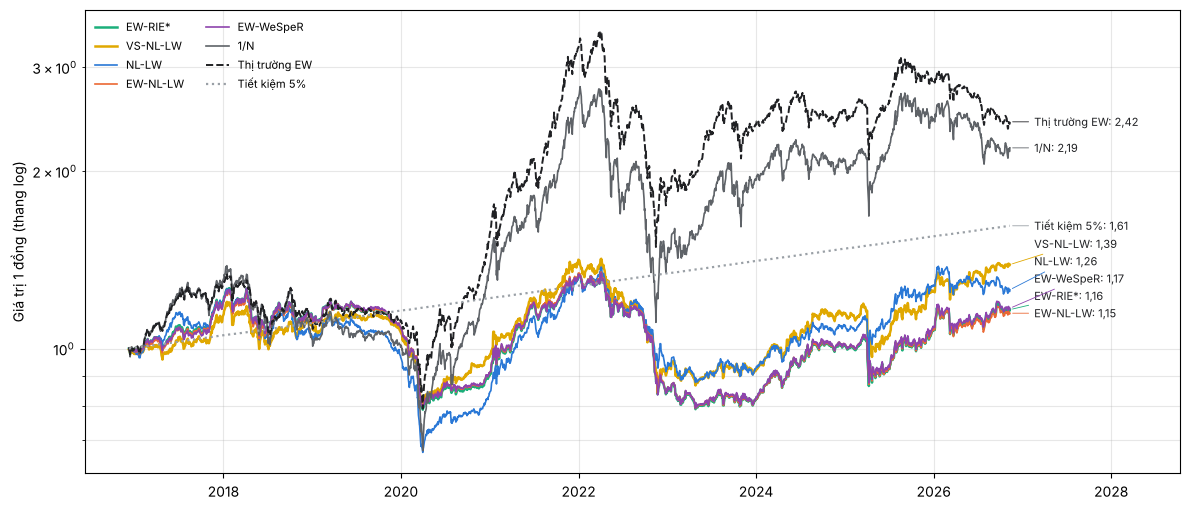

**Hình 18.** Giá trị 1 đồng đầu tư, thang log: 6 phương pháp (chỉ mua, REB = 21, NAV ròng sau phí và thuế), Thị trường EW (thay VN-Index, không phí) và tiết kiệm 5%/năm (giả định). Nhãn cuối đường: giá trị cuối kỳ.

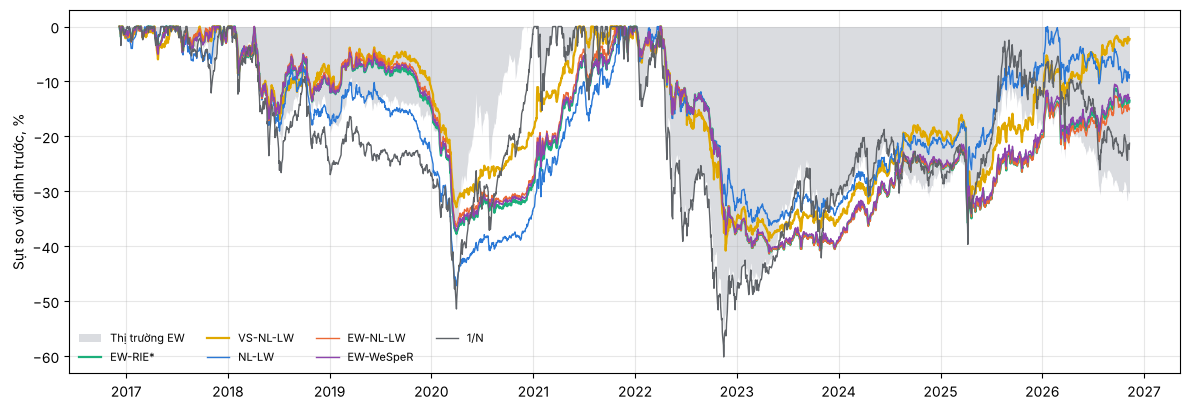

**Hình 19.** Mức sụt so với đỉnh trước (drawdown, %) của NAV ròng, chỉ mua; nền xám: Thị trường EW.

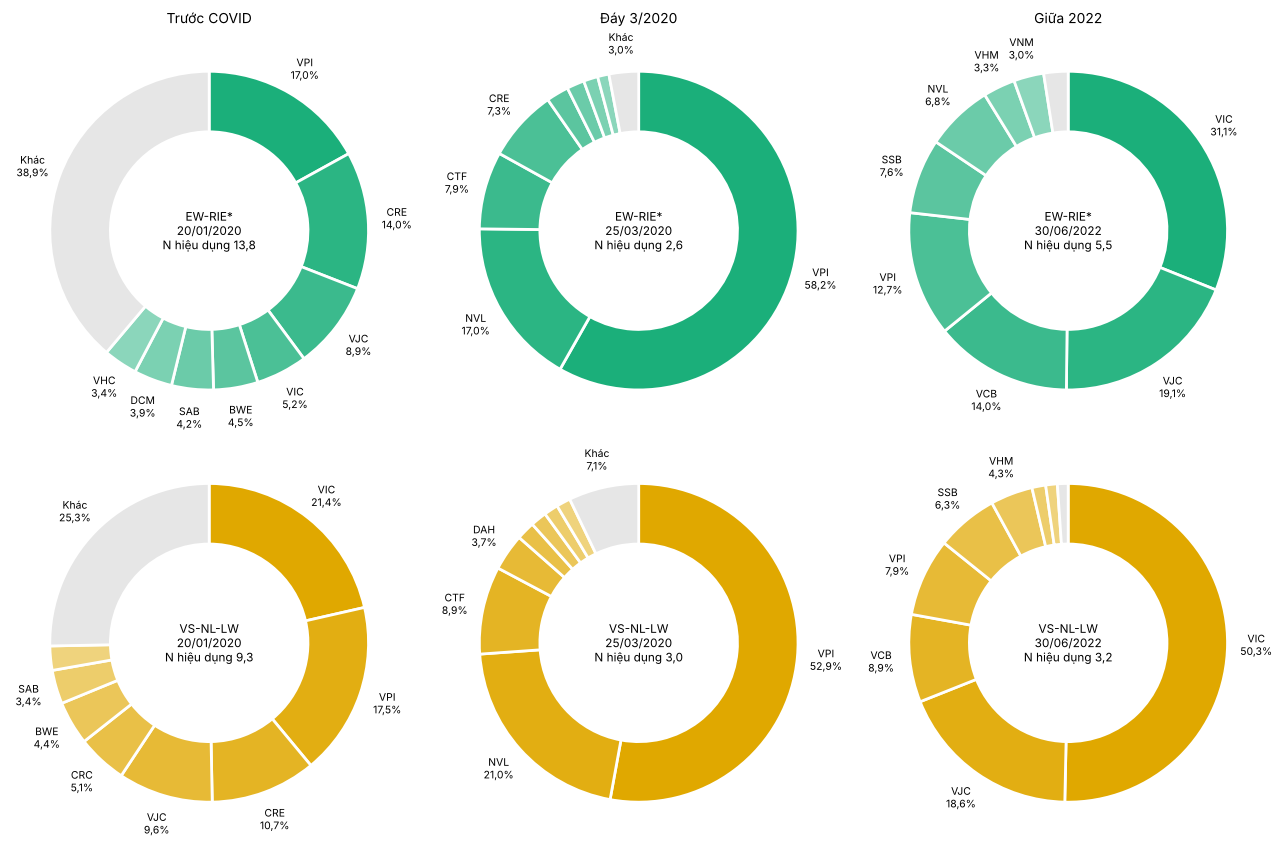

**Hình 20.** Tỷ trọng đích chỉ mua của EW-RIE\* (trên) và VS-NL-LW (dưới) tại ba kỳ định trước: kỳ cuối trước 22/01/2020, kỳ gần đáy Thị trường EW (31/03/2020) nhất, kỳ gần 30/06/2022 nhất; 8 mã lớn nhất + nhóm Khác. Màu chỉ để phân đoạn, tên mã ghi trực tiếp.

**Kết quả.** Sau phí và thuế, EW-RIE\* tăng 1,56%/năm (MDD -41,33%, Calmar 0,04), VS-NL-LW 3,39%/năm (MDD -40,79%, Calmar 0,08); Thị trường EW 9,43%/năm (MDD -56,95%); tiết kiệm 5,00%/năm. Phương pháp có CAGR cao hơn Thị trường EW: không có. ΔVol EW-RIE\* − VS-NL-LW = +0,13 pp (p 0,594); phí chuyển sang EW-RIE\* ở γ = 5: -185,6 bps/năm (cùng TB -8,3 bps/năm, CI [-41,7; 21,0]). Donut: tỷ trọng 8 mã lớn nhất của EW-RIE\* 61%, 97%, 98% so với VS-NL-LW 75%, 93%, 99% (ba mốc).

**Kết luận (theo ngưỡng đăng ký trước).** H1a (EW-RIE\* rủi ro thấp hơn VS-NL-LW): không đạt. H1b (giá trị kinh tế đáng kể ≥ 25 bps/năm và CI không chứa 0, γ = 5): không đạt ở bản cùng TB; bản lợi suất thực -185,6 bps/năm chủ yếu phản ánh chênh lệch lợi suất trung bình (CI [-503,6; 114,2]). H1c: nhóm ít biến động **chưa đủ bằng chứng** khác thị trường (chênh TB +1,81 pp/năm, p HAC 0,637, chênh CAGR +3,05 pp); trong top-100: **chưa đủ bằng chứng** khác thị trường (chênh TB +2,83 pp/năm, p HAC 0,517, chênh CAGR +4,44 pp).

**Đào sâu (mô tả, không đăng ký trước).** Nhóm ít biến động không tăng kém thị trường, vậy lợi suất thấp của GMV chỉ mua không đến từ "cổ phiếu ít biến động tăng chậm" nói chung mà từ **độ tập trung**: EW-RIE*: 12 mã có tỷ trọng TB lớn nhất chiếm 59% danh mục (lớn nhất VPI 15,5%), đóng góp 2,41/1,31 %/năm; kéo lùi nhiều nhất NVL -1,80 %/năm (tỷ trọng TB 5,1%), CRE -0,83 %/năm (tỷ trọng TB 1,3%). VS-NL-LW: 12 mã có tỷ trọng TB lớn nhất chiếm 57% danh mục (lớn nhất VPI 13,4%), đóng góp 3,71/4,24 %/năm; kéo lùi nhiều nhất NVL -1,54 %/năm (tỷ trọng TB 4,7%), CRE -0,81 %/năm (tỷ trọng TB 1,0%). Đối chứng cùng universe: Q1 trong top-100 (20 mã chia đều, chưa phí) có CAGR 13,09%/năm, Vol 16,65% ⇒ GMV giảm thêm ~3,7 pp Vol nhưng mất ~11,5 pp CAGR mỗi năm. Hàm ý cho nhà đầu tư dài hạn: Vol thấp của GMV trên HOSE đổi bằng lợi suất rất thấp; Hướng 4 kiểm tra trần tỷ trọng có cải thiện điều này không.

In [65]:
from matplotlib.colors import to_rgb
# ---- 7.1 Hướng 1: Hình 18 (tài sản, thang log), Hình 19 (sụt giảm), Hình 20 (donut tỷ trọng), Kết quả & Kết luận ----
LINE = {"Thị trường EW": dict(color=COL["Thị trường EW"], ls="--", lw=1.4), "Tiết kiệm 5%": dict(color=COL["Tiết kiệm 5%"], ls=":", lw=1.6)}
SER1 = {**{nm: R1[nm] for nm in M7}, "Thị trường EW": RG["mk"], "Tiết kiệm 5%": R_SAV}
fig, ax = plt.subplots(figsize=(12, 5.2)); ends = []
for nm, r in SER1.items():
    nav = (1 + r).cumprod(); st = LINE.get(nm, dict(color=col_of(nm), lw=1.8 if nm in ("EW-RIE*", "VS-NL-LW") else 1.2))
    ax.plot(nav.index, nav.values, label=nm, **st); ends.append((nav.iloc[-1], nm, st["color"]))
ax.set_yscale("log"); ax.set_ylabel("Giá trị 1 đồng (thang log)"); ax.grid(alpha=.3, which="both")
x_end = SER1["EW-RIE*"].index[-1]; prev = None
for v, nm, c in sorted(ends):                                    # nhãn trực tiếp ở mép phải, giãn theo thang log để không đè nhau
    y = v if prev is None else max(v, prev * 1.07); prev = y
    ax.annotate(f"{nm}: {f2(v)}", xy=(x_end, v), xytext=(x_end + pd.Timedelta(days=100), y), fontsize=8, va="center", color="#202124",
                arrowprops=dict(arrowstyle="-", color=c, lw=.6), annotation_clip=False)
ax.legend(loc="upper left", fontsize=8, ncol=2, frameon=False); ax.set_xlim(right=SER1["EW-RIE*"].index[-1] + pd.Timedelta(days=700))
plt.tight_layout(); savefig7(fig, "fig_18_tai_san_log")
cap("Hình", "Giá trị 1 đồng đầu tư, thang log: 6 phương pháp (chỉ mua, REB = 21, NAV ròng sau phí và thuế), Thị trường EW (thay VN-Index, không phí) "
    "và tiết kiệm 5%/năm (giả định). Nhãn cuối đường: giá trị cuối kỳ.")

fig, ax = plt.subplots(figsize=(12, 4.2))
mk = (1 + RG["mk"]).cumprod(); ddm = mk / mk.cummax() - 1
ax.fill_between(ddm.index, ddm.values * 100, 0, color="#dadce0", label="Thị trường EW", lw=0)
for nm in M7:
    nav = (1 + R1[nm]).cumprod(); dd = nav / nav.cummax() - 1
    ax.plot(dd.index, dd.values * 100, color=col_of(nm), lw=1.6 if nm in ("EW-RIE*", "VS-NL-LW") else 1.0, label=nm)
ax.set_ylabel("Sụt so với đỉnh trước, %"); ax.grid(alpha=.3); ax.legend(fontsize=8, ncol=4, frameon=False, loc="lower left")
plt.tight_layout(); savefig7(fig, "fig_19_sut_giam")
cap("Hình", "Mức sụt so với đỉnh trước (drawdown, %) của NAV ròng, chỉ mua; nền xám: Thị trường EW.")

# donut: ngày định trước (đăng ký trước): kỳ cuối ≤ 22/01/2020; kỳ gần đáy Thị trường EW (2–4/2020) nhất; kỳ gần 30/06/2022 nhất
reb = pd.DatetimeIndex(REB_DATES); m20 = mk.loc["2020-02-01":"2020-04-30"]; T_TROUGH20 = m20.idxmin()
D_DON = {"Trước COVID": reb[reb <= "2020-01-22"][-1], "Đáy 3/2020": reb[np.argmin(np.abs(reb - T_TROUGH20))],
         "Giữa 2022": reb[np.argmin(np.abs(reb - pd.Timestamp("2022-06-30")))]}
fig, axs = plt.subplots(2, 3, figsize=(13, 8.6)); DON = []
for i, nm in enumerate(["EW-RIE*", "VS-NL-LW"]):
    for j, (lab, d) in enumerate(D_DON.items()):
        ix, Wm = TG[nm][POS[d]]; w = pd.Series(Wm[0], index=TICK7[ix]).sort_values(ascending=False); top = w.iloc[:8]
        vals = list(top.values) + [1 - top.sum()]; names = list(top.index) + ["Khác"]
        base = to_rgb(col_of(nm)); shades = [tuple(1 - (1 - c) * (1 - .07 * k) for c in base) for k in range(8)] + [(.9, .9, .9)]
        a = axs[i, j]; wd, _ = a.pie(vals, colors=shades, startangle=90, counterclock=False, wedgeprops=dict(width=.38, edgecolor="white", linewidth=2))
        for wdg, n_, v in zip(wd, names, vals):
            if v < .025: continue
            ang = np.deg2rad((wdg.theta1 + wdg.theta2) / 2); a.text(1.18 * np.cos(ang), 1.18 * np.sin(ang), f"{n_}\n{f2(100 * v, 1)}%", ha="center", va="center", fontsize=7.5)
        neff = 1 / (Wm[0] ** 2).sum(); a.text(0, 0, f"{nm}\n{d:%d/%m/%Y}\nN hiệu dụng {f2(neff, 1)}", ha="center", va="center", fontsize=8.5)
        a.set_title(lab if i == 0 else "", fontsize=10); DON.append(dict(pp=nm, moc=lab, ngay=d.date(), top8=top.sum(), neff=neff, top=", ".join(top.index[:3])))
plt.tight_layout(); savefig7(fig, "fig_20_donut")
DON = pd.DataFrame(DON); save7(DON, "H1_donut")
cap("Hình", f"Tỷ trọng đích chỉ mua của EW-RIE\\* (trên) và VS-NL-LW (dưới) tại ba kỳ định trước: kỳ cuối trước 22/01/2020, kỳ gần đáy Thị trường EW "
    f"({T_TROUGH20:%d/%m/%Y}) nhất, kỳ gần 30/06/2022 nhất; 8 mã lớn nhất + nhóm Khác. Màu chỉ để phân đoạn, tên mã ghi trực tiếp.")

# ---- Kết quả & kết luận (sinh từ số liệu; ngưỡng đã đăng ký trước trong PROGRESS.md) ----
e, v_ = T35.loc["EW-RIE*"], T35.loc["VS-NL-LW"]; mrow, s_ = T35.loc["Thị trường EW"], T35.loc["Tiết kiệm 5%"]
p1 = T36.loc["VS-NL-LW", "p LW-boot"]; fee5, fee5e = T36.loc["VS-NL-LW", "γ = 5"], T36.loc["VS-NL-LW", "γ = 5 (cùng TB)"]
H1C = {}
for lab, q, b in (("mọi mã đủ điều kiện", "q1", "mk"), ("top-100", "q1t", "1/N gộp")):
    dlt, p = nw_mean_test(RG[q].values - RG[b].values); H1C[lab] = (dlt * 252 * 100, p, perf7(RG[q])["CAGR %"] - perf7(RG[b])["CAGR %"])
def _h1c(lab):
    d_, p_, dc = H1C[lab]
    v = "tăng **kém** thị trường" if (d_ < 0 and p_ < .05) else ("tăng **hơn** thị trường" if (d_ > 0 and p_ < .05) else "**chưa đủ bằng chứng** khác thị trường")
    return v, f"chênh TB {dv(d_)} pp/năm, p HAC {pv(p_)}, chênh CAGR {dv(dc)} pp"
beat = [nm for nm in M7 if T35.loc[nm, "CAGR %"] > mrow["CAGR %"]]
md(f"**Kết quả.** Sau phí và thuế, EW-RIE\\* tăng {f2(e['CAGR %'])}%/năm (MDD {f2(e['MDD %'])}%, Calmar {f2(e['Calmar'])}), VS-NL-LW {f2(v_['CAGR %'])}%/năm "
   f"(MDD {f2(v_['MDD %'])}%, Calmar {f2(v_['Calmar'])}); Thị trường EW {f2(mrow['CAGR %'])}%/năm (MDD {f2(mrow['MDD %'])}%); tiết kiệm {f2(s_['CAGR %'])}%/năm. "
   f"Phương pháp có CAGR cao hơn Thị trường EW: {', '.join(beat) if beat else 'không có'}. "
   f"ΔVol EW-RIE\\* − VS-NL-LW = {dv(T36.loc['VS-NL-LW', 'ΔVol (pp)'])} pp (p {pv(p1)}); phí chuyển sang EW-RIE\\* ở γ = 5: {f2(fee5, 1)} bps/năm "
   f"(cùng TB {f2(fee5e, 1)} bps/năm, CI [{f2(CI36[True][0], 1)}; {f2(CI36[True][1], 1)}]). Donut: tỷ trọng 8 mã lớn nhất của EW-RIE\\* "
   + ", ".join(f"{f2(100 * r.top8, 0)}%" for r in DON[DON.pp == 'EW-RIE*'].itertuples()) + " so với VS-NL-LW "
   + ", ".join(f"{f2(100 * r.top8, 0)}%" for r in DON[DON.pp == 'VS-NL-LW'].itertuples()) + " (ba mốc).\n\n"
   f"**Kết luận (theo ngưỡng đăng ký trước).** H1a (EW-RIE\\* rủi ro thấp hơn VS-NL-LW): "
   f"{'đạt' if (T36.loc['VS-NL-LW', 'ΔVol (pp)'] < 0 and p1 < .05) else 'không đạt'}. H1b (giá trị kinh tế đáng kể ≥ 25 bps/năm và CI không chứa 0, γ = 5): "
   f"{'đạt' if (fee5e >= 25 and CI36[True][0] > 0) else 'không đạt'} ở bản cùng TB; bản lợi suất thực {f2(fee5, 1)} bps/năm chủ yếu phản ánh chênh lệch lợi suất trung bình "
   f"(CI [{f2(CI36[False][0], 1)}; {f2(CI36[False][1], 1)}]). H1c: nhóm ít biến động {_h1c('mọi mã đủ điều kiện')[0]} ({_h1c('mọi mã đủ điều kiện')[1]}); "
   f"trong top-100: {_h1c('top-100')[0]} ({_h1c('top-100')[1]}).")

# ---- Đào sâu (mô tả, KHÔNG đăng ký trước): vì sao GMV chỉ mua tăng chậm dù nhóm ít biến động không tăng kém? ----
def contrib7(nm):
    # đóng góp xấp xỉ của từng mã: Σ tỷ trọng đích × lợi suất ngày (không trôi, như run_backtest), %/năm; tỷ trọng đích TB qua 118 kỳ
    c, ws = np.zeros(len(TICK7)), np.zeros(len(TICK7))
    for i, s in enumerate(S_REG):
        e = S_REG[i + 1] if i + 1 < len(S_REG) else END7; ix, Wm = TG[nm][s]; c[ix] += (RH[s:e][:, ix] * Wm[0]).sum(0); ws[ix] += Wm[0]
    return pd.DataFrame({"đóng góp %/năm": c / yrs * 100, "tỷ trọng TB %": ws / len(S_REG) * 100}, index=TICK7)
CB = {nm: contrib7(nm) for nm in ("EW-RIE*", "VS-NL-LW")}; save7(pd.concat(CB, axis=1).loc[lambda d: d.abs().sum(1) > 0], "H1_dong_gop_ma")
def _dig(nm):
    d = CB[nm]; t12 = d["tỷ trọng TB %"].nlargest(12); big = d["tỷ trọng TB %"].idxmax(); neg = d["đóng góp %/năm"].nsmallest(2)
    return (f"{nm}: 12 mã có tỷ trọng TB lớn nhất chiếm {f2(t12.sum(), 0)}% danh mục (lớn nhất {big} {f2(d.loc[big, 'tỷ trọng TB %'], 1)}%), "
            f"đóng góp {f2(d.loc[t12.index, 'đóng góp %/năm'].sum())}/{f2(d['đóng góp %/năm'].sum())} %/năm; kéo lùi nhiều nhất "
            + ", ".join(f"{t} {f2(v)} %/năm (tỷ trọng TB {f2(d.loc[t, 'tỷ trọng TB %'], 1)}%)" for t, v in neg.items()))
q1t = T35.loc["Q1 ít biến động (top-100)"]
md(f"**Đào sâu (mô tả, không đăng ký trước).** Nhóm ít biến động không tăng kém thị trường, vậy lợi suất thấp của GMV chỉ mua không đến từ \"cổ phiếu ít biến động "
   f"tăng chậm\" nói chung mà từ **độ tập trung**: {_dig('EW-RIE*')}. {_dig('VS-NL-LW')}. Đối chứng cùng universe: Q1 trong top-100 (20 mã chia đều, chưa phí) "
   f"có CAGR {f2(q1t['CAGR %'])}%/năm, Vol {f2(q1t['Vol %'])}% ⇒ GMV giảm thêm ~{f2(q1t['Vol %'] - e['Vol %'], 1)} pp Vol nhưng mất ~{f2(q1t['CAGR %'] - e['CAGR %'], 1)} pp "
   f"CAGR mỗi năm. Hàm ý cho nhà đầu tư dài hạn: Vol thấp của GMV trên HOSE đổi bằng lợi suất rất thấp; Hướng 4 kiểm tra trần tỷ trọng có cải thiện điều này không.")

### 7.2 Hướng 2 – Tái cân bằng thưa

**Câu hỏi.** Nhà đầu tư dài hạn muốn giao dịch ít: tái cân bằng mỗi 21, 63, 126 hay 252 phiên, có hoặc không có vùng không giao dịch (0, 1%, 2% theo từng mã), thì rủi ro, lợi suất ròng, turnover và chi phí thay đổi ra sao? EW-RIE\* có lợi hơn VS-NL-LW khi REB dài không?

**Cách làm.** Cùng tỷ trọng đích như REB = 21 (lấy mỗi REB/21 kỳ), cùng mẫu ngày. Vùng không giao dịch: mã có |đích − hiện| ≤ vùng thì giữ nguyên, phần còn lại về đích rồi co giãn cho tổng = 1. Kiểm thêm mọi pha của lịch (REB = 252 có 12 cách chọn ngày bắt đầu).

**Giả thuyết (đăng ký trước).** H2: REB càng dài, EW-RIE\* càng có lợi so với VS-NL-LW. Ủng hộ nếu ở vùng 0, ΔVol(EW-RIE\* − VS-NL-LW) giảm đơn điệu theo REB, ΔVol(252) − ΔVol(21) ≤ −0,10 pp và trung bình theo pha cùng chiều; "ủng hộ mạnh" nếu thêm một ô REB ≥ 126 có p Holm < 0,05; bác bỏ nếu ΔVol(252) ≥ ΔVol(21).

**Bảng 37.** Tái cân bằng thưa, chỉ mua, không có vùng không giao dịch: Vol (%/năm) và CAGR ròng (%/năm, sau phí mua 0,15% / bán 0,25%) theo chu kỳ tái cân bằng REB (phiên). Cùng tỷ trọng đích như REB = 21 (lấy mỗi REB/21 kỳ), cùng mẫu ngày; đậm: Vol thấp nhất mỗi cột REB.

**Bảng 38.** EW-RIE\* (E) so với VS-NL-LW (V, HL_VOL = 20) theo REB × vùng không giao dịch (theo từng mã): ΔVol = Vol(E) − Vol(V), pp/năm; p Ledoit–Wolf (2011) bootstrap khối, Holm trên 12 ô; ΔCAGR ròng; turnover một chiều và chi phí (%/năm) của từng bộ; ΔVol so với VS-NL-LW HL_VOL 10, 40 (mô tả); ở vùng 0: ΔVol trung bình và khoảng qua mọi pha của lịch (REB = 63: 3 pha, 126: 6, 252: 12).

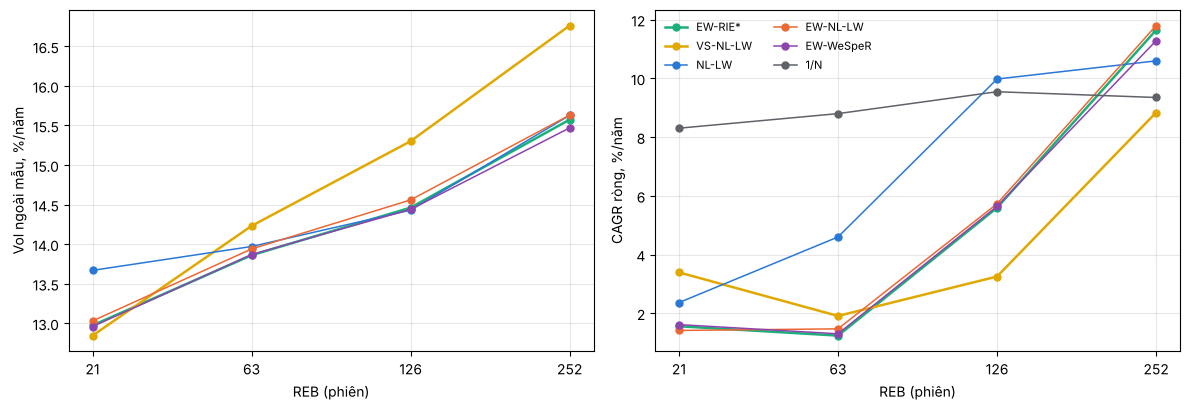

**Hình 21.** Vol (trái) và CAGR ròng (phải) theo chu kỳ tái cân bằng, 6 phương pháp, chỉ mua, vùng không giao dịch 0 (số ở Bảng 37; khung Vol không vẽ 1/N ≈ 22%).

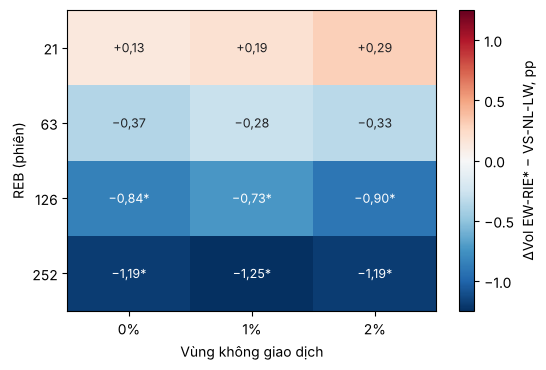

**Hình 22.** ΔVol EW-RIE\* − VS-NL-LW (pp/năm) theo REB × vùng không giao dịch, chỉ mua; xanh: EW-RIE\* rủi ro thấp hơn; * = p Holm < 0,05 (12 ô).

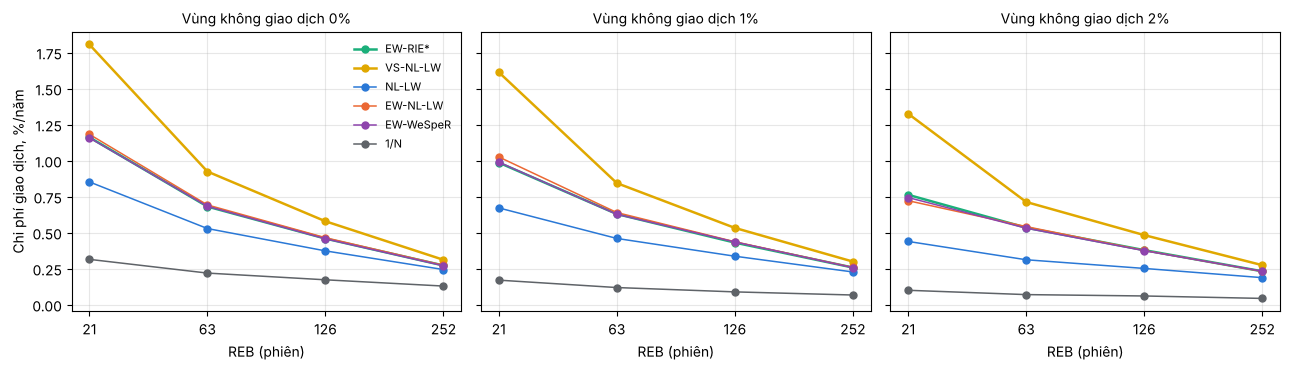

**Hình 23.** Chi phí giao dịch thực tế (%/năm NAV, phí mua 0,15% / bán 0,25%) theo REB, ba mức vùng không giao dịch, chỉ mua.

**Kết quả.** Ở vùng 0, ΔVol EW-RIE\* − VS-NL-LW theo REB 21/63/126/252: +0,13 / −0,37 / −0,84 / −1,19 pp (trung bình theo pha: +0,13 / −0,24 / −0,64 / −0,64 pp; khoảng pha ở REB 252: [−1,70; +0,09]). Số ô p Holm < 0,05: 6/12. Vol của EW-RIE\* tăng từ 12,97% (REB 21) lên 15,57% (REB 252); chi phí giảm từ 1,16 xuống 0,27 %/năm. Vùng 2% ở REB 21 cắt chi phí EW-RIE\* còn 0,76 %/năm với Vol 13,37%.

**Kết luận (theo ngưỡng đăng ký trước).** Giả thuyết "REB càng dài EW-RIE\* càng có lợi so với VS-NL-LW": **ủng hộ mạnh** (giảm đơn điệu: có; ΔVol(252) − ΔVol(21) = −1,32 pp; theo pha cùng chiều: có; ô REB ≥ 126 có ý nghĩa: có).

**Đào sâu (mô tả, không đăng ký trước).** (1) *Pha của lịch*: số pha có ΔVol < 0 với p < 0,05 (chưa Holm) ở REB 63/126/252: 1/3 / 3/6 / 6/12. CAGR trung bình theo pha của EW-RIE\*: 1,56 (REB 21) / 2,96 / 5,39 / 7,11 %/năm; ở REB 252 dao động [2,29; 11,65] ⇒ pha 0 (11,65%) là pha may; chiều "REB dài ⇒ CAGR cao hơn" vẫn đúng ở trung bình theo pha nhưng độ lớn phụ thuộc mạnh vào ngày tái cân bằng. (2) *VS với half-life dài hơn*: so với VS-NL-LW HL_VOL 40, ΔVol của EW-RIE\* ở REB 126/252 chỉ còn −0,17 (p 0,065) / −0,59 (p < 0,001) pp — một phần lợi thế đến từ việc HL_VOL = 20 quá ngắn cho kỳ nắm giữ dài. (3) *Không riêng EW-RIE\**: ở REB 252, NL-LW (cửa sổ phẳng) Vol 15,63%, EW-NL-LW 15,63%, EW-WeSpeR 15,47% ≈ EW-RIE\* 15,57% ⇒ điều quan sát được là **VS (chuẩn hóa theo biến động ngắn hạn) yếu đi khi nắm giữ dài**, không phải EW-RIE\* mạnh lên.

In [66]:
# ---- 7.2 Hướng 2: tái cân bằng thưa — REB ∈ {21, 63, 126, 252} × vùng không giao dịch ∈ {0, 1%, 2%}; Bảng 37, 38; Hình 21–23 ----
REBS, BANDS = (21, 63, 126, 252), (0.0, 0.01, 0.02)
def sched7(K, phase=0):
    # lịch REB = K: mỗi K/21 kỳ của lịch 21 (cùng tỷ trọng đích); pha p > 0 vẫn mua ban đầu ở kỳ đầu ⇒ mọi lịch cùng mẫu ngày
    st = S_REG[phase::K // 21]; return st if phase == 0 else [S_REG[0]] + st
SIM2 = {(nm, K, b): simulate(TG[nm], sched7(K), "lo", band=b) for nm in M7X for K in REBS for b in BANDS}
PH2 = {(nm, K, p): simulate(TG[nm], sched7(K, p), "lo")[0] for nm in ("EW-RIE*", "VS-NL-LW") for K in REBS for p in range(K // 21)}
pd.to_pickle({"SIM2": {k: v[0] for k, v in SIM2.items()}, "PH2": PH2}, f"{R7}/H2_returns.pkl")
P2 = {k: perf7(*v) for k, v in SIM2.items()}

V37 = pd.DataFrame({(f"REB {K}", c): {nm: P2[(nm, K, 0.0)][c] for nm in M7X} for c in ("Vol %", "CAGR %") for K in REBS})
V37 = V37[[(f"REB {K}", c) for K in REBS for c in ("Vol %", "CAGR %")]]; save7(V37, "H2_vol_cagr")
cap("Bảng", "Tái cân bằng thưa, chỉ mua, không có vùng không giao dịch: Vol (%/năm) và CAGR ròng (%/năm, sau phí mua 0,15% / bán 0,25%) theo chu kỳ "
    "tái cân bằng REB (phiên). Cùng tỷ trọng đích như REB = 21 (lấy mỗi REB/21 kỳ), cùng mẫu ngày; đậm: Vol thấp nhất mỗi cột REB.")
display(V37.style.format(precision=2, decimal=",").highlight_min(subset=[(f"REB {K}", "Vol %") for K in REBS], axis=0, props="font-weight: bold"))

rows = []
for K in REBS:
    for b in BANDS:
        rE, lE = SIM2[("EW-RIE*", K, b)]; rV, lV = SIM2[("VS-NL-LW", K, b)]; dv_, p_hac, p_bt = lw7(rE, rV)
        row = {"REB": K, "Vùng %": int(round(b * 100)), "ΔVol (pp)": dv_, "p LW-boot": p_bt, "ΔCAGR (pp)": P2[("EW-RIE*", K, b)]["CAGR %"] - P2[("VS-NL-LW", K, b)]["CAGR %"],
               "Turnover/năm E %": P2[("EW-RIE*", K, b)]["Turnover/năm %"], "Turnover/năm V %": P2[("VS-NL-LW", K, b)]["Turnover/năm %"],
               "Chi phí E %/năm": P2[("EW-RIE*", K, b)]["Chi phí %/năm"], "Chi phí V %/năm": P2[("VS-NL-LW", K, b)]["Chi phí %/năm"],
               "ΔVol vs HL 10": (rE.std() - SIM2[("VS-NL-LW (HL 10)", K, b)][0].std()) * np.sqrt(252) * 100,
               "ΔVol vs HL 40": (rE.std() - SIM2[("VS-NL-LW (HL 40)", K, b)][0].std()) * np.sqrt(252) * 100}
        if b == 0:
            dph = [(PH2[("EW-RIE*", K, p)].std() - PH2[("VS-NL-LW", K, p)].std()) * np.sqrt(252) * 100 for p in range(K // 21)]
            row.update({"ΔVol TB pha": np.mean(dph), "pha min": np.min(dph), "pha max": np.max(dph)})
        rows.append(row)
T38 = pd.DataFrame(rows); T38.insert(4, "p Holm", holm(T38["p LW-boot"].values)); T38 = T38.set_index(["REB", "Vùng %"]); save7(T38, "H2_cap_E_V")
cap("Bảng", "EW-RIE\\* (E) so với VS-NL-LW (V, HL_VOL = 20) theo REB × vùng không giao dịch (theo từng mã): ΔVol = Vol(E) − Vol(V), pp/năm; "
    "p Ledoit–Wolf (2011) bootstrap khối, Holm trên 12 ô; ΔCAGR ròng; turnover một chiều và chi phí (%/năm) của từng bộ; ΔVol so với VS-NL-LW HL_VOL 10, 40 (mô tả); "
    "ở vùng 0: ΔVol trung bình và khoảng qua mọi pha của lịch (REB = 63: 3 pha, 126: 6, 252: 12).")
display(T38.style.format(precision=2, decimal=",", thousands=" ", na_rep="–").format(pv, subset=[c for c in T38.columns if str(c).startswith("p ")]))

fig, axs = plt.subplots(1, 2, figsize=(12, 4.2))
XR = np.arange(len(REBS))                                  # trục REB dạng hạng mục (21, 63, 126, 252)
for nm in M7:
    for a, c in zip(axs, ("Vol %", "CAGR %")):
        if c == "Vol %" and nm == "1/N": continue               # 1/N ~22%: bỏ khỏi khung Vol để giữ thang (số ở Bảng 37)
        a.plot(XR, [P2[(nm, K, 0.0)][c] for K in REBS], marker="o", ms=5, color=col_of(nm), lw=1.8 if nm in ("EW-RIE*", "VS-NL-LW") else 1.1, label=nm)
for a, c in zip(axs, ("Vol ngoài mẫu, %/năm", "CAGR ròng, %/năm")):
    a.set_xticks(XR); a.set_xticklabels(REBS); a.set_xlabel("REB (phiên)"); a.set_ylabel(c); a.grid(alpha=.3)
axs[1].legend(fontsize=8, frameon=False, ncol=2); plt.tight_layout(); savefig7(fig, "fig_21_reb_vol_cagr")
cap("Hình", "Vol (trái) và CAGR ròng (phải) theo chu kỳ tái cân bằng, 6 phương pháp, chỉ mua, vùng không giao dịch 0 (số ở Bảng 37; khung Vol không vẽ 1/N ≈ 22%).")

D = T38["ΔVol (pp)"].unstack("Vùng %"); Pm = T38["p Holm"].unstack("Vùng %"); vm = max(.3, np.abs(D.values).max())
fig, ax = plt.subplots(figsize=(5.6, 3.8)); im = ax.imshow(D.values, cmap="RdBu_r", vmin=-vm, vmax=vm, aspect="auto")
for i in range(D.shape[0]):
    for j in range(D.shape[1]):
        ax.text(j, i, dv(D.values[i, j]) + ("*" if Pm.values[i, j] < .05 else ""), ha="center", va="center", fontsize=9,
                color="white" if abs(D.values[i, j]) > .55 * vm else "#202124")
ax.set_xticks(range(D.shape[1])); ax.set_xticklabels([f"{f2(c, 0)}%" for c in D.columns]); ax.set_yticks(range(D.shape[0])); ax.set_yticklabels(D.index)
ax.set_xlabel("Vùng không giao dịch"); ax.set_ylabel("REB (phiên)"); fig.colorbar(im, ax=ax, label="ΔVol EW-RIE* − VS-NL-LW, pp"); plt.tight_layout()
savefig7(fig, "fig_22_heat_reb_vung")
cap("Hình", "ΔVol EW-RIE\\* − VS-NL-LW (pp/năm) theo REB × vùng không giao dịch, chỉ mua; xanh: EW-RIE\\* rủi ro thấp hơn; * = p Holm < 0,05 (12 ô).")

fig, axs = plt.subplots(1, len(BANDS), figsize=(13, 3.8), sharey=True)
for a, b in zip(axs, BANDS):
    for nm in M7:
        a.plot(XR, [P2[(nm, K, b)]["Chi phí %/năm"] for K in REBS], marker="o", ms=5, color=col_of(nm), lw=1.8 if nm in ("EW-RIE*", "VS-NL-LW") else 1.1, label=nm)
    a.set_xticks(XR); a.set_xticklabels(REBS); a.set_title(f"Vùng không giao dịch {f2(100 * b, 0)}%", fontsize=10)
    a.set_xlabel("REB (phiên)"); a.grid(alpha=.3)
axs[0].set_ylabel("Chi phí giao dịch, %/năm"); axs[0].legend(fontsize=8, frameon=False); plt.tight_layout(); savefig7(fig, "fig_23_chi_phi")
cap("Hình", "Chi phí giao dịch thực tế (%/năm NAV, phí mua 0,15% / bán 0,25%) theo REB, ba mức vùng không giao dịch, chỉ mua.")

d0 = T38.xs(0, level="Vùng %")["ΔVol (pp)"]; ph = T38.xs(0, level="Vùng %")["ΔVol TB pha"]
mono = bool(np.all(np.diff(d0.values) < 0)); drop = d0.loc[252] - d0.loc[21]; mono_ph = bool(ph.loc[252] - ph.loc[21] < 0)        # (iii) trung bình theo pha cùng chiều giảm
strong = bool(((T38.reset_index()["REB"] >= 126) & (T38.reset_index()["ΔVol (pp)"] < 0) & (T38.reset_index()["p Holm"] < .05)).any())
H2V = ("bác bỏ" if drop >= 0 else ("ủng hộ mạnh" if (mono and drop <= -.10 and mono_ph and strong) else ("ủng hộ" if (mono and drop <= -.10 and mono_ph) else "không kết luận")))
cheap = {nm: P2[(nm, 252, 0.0)]["Chi phí %/năm"] for nm in M7}
md(f"**Kết quả.** Ở vùng 0, ΔVol EW-RIE\\* − VS-NL-LW theo REB 21/63/126/252: {' / '.join(dv(x) for x in d0.values)} pp "
   f"(trung bình theo pha: {' / '.join(dv(x) for x in ph.values)} pp; khoảng pha ở REB 252: [{dv(T38.loc[(252, 0), 'pha min'])}; {dv(T38.loc[(252, 0), 'pha max'])}]). "
   f"Số ô p Holm < 0,05: {int((T38['p Holm'] < .05).sum())}/12. Vol của EW-RIE\\* tăng từ {f2(P2[('EW-RIE*', 21, 0.0)]['Vol %'])}% (REB 21) lên "
   f"{f2(P2[('EW-RIE*', 252, 0.0)]['Vol %'])}% (REB 252); chi phí giảm từ {f2(P2[('EW-RIE*', 21, 0.0)]['Chi phí %/năm'])} xuống "
   f"{f2(P2[('EW-RIE*', 252, 0.0)]['Chi phí %/năm'])} %/năm. Vùng 2% ở REB 21 cắt chi phí EW-RIE\\* còn {f2(P2[('EW-RIE*', 21, 0.02)]['Chi phí %/năm'])} %/năm "
   f"với Vol {f2(P2[('EW-RIE*', 21, 0.02)]['Vol %'])}%.\n\n"
   f"**Kết luận (theo ngưỡng đăng ký trước).** Giả thuyết \"REB càng dài EW-RIE\\* càng có lợi so với VS-NL-LW\": **{H2V}** "
   f"(giảm đơn điệu: {'có' if mono else 'không'}; ΔVol(252) − ΔVol(21) = {dv(drop)} pp; theo pha cùng chiều: {'có' if mono_ph else 'không'}; "
   f"ô REB ≥ 126 có ý nghĩa: {'có' if strong else 'không'}).")

# ---- Đào sâu (mô tả, KHÔNG đăng ký trước): pha của lịch, VS half-life dài hơn, và vai trò của chính EW-RIE* ----
PHT = []
for K in (63, 126, 252):
    for p in range(K // 21):
        rE, rV = PH2[("EW-RIE*", K, p)], PH2[("VS-NL-LW", K, p)]; d_, _, pb = lw7(rE, rV)
        PHT.append({"REB": K, "pha": p, "ΔVol (pp)": d_, "p LW-boot": pb, "CAGR E %": perf7(rE)["CAGR %"], "CAGR V %": perf7(rV)["CAGR %"]})
PHT = pd.DataFrame(PHT); save7(PHT, "H2_pha")
g = PHT.groupby("REB"); sig = g.apply(lambda d: f"{int(((d['ΔVol (pp)'] < 0) & (d['p LW-boot'] < .05)).sum())}/{len(d)}")
cg = g[["CAGR E %", "CAGR V %"]].agg(["mean", "min", "max"])
H40 = {K: lw7(SIM2[("EW-RIE*", K, 0.0)][0], SIM2[("VS-NL-LW (HL 40)", K, 0.0)][0]) for K in (126, 252)}
md(f"**Đào sâu (mô tả, không đăng ký trước).** (1) *Pha của lịch*: số pha có ΔVol < 0 với p < 0,05 (chưa Holm) ở REB 63/126/252: {' / '.join(sig.values)}. "
   f"CAGR trung bình theo pha của EW-RIE\\*: {f2(P2[('EW-RIE*', 21, 0.0)]['CAGR %'])} (REB 21) / " + " / ".join(f2(cg.loc[K, ('CAGR E %', 'mean')]) for K in (63, 126, 252))
   + f" %/năm; ở REB 252 dao động [{f2(cg.loc[252, ('CAGR E %', 'min')])}; {f2(cg.loc[252, ('CAGR E %', 'max')])}] ⇒ pha 0 ({f2(P2[('EW-RIE*', 252, 0.0)]['CAGR %'])}%) là pha may; "
   f"chiều \"REB dài ⇒ CAGR cao hơn\" vẫn đúng ở trung bình theo pha nhưng độ lớn phụ thuộc mạnh vào ngày tái cân bằng. "
   f"(2) *VS với half-life dài hơn*: so với VS-NL-LW HL_VOL 40, ΔVol của EW-RIE\\* ở REB 126/252 chỉ còn {dv(H40[126][0])} (p {pv(H40[126][2])}) / {dv(H40[252][0])} (p {pv(H40[252][2])}) pp "
   f"— một phần lợi thế đến từ việc HL_VOL = 20 quá ngắn cho kỳ nắm giữ dài. (3) *Không riêng EW-RIE\\**: ở REB 252, NL-LW (cửa sổ phẳng) Vol {f2(P2[('NL-LW', 252, 0.0)]['Vol %'])}%, "
   f"EW-NL-LW {f2(P2[('EW-NL-LW', 252, 0.0)]['Vol %'])}%, EW-WeSpeR {f2(P2[('EW-WeSpeR', 252, 0.0)]['Vol %'])}% ≈ EW-RIE\\* {f2(P2[('EW-RIE*', 252, 0.0)]['Vol %'])}% "
   f"⇒ điều quan sát được là **VS (chuẩn hóa theo biến động ngắn hạn) yếu đi khi nắm giữ dài**, không phải EW-RIE\\* mạnh lên.")

### 7.3 Hướng 3 – Khủng hoảng

**Câu hỏi.** Trong ba đợt khủng hoảng (COVID 2020, năm 2022, cú sốc thuế quan 4/2025), từng phương pháp sụt bao nhiêu, hồi phục bao lâu, biến động tăng tới đâu và danh mục thay đổi bao nhiêu? Một "cầu chì" định trước (tái cân bằng sớm khi thị trường biến động mạnh bất thường) có giúp không?

**Cách làm.** Ngày đỉnh và đáy của mỗi đợt lấy từ dữ liệu: đáy = điểm thấp nhất của Thị trường EW trong cửa sổ định trước, đỉnh = điểm cao nhất trước đáy. Cầu chì: σ EWMA (hl = 10) của Thị trường EW vượt 1,5 × trung vị 250 phiên trước ⇒ tái cân bằng thêm ở phiên kế tiếp (bỏ nếu cách kỳ đều ≤ 5 phiên).

**Giả thuyết (đăng ký trước).** H3a (mô tả): EW-RIE\* sụt ít hơn VS-NL-LW ở ít nhất 2/3 đợt. H3b: cầu chì có lợi cho EW-RIE\* nếu Vol giảm ≥ 0,10 pp với p < 0,05, hoặc MDD giảm ≥ 2 pp.

**Bảng 39.** Ba đợt khủng hoảng (đỉnh → đáy của Thị trường EW, xác định từ dữ liệu theo quy tắc đăng ký trước), chỉ mua, NAV ròng, REB = 21: mức sụt = NAV thấp nhất trong [đỉnh, đáy + 20 phiên] so với NAV tại đỉnh; hồi phục = số phiên từ đáy thị trường tới khi NAV vượt NAV tại đỉnh (– = chưa); Vol 21 phiên lớn nhất (%/năm) trong cùng khoảng; Δ tỷ trọng = ½Σ|w(kỳ đầu sau đáy) − w(kỳ cuối trước đỉnh)| (%).

**Bảng 40.** Cầu chì định trước: σ EWMA (hl = 10) của Thị trường EW vượt 1,5 × trung vị 250 phiên trước ⇒ tái cân bằng thêm ở phiên kế tiếp (bỏ nếu cách kỳ đều ≤ 5 phiên): 11 lần kích hoạt trong mẫu (bỏ 13 lần gần kỳ đều). Chỉ mua, NAV ròng; ΔVol = Vol(có) − Vol(không), p Ledoit–Wolf (2011) bootstrap khối, Holm trên 8 phương pháp.

,Vol không %,Vol có %,ΔVol (pp),p LW-boot,p Holm,CAGR không %,CAGR có %,MDD không %,MDD có %,Chi phí không %/năm,Chi phí có %/năm
Phương pháp,,,,,,,,,,,
EW-RIE*,"12,97","12,88","-0,10","0,212","0,895","1,56","2,28","-41,33","-38,09","1,16","1,20"
VS-NL-LW,"12,84","12,72","-0,12","0,118","0,738","3,39","3,99","-40,79","-35,19","1,81","1,86"
NL-LW,"13,67","13,63","-0,04","0,080","0,644","2,36","2,51","-47,16","-47,22","0,85","0,87"
EW-NL-LW,"13,03","12,94","-0,09","0,251","0,895","1,41","2,17","-41,33","-36,73","1,18","1,22"
EW-WeSpeR,"12,96","12,87","-0,09","0,247","0,895","1,61","2,35","-41,05","-37,61","1,16","1,19"
1/N,"22,60","22,64","0,04","0,105","0,738","8,30","8,22","-60,14","-60,59","0,31","0,32"
VS-NL-LW (HL 10),"13,10","12,94","-0,15","0,179","0,895","2,21","2,59","-43,16","-38,12","2,43","2,54"
VS-NL-LW (HL 40),"12,88","12,81","-0,08","0,280","0,895","3,55","4,48","-37,99","-35,73","1,35","1,38"


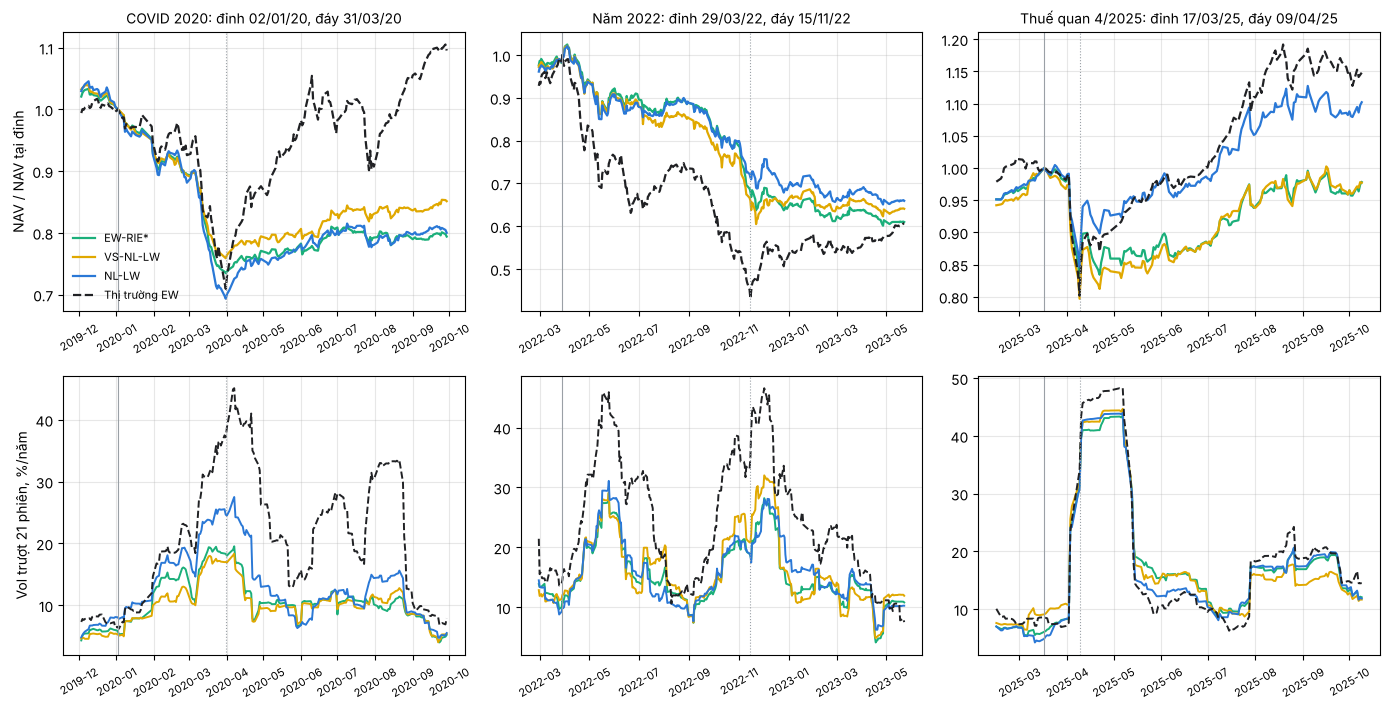

**Hình 24.** Ba đợt khủng hoảng: NAV chuẩn hóa tại đỉnh (trên) và Vol trượt 21 phiên (dưới) của EW-RIE\*, VS-NL-LW, NL-LW và Thị trường EW (từ 21 phiên trước đỉnh tới 126 phiên sau đáy; vạch liền: đỉnh, vạch chấm: đáy).

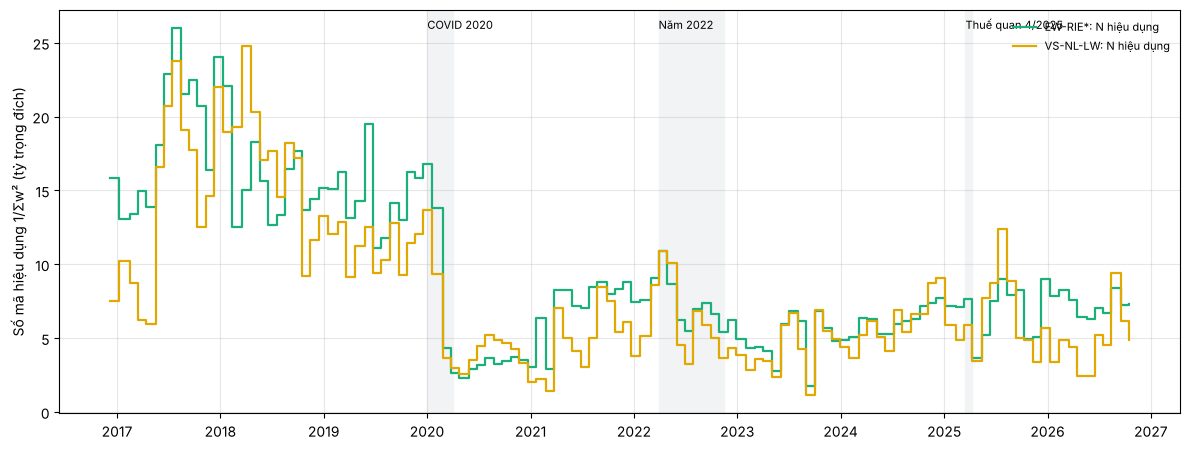

**Hình 25.** Độ tập trung danh mục đích chỉ mua (số mã hiệu dụng 1/Σw²) của EW-RIE\* và VS-NL-LW qua các kỳ; nền xám: ba đợt khủng hoảng (đỉnh → đáy).

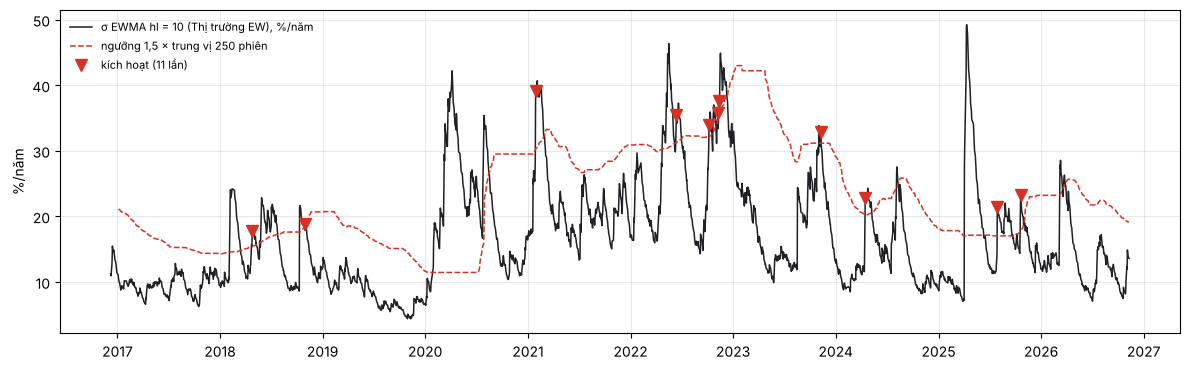

**Hình 26.** Cầu chì: biến động EWMA (hl = 10) của Thị trường EW, ngưỡng 1,5 × trung vị 250 phiên trước, và các lần kích hoạt trong mẫu ngoài mẫu.

**Kết quả.** Mức sụt EW-RIE\* / VS-NL-LW / Thị trường EW: COVID 2020 -26,5 / -24,1 / -29,1%; Năm 2022 -36,3 / -39,5 / -57,0%; Thuế quan 4/2025 -17,7 / -20,3 / -19,8%. Cầu chì kích hoạt 11 lần; với EW-RIE\*: ΔVol −0,10 pp (p 0,212), MDD -41,3 → -38,1%, chi phí 1,16 → 1,20 %/năm. Có cầu chì, ΔVol EW-RIE\* − VS-NL-LW = +0,15 pp (p 0,494).

**Kết luận (theo ngưỡng đăng ký trước).** H3a (EW-RIE\* sụt ít hơn VS-NL-LW ở ≥ 2/3 sự kiện): **đạt** (2/3; chỉ mô tả, 3 sự kiện). H3b (cầu chì có lợi cho EW-RIE\*): **đạt**.

**Đào sâu (mô tả, không đăng ký trước).** Giả dược: 30 bộ, mỗi bộ 11 phiên chọn ngẫu nhiên (cách kỳ đều > 5 phiên) để tái cân bằng thêm. EW-RIE*: cầu chì ΔMDD +3,24, ΔVol −0,10, ΔCAGR +0,72 pp; giả dược ΔMDD TB +0,11 pp (≥ mức của cầu chì ở 1/30 bộ), ΔVol TB −0,01, ΔCAGR TB +0,01 pp. VS-NL-LW: cầu chì ΔMDD +5,59, ΔVol −0,12, ΔCAGR +0,59 pp; giả dược ΔMDD TB +0,06 pp (≥ mức của cầu chì ở 1/30 bộ), ΔVol TB −0,02, ΔCAGR TB −0,06 pp. Lần cắt ngưỡng bị bỏ vì sát kỳ đều nằm trong các đợt khủng hoảng: 30/01/20, 25/04/22, 21/10/22, 03/04/25 — tức ở các cú sốc lớn, lịch 21 phiên đã tự tái cân bằng gần như cùng lúc. Giả dược hiếm khi đạt mức cải thiện MDD của cầu chì (p hoán vị ≈ 0,06 cho EW-RIE\*) ⇒ thời điểm cầu chì chọn có vai trò, không chỉ do tái cân bằng nhiều hơn. Nhưng MDD là MỘT đợt sụt (4/11 lần kích hoạt rơi vào 2022) nên đây là bằng chứng yếu, cần kiểm trên thị trường/giai đoạn khác.

In [67]:
# ---- 7.3 Hướng 3: khủng hoảng — nghiên cứu sự kiện (COVID 2020, 2022, thuế quan 4/2025) và "cầu chì"; Bảng 39, 40; Hình 24–26 ----
# Thị trường EW trên toàn lưới 21 phiên (từ phiên W + 1) để có lịch sử cho EWMA và trung vị 250 phiên trước mẫu ngoài mẫu
GRID = [s for s in range(W7 + 1, END7, 21) if eligible(s)[1].sum() >= 20]
MK_FULL = simulate({s: _eq(eligible(s)[0].columns[eligible(s)[1]]) for s in GRID}, GRID, None, cost=False)[0]
assert np.allclose(MK_FULL.loc[RG["mk"].index].values, RG["mk"].values)          # trùng Thị trường EW của Hướng 1 trên mẫu chung
mkn = (1 + MK_FULL).cumprod()

EVW = {"COVID 2020": ("2020-01-01", "2020-06-30"), "Năm 2022": ("2022-01-01", "2022-12-31"), "Thuế quan 4/2025": ("2025-03-15", "2025-06-30")}
EV = {}
for k, (a, b) in EVW.items():
    seg = mkn.loc[a:b]; tr = seg.idxmin(); pk = seg.loc[:tr].idxmax(); EV[k] = (pk, tr)
navs = {nm: (1 + R1[nm]).cumprod() for nm in M7}; navs["Thị trường EW"] = mkn.loc[R1["EW-RIE*"].index[0]:] / mkn.loc[R1["EW-RIE*"].index[0]]
def ev_stats(nav, r, pk, tr, tg=None):
    i_pk, i_tr = DATES7.get_loc(pk), DATES7.get_loc(tr); w = nav.loc[pk:DATES7[i_tr + 20]]
    rec = nav.loc[tr:][nav.loc[tr:] >= nav.loc[pk]]
    out = {"Mức sụt %": (w.min() / nav.loc[pk] - 1) * 100, "Hồi phục (phiên)": (DATES7.get_loc(rec.index[0]) - i_tr) if len(rec) else np.nan,
           "Vol 21 phiên lớn nhất %": (r.rolling(21).std() * np.sqrt(252) * 100).loc[pk:DATES7[i_tr + 20]].max()}
    if tg is not None:
        sb = max(s for s in S_REG if s <= i_pk); sa = min(s for s in S_REG if s >= i_tr)
        wb, wa = np.zeros(len(TICK7)), np.zeros(len(TICK7)); wb[tg[sb][0]] = tg[sb][1][0]; wa[tg[sa][0]] = tg[sa][1][0]
        out["Δ tỷ trọng %"] = 50 * np.abs(wa - wb).sum()
    return out
rows = []
for k, (pk, tr) in EV.items():
    for nm in M7 + ["Thị trường EW"]:
        r = R1[nm] if nm in R1 else MK_FULL.loc[R1["EW-RIE*"].index]
        rows.append({"Sự kiện": f"{k} ({pk:%d/%m/%y}→{tr:%d/%m/%y})", "Phương pháp": nm, **ev_stats(navs[nm], r, pk, tr, TG.get(nm))})
T39 = pd.DataFrame(rows).set_index(["Sự kiện", "Phương pháp"]); save7(T39, "H3_su_kien")
cap("Bảng", "Ba đợt khủng hoảng (đỉnh → đáy của Thị trường EW, xác định từ dữ liệu theo quy tắc đăng ký trước), chỉ mua, NAV ròng, REB = 21: "
    "mức sụt = NAV thấp nhất trong [đỉnh, đáy + 20 phiên] so với NAV tại đỉnh; hồi phục = số phiên từ đáy thị trường tới khi NAV vượt NAV tại đỉnh "
    "(– = chưa); Vol 21 phiên lớn nhất (%/năm) trong cùng khoảng; Δ tỷ trọng = ½Σ|w(kỳ đầu sau đáy) − w(kỳ cuối trước đỉnh)| (%).")
show(T39)

# ---- cầu chì: σ EWMA (hl = 10) của Thị trường EW > 1,5 × trung vị 250 phiên trước ⇒ tái cân bằng thêm ở phiên kế tiếp ----
lam = .5 ** (1 / 10); rm = MK_FULL.values; s2 = np.empty(len(rm)); s2[0] = rm[:10].var()
for t in range(1, len(rm)): s2[t] = lam * s2[t - 1] + (1 - lam) * rm[t] ** 2          # σ²_t gồm lợi suất ngày t (biết lúc đóng cửa t)
s2 = pd.Series(s2, index=MK_FULL.index)
SIG = np.sqrt(s2 * 252) * 100; THR = 1.5 * SIG.shift(1).rolling(250).median()
above = SIG > THR; cross = above & ~above.shift(1, fill_value=False) & THR.notna()
FUSE = []
for d in cross[cross].index:
    s = DATES7.get_loc(d) + 1
    if S_REG[0] < s < END7 and min(abs(s - x) for x in S_REG) > 5: FUSE.append(s)
FUSE_SKIP = sum(S_REG[0] < DATES7.get_loc(d) + 1 < END7 for d in cross[cross].index) - len(FUSE)
TGF = {nm: targets7(nm, extra=FUSE) for nm in M7X}
SIM3 = {nm: simulate(TGF[nm], sorted(S_REG + FUSE), "lo") for nm in M7X}
rows = []
for nm in M7X:
    r0, r1 = R1[nm], SIM3[nm][0]; a0, a1 = perf7(r0, SIM1[nm][1]), perf7(r1, SIM3[nm][1]); dv_, p_hac, p_bt = lw7(r1, r0)
    rows.append({"Phương pháp": nm, "Vol không %": a0["Vol %"], "Vol có %": a1["Vol %"], "ΔVol (pp)": dv_, "p LW-boot": p_bt,
                 "CAGR không %": a0["CAGR %"], "CAGR có %": a1["CAGR %"], "MDD không %": a0["MDD %"], "MDD có %": a1["MDD %"],
                 "Chi phí không %/năm": a0["Chi phí %/năm"], "Chi phí có %/năm": a1["Chi phí %/năm"]})
T40 = pd.DataFrame(rows).set_index("Phương pháp"); T40.insert(4, "p Holm", holm(T40["p LW-boot"].values)); save7(T40, "H3_cau_chi")
dEVf, _, pEVf = lw7(SIM3["EW-RIE*"][0], SIM3["VS-NL-LW"][0])
cap("Bảng", f"Cầu chì định trước: σ EWMA (hl = 10) của Thị trường EW vượt 1,5 × trung vị 250 phiên trước ⇒ tái cân bằng thêm ở phiên kế tiếp "
    f"(bỏ nếu cách kỳ đều ≤ 5 phiên): {len(FUSE)} lần kích hoạt trong mẫu (bỏ {FUSE_SKIP} lần gần kỳ đều). Chỉ mua, NAV ròng; ΔVol = Vol(có) − Vol(không), "
    "p Ledoit–Wolf (2011) bootstrap khối, Holm trên 8 phương pháp.")
display(T40.style.format(precision=2, decimal=",", thousands=" ", na_rep="–").format(pv, subset=[c for c in T40.columns if str(c).startswith("p ")]))

C3 = {"EW-RIE*": COL["EW-RIE*"], "VS-NL-LW": COL["VS-NL-LW"], "NL-LW": COL["NL-LW"], "Thị trường EW": COL["Thị trường EW"]}
fig, axs = plt.subplots(2, 3, figsize=(14, 7.2))
for j, (k, (pk, tr)) in enumerate(EV.items()):
    i0, i1 = DATES7.get_loc(pk) - 21, min(DATES7.get_loc(tr) + 126, END7 - 1); d0, d1 = DATES7[i0], DATES7[i1]
    for nm, c in C3.items():
        nv = navs[nm].loc[d0:d1]; ls = "--" if nm == "Thị trường EW" else "-"
        axs[0, j].plot(nv.index, nv.values / navs[nm].loc[pk], color=c, ls=ls, lw=1.6, label=nm)
        r = R1[nm] if nm in R1 else MK_FULL
        axs[1, j].plot(nv.index, (r.rolling(21).std() * np.sqrt(252) * 100).loc[d0:d1], color=c, ls=ls, lw=1.4, label=nm)
    for a in axs[:, j]:
        a.axvline(pk, color="#9aa0a6", lw=.8); a.axvline(tr, color="#9aa0a6", lw=.8, ls=":"); a.grid(alpha=.3); a.tick_params(axis="x", labelsize=8, rotation=30)
    axs[0, j].set_title(f"{k}: đỉnh {pk:%d/%m/%y}, đáy {tr:%d/%m/%y}", fontsize=10)
axs[0, 0].set_ylabel("NAV / NAV tại đỉnh"); axs[1, 0].set_ylabel("Vol trượt 21 phiên, %/năm"); axs[0, 0].legend(fontsize=8, frameon=False)
plt.tight_layout(); savefig7(fig, "fig_24_su_kien")
cap("Hình", "Ba đợt khủng hoảng: NAV chuẩn hóa tại đỉnh (trên) và Vol trượt 21 phiên (dưới) của EW-RIE\\*, VS-NL-LW, NL-LW và Thị trường EW "
    "(từ 21 phiên trước đỉnh tới 126 phiên sau đáy; vạch liền: đỉnh, vạch chấm: đáy).")

TOP = ["EW-RIE*", "VS-NL-LW"]; fig, ax = plt.subplots(figsize=(12, 4.6))
for nm in TOP:
    w = pd.Series({DATES7[s]: 1 / (TG[nm][s][1][0] ** 2).sum() for s in S_REG}); ax.step(w.index, w.values, where="post", color=col_of(nm), lw=1.6, label=f"{nm}: N hiệu dụng")
for k, (pk, tr) in EV.items(): ax.axvspan(pk, tr, color="#f1f3f4", zorder=0); ax.text(pk, .98, k, transform=ax.get_xaxis_transform(), fontsize=8, va="top")
ax.set_ylabel("Số mã hiệu dụng 1/Σw² (tỷ trọng đích)"); ax.grid(alpha=.3); ax.legend(fontsize=8, frameon=False, loc="upper right")
plt.tight_layout(); savefig7(fig, "fig_25_neff")
cap("Hình", "Độ tập trung danh mục đích chỉ mua (số mã hiệu dụng 1/Σw²) của EW-RIE\\* và VS-NL-LW qua các kỳ; nền xám: ba đợt khủng hoảng (đỉnh → đáy).")

fig, ax = plt.subplots(figsize=(12, 3.8)); oos = SIG.loc[R1["EW-RIE*"].index[0]:]
ax.plot(oos.index, oos.values, color=COL["Thị trường EW"], lw=1.1, label="σ EWMA hl = 10 (Thị trường EW), %/năm")
ax.plot(oos.index, THR.loc[oos.index].values, color="#d93025", lw=1.1, ls="--", label="ngưỡng 1,5 × trung vị 250 phiên")
ax.plot(DATES7[[s - 1 for s in FUSE]], SIG.loc[DATES7[[s - 1 for s in FUSE]]].values, "v", color="#d93025", ms=8, label=f"kích hoạt ({len(FUSE)} lần)")
ax.set_ylabel("%/năm"); ax.grid(alpha=.3); ax.legend(fontsize=8, frameon=False, loc="upper left"); plt.tight_layout(); savefig7(fig, "fig_26_cau_chi")
cap("Hình", "Cầu chì: biến động EWMA (hl = 10) của Thị trường EW, ngưỡng 1,5 × trung vị 250 phiên trước, và các lần kích hoạt trong mẫu ngoài mẫu.")

dd = {k: (T39.loc[(kk, "EW-RIE*"), "Mức sụt %"], T39.loc[(kk, "VS-NL-LW"), "Mức sụt %"]) for k in EV for kk in T39.index.levels[0] if kk.startswith(k)}
n_less = sum(e > v for e, v in dd.values())                                    # sụt ít hơn = mức sụt (âm) lớn hơn
fE = T40.loc["EW-RIE*"]; H3B = (fE["ΔVol (pp)"] <= -.10 and fE["p LW-boot"] < .05) or (fE["MDD có %"] - fE["MDD không %"] >= 2)
md("**Kết quả.** Mức sụt EW-RIE\\* / VS-NL-LW / Thị trường EW: " + "; ".join(
       f"{k} {f2(dd[k][0], 1)} / {f2(dd[k][1], 1)} / {f2(T39.loc[(kk, 'Thị trường EW'), 'Mức sụt %'], 1)}%" for k in EV for kk in T39.index.levels[0] if kk.startswith(k))
   + f". Cầu chì kích hoạt {len(FUSE)} lần; với EW-RIE\\*: ΔVol {dv(fE['ΔVol (pp)'])} pp (p {pv(fE['p LW-boot'])}), MDD {f2(fE['MDD không %'], 1)} → {f2(fE['MDD có %'], 1)}%, "
   f"chi phí {f2(fE['Chi phí không %/năm'])} → {f2(fE['Chi phí có %/năm'])} %/năm. Có cầu chì, ΔVol EW-RIE\\* − VS-NL-LW = {dv(dEVf)} pp (p {pv(pEVf)}).\n\n"
   f"**Kết luận (theo ngưỡng đăng ký trước).** H3a (EW-RIE\\* sụt ít hơn VS-NL-LW ở ≥ 2/3 sự kiện): **{'đạt' if n_less >= 2 else 'không đạt'}** ({n_less}/3; chỉ mô tả, 3 sự kiện). "
   f"H3b (cầu chì có lợi cho EW-RIE\\*): **{'đạt' if H3B else 'không đạt'}**.")

# ---- Đào sâu (mô tả, KHÔNG đăng ký trước): phép thử giả dược — tái cân bằng thêm vào 11 ngày NGẪU NHIÊN (cùng quy tắc cách kỳ đều > 5 phiên) ----
def lo_at(nm, days):
    # tỷ trọng chỉ mua tại các phiên bất kỳ (cache riêng, chỉ lời giải chỉ mua)
    f = f"{C7}/placebo_{re.sub(r'[^A-Za-z0-9]+', '_', nm)}.pkl"; D = pd.read_pickle(f) if os.path.exists(f) else {}
    todo = [s for s in days if s not in D]
    if todo:
        est = est7(nm)
        for s in todo:
            tick, X = universe(s); D[s] = (np.array([TICK7.get_loc(t) for t in tick]), gmv_long_only(est(X))[None, :])
        pd.to_pickle(D, f)
    return D
rng = np.random.default_rng(SEED); CAND = [s for s in range(S_REG[0] + 1, END7) if min(abs(s - x) for x in S_REG) > 5]
PLA = [sorted(rng.choice(CAND, len(FUSE), replace=False).tolist()) for _ in range(30)]
rows = []
for nm in ("EW-RIE*", "VS-NL-LW"):
    D = lo_at(nm, sorted({s for st in PLA for s in st})); b0 = perf7(R1[nm])
    for i, st in enumerate(PLA):
        tg = {**TG[nm], **{s: D[s] for s in st}}; a = perf7(simulate(tg, sorted(S_REG + st), "lo")[0])
        rows.append({"pp": nm, "bộ": i, "ΔMDD (pp)": a["MDD %"] - b0["MDD %"], "ΔVol (pp)": a["Vol %"] - b0["Vol %"], "ΔCAGR (pp)": a["CAGR %"] - b0["CAGR %"]})
PLT = pd.DataFrame(rows); save7(PLT, "H3_gia_duoc")
fz = {nm: (T40.loc[nm, "MDD có %"] - T40.loc[nm, "MDD không %"], T40.loc[nm, "ΔVol (pp)"], T40.loc[nm, "CAGR có %"] - T40.loc[nm, "CAGR không %"]) for nm in ("EW-RIE*", "VS-NL-LW")}
skip_ev = [f"{d:%d/%m/%y}" for d in cross[cross].index if (DATES7.get_loc(d) + 1) not in FUSE and any(pk - pd.Timedelta(days=30) <= d <= tr for pk, tr in EV.values())]
def _pl(nm):
    q = PLT[PLT.pp == nm]; m, v, c = fz[nm]
    return (f"{nm}: cầu chì ΔMDD {dv(m)}, ΔVol {dv(v)}, ΔCAGR {dv(c)} pp; giả dược ΔMDD TB {dv(q['ΔMDD (pp)'].mean())} pp "
            f"(≥ mức của cầu chì ở {int((q['ΔMDD (pp)'] >= m).sum())}/30 bộ), ΔVol TB {dv(q['ΔVol (pp)'].mean())}, ΔCAGR TB {dv(q['ΔCAGR (pp)'].mean())} pp")
md(f"**Đào sâu (mô tả, không đăng ký trước).** Giả dược: 30 bộ, mỗi bộ {len(FUSE)} phiên chọn ngẫu nhiên (cách kỳ đều > 5 phiên) để tái cân bằng thêm. {_pl('EW-RIE*')}. {_pl('VS-NL-LW')}. "
   f"Lần cắt ngưỡng bị bỏ vì sát kỳ đều nằm trong các đợt khủng hoảng: {', '.join(skip_ev) if skip_ev else 'không có'} — tức ở các cú sốc lớn, lịch 21 phiên đã tự tái cân bằng gần như cùng lúc. "
   + (f"Giả dược hiếm khi đạt mức cải thiện MDD của cầu chì (p hoán vị ≈ {f2((int((PLT[PLT.pp == 'EW-RIE*']['ΔMDD (pp)'] >= fz['EW-RIE*'][0]).sum()) + 1) / 31, 2)} cho EW-RIE\\*) "
      "⇒ thời điểm cầu chì chọn có vai trò, không chỉ do tái cân bằng nhiều hơn. Nhưng MDD là MỘT đợt sụt (" + f"{sum(DATES7[s].year == 2022 for s in FUSE)}/{len(FUSE)} lần kích hoạt rơi vào 2022"
      + ") nên đây là bằng chứng yếu, cần kiểm trên thị trường/giai đoạn khác."
      if (PLT[PLT.pp == "EW-RIE*"]["ΔMDD (pp)"] >= fz["EW-RIE*"][0]).mean() <= .1 else
      "Giả dược cải thiện MDD tương đương cầu chì ⇒ lợi ích đến từ việc tái cân bằng nhiều hơn, không phải từ thời điểm cầu chì chọn."))

### 7.4 Hướng 4 – Danh mục thực thi được

**Câu hỏi.** Khi thêm ràng buộc thực tế — trần tỷ trọng mỗi mã 10% hoặc 20%, trần turnover một chiều 10%/kỳ — thứ hạng các phương pháp có giữ không? Quỹ 100 tỷ và 1 000 tỷ đồng có thoát được vị thế không?

**Cách làm.** GMV chỉ mua có trần giải từ cùng ma trận hiệp phương sai (FISTA như của thầy, chiếu lên đơn hình có trần). Trần turnover: đi một phần về đích. Sức chứa: vị thế = quỹ × tỷ trọng; số ngày thanh lý = vị thế / (10% × giá trị giao dịch bình quân 20 phiên trước kỳ).

**Giả thuyết (đăng ký trước).** Thứ hạng giữ nếu Kendall τ (xếp theo Vol, 6 phương pháp) so với cấu hình chuẩn ≥ 0,6 ở mọi cấu hình và dấu ΔVol EW-RIE\* − VS-NL-LW không đổi. Quỹ "vừa sức" nếu trung bình ≥ 95% NAV bán được trong 5 phiên.

**Bảng 41.** Danh mục thực thi được, chỉ mua, NAV ròng, REB = 21: Vol (%/năm) và (hạng trong 6 phương pháp chính) theo cấu hình — trần tỷ trọng 20%, 10% (GMV có trần, cùng ma trận hiệp phương sai), trần turnover một chiều 10%/kỳ (đi một phần về đích). Dưới: CAGR, turnover, Kendall τ của thứ hạng so với A, ΔVol EW-RIE\* − VS-NL-LW và p Ledoit–Wolf bootstrap khối (Holm trên 5 cấu hình).

,A chuẩn,B trần 20%,C trần 10%,D turnover ≤ 10%,E trần 10% + turnover ≤ 10%
EW-RIE*,"12,97 (3)","13,09 (3)","13,67 (3)","13,51 (3)","13,93 (2)"
VS-NL-LW,"12,84 (1)","12,88 (1)","13,52 (1)","13,34 (1)","13,88 (1)"
NL-LW,"13,67 (5)","13,74 (5)","14,18 (5)","13,90 (5)","14,29 (5)"
EW-NL-LW,"13,03 (4)","13,14 (4)","13,74 (4)","13,55 (4)","13,99 (4)"
EW-WeSpeR,"12,96 (2)","13,07 (2)","13,67 (2)","13,51 (2)","13,93 (3)"
1/N,"22,60 (6)","22,60 (6)","22,60 (6)","22,60 (6)","22,60 (6)"
VS-NL-LW (HL 10),"13,10","13,04","13,71","13,21","14,02"
VS-NL-LW (HL 40),"12,88","12,96","13,57","13,49","13,89"
CAGR EW-RIE* / VS-NL-LW %,"1,56 / 3,39","2,52 / 4,28","4,15 / 6,01","5,79 / 7,30","6,84 / 7,45"
Turnover/năm EW-RIE* / VS-NL-LW %,287 / 448,257 / 396,239 / 371,120 / 119,118 / 120


**Bảng 42.** Sức chứa vốn (tỷ trọng đích chỉ mua, 118 kỳ): vị thế = quỹ × tỷ trọng; ADV20 = giá trị giao dịch bình quân 20 phiên trước kỳ (`values.csv` = giá điều chỉnh × khối lượng, đánh giá thấp những năm đầu ⇒ thận trọng); số ngày thanh lý = vị thế / (10% × ADV20). Trung bình qua các kỳ; cột cuối: kỳ xấu nhất. EW-NL-LW, EW-WeSpeR gần trùng EW-RIE\* nên chỉ có trong `results_v7/H4_suc_chua.csv`.

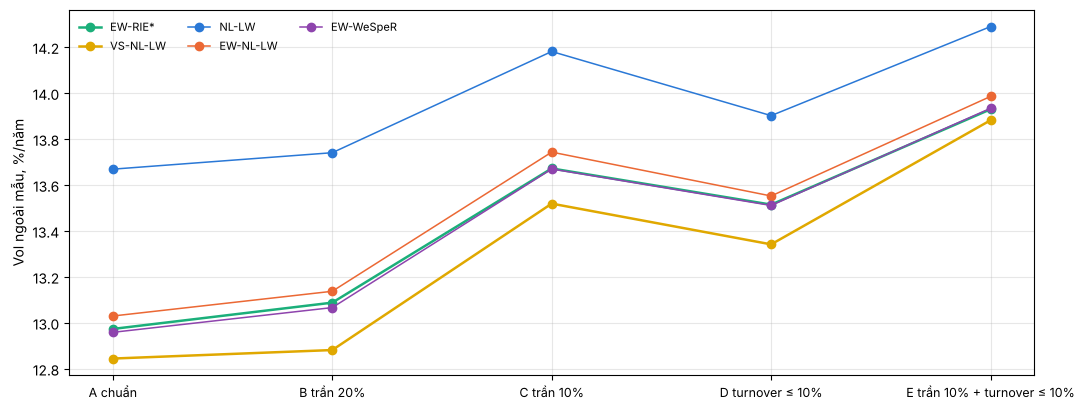

**Hình 27.** Vol (%/năm, chỉ mua, NAV ròng) của 5 phương pháp GMV theo năm cấu hình thực thi (số và hạng ở Bảng 41; 1/N không đổi 22,6%, không vẽ).

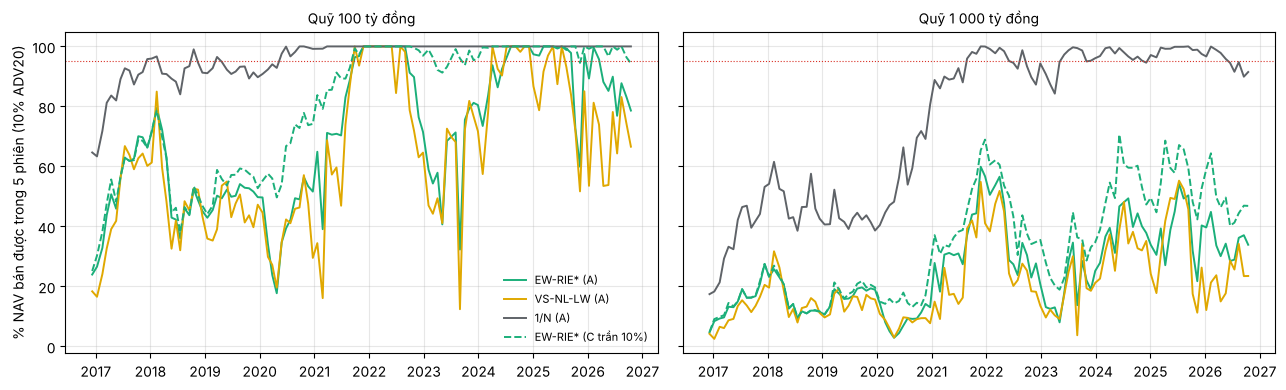

**Hình 28.** Thanh khoản danh mục đích qua các kỳ: % NAV bán được trong 5 phiên khi mỗi phiên chỉ bán tối đa 10% ADV20; vạch chấm: ngưỡng 95% (đăng ký trước).

**Kết quả.** Kendall τ của thứ hạng Vol so với A: B 1,00, C 1,00, D 1,00, E 0,87. ΔVol EW-RIE\* − VS-NL-LW: A +0,13, B +0,21, C +0,15, D +0,17, E +0,05 pp. Trần 10% làm Vol EW-RIE\* 12,97 → 13,67%; trần turnover 10% → 13,51%. % NAV bán được trong 5 phiên (TB, cấu hình A): quỹ 100 tỷ EW-RIE* 70,3, VS-NL-LW 63,9, NL-LW 78,3, EW-NL-LW 69,6, EW-WeSpeR 70,1, 1/N 96,3; quỹ 1 000 tỷ EW-RIE* 25,8, VS-NL-LW 21,4, NL-LW 32,1, EW-NL-LW 25,3, EW-WeSpeR 25,6, 1/N 75,2.

**Kết luận (theo ngưỡng đăng ký trước).** Thứ hạng **giữ** (τ nhỏ nhất 0,87; dấu ΔVol EW-RIE\* − VS-NL-LW không đổi qua 5 cấu hình). Sức chứa: quỹ 100 tỷ không vừa sức với EW-RIE\*, quỹ 1 000 tỷ không vừa sức (ngưỡng 95% NAV trong 5 phiên).

**Đào sâu (mô tả, không đăng ký trước).** (1) *Độ lệch dữ liệu*: `values.csv` = giá điều chỉnh × khối lượng khớp lệnh nên giá trị giao dịch những năm đầu bị đánh giá thấp (ví dụ HPG 2017: giá điều chỉnh ~5 500 đồng so với giá thực vài chục nghìn) và bỏ giao dịch thỏa thuận. Chỉ tính các kỳ từ 2024 (độ lệch nhỏ hơn), % NAV bán được trong 5 phiên của EW-RIE\* là 91,6% (quỹ 100 tỷ) và 37,9% (1 000 tỷ); trần 10%: 99,3% / 53,4%; 1/N: 100,0% / 97,2%. (2) *Nghiêng về mã kém thanh khoản*: hạng thanh khoản trung bình theo tỷ trọng trong top-100 (1 = lỏng nhất, 1/N = 50,5): EW-RIE* 55,8, VS-NL-LW 57,4, NL-LW 56,7, EW-NL-LW 56,0, EW-WeSpeR 55,7 ⇒ GMV chỉ hơi nghiêng về phía kém thanh khoản; sức chứa kém chủ yếu do **độ tập trung** (vài vị thế rất lớn, xem Hình 20), không phải do chọn mã kém thanh khoản. (3) *Trần có tăng CAGR thật không?* Chênh lợi suất TB ngày (quy %/năm) của EW-RIE\* so với A: B +0,96 (p NW 0,268, Holm 0,293), C +2,61 (p NW 0,147, Holm 0,293), D +4,16 (p NW 0,011, Holm 0,043), E +5,20 (p NW 0,017, Holm 0,050) ⇒ giới hạn turnover (D) cho lợi suất cao hơn **có ý nghĩa sau Holm** — cùng chiều với Hướng 2 (REB dài ⇒ CAGR cao hơn): điều chỉnh CHẬM về danh mục đích có lợi cho lợi suất. Đây là phát hiện khám phá (không đăng ký trước), cần kiểm lại ngoài mẫu.

In [68]:
# ---- 7.4 Hướng 4: danh mục thực thi được — trần tỷ trọng, trần turnover, sức chứa vốn; Bảng 41, 42; Hình 27, 28 ----
from scipy.stats import kendalltau
CFG4 = {"A chuẩn": ("lo", None), "B trần 20%": ("c20", None), "C trần 10%": ("c10", None),
        "D turnover ≤ 10%": ("lo", .10), "E trần 10% + turnover ≤ 10%": ("c10", .10)}
SIM4 = {(nm, c): (SIM1[nm] if c == "A chuẩn" else simulate(TG[nm], S_REG, k, to_cap=tc)) for nm in M7X for c, (k, tc) in CFG4.items()}
pd.to_pickle({k: v[0] for k, v in SIM4.items()}, f"{R7}/H4_returns.pkl")
P4 = {k: perf7(*v) for k, v in SIM4.items()}
VOL4 = pd.DataFrame({c: {nm: P4[(nm, c)]["Vol %"] for nm in M7X} for c in CFG4}); RK = VOL4.loc[M7].rank()
rows, pE = {}, []
for c in CFG4:
    rows[c] = {nm: f"{f2(VOL4.loc[nm, c])}" + (f" ({int(RK.loc[nm, c])})" if nm in M7 else "") for nm in M7X}
    dv_, _, p_bt = lw7(SIM4[("EW-RIE*", c)][0], SIM4[("VS-NL-LW", c)][0]); pE.append(p_bt)
    rows[c].update({"CAGR EW-RIE* / VS-NL-LW %": f"{f2(P4[('EW-RIE*', c)]['CAGR %'])} / {f2(P4[('VS-NL-LW', c)]['CAGR %'])}",
                    "Turnover/năm EW-RIE* / VS-NL-LW %": f"{f2(P4[('EW-RIE*', c)]['Turnover/năm %'], 0)} / {f2(P4[('VS-NL-LW', c)]['Turnover/năm %'], 0)}",
                    "Kendall τ so với A (6 phương pháp)": f2(kendalltau(RK["A chuẩn"], RK[c])[0]), "ΔVol EW-RIE* − VS-NL-LW (pp)": dv(dv_)})
for c, p in zip(CFG4, holm(pE)): rows[c]["p Holm (5 cấu hình)"] = pv(p)
T41 = pd.DataFrame(rows); save7(T41, "H4_thu_hang"); save7(VOL4, "H4_vol")
cap("Bảng", "Danh mục thực thi được, chỉ mua, NAV ròng, REB = 21: Vol (%/năm) và (hạng trong 6 phương pháp chính) theo cấu hình — trần tỷ trọng 20%, 10% "
    "(GMV có trần, cùng ma trận hiệp phương sai), trần turnover một chiều 10%/kỳ (đi một phần về đích). Dưới: CAGR, turnover, Kendall τ của thứ hạng so với A, "
    "ΔVol EW-RIE\\* − VS-NL-LW và p Ledoit–Wolf bootstrap khối (Holm trên 5 cấu hình).")
display(T41.style.set_properties(**{"text-align": "right"}))

ADV20 = V.rolling(20, min_periods=10).mean().shift(1).values        # TB giá trị GD 20 phiên TRƯỚC kỳ (đồng; giá điều chỉnh × KL)
FUNDS = {"100 tỷ": 100e9, "1 000 tỷ": 1000e9}
def capacity(nm, kind, F):
    out = []
    for s in S_REG:
        ix, Wm = TG[nm][s]; w = Wm[KINDS.index(kind)]; held = w > 1e-4; w, ix = w[held], ix[held]
        adv = ADV20[s, ix]; days = np.where(adv > 0, F * w / (.1 * np.where(adv > 0, adv, 1)), np.inf)
        o = np.argsort(days); cw = np.cumsum(w[o]) / w.sum()
        out.append({"date": DATES7[s], "% vị thế > 10% ADV20": 100 * (days > 1).mean(), "% NAV trong các vị thế đó": 100 * w[days > 1].sum(),
                    "Số ngày (trung vị theo tỷ trọng)": days[o][np.searchsorted(cw, .5)], "Số ngày lớn nhất": days.max(),
                    "% NAV bán được trong 5 phiên": 100 * (w * np.minimum(1, 5 / days)).sum()})
    return pd.DataFrame(out).set_index("date")
CAPS = {(nm, c, f): capacity(nm, k, F) for nm in M7 for c, k in (("A chuẩn", "lo"), ("C trần 10%", "c10")) for f, F in FUNDS.items()}
T42 = pd.DataFrame({k: {**v.mean().to_dict(), "% NAV bán được trong 5 phiên (kỳ xấu nhất)": v["% NAV bán được trong 5 phiên"].min()} for k, v in CAPS.items()}).T
T42.index.names = ["Phương pháp", "Cấu hình", "Quỹ"]; T42 = T42.reorder_levels(["Quỹ", "Cấu hình", "Phương pháp"]).sort_index(level=[0, 1], sort_remaining=False)
save7(T42, "H4_suc_chua"); M42 = ["EW-RIE*", "VS-NL-LW", "NL-LW", "1/N"]
cap("Bảng", "Sức chứa vốn (tỷ trọng đích chỉ mua, 118 kỳ): vị thế = quỹ × tỷ trọng; ADV20 = giá trị giao dịch bình quân 20 phiên trước kỳ (`values.csv` = giá điều chỉnh × khối lượng, "
    "đánh giá thấp những năm đầu ⇒ thận trọng); số ngày thanh lý = vị thế / (10% × ADV20). Trung bình qua các kỳ; cột cuối: kỳ xấu nhất. "
    "EW-NL-LW, EW-WeSpeR gần trùng EW-RIE\\* nên chỉ có trong `results_v7/H4_suc_chua.csv`.")
show(T42[T42.index.get_level_values("Phương pháp").isin(M42)], 1)

fig, ax = plt.subplots(figsize=(11, 4.2)); xs = np.arange(len(CFG4))
for nm in [m for m in M7 if m != "1/N"]:                   # 1/N không đổi (22,6%): bỏ để giữ thang
    ax.plot(xs, VOL4.loc[nm].values, marker="o", ms=6, color=col_of(nm), lw=1.8 if nm in ("EW-RIE*", "VS-NL-LW") else 1.1, label=nm)
ax.set_xticks(xs); ax.set_xticklabels(list(CFG4), fontsize=9); ax.set_ylabel("Vol ngoài mẫu, %/năm"); ax.grid(alpha=.3); ax.legend(fontsize=8, frameon=False, ncol=3)
plt.tight_layout(); savefig7(fig, "fig_27_vol_cau_hinh")
cap("Hình", "Vol (%/năm, chỉ mua, NAV ròng) của 5 phương pháp GMV theo năm cấu hình thực thi (số và hạng ở Bảng 41; 1/N không đổi 22,6%, không vẽ).")

fig, axs = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for a, f in zip(axs, FUNDS):
    for nm in ("EW-RIE*", "VS-NL-LW", "1/N"):
        a.plot(CAPS[(nm, "A chuẩn", f)].index, CAPS[(nm, "A chuẩn", f)]["% NAV bán được trong 5 phiên"], color=col_of(nm), lw=1.4, label=f"{nm} (A)")
    a.plot(CAPS[("EW-RIE*", "C trần 10%", f)].index, CAPS[("EW-RIE*", "C trần 10%", f)]["% NAV bán được trong 5 phiên"], color=COL["EW-RIE*"], ls="--", lw=1.4, label="EW-RIE* (C trần 10%)")
    a.axhline(95, color="#d93025", lw=.8, ls=":"); a.set_title(f"Quỹ {f} đồng", fontsize=10); a.grid(alpha=.3)
axs[0].set_ylabel("% NAV bán được trong 5 phiên (10% ADV20)"); axs[0].legend(fontsize=8, frameon=False, loc="lower right"); plt.tight_layout(); savefig7(fig, "fig_28_thanh_khoan")
cap("Hình", "Thanh khoản danh mục đích qua các kỳ: % NAV bán được trong 5 phiên khi mỗi phiên chỉ bán tối đa 10% ADV20; vạch chấm: ngưỡng 95% (đăng ký trước).")

tau = {c: kendalltau(RK["A chuẩn"], RK[c])[0] for c in CFG4 if c != "A chuẩn"}
sgn = {c: np.sign(VOL4.loc["EW-RIE*", c] - VOL4.loc["VS-NL-LW", c]) for c in CFG4}; same = all(v == sgn["A chuẩn"] for v in sgn.values())
liq = {f: {nm: T42.loc[(f, "A chuẩn", nm), "% NAV bán được trong 5 phiên"] for nm in M7} for f in FUNDS}
md(f"**Kết quả.** Kendall τ của thứ hạng Vol so với A: " + ", ".join(f"{c[0]} {f2(t)}" for c, t in tau.items())
   + f". ΔVol EW-RIE\\* − VS-NL-LW: " + ", ".join(f"{c[0]} {rows[c]['ΔVol EW-RIE* − VS-NL-LW (pp)']}" for c in CFG4)
   + f" pp. Trần 10% làm Vol EW-RIE\\* {f2(VOL4.loc['EW-RIE*', 'A chuẩn'])} → {f2(VOL4.loc['EW-RIE*', 'C trần 10%'])}%; trần turnover 10% → "
   f"{f2(VOL4.loc['EW-RIE*', 'D turnover ≤ 10%'])}%. % NAV bán được trong 5 phiên (TB, cấu hình A): quỹ 100 tỷ "
   + ", ".join(f"{nm} {f2(v, 1)}" for nm, v in liq['100 tỷ'].items()) + "; quỹ 1 000 tỷ " + ", ".join(f"{nm} {f2(v, 1)}" for nm, v in liq['1 000 tỷ'].items()) + ".\n\n"
   f"**Kết luận (theo ngưỡng đăng ký trước).** Thứ hạng {'**giữ**' if (min(tau.values()) >= .6 and same) else '**không giữ hoàn toàn**'} "
   f"(τ nhỏ nhất {f2(min(tau.values()))}; dấu ΔVol EW-RIE\\* − VS-NL-LW {'không đổi' if same else 'đổi'} qua 5 cấu hình). Sức chứa: quỹ 100 tỷ "
   f"{'vừa sức' if liq['100 tỷ']['EW-RIE*'] >= 95 else 'không vừa sức'} với EW-RIE\\*, quỹ 1 000 tỷ {'vừa sức' if liq['1 000 tỷ']['EW-RIE*'] >= 95 else 'không vừa sức'} "
   f"(ngưỡng 95% NAV trong 5 phiên).")

# ---- Đào sâu (mô tả, KHÔNG đăng ký trước): độ lệch của values.csv, nghiêng về mã kém thanh khoản, và trần có thật sự tăng CAGR? ----
REC = {k: v.loc["2024-01-01":, "% NAV bán được trong 5 phiên"].mean() for k, v in CAPS.items()}
LIQR = {nm: np.mean([(TG[nm][s][1][0] * np.arange(1, N7 + 1)).sum() for s in S_REG]) for nm in M7}     # hạng thanh khoản TB theo tỷ trọng (1 = lỏng nhất)
DIF = {c: nw_mean_test(SIM4[("EW-RIE*", c)][0].values - SIM4[("EW-RIE*", "A chuẩn")][0].values) for c in CFG4 if c != "A chuẩn"}
DIFH = dict(zip(DIF, holm([p for _, p in DIF.values()])))
md(f"**Đào sâu (mô tả, không đăng ký trước).** (1) *Độ lệch dữ liệu*: `values.csv` = giá điều chỉnh × khối lượng khớp lệnh nên giá trị giao dịch những năm đầu bị đánh giá thấp "
   f"(ví dụ HPG 2017: giá điều chỉnh ~5 500 đồng so với giá thực vài chục nghìn) và bỏ giao dịch thỏa thuận. Chỉ tính các kỳ từ 2024 (độ lệch nhỏ hơn), % NAV bán được trong 5 phiên của EW-RIE\\* "
   f"là {f2(REC[('EW-RIE*', 'A chuẩn', '100 tỷ')], 1)}% (quỹ 100 tỷ) và {f2(REC[('EW-RIE*', 'A chuẩn', '1 000 tỷ')], 1)}% (1 000 tỷ); trần 10%: {f2(REC[('EW-RIE*', 'C trần 10%', '100 tỷ')], 1)}% / "
   f"{f2(REC[('EW-RIE*', 'C trần 10%', '1 000 tỷ')], 1)}%; 1/N: {f2(REC[('1/N', 'A chuẩn', '100 tỷ')], 1)}% / {f2(REC[('1/N', 'A chuẩn', '1 000 tỷ')], 1)}%. "
   f"(2) *Nghiêng về mã kém thanh khoản*: hạng thanh khoản trung bình theo tỷ trọng trong top-100 (1 = lỏng nhất, 1/N = 50,5): "
   + ", ".join(f"{nm} {f2(v, 1)}" for nm, v in LIQR.items() if nm != "1/N")
   + (" ⇒ GMV nghiêng rõ về nửa kém thanh khoản. " if LIQR["EW-RIE*"] > 60 else " ⇒ GMV chỉ hơi nghiêng về phía kém thanh khoản; sức chứa kém chủ yếu do **độ tập trung** (vài vị thế rất lớn, xem Hình 20), không phải do chọn mã kém thanh khoản. ")
   + f"(3) *Trần có tăng CAGR thật không?* Chênh lợi suất TB ngày (quy %/năm) của EW-RIE\\* so với A: "
   + ", ".join(f"{c[0]} {dv(m * 252 * 100)} (p NW {pv(p)}, Holm {pv(DIFH[c])})" for c, (m, p) in DIF.items())
   + " ⇒ " + (f"giới hạn turnover ({', '.join(c[0] for c in DIF if DIFH[c] < .05)}) cho lợi suất cao hơn **có ý nghĩa sau Holm** — cùng chiều với Hướng 2 (REB dài ⇒ CAGR cao hơn): "
              "điều chỉnh CHẬM về danh mục đích có lợi cho lợi suất. Đây là phát hiện khám phá (không đăng ký trước), cần kiểm lại ngoài mẫu."
              if min(DIFH.values()) < .05 else "chênh lệch lợi suất **chưa có ý nghĩa sau Holm** (10 năm dữ liệu khó tách chênh lệch cỡ vài điểm %)."))

### 7.5 Tổng kết phần 7

In [69]:
# ---- 7.5 Tổng kết phần 7 + phân tích chéo (mô tả): vì sao điều chỉnh CHẬM về danh mục đích lại cho lợi suất cao hơn? ----
def trade_returns(nm, H=(21, 63, 126)):
    # lệnh tái cân bằng ở kỳ s (lịch 21, không vùng): Δw = w_đích(s) − w_hiện(s) (w_hiện = đích kỳ trước trôi theo giá); lợi suất của Δw nếu giữ h phiên
    out = {h: [] for h in H}; n = len(TICK7)
    for i in range(1, len(S_REG)):
        s0, s = S_REG[i - 1], S_REG[i]; ix0, W0 = TG[nm][s0]; wc = np.zeros(n); wc[ix0] = W0[0]
        wc *= np.prod(1 + RH[s0:s], axis=0); wc /= wc.sum(); wc[~PX_OK[s - 1]] = 0.0
        ix, Wm = TG[nm][s]; wt = np.zeros(n); wt[ix] = Wm[0]; dw = wt - wc
        for h in H:
            if s + h <= END7: out[h].append(dw @ (np.prod(1 + RH[s:s + h], axis=0) - 1))
    return {h: np.array(v) for h, v in out.items()}
TRD = {nm: trade_returns(nm) for nm in ("EW-RIE*", "VS-NL-LW", "NL-LW")}
def _nw_lag(x, lag):
    # trung bình và p với Newey–West, số trễ = max(L mặc định, số kỳ chồng lấn) (h > 21 ⇒ các quan sát chồng lấn)
    x = np.asarray(x, float); T = len(x); u = (x - x.mean())[:, None]; L = max(int(4 * (T / 100) ** (2 / 9)), lag)
    se = np.sqrt(hac(u, L)[0, 0] / T); return x.mean(), 2 * norm.sf(abs(x.mean() / se))
rows = []
for nm, d in TRD.items():
    for h, x in d.items():
        m, p = _nw_lag(x, h // 21); rows.append({"Phương pháp": nm, "h (phiên)": h, "TB mỗi lệnh %": m * 100, "quy %/năm (×12)": m * 12 * 100, "p NW": p, "số lệnh": len(x)})
TRT = pd.DataFrame(rows); save7(TRT, "S_lenh_tai_can_bang")
E_T = TRT[TRT["Phương pháp"] == "EW-RIE*"]; sig_h = [int(r["h (phiên)"]) for _, r in E_T.iterrows() if r["TB mỗi lệnh %"] < 0 and r["p NW"] < .05]
md("**Phân tích chéo (mô tả, không đăng ký trước).** Lợi suất của chính lệnh tái cân bằng (mua phần đích tăng, bán phần đích giảm so với danh mục đang trôi) nếu giữ h phiên, "
   "trung bình mỗi lệnh (p Newey–West có tính chồng lấn): " + "; ".join(
       f"{nm}: " + ", ".join(f"h = {r['h (phiên)']} → {dv(r['TB mỗi lệnh %'])}% (p {pv(r['p NW'])})" for _, r in TRT[TRT['Phương pháp'] == nm].iterrows()) for nm in TRD)
   + (". Lệnh về đích của EW-RIE\\* có lợi suất trung bình âm và **có ý nghĩa** ở h = " + ", ".join(str(h) for h in sig_h)
      + " phiên ⇒ mỗi lần tái cân bằng, GMV mua các mã sắp kém hơn; điều chỉnh chậm làm lệnh nhỏ đi nên lỗ ít hơn — khớp Hướng 2 và 4." if sig_h else
      ". Với EW-RIE\\*, lợi suất của lệnh về đích âm nhẹ nhưng **không có ý nghĩa** ở mọi h (độ lớn ~1–2 %/năm, nhỏ hơn chênh CAGR 4–5 pp của Hướng 2, 4) "
      "⇒ cơ chế \"lệnh về đích mua mã sắp kém\" **chưa được chứng minh**; chênh CAGR khi điều chỉnh chậm có thể đến từ việc để mã thắng tiếp tục trôi lên, chưa tách được."))

V = {"H1a": T36.loc["VS-NL-LW", "ΔVol (pp)"] < 0 and T36.loc["VS-NL-LW", "p LW-boot"] < .05}
md(f"**Tổng kết phần 7 (nhà đầu tư dài hạn, chỉ mua, sau phí và thuế thật).**\n\n"
   f"| Hướng | Câu hỏi | Kết quả chính | Theo ngưỡng đăng ký trước |\n|---|---|---|---|\n"
   f"| 1 | Tài sản tăng thế nào? | CAGR EW-RIE\\* {f2(T35.loc['EW-RIE*', 'CAGR %'])}%, VS-NL-LW {f2(T35.loc['VS-NL-LW', 'CAGR %'])}%, Thị trường EW {f2(T35.loc['Thị trường EW', 'CAGR %'])}%, "
   f"tiết kiệm 5%; MDD GMV ≈ {f2(T35.loc['EW-RIE*', 'MDD %'], 0)}% | H1a {'đạt' if V['H1a'] else 'không đạt'}; H1b không đạt; H1c: Q1 {_h1c('mọi mã đủ điều kiện')[0].replace('**', '')} |\n"
   f"| 2 | Tái cân bằng thưa? | ΔVol EW-RIE\\* − VS-NL-LW: {' / '.join(dv(x) for x in T38.xs(0, level='Vùng %')['ΔVol (pp)'].values)} pp (REB 21/63/126/252) | H2 {H2V}; nhưng phụ thuộc pha và HL_VOL |\n"
   f"| 3 | Khủng hoảng? | Sụt EW-RIE\\* nhỏ hơn VS-NL-LW ở {n_less}/3 đợt; cầu chì: MDD EW-RIE\\* {f2(fE['MDD không %'], 1)} → {f2(fE['MDD có %'], 1)}% | H3a {'đạt' if n_less >= 2 else 'không đạt'}; H3b {'đạt' if H3B else 'không đạt'} (một đợt sụt) |\n"
   f"| 4 | Thực thi được? | Thứ hạng giữ (τ ≥ {f2(min(tau.values()))}); quỹ 100 tỷ bán được {f2(liq['100 tỷ']['EW-RIE*'], 0)}% NAV trong 5 phiên | Thứ hạng {'giữ' if (min(tau.values()) >= .6 and same) else 'không giữ'}; sức chứa không đạt |\n\n"
   "Hàm ý (gợi ý từ các phần mô tả, chưa phải kết luận thống kê): với nhà đầu tư dài hạn trên HOSE, lựa chọn giữa EW-RIE\\* và VS-NL-LW ít quan trọng hơn ba quyết định khác — **mức tập trung** (trần tỷ trọng), "
   "**tốc độ điều chỉnh** (REB, trần turnover) và **quy mô quỹ** so với thanh khoản. GMV chỉ mua thuần túy giảm rủi ro nhưng lợi suất thấp hơn cả tiết kiệm trong 2016–2026.")

**Phân tích chéo (mô tả, không đăng ký trước).** Lợi suất của chính lệnh tái cân bằng (mua phần đích tăng, bán phần đích giảm so với danh mục đang trôi) nếu giữ h phiên, trung bình mỗi lệnh (p Newey–West có tính chồng lấn): EW-RIE*: h = 21 → −0,08% (p 0,622), h = 63 → −0,42% (p 0,189), h = 126 → −0,50% (p 0,300); VS-NL-LW: h = 21 → +0,16% (p 0,417), h = 63 → −0,21% (p 0,564), h = 126 → +0,18% (p 0,733); NL-LW: h = 21 → −0,21% (p 0,103), h = 63 → −0,55% (p 0,025), h = 126 → −0,41% (p 0,297). Với EW-RIE\*, lợi suất của lệnh về đích âm nhẹ nhưng **không có ý nghĩa** ở mọi h (độ lớn ~1–2 %/năm, nhỏ hơn chênh CAGR 4–5 pp của Hướng 2, 4) ⇒ cơ chế "lệnh về đích mua mã sắp kém" **chưa được chứng minh**; chênh CAGR khi điều chỉnh chậm có thể đến từ việc để mã thắng tiếp tục trôi lên, chưa tách được.

**Tổng kết phần 7 (nhà đầu tư dài hạn, chỉ mua, sau phí và thuế thật).**

| Hướng | Câu hỏi | Kết quả chính | Theo ngưỡng đăng ký trước |
|---|---|---|---|
| 1 | Tài sản tăng thế nào? | CAGR EW-RIE\* 1,56%, VS-NL-LW 3,39%, Thị trường EW 9,43%, tiết kiệm 5%; MDD GMV ≈ -41% | H1a không đạt; H1b không đạt; H1c: Q1 chưa đủ bằng chứng khác thị trường |
| 2 | Tái cân bằng thưa? | ΔVol EW-RIE\* − VS-NL-LW: +0,13 / −0,37 / −0,84 / −1,19 pp (REB 21/63/126/252) | H2 ủng hộ mạnh; nhưng phụ thuộc pha và HL_VOL |
| 3 | Khủng hoảng? | Sụt EW-RIE\* nhỏ hơn VS-NL-LW ở 2/3 đợt; cầu chì: MDD EW-RIE\* -41,3 → -38,1% | H3a đạt; H3b đạt (một đợt sụt) |
| 4 | Thực thi được? | Thứ hạng giữ (τ ≥ 0,87); quỹ 100 tỷ bán được 70% NAV trong 5 phiên | Thứ hạng giữ; sức chứa không đạt |

Hàm ý (gợi ý từ các phần mô tả, chưa phải kết luận thống kê): với nhà đầu tư dài hạn trên HOSE, lựa chọn giữa EW-RIE\* và VS-NL-LW ít quan trọng hơn ba quyết định khác — **mức tập trung** (trần tỷ trọng), **tốc độ điều chỉnh** (REB, trần turnover) và **quy mô quỹ** so với thanh khoản. GMV chỉ mua thuần túy giảm rủi ro nhưng lợi suất thấp hơn cả tiết kiệm trong 2016–2026.

## Ghi chú

- **Khai báo dùng AI:** mã nguồn được xây dựng với hỗ trợ của trợ lý AI; nhóm cần rà soát, hiểu và khai báo theo quy định của tạp chí.
- **Tính mới:** công thức tổng quát cho nhiễu nhân có trong Bun–Bouchaud–Potters (2016, 2017). Cần T4 xác nhận phần cụ thể hóa cho EWMA, chọn nhánh, xử lý ngoại lai chưa được công bố.
- **Tái lập:** cố định `seed`; ghi lại phiên bản thư viện (ô đầu) vào phụ lục.

## Ghi chú của nhóm

- **Hạn chế:** 19 mã hủy niêm yết thiếu giá (VCI không còn mã) không bao giờ vào universe; chưa có VN30/HNX; vế "VS không giúp trong GARCH" của T5 chưa mô phỏng; đối chiếu EW-WeSpeR với mã gốc khớp về rủi ro GMV nhưng trị riêng sau co lệch ~10% ở h = 15–30, mã gốc không hội tụ ở 7/12 cửa sổ HOSE, repo `nlcvbo/wesper` chưa xác minh được là repo chính thức (§1b); EW-RIE\* kém ổn định khi N > T\_eff; bộ VS của thầy dùng T − HL\_VOL phiên (§5.4 thêm bản "đủ T"); T5d là cách nhóm hiểu gợi ý (a), cần thầy xác nhận; tham số tự chọn (5.5) chưa tính phí do đổi tham số.
- **Mã hủy niêm yết:** lợi suất các ngày sau ngày giao dịch cuối = 0 (đúng quy ước của thầy); độ nhạy ở T2d.
- **EW-NL-LW** dùng nhánh p > n của Ledoit–Wolf (2020) khi N > T\_eff; T\_eff = 1/Σw² không nguyên.
- **Phần nặng** chạy bằng script nền (`scripts/run_grid.py`, `scripts/run_extra6.py`, `scripts/wesper_check.py`, `scripts/wesper_epochs.py`), cache từng phương pháp ở `results_v6/cache`; notebook đọc cache. p-value ở heatmap và theo giai đoạn mang tính mô tả.
- **Trạng thái các việc T:** T1 (dữ liệu) xong; T2 (REB, phí, lọc đứng giá, hủy niêm yết) xong; T3 (đối chứng, kiểm định 12 cặp) xong; T4 (lý thuyết) chưa làm; T5 (a)–(c) xong, (a) theo cách hiểu của nhóm; T6: N, h, HL\_VOL, cửa sổ T xong, VN30/HNX chưa làm; T7 (viết bài) chưa làm.